In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
/kaggle/input/datasets/akashdogra/cic-iot-2023/part-00009-363d1b

In [7]:

# ============================================================
# O1 - STEP 1: DATASET INVENTORY AND STRUCTURAL INSPECTION
# Thesis: Cross-Dataset Multiclass IoT Intrusion Detection
# ============================================================

import os
import glob
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. DATASET PATHS
# ------------------------------------------------------------

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

IOT23_PATH = "/kaggle/input/datasets/akashdogra/cic-iot-2023"

OUTPUT_PATH = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_PATH, exist_ok=True)

# ------------------------------------------------------------
# 2. VERIFY DATASET DIRECTORIES
# ------------------------------------------------------------

datasets = {
    "CIC_IoT_DIAD_2024": DIAD_PATH,
    "CIC_IoT_2023": IOT23_PATH
}

for name, path in datasets.items():
    print("\n" + "=" * 65)
    print("DATASET:", name)
    print("=" * 65)

    if os.path.exists(path):
        print("Status: AVAILABLE")
    else:
        print("Status: NOT FOUND")
        continue

    files = glob.glob(
        os.path.join(path, "**", "*.csv"),
        recursive=True
    )

    print("Total CSV files:", len(files))

# ------------------------------------------------------------
# 3. INSPECT ALL CSV FILES
# ------------------------------------------------------------

inventory = []

for dataset_name, dataset_path in datasets.items():

    csv_files = glob.glob(
        os.path.join(dataset_path, "**", "*.csv"),
        recursive=True
    )

    for file_path in csv_files:

        file_size_mb = os.path.getsize(file_path) / (1024**2)

        record = {
            "Dataset": dataset_name,
            "File": os.path.basename(file_path),
            "File_Path": file_path,
            "Size_MB": round(file_size_mb, 3),
            "Columns_Count": None,
            "Columns": None,
            "Read_Status": None,
            "Possible_Label_Columns": None,
            "Possible_Time_Columns": None,
            "Possible_ID_Columns": None
        }

        try:
            # Read only five records for structural inspection
            sample = pd.read_csv(
                file_path,
                nrows=5,
                low_memory=False
            )

            columns = sample.columns.tolist()

            record["Columns_Count"] = len(columns)
            record["Columns"] = " | ".join(map(str, columns))
            record["Read_Status"] = "OK"

            # Identify possible label columns
            record["Possible_Label_Columns"] = ", ".join(
                str(c) for c in columns
                if any(k in str(c).lower()
                       for k in ["label", "class", "attack", "category"])
            )

            # Identify possible timestamp columns
            record["Possible_Time_Columns"] = ", ".join(
                str(c) for c in columns
                if any(k in str(c).lower()
                       for k in ["time", "date", "timestamp"])
            )

            # Identify possible device/group identifiers
            record["Possible_ID_Columns"] = ", ".join(
                str(c) for c in columns
                if any(k in str(c).lower()
                       for k in ["device", "source", "capture", "group"])
            )

        except Exception as e:
            record["Read_Status"] = str(e)[:200]

        inventory.append(record)

# ------------------------------------------------------------
# 4. CREATE INVENTORY TABLE
# ------------------------------------------------------------

inventory_df = pd.DataFrame(inventory)

print("\n" + "=" * 65)
print("DATASET INVENTORY SUMMARY")
print("=" * 65)

print(
    inventory_df.groupby("Dataset")
    .agg(
        Total_Files=("File", "count"),
        Total_Size_MB=("Size_MB", "sum"),
        Successful_Reads=(
            "Read_Status",
            lambda x: (x == "OK").sum()
        )
    )
)

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

inventory_file = os.path.join(
    OUTPUT_PATH,
    "O1_dataset_inventory.csv"
)

inventory_df.to_csv(inventory_file, index=False)

print("\nInventory saved successfully:")
print(inventory_file)

print("\nFirst 10 inventory records:")
display(inventory_df.head(10))

print("\nO1 STEP 1 COMPLETED")



DATASET: CIC_IoT_DIAD_2024
Status: AVAILABLE
Total CSV files: 126

DATASET: CIC_IoT_2023
Status: AVAILABLE
Total CSV files: 169

DATASET INVENTORY SUMMARY
                   Total_Files  Total_Size_MB  Successful_Reads
Dataset                                                        
CIC_IoT_2023               169      13116.991               169
CIC_IoT_DIAD_2024          126      13585.127               126

Inventory saved successfully:
/kaggle/working/O1_results/O1_dataset_inventory.csv

First 10 inventory records:


,Dataset,File,File_Path,Size_MB,Columns_Count,Columns,Read_Status,Possible_Label_Columns,Possible_Time_Columns,Possible_ID_Columns
0,CIC_IoT_DIAD_2024,BenignTraffic.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,94.622,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
1,CIC_IoT_DIAD_2024,BenignTraffic1.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,44.293,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
2,CIC_IoT_DIAD_2024,BenignTraffic2.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,47.887,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
3,CIC_IoT_DIAD_2024,BenignTraffic3.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,20.406,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
4,CIC_IoT_DIAD_2024,DictionaryBruteForce.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,1.666,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
5,CIC_IoT_DIAD_2024,DDoS-ACK_Fragmentation.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,152.219,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
6,CIC_IoT_DIAD_2024,DDoS-ACK_Fragmentation1.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,67.653,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
7,CIC_IoT_DIAD_2024,DDoS-ACK_Fragmentation12.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,18.438,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
8,CIC_IoT_DIAD_2024,DDoS-ACK_Fragmentation2.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,59.753,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,
9,CIC_IoT_DIAD_2024,DDoS-ACK_Fragmentation3.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84.703,84,Flow ID | Src IP | Src Port | Dst IP | Dst Por...,OK,Label,Timestamp,



O1 STEP 1 COMPLETED


In [8]:

# ============================================================
# O1 - STEP 2: DATA QUALITY ASSESSMENT
# Missing values, infinities, duplicates and data types
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHUNK_SIZE = 100_000

datasets = {
    "CIC_IoT_DIAD_2024": DIAD_PATH,
    "CIC_IoT_2023": IOT23_PATH
}

quality_results = []
column_results = []

# ------------------------------------------------------------
# 2. PROCESS EACH CSV FILE IN CHUNKS
# ------------------------------------------------------------

for dataset_name, dataset_path in datasets.items():

    print("\n" + "=" * 70)
    print("DATA QUALITY:", dataset_name)
    print("=" * 70)

    files = glob.glob(
        os.path.join(dataset_path, "**", "*.csv"),
        recursive=True
    )

    for file_number, file_path in enumerate(files, 1):

        print(
            f"\rProcessing {file_number}/{len(files)}: "
            f"{os.path.basename(file_path)[:45]}",
            end=""
        )

        row_count = 0
        missing_counts = defaultdict(int)
        infinity_counts = defaultdict(int)
        dtype_observations = defaultdict(set)
        duplicate_count = 0
        column_names = []
        read_error = None

        try:
            reader = pd.read_csv(
                file_path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

            for chunk in reader:

                row_count += len(chunk)

                if not column_names:
                    column_names = chunk.columns.tolist()

                # Missing values
                missing = chunk.isna().sum()

                for col, count in missing.items():
                    missing_counts[col] += int(count)

                # Numerical data types and infinities
                numeric = chunk.select_dtypes(
                    include=[np.number]
                )

                if not numeric.empty:

                    inf_counts = np.isinf(
                        numeric.to_numpy()
                    ).sum(axis=0)

                    for col, count in zip(
                        numeric.columns, inf_counts
                    ):
                        infinity_counts[col] += int(count)

                # Record observed data types
                for col in chunk.columns:
                    dtype_observations[col].add(
                        str(chunk[col].dtype)
                    )

                # Exact duplicate rows within each chunk
                duplicate_count += int(
                    chunk.duplicated().sum()
                )

            # File-level summary
            quality_results.append({
                "Dataset": dataset_name,
                "File": os.path.basename(file_path),
                "Rows": row_count,
                "Columns": len(column_names),
                "Missing_Values": sum(missing_counts.values()),
                "Infinite_Values": sum(infinity_counts.values()),
                "Within_Chunk_Duplicates": duplicate_count,
                "Read_Status": "OK"
            })

            # Column-level summary
            for col in column_names:

                column_results.append({
                    "Dataset": dataset_name,
                    "File": os.path.basename(file_path),
                    "Column": col,
                    "Missing_Count": missing_counts[col],
                    "Missing_Percent": (
                        missing_counts[col] / row_count * 100
                        if row_count else 0
                    ),
                    "Infinite_Count": infinity_counts[col],
                    "Observed_Dtypes": ", ".join(
                        sorted(dtype_observations[col])
                    )
                })

        except Exception as e:

            read_error = str(e)[:300]

            quality_results.append({
                "Dataset": dataset_name,
                "File": os.path.basename(file_path),
                "Rows": row_count,
                "Columns": len(column_names),
                "Missing_Values": None,
                "Infinite_Values": None,
                "Within_Chunk_Duplicates": None,
                "Read_Status": read_error
            })

    print("\nFinished:", dataset_name)

# ------------------------------------------------------------
# 3. CREATE RESULTS TABLES
# ------------------------------------------------------------

quality_df = pd.DataFrame(quality_results)
columns_quality_df = pd.DataFrame(column_results)

print("\n" + "=" * 70)
print("DATA QUALITY SUMMARY")
print("=" * 70)

summary = quality_df.groupby("Dataset").agg(
    Total_Rows=("Rows", "sum"),
    Total_Files=("File", "count"),
    Total_Missing=("Missing_Values", "sum"),
    Total_Infinite=("Infinite_Values", "sum"),
    Within_Chunk_Duplicates=(
        "Within_Chunk_Duplicates", "sum"
    )
)

display(summary)

# ------------------------------------------------------------
# 4. TOP MISSING-VALUE FEATURES
# ------------------------------------------------------------

print("\nTOP 20 COLUMNS WITH MISSING VALUES")

missing_summary = (
    columns_quality_df.groupby(
        ["Dataset", "Column"]
    )["Missing_Count"]
    .sum()
    .reset_index()
    .sort_values(
        "Missing_Count",
        ascending=False
    )
)

display(missing_summary.head(20))

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

quality_df.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "O1_data_quality_summary.csv"
    ),
    index=False
)

columns_quality_df.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "O1_column_quality_details.csv"
    ),
    index=False
)

missing_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "O1_missing_value_summary.csv"
    ),
    index=False
)

print("\nAll quality reports saved in:", OUTPUT_PATH)
print("O1 STEP 2 COMPLETED")



DATA QUALITY: CIC_IoT_DIAD_2024
Processing 126/126: SqlInjection.pcap_Flow.csv.csvvsvvcsvv
Finished: CIC_IoT_DIAD_2024

DATA QUALITY: CIC_IoT_2023
Processing 169/169: part-00168-363d1ba3-8ab5-4f96-bc25-4d5862db7c
Finished: CIC_IoT_2023

DATA QUALITY SUMMARY


,Total_Rows,Total_Files,Total_Missing,Total_Infinite,Within_Chunk_Duplicates
Dataset,,,,,
CIC_IoT_2023,46686579,169,0,0,0
CIC_IoT_DIAD_2024,26969077,126,86310,93042,33012



TOP 20 COLUMNS WITH MISSING VALUES


,Dataset,Column,Missing_Count
281,CIC_IoT_DIAD_2024,Flow Bytes/s,86310
228,CIC_IoT_DIAD_2024,58.68986283848344,0
227,CIC_IoT_DIAD_2024,57126.0.2,0
226,CIC_IoT_DIAD_2024,57126.0.1,0
225,CIC_IoT_DIAD_2024,57126.0,0
224,CIC_IoT_DIAD_2024,57126,0
223,CIC_IoT_DIAD_2024,55338,0
222,CIC_IoT_DIAD_2024,532845.5,0
221,CIC_IoT_DIAD_2024,51.1,0
209,CIC_IoT_DIAD_2024,416190.5.1,0



All quality reports saved in: /kaggle/working/O1_results
O1 STEP 2 COMPLETED


In [9]:
# ============================================================
# O1 STEP 3: DIAD CSV HEADER CONSISTENCY AUDIT
# ============================================================

import os
import glob
import csv
import re
import pandas as pd
from collections import Counter, defaultdict

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

files = glob.glob(os.path.join(DIAD_PATH, "**", "*.csv"), recursive=True)

# Common expected traffic-feature/header terms
known_terms = [
    "label", "timestamp", "flow id", "src ip", "dst ip",
    "src port", "dst port", "protocol", "flow duration",
    "flow bytes", "flow packets", "packet length",
    "fwd", "bwd", "total length", "header length",
    "flow packets/s", "flow bytes/s"
]

def read_first_line(path):
    """Read the first physical line of a CSV file."""
    try:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            return f.readline().strip()
    except Exception as e:
        return f"READ_ERROR: {e}"

def assess_header(path):
    first_line = read_first_line(path)

    try:
        columns = next(csv.reader([first_line]))
    except Exception:
        columns = []

    normalized = [str(c).strip().lower() for c in columns]
    joined = " ".join(normalized)

    matched_terms = [term for term in known_terms if term in joined]

    # A header is more likely when recognizable feature names are present.
    # This is a screening rule, not a definitive proof.
    likely_header = len(matched_terms) >= 2

    return {
        "File": os.path.basename(path),
        "Column_Count": len(columns),
        "Likely_Header": likely_header,
        "Recognized_Header_Terms": ", ".join(matched_terms),
        "First_Line_Sample": first_line[:250]
    }

audit_results = [assess_header(path) for path in files]
header_audit = pd.DataFrame(audit_results)

print("TOTAL DIAD FILES:", len(header_audit))
print("\nHEADER CLASSIFICATION:")
print(header_audit["Likely_Header"].value_counts(dropna=False))

print("\nFILES THAT MAY HAVE NO HEADER:")
display(
    header_audit[header_audit["Likely_Header"] == False][
        ["File", "Column_Count", "First_Line_Sample"]
    ].head(30)
)

print("\nFILES WITH LIKELY HEADERS:")
display(
    header_audit[header_audit["Likely_Header"] == True][
        ["File", "Column_Count", "Recognized_Header_Terms"]
    ].head(15)
)

# Save audit
audit_path = "/kaggle/working/O1_results/O1_DIAD_header_audit.csv"
header_audit.to_csv(audit_path, index=False)

print("\nHeader audit saved to:", audit_path)

TOTAL DIAD FILES: 126

HEADER CLASSIFICATION:
Likely_Header
True     121
False      5
Name: count, dtype: int64

FILES THAT MAY HAVE NO HEADER:


,File,Column_Count,First_Line_Sample
70,DoS-TCP_Flood.pcap_Flow.csv,84,"35.185.101.66-192.168.137.72-443-33777-6,35.18..."
71,DoS-TCP_Flood1.pcap_Flow.csv,84,"192.168.137.164-192.168.137.39-80-34050-6,192...."
72,DoS-TCP_Flood10.pcap_Flow.csv,84,"44.231.176.168-192.168.137.19-443-47717-6,44.2..."
73,DoS-TCP_Flood2.pcap_Flow.csv,84,"192.168.137.31-172.253.115.95-50439-443-6,192...."
74,DoS-TCP_Flood3.pcap_Flow.csv,84,"142.251.41.67-192.168.137.93-80-55338-6,142.25..."



FILES WITH LIKELY HEADERS:


,File,Column_Count,Recognized_Header_Terms
0,BenignTraffic.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
1,BenignTraffic1.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
2,BenignTraffic2.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
3,BenignTraffic3.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
4,DictionaryBruteForce.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
5,DDoS-ACK_Fragmentation.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
6,DDoS-ACK_Fragmentation1.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
7,DDoS-ACK_Fragmentation12.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
8,DDoS-ACK_Fragmentation2.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."
9,DDoS-ACK_Fragmentation3.pcap_Flow.csv,84,"label, timestamp, flow id, src ip, dst ip, src..."



Header audit saved to: /kaggle/working/O1_results/O1_DIAD_header_audit.csv


In [10]:
# ============================================================
# O1 STEP 3A: FIX FILE PATHS AND VERIFY DIAD SCHEMA
# ============================================================

import os
import glob
import csv
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
OUTPUT_PATH = "/kaggle/working/O1_results"

# Find actual CSV paths recursively
all_files = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

# Map filenames to actual paths
file_path_map = {
    os.path.basename(path): path
    for path in all_files
}

audit = pd.read_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_header_audit.csv")
)

headerless_files = audit.loc[
    audit["Likely_Header"] == False, "File"
].tolist()

headered_files = audit.loc[
    audit["Likely_Header"] == True, "File"
].tolist()

print("Actual CSV files found:", len(all_files))

# Find a reference file that exists
reference_name = next(
    (name for name in headered_files if name in file_path_map),
    None
)

if reference_name is None:
    raise FileNotFoundError("No reference headered file was found.")

reference_path = file_path_map[reference_name]

reference_columns = pd.read_csv(
    reference_path,
    nrows=0
).columns.tolist()

print("\nREFERENCE FILE:", reference_name)
print("REFERENCE COLUMN COUNT:", len(reference_columns))

# Check all headered files
schema_mismatches = []

for filename in headered_files:
    if filename not in file_path_map:
        schema_mismatches.append(filename)
        continue

    columns = pd.read_csv(
        file_path_map[filename],
        nrows=0
    ).columns.tolist()

    if columns != reference_columns:
        schema_mismatches.append(filename)

print("\nHEADERED FILES:", len(headered_files))
print("SCHEMA MISMATCHES:", len(schema_mismatches))
print("MISMATCHED FILES:", schema_mismatches)

# Check headerless files
results = []

for filename in headerless_files:
    if filename not in file_path_map:
        results.append({
            "File": filename,
            "Field_Count": None,
            "Matches_Reference": False,
            "Status": "FILE NOT FOUND"
        })
        continue

    with open(
        file_path_map[filename],
        "r",
        encoding="utf-8",
        errors="replace"
    ) as f:
        first_line = f.readline()

    field_count = len(next(csv.reader([first_line])))

    results.append({
        "File": filename,
        "Field_Count": field_count,
        "Matches_Reference": field_count == len(reference_columns),
        "Status": "OK" if field_count == len(reference_columns)
                  else "FIELD COUNT MISMATCH"
    })

print("\nHEADERLESS FILE VERIFICATION:")
display(pd.DataFrame(results))

print("\nREFERENCE COLUMN NAMES:")
print(reference_columns)

Actual CSV files found: 126

REFERENCE FILE: BenignTraffic.pcap_Flow.csv
REFERENCE COLUMN COUNT: 84

HEADERED FILES: 121
SCHEMA MISMATCHES: 0
MISMATCHED FILES: []

HEADERLESS FILE VERIFICATION:


,File,Field_Count,Matches_Reference,Status
0,DoS-TCP_Flood.pcap_Flow.csv,84,True,OK
1,DoS-TCP_Flood1.pcap_Flow.csv,84,True,OK
2,DoS-TCP_Flood10.pcap_Flow.csv,84,True,OK
3,DoS-TCP_Flood2.pcap_Flow.csv,84,True,OK
4,DoS-TCP_Flood3.pcap_Flow.csv,84,True,OK



REFERENCE COLUMN NAMES:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag 

In [11]:
# ============================================================
# O1 STEP 3B: CORRECTED DIAD DATA-QUALITY SCAN
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
OUTPUT_PATH = "/kaggle/working/O1_results"
CHUNK_SIZE = 100_000

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Locate actual files
files = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

file_map = {os.path.basename(p): p for p in files}

# Load verified header audit
audit = pd.read_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_header_audit.csv")
)

headerless_files = set(
    audit.loc[audit["Likely_Header"] == False, "File"]
)

# Obtain the verified 84-column schema
reference_file = next(
    name for name in audit.loc[
        audit["Likely_Header"] == True, "File"
    ]
    if name in file_map
)

reference_columns = pd.read_csv(
    file_map[reference_file], nrows=0
).columns.tolist()

print("Verified schema columns:", len(reference_columns))
print("Headerless files:", len(headerless_files))

total_rows = 0
total_missing = 0
total_infinite = 0
total_duplicates = 0
file_results = []
column_missing = {}
read_errors = []

for file_number, (filename, path) in enumerate(file_map.items(), 1):

    print(f"Processing {file_number}/{len(file_map)}: {filename}")

    file_rows = 0
    file_missing = 0
    file_infinite = 0
    file_duplicates = 0

    try:
        if filename in headerless_files:
            reader = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            file_rows += len(chunk)

            # Missing values
            missing_counts = chunk.isna().sum()

            file_missing += int(missing_counts.sum())

            for col, count in missing_counts.items():
                column_missing[col] = (
                    column_missing.get(col, 0) + int(count)
                )

            # Infinite values in numeric columns
            numeric = chunk.select_dtypes(include=[np.number])

            if not numeric.empty:
                values = numeric.to_numpy(dtype=float)
                infinite_mask = np.isinf(values)

                file_infinite += int(infinite_mask.sum())

            # Duplicates within each chunk only
            file_duplicates += int(
                chunk.duplicated().sum()
            )

        total_rows += file_rows
        total_missing += file_missing
        total_infinite += file_infinite
        total_duplicates += file_duplicates

        file_results.append({
            "File": filename,
            "Rows": file_rows,
            "Missing": file_missing,
            "Infinite": file_infinite,
            "Within_Chunk_Duplicates": file_duplicates,
            "Status": "Success"
        })

    except Exception as e:
        read_errors.append({
            "File": filename,
            "Error": str(e)
        })

        file_results.append({
            "File": filename,
            "Rows": file_rows,
            "Missing": file_missing,
            "Infinite": file_infinite,
            "Within_Chunk_Duplicates": file_duplicates,
            "Status": f"Error: {str(e)[:150]}"
        })

# Summary
summary = pd.DataFrame([{
    "Dataset": "CIC_IoT_DIAD_2024",
    "Total_Rows": total_rows,
    "Total_Files": len(files),
    "Total_Missing": total_missing,
    "Total_Infinite": total_infinite,
    "Within_Chunk_Duplicates": total_duplicates,
    "Read_Errors": len(read_errors)
}])

file_report = pd.DataFrame(file_results)

missing_report = pd.DataFrame([
    {"Column": col, "Missing_Count": count}
    for col, count in column_missing.items()
    if count > 0
]).sort_values("Missing_Count", ascending=False)

# Save reports
summary.to_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_corrected_quality_summary.csv"),
    index=False
)

file_report.to_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_corrected_file_quality.csv"),
    index=False
)

missing_report.to_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_corrected_missing_values.csv"),
    index=False
)

print("\n========== CORRECTED DIAD QUALITY SUMMARY ==========")
display(summary)

print("\n========== MISSING VALUE COLUMNS ==========")
display(missing_report)

print("\n========== FILE PROCESSING STATUS ==========")
print(file_report["Status"].value_counts())

if read_errors:
    print("\n========== READ ERRORS ==========")
    display(pd.DataFrame(read_errors))

print("\nReports saved in:", OUTPUT_PATH)

Verified schema columns: 84
Headerless files: 5
Processing 1/126: BenignTraffic.pcap_Flow.csv
Processing 2/126: BenignTraffic1.pcap_Flow.csv
Processing 3/126: BenignTraffic2.pcap_Flow.csv
Processing 4/126: BenignTraffic3.pcap_Flow.csv
Processing 5/126: DictionaryBruteForce.pcap_Flow.csv
Processing 6/126: DDoS-ACK_Fragmentation.pcap_Flow.csv
Processing 7/126: DDoS-ACK_Fragmentation1.pcap_Flow.csv
Processing 8/126: DDoS-ACK_Fragmentation12.pcap_Flow.csv
Processing 9/126: DDoS-ACK_Fragmentation2.pcap_Flow.csv
Processing 10/126: DDoS-ACK_Fragmentation3.pcap_Flow.csv
Processing 11/126: DDoS-ACK_Fragmentation4.pcap_Flow.csv
Processing 12/126: DDoS-ACK_Fragmentation5.pcap_Flow.csv
Processing 13/126: DDoS-ACK_Fragmentation6.pcap_Flow.csv
Processing 14/126: DDoS-ACK_Fragmentation7.pcap_Flow.csv
Processing 15/126: DDoS-ACK_Fragmentation8.pcap_Flow.csv
Processing 16/126: DDoS-ICMP_Flood.pcap_Flow.csv
Processing 17/126: DDoS-ICMP_Flood1.pcap_Flow.csv
Processing 18/126: DDoS-ICMP_Flood10.pcap_Flow.

,Dataset,Total_Rows,Total_Files,Total_Missing,Total_Infinite,Within_Chunk_Duplicates,Read_Errors
0,CIC_IoT_DIAD_2024,26969082,126,86310,93042,33012,0



========== MISSING VALUE COLUMNS ==========


,Column,Missing_Count
0,Flow Bytes/s,86310



========== FILE PROCESSING STATUS ==========
Status
Success    126
Name: count, dtype: int64

Reports saved in: /kaggle/working/O1_results


In [12]:
# ============================================================
# O1 STEP 4A: DIAD CLASS DISTRIBUTION AUDIT
# ============================================================

import os
import glob
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
OUTPUT_PATH = "/kaggle/working/O1_results"
CHUNK_SIZE = 100_000

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Locate all DIAD CSV files
files = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

file_map = {os.path.basename(p): p for p in files}

# Load verified header audit
audit = pd.read_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_header_audit.csv")
)

headerless_files = set(
    audit.loc[audit["Likely_Header"] == False, "File"]
)

# Get the verified column names
reference_file = next(
    name for name in audit.loc[
        audit["Likely_Header"] == True, "File"
    ]
    if name in file_map
)

reference_columns = pd.read_csv(
    file_map[reference_file],
    nrows=0
).columns.tolist()

if "Label" not in reference_columns:
    raise ValueError("Label column not found in DIAD reference schema.")

# Count actual labels across all files
overall_counts = {}
file_label_counts = []
total_records = 0
missing_labels = 0
read_errors = []

for number, (filename, path) in enumerate(file_map.items(), 1):

    print(f"Scanning {number}/{len(file_map)}: {filename}")

    try:
        if filename in headerless_files:
            reader = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                usecols=["Label"],
                chunksize=CHUNK_SIZE
            )
        else:
            reader = pd.read_csv(
                path,
                usecols=["Label"],
                chunksize=CHUNK_SIZE
            )

        current_file_counts = {}

        for chunk in reader:
            labels = chunk["Label"]

            missing_labels += int(labels.isna().sum())
            total_records += len(labels)

            # Preserve actual label text, trimming surrounding spaces
            labels = labels.astype("string").str.strip()
            counts = labels.value_counts(dropna=False)

            for label, count in counts.items():
                label_name = (
                    "<MISSING>" if pd.isna(label) else str(label)
                )

                overall_counts[label_name] = (
                    overall_counts.get(label_name, 0) + int(count)
                )

                current_file_counts[label_name] = (
                    current_file_counts.get(label_name, 0) + int(count)
                )

        for label_name, count in current_file_counts.items():
            file_label_counts.append({
                "File": filename,
                "Label": label_name,
                "Count": count
            })

    except Exception as e:
        read_errors.append({
            "File": filename,
            "Error": str(e)
        })

# Overall class distribution
class_distribution = pd.DataFrame([
    {"Label": label, "Count": count}
    for label, count in overall_counts.items()
])

class_distribution = class_distribution.sort_values(
    "Count", ascending=False
).reset_index(drop=True)

class_distribution["Percentage"] = (
    class_distribution["Count"] / total_records * 100
)

# Per-file label distribution
file_distribution = pd.DataFrame(file_label_counts)

# Imbalance ratio, excluding missing labels
valid_counts = [
    count for label, count in overall_counts.items()
    if label != "<MISSING>" and count > 0
]

if valid_counts:
    imbalance_ratio = max(valid_counts) / min(valid_counts)
else:
    imbalance_ratio = None

# Save reports
class_distribution.to_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_class_distribution.csv"),
    index=False
)

file_distribution.to_csv(
    os.path.join(OUTPUT_PATH, "O1_DIAD_file_label_distribution.csv"),
    index=False
)

# Display results
print("\n========== DIAD CLASS DISTRIBUTION ==========")
display(class_distribution)

print("\nTotal records scanned:", total_records)
print("Missing labels:", missing_labels)
print("Number of observed label categories:", len(overall_counts))
print("Class imbalance ratio (largest/smallest non-missing class):",
      imbalance_ratio)

print("\nRead errors:", len(read_errors))

if read_errors:
    display(pd.DataFrame(read_errors))

print("\nReports saved in:", OUTPUT_PATH)

Scanning 1/126: BenignTraffic.pcap_Flow.csv
Scanning 2/126: BenignTraffic1.pcap_Flow.csv
Scanning 3/126: BenignTraffic2.pcap_Flow.csv
Scanning 4/126: BenignTraffic3.pcap_Flow.csv
Scanning 5/126: DictionaryBruteForce.pcap_Flow.csv
Scanning 6/126: DDoS-ACK_Fragmentation.pcap_Flow.csv
Scanning 7/126: DDoS-ACK_Fragmentation1.pcap_Flow.csv
Scanning 8/126: DDoS-ACK_Fragmentation12.pcap_Flow.csv
Scanning 9/126: DDoS-ACK_Fragmentation2.pcap_Flow.csv
Scanning 10/126: DDoS-ACK_Fragmentation3.pcap_Flow.csv
Scanning 11/126: DDoS-ACK_Fragmentation4.pcap_Flow.csv
Scanning 12/126: DDoS-ACK_Fragmentation5.pcap_Flow.csv
Scanning 13/126: DDoS-ACK_Fragmentation6.pcap_Flow.csv
Scanning 14/126: DDoS-ACK_Fragmentation7.pcap_Flow.csv
Scanning 15/126: DDoS-ACK_Fragmentation8.pcap_Flow.csv
Scanning 16/126: DDoS-ICMP_Flood.pcap_Flow.csv
Scanning 17/126: DDoS-ICMP_Flood1.pcap_Flow.csv
Scanning 18/126: DDoS-ICMP_Flood10.pcap_Flow.csv
Scanning 19/126: DDoS-ICMP_Flood11.pcap_Flow.csv
Scanning 20/126: DDoS-ICMP_Floo

,Label,Count,Percentage
0,NeedManualLabel,26969082,100.0



Total records scanned: 26969082
Missing labels: 0
Number of observed label categories: 1
Class imbalance ratio (largest/smallest non-missing class): 1.0

Read errors: 0

Reports saved in: /kaggle/working/O1_results


In [13]:
# ============================================================
# O1 STEP 4B: INVESTIGATE DIAD LABEL SOURCE
# ============================================================

import os
import glob
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

# 1. Find README and documentation files
documentation_files = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().startswith("readme") or filename.lower().endswith(
            (".txt", ".md")
        ):
            documentation_files.append(os.path.join(root, filename))

print("DOCUMENTATION FILES FOUND:")
for path in documentation_files:
    print(path)

# 2. Display the first 10 lines of each README/text file
for path in documentation_files:
    print("\nDOCUMENT:", path)

    try:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            for line_number, line in enumerate(f):
                if line_number >= 10:
                    break
                print(line.rstrip())
    except Exception as e:
        print("Could not read:", e)

# 3. Inspect labels in representative files
sample_files = [
    "BenignTraffic.pcap_Flow\\.csv",
    "DictionaryBruteForce.pcap_Flow\\.csv",
    "DDoS-ICMP_Flood.pcap_Flow\\.csv",
    "Mirai-greeth_flood.pcap_Flow\\.csv",
    "MITM-ArpSpoofing.pcap_Flow\\.csv"
]

all_csv = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

file_map = {os.path.basename(p): p for p in all_csv}

print("\nREPRESENTATIVE FILE LABEL INSPECTION:")

for filename in sample_files:
    path = file_map.get(filename)

    if path is None:
        print("\nFILE NOT FOUND:", filename)
        continue

    df = pd.read_csv(path, usecols=["Label"], nrows=20)

    print("\nFILE:", filename)
    print("LABEL VALUES:")
    print(df["Label"].value_counts(dropna=False).to_dict())
    print("SAMPLE LABELS:")
    print(df["Label"].head(5).tolist())

DOCUMENTATION FILES FOUND:
/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/README.txt.txt

DOCUMENT: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/README.txt.txt
The CICFlowMeter is an open source tool that generates Biflows from pcap files, and extracts features from these flows.



NOTE: TCP flows are usually terminated upon connection teardown (by FIN packet) while UDP flows are terminated by a flow timeout. The flow timeout value can be assigned arbitrarily by the individual scheme e.g., 600 seconds for both TCP and UDP.


NOTE:

The data found in this folder is comprised of 8 folders(Benign + 7 Attacks). Each folder will contain csv files for the kind of traffic specified by the folder name.

REPRESENTATIVE FILE LABEL INSPECTION:

FILE NOT FOUND: BenignTraffic.pcap_Flow\.csv

FILE NOT FOUND: DictionaryBruteForce.pcap_Flow\.csv

FILE NOT FOUND: DDoS-ICMP_Flood.pcap_Flow\.csv

FILE NOT FOUND: Mirai-greeth_flood.pcap

In [14]:
import os

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

print("ACTUAL DIAD CSV FILENAMES")
print("=" * 80)

csv_files = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            full_path = os.path.join(root, filename)
            csv_files.append(full_path)

print("Total CSV files:", len(csv_files))

keywords = [
    "BenignTraffic",
    "DictionaryBruteForce",
    "DDoS-ICMP_Flood",
    "Mirai-greeth_flood",
    "MITM-ArpSpoofing"
]

for keyword in keywords:
    print(f"\nSearching for: {keyword}")

    matches = [
        path for path in csv_files
        if keyword.lower() in os.path.basename(path).lower()
    ]

    if matches:
        for path in matches[:5]:
            print("Filename:", repr(os.path.basename(path)))
            print("Full path:", path)
    else:
        print("No matching filename found.")

print("\nFIRST 15 ACTUAL CSV FILENAMES")
for path in csv_files[:15]:
    print(repr(os.path.basename(path)))

ACTUAL DIAD CSV FILENAMES
Total CSV files: 126

Searching for: BenignTraffic
Filename: 'BenignTraffic.pcap_Flow.csv'
Full path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic.pcap_Flow.csv
Filename: 'BenignTraffic1.pcap_Flow.csv'
Full path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic1.pcap_Flow.csv
Filename: 'BenignTraffic2.pcap_Flow.csv'
Full path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic2.pcap_Flow.csv
Filename: 'BenignTraffic3.pcap_Flow.csv'
Full path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic3.pcap_Flow.csv

Searching for: DictionaryBruteForce
Filename: 'DictionaryBruteForce.pcap_Flow.csv'
Full path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/BruteForce/DictionaryBruteForce.pcap_Flow.csv

Searching for: DDoS-ICMP_F

In [15]:
import os
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

sample_names = [
    "BenignTraffic.pcap_Flow.csv",
    "DictionaryBruteForce.pcap_Flow.csv",
    "DDoS-ICMP_Flood.pcap_Flow.csv",
    "Mirai-greeth_flood.pcap_Flow.csv",
    "MITM-ArpSpoofing.pcap_Flow.csv"
]

# Find actual paths using filenames
file_map = {}

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename in sample_names:
            file_map[filename] = os.path.join(root, filename)

print("ACTUAL LABEL INSPECTION")
print("=" * 70)

for filename in sample_names:

    path = file_map.get(filename)

    if path is None:
        print(f"\nNOT FOUND: {filename}")
        continue

    print(f"\nFILE: {filename}")
    print("FOLDER:", os.path.basename(os.path.dirname(path)))

    # Read the actual Label column
    df = pd.read_csv(path, usecols=["Label"], low_memory=False)

    print("Rows:", len(df))
    print("Unique labels:", df["Label"].nunique())

    print("\nLabel distribution:")
    print(df["Label"].value_counts(dropna=False).head(20))

    print("\nFirst 10 label values:")
    print(df["Label"].head(10).tolist())

print("\nINSPECTION COMPLETED")

ACTUAL LABEL INSPECTION

FILE: BenignTraffic.pcap_Flow.csv
FOLDER: Benign
Rows: 183630
Unique labels: 1

Label distribution:
Label
NeedManualLabel    183630
Name: count, dtype: int64

First 10 label values:
['NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel']

FILE: DictionaryBruteForce.pcap_Flow.csv
FOLDER: BruteForce
Rows: 3619
Unique labels: 1

Label distribution:
Label
NeedManualLabel    3619
Name: count, dtype: int64

First 10 label values:
['NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel', 'NeedManualLabel']

FILE: DDoS-ICMP_Flood.pcap_Flow.csv
FOLDER: DDoS ICMP Flood
Rows: 10415
Unique labels: 1

Label distribution:
Label
NeedManualLabel    10415
Name: count, dtype: int64

First 10 label values:
['NeedManualLabel', 'NeedManu

In [16]:
import os
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"


folder_files = {}

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            folder = os.path.basename(root)
            folder_files.setdefault(folder, []).append(filename)

print("DIAD FOLDER AUDIT")
print("=" * 70)

for folder, files in sorted(folder_files.items()):
    print(f"\nFolder: {folder}")
    print("CSV files:", len(files))
    print("Examples:")
    for filename in files[:5]:
        print("  ", filename)

print("\nTOTAL CSV FILES:", sum(len(files) for files in folder_files.values()))

# Search for documentation files
print("\nDOCUMENTATION FILE SEARCH")
print("=" * 70)

documentation = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower() in [
            "readme.txt", "readme.md", "readme",
            "description.txt", "metadata.txt"
        ]:
            documentation.append(os.path.join(root, filename))

if documentation:
    for path in documentation:
        print(path)
else:
    print("No README or metadata files found.")

DIAD FOLDER AUDIT

Folder: ARP Spoofing
CSV files: 2
Examples:
   MITM-ArpSpoofing.pcap_Flow.csv
   MITM-ArpSpoofing1.pcap_Flow.csv

Folder: Benign
CSV files: 4
Examples:
   BenignTraffic.pcap_Flow.csv
   BenignTraffic1.pcap_Flow.csv
   BenignTraffic2.pcap_Flow.csv
   BenignTraffic3.pcap_Flow.csv

Folder: BruteForce
CSV files: 1
Examples:
   DictionaryBruteForce.pcap_Flow.csv

Folder: DDoS ACK Fragmentation
CSV files: 10
Examples:
   DDoS-ACK_Fragmentation.pcap_Flow.csv
   DDoS-ACK_Fragmentation1.pcap_Flow.csv
   DDoS-ACK_Fragmentation12.pcap_Flow.csv
   DDoS-ACK_Fragmentation2.pcap_Flow.csv
   DDoS-ACK_Fragmentation3.pcap_Flow.csv

Folder: DDoS ICMP Flood
CSV files: 27
Examples:
   DDoS-ICMP_Flood.pcap_Flow.csv
   DDoS-ICMP_Flood1.pcap_Flow.csv
   DDoS-ICMP_Flood10.pcap_Flow.csv
   DDoS-ICMP_Flood11.pcap_Flow.csv
   DDoS-ICMP_Flood12.pcap_Flow.csv

Folder: DDoS-HTTP Flood
CSV files: 1
Examples:
   DDoS-HTTP_Flood-.pcap_Flow.csv

Folder: DDoS-ICMP_Fragmentation
CSV files: 17
Examples:


In [17]:
import os
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

OUTPUT_DIR = "/kaggle/working/O1_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

records = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):

            folder = os.path.basename(root)

            records.append({
                "file": filename,
                "folder": folder,
                "proposed_label": folder,
                "full_path": os.path.join(root, filename)
            })

audit_df = pd.DataFrame(records)

print("PROPOSED LABEL AUDIT")
print("=" * 70)

print("\nFiles by proposed class:")
print(audit_df["proposed_label"].value_counts().sort_index())

print("\nTotal files:", len(audit_df))

print("\nMissing expected attack categories:")

expected = {
    "Benign", "Brute Force", "DDOS", "DOS",
    "Mirai", "Recon", "Spoofing", "Web-based"
}

observed = set(audit_df["folder"].unique())

for category in sorted(expected - observed):
    print("-", category)

print("\nUnexpected folders:")
for category in sorted(observed - expected):
    print("-", category)

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_proposed_folder_label_audit.csv"
)

audit_df.to_csv(output_path, index=False)

print("\nAudit saved to:", output_path)
print("\nIMPORTANT: These are proposed folder-derived labels, not yet verified ground truth.")

PROPOSED LABEL AUDIT

Files by proposed class:
proposed_label
ARP Spoofing                2
Benign                      4
BruteForce                  1
DDoS ACK Fragmentation     10
DDoS ICMP Flood            27
DDoS-HTTP Flood             1
DDoS-ICMP_Fragmentation    17
DNS Spoofing                1
DoS SYN Flood               8
DoS-HTTP_Flood              2
DoS-TCP_Flood               5
DoS-UDP_Flood              15
Mirai                      29
Uploading_Attack            1
VulnerabilityScan           1
XSS                         1
sqlinjection                1
Name: count, dtype: int64

Total files: 126

Missing expected attack categories:
- Brute Force
- DDOS
- DOS
- Recon
- Spoofing
- Web-based

Unexpected folders:
- ARP Spoofing
- BruteForce
- DDoS ACK Fragmentation
- DDoS ICMP Flood
- DDoS-HTTP Flood
- DDoS-ICMP_Fragmentation
- DNS Spoofing
- DoS SYN Flood
- DoS-HTTP_Flood
- DoS-TCP_Flood
- DoS-UDP_Flood
- Uploading_Attack
- VulnerabilityScan
- XSS
- sqlinjection

Audit saved 

In [19]:
import pandas as pd
import os

report_path = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_corrected_file_quality.csv"
)

quality_df = pd.read_csv(report_path)

print("QUALITY REPORT COLUMNS:")
print(quality_df.columns.tolist())

print("\nFIRST 10 ROWS:")
display(quality_df.head(10))

print("\nREPORT DIMENSIONS:")
print(quality_df.shape)

QUALITY REPORT COLUMNS:
['File', 'Rows', 'Missing', 'Infinite', 'Within_Chunk_Duplicates', 'Status']

FIRST 10 ROWS:


,File,Rows,Missing,Infinite,Within_Chunk_Duplicates,Status
0,BenignTraffic.pcap_Flow.csv,183630,10,60,7,Success
1,BenignTraffic1.pcap_Flow.csv,84526,7,63,4,Success
2,BenignTraffic2.pcap_Flow.csv,91279,14,76,4,Success
3,BenignTraffic3.pcap_Flow.csv,38895,1,33,1,Success
4,DictionaryBruteForce.pcap_Flow.csv,3619,0,0,0,Success
5,DDoS-ACK_Fragmentation.pcap_Flow.csv,323886,5,15,10,Success
6,DDoS-ACK_Fragmentation1.pcap_Flow.csv,137172,2,10,5,Success
7,DDoS-ACK_Fragmentation12.pcap_Flow.csv,37292,2,10,3,Success
8,DDoS-ACK_Fragmentation2.pcap_Flow.csv,121409,12,16,6,Success
9,DDoS-ACK_Fragmentation3.pcap_Flow.csv,174443,5,5,7,Success



REPORT DIMENSIONS:
(126, 6)


In [21]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

quality_path = os.path.join(
    OUTPUT_DIR, "O1_DIAD_corrected_file_quality.csv"
)

audit_path = os.path.join(
    OUTPUT_DIR, "O1_DIAD_proposed_folder_label_audit.csv"
)

quality_df = pd.read_csv(quality_path)
audit_df = pd.read_csv(audit_path)

# Normalize filenames for matching
def normalize_filename(value):
    return os.path.basename(str(value)).replace("\\", "").strip()

quality_df["File_key"] = quality_df["File"].apply(normalize_filename)
audit_df["File_key"] = audit_df["file"].apply(normalize_filename)

# Attach proposed folder labels to quality measurements
merged = quality_df.merge(
    audit_df[["File_key", "folder", "proposed_label"]],
    on="File_key",
    how="left",
    validate="one_to_one"
)

print("FILE MATCHING CHECK")
print("=" * 65)
print("Quality report files:", len(quality_df))
print("Matched files:", merged["proposed_label"].notna().sum())
print("Unmatched files:", merged["proposed_label"].isna().sum())

if merged["proposed_label"].isna().any():
    print("\nUnmatched filenames:")
    print(merged.loc[
        merged["proposed_label"].isna(), "File"
    ].tolist())

# Aggregate by proposed class
class_summary = (
    merged.groupby("proposed_label", dropna=False)
    .agg(
        Number_of_files=("File", "count"),
        Total_records=("Rows", "sum"),
        Missing_values=("Missing", "sum"),
        Infinite_values=("Infinite", "sum"),
        Within_chunk_duplicates=("Within_Chunk_Duplicates", "sum"),
        Successful_files=("Status", lambda x: (x == "Success").sum())
    )
    .reset_index()
)

class_summary["Missing_rate_percent"] = (
    class_summary["Missing_values"]
    / class_summary["Total_records"] * 100
).round(4)

class_summary["Infinite_rate_per_1000_records"] = (
    class_summary["Infinite_values"]
    / class_summary["Total_records"] * 1000
).round(4)

class_summary = class_summary.sort_values(
    "Total_records", ascending=False
)

print("\nPROPOSED CLASS-LEVEL DATA QUALITY SUMMARY")
print("=" * 65)
display(class_summary)

# Save report
output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_proposed_class_quality_summary.csv"
)

class_summary.to_csv(output_path, index=False)

print("\nReport saved to:", output_path)

print("\nIMPORTANT:")
print("Class labels are provisional folder-derived labels.")
print("Duplicate counts are within-chunk counts, not global duplicates.")

FILE MATCHING CHECK
Quality report files: 126
Matched files: 126
Unmatched files: 0

PROPOSED CLASS-LEVEL DATA QUALITY SUMMARY


,proposed_label,Number_of_files,Total_records,Missing_values,Infinite_values,Within_chunk_duplicates,Successful_files,Missing_rate_percent,Infinite_rate_per_1000_records
8,DoS SYN Flood,8,16290644,1993,3449,353,8,0.0122,0.2117
11,DoS-UDP_Flood,15,5210536,3265,5003,344,15,0.0627,0.9602
3,DDoS ACK Fragmentation,10,1672474,52,118,65,10,0.0031,0.0706
9,DoS-HTTP_Flood,2,1642744,78718,80324,26677,2,4.7919,48.8962
5,DDoS-HTTP Flood,1,505720,1113,1133,4745,1,0.2201,2.2404
14,VulnerabilityScan,1,442158,521,1733,22,1,0.1178,3.9194
1,Benign,4,398330,32,232,16,4,0.0080,0.5824
6,DDoS-ICMP_Fragmentation,17,257447,92,174,254,17,0.0357,0.6759
4,DDoS ICMP Flood,27,202251,409,637,264,27,0.2022,3.1496
12,Mirai,29,174588,38,102,201,29,0.0218,0.5842



Report saved to: /kaggle/working/O1_results/O1_DIAD_proposed_class_quality_summary.csv

IMPORTANT:
Class labels are provisional folder-derived labels.
Duplicate counts are within-chunk counts, not global duplicates.


In [23]:
import os
import re
import pandas as pd

DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"


records = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):

            folder = os.path.basename(root)

            # Remove CSV and flow suffix
            scenario = filename.replace(".csv", "")
            scenario = scenario.replace(".pcap_Flow", "")

            # Remove trailing capture numbers
            scenario = re.sub(r"\d+$", "", scenario)

            records.append({
                "Filename": filename,
                "Folder": folder,
                "Scenario": scenario
            })

validation_df = pd.DataFrame(records)

print("FOLDER AND SCENARIO VALIDATION")
print("=" * 70)

print("Total files:", len(validation_df))

print("\nFiles per folder:")
print(validation_df["Folder"].value_counts())

print("\nUnique scenarios per folder:")

for folder, group in validation_df.groupby("Folder"):
    print(f"\n{folder}:")
    for scenario in sorted(group["Scenario"].unique()):
        print("  ", scenario)

output_path = "/kaggle/working/O1_results/O1_DIAD_scenario_validation.csv"

validation_df.to_csv(output_path, index=False)

print("\nValidation report saved:", output_path)

FOLDER AND SCENARIO VALIDATION
Total files: 126

Files per folder:
Folder
Mirai                      29
DDoS ICMP Flood            27
DDoS-ICMP_Fragmentation    17
DoS-UDP_Flood              15
DDoS ACK Fragmentation     10
DoS SYN Flood               8
DoS-TCP_Flood               5
Benign                      4
DoS-HTTP_Flood              2
ARP Spoofing                2
DDoS-HTTP Flood             1
BruteForce                  1
VulnerabilityScan           1
DNS Spoofing                1
Uploading_Attack            1
XSS                         1
sqlinjection                1
Name: count, dtype: int64

Unique scenarios per folder:

ARP Spoofing:
   MITM-ArpSpoofing

Benign:
   BenignTraffic

BruteForce:
   DictionaryBruteForce

DDoS ACK Fragmentation:
   DDoS-ACK_Fragmentation

DDoS ICMP Flood:
   DDoS-ICMP_Flood

DDoS-HTTP Flood:
   DDoS-HTTP_Flood-

DDoS-ICMP_Fragmentation:
   DDoS-ICMP_Fragmentation

DNS Spoofing:
   DNS_Spoofing

DoS SYN Flood:
   DoS-SYN_Flood

DoS-HTTP_Flood:
  

In [24]:

# ============================================================
# O1 STEP 4: DIAD DERIVED LABEL MAPPING
# CORRECTED AND EXPANDED VERSION
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

input_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_validation.csv"
)

if not os.path.exists(input_path):
    raise FileNotFoundError(input_path)

df = pd.read_csv(input_path)

# Normalize folder names for reliable matching
def normalize_folder(value):
    return str(value).strip().lower().replace("_", " ").replace("-", " ")

# Explicit folder-to-label mapping
label_mapping = {
    "benign": "Benign",

    # Brute force
    "bruteforce": "Brute Force",
    "brute force": "Brute Force",

    # DDoS attacks
    "ddos": "DDoS",
    "ddos ack fragmentation": "DDoS",
    "ddos icmp flood": "DDoS",
    "ddos http flood": "DDoS",
    "ddos icmp fragmentation": "DDoS",

    # DoS attacks
    "dos": "DoS",
    "dos syn flood": "DoS",
    "dos http flood": "DoS",
    "dos tcp flood": "DoS",
    "dos udp flood": "DoS",

    # Other attack categories
    "mirai": "Mirai",
    "recon": "Recon",
    "vulnerabilityscan": "Recon",
    "vulnerability scan": "Recon",

    "spoofing": "Spoofing",
    "arp spoofing": "Spoofing",
    "dns spoofing": "Spoofing",

    # Other distinct attacks
    "uploading attack": "Uploading Attack",
    "xss": "XSS",
    "sqlinjection": "SQL Injection",
    "sql injection": "SQL Injection"
}

# Normalize actual folder names
df["Normalized_Folder"] = df["Folder"].apply(
    normalize_folder
)

# Create separate derived label
df["Derived_Label"] = df["Normalized_Folder"].map(
    label_mapping
)

# Mapping report
print("=" * 65)
print("DIAD DERIVED-LABEL MAPPING VALIDATION")
print("=" * 65)

print("Total files:", len(df))

print(
    "Successfully mapped:",
    df["Derived_Label"].notna().sum()
)

print(
    "Unmapped files:",
    df["Derived_Label"].isna().sum()
)

# Identify unmapped folders
if df["Derived_Label"].isna().any():

    print("\nUNMAPPED FOLDERS:")

    print(
        df.loc[
            df["Derived_Label"].isna(),
            "Folder"
        ].value_counts()
    )

else:
    print("\nAll folders successfully mapped!")

# File counts by class
print("\nFILES PER DERIVED CLASS:")

print(
    df["Derived_Label"].value_counts(
        dropna=False
    )
)

# Scenario mapping
print("\nSCENARIO AND DERIVED LABEL:")

display(
    df[
        [
            "Filename",
            "Folder",
            "Scenario",
            "Derived_Label"
        ]
    ].head(20)
)

# Save output
output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_derived_label_mapping.csv"
)

df.to_csv(output_path, index=False)

print("\nMapping report saved:")
print(output_path)

print("\nOriginal dataset labels remain unchanged.")

# Stop if any folders are unmapped
if df["Derived_Label"].isna().any():
    raise ValueError(
        "Mapping incomplete. Review unmapped folders before proceeding."
    )

print("\nO1 STEP 4 COMPLETED SUCCESSFULLY")


DIAD DERIVED-LABEL MAPPING VALIDATION
Total files: 126
Successfully mapped: 126
Unmapped files: 0

All folders successfully mapped!

FILES PER DERIVED CLASS:
Derived_Label
DDoS                55
DoS                 30
Mirai               29
Benign               4
Spoofing             3
Brute Force          1
Recon                1
Uploading Attack     1
XSS                  1
SQL Injection        1
Name: count, dtype: int64

SCENARIO AND DERIVED LABEL:


,Filename,Folder,Scenario,Derived_Label
0,BenignTraffic.pcap_Flow.csv,Benign,BenignTraffic,Benign
1,BenignTraffic1.pcap_Flow.csv,Benign,BenignTraffic,Benign
2,BenignTraffic2.pcap_Flow.csv,Benign,BenignTraffic,Benign
3,BenignTraffic3.pcap_Flow.csv,Benign,BenignTraffic,Benign
4,DictionaryBruteForce.pcap_Flow.csv,BruteForce,DictionaryBruteForce,Brute Force
5,DDoS-ACK_Fragmentation.pcap_Flow.csv,DDoS ACK Fragmentation,DDoS-ACK_Fragmentation,DDoS
6,DDoS-ACK_Fragmentation1.pcap_Flow.csv,DDoS ACK Fragmentation,DDoS-ACK_Fragmentation,DDoS
7,DDoS-ACK_Fragmentation12.pcap_Flow.csv,DDoS ACK Fragmentation,DDoS-ACK_Fragmentation,DDoS
8,DDoS-ACK_Fragmentation2.pcap_Flow.csv,DDoS ACK Fragmentation,DDoS-ACK_Fragmentation,DDoS
9,DDoS-ACK_Fragmentation3.pcap_Flow.csv,DDoS ACK Fragmentation,DDoS-ACK_Fragmentation,DDoS



Mapping report saved:
/kaggle/working/O1_results/O1_DIAD_file_derived_label_mapping.csv

Original dataset labels remain unchanged.

O1 STEP 4 COMPLETED SUCCESSFULLY


In [25]:

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O1_results"

quality_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_corrected_file_quality.csv"
)

mapping_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_derived_label_mapping.csv"
)

quality = pd.read_csv(quality_path)
mapping = pd.read_csv(mapping_path)

# Match filenames
def normalize_filename(value):
    return os.path.basename(str(value)).replace("\\", "").strip()

quality["File_key"] = quality["File"].apply(normalize_filename)
mapping["File_key"] = mapping["Filename"].apply(normalize_filename)

# Merge record counts with proposed labels
verified = quality.merge(
    mapping[["File_key", "Derived_Label"]],
    on="File_key",
    how="left",
    validate="one_to_one"
)

# Check matching
print("=" * 65)
print("DERIVED-LABEL RECORD COUNT VERIFICATION")
print("=" * 65)

print("Quality report files:", len(quality))
print("Mapping report files:", len(mapping))
print("Matched files:", verified["Derived_Label"].notna().sum())
print("Unmatched files:", verified["Derived_Label"].isna().sum())

if verified["Derived_Label"].isna().any():
    raise ValueError("Unmatched files detected. Stop verification.")

# Calculate record distribution
summary = (
    verified.groupby("Derived_Label")
    .agg(
        Number_of_files=("File", "count"),
        Records=("Rows", "sum")
    )
    .reset_index()
)

total_records = summary["Records"].sum()

summary["Percentage"] = (
    summary["Records"] / total_records * 100
).round(4)

summary = summary.sort_values(
    "Records", ascending=False
)

print("\nRECORD DISTRIBUTION:")
display(summary)

print("\nTOTAL RECORDS:", total_records)

# Calculate proposed imbalance ratio
majority = summary["Records"].max()
minority = summary["Records"].min()

print("Largest class:", majority)
print("Smallest class:", minority)
print("Proposed imbalance ratio:", round(majority / minority, 2))

# Save verification report
output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_derived_label_record_verification.csv"
)

summary.to_csv(output_path, index=False)

print("\nVerification report saved:")
print(output_path)

print("\nNOTE: These statistics use provisional folder-derived labels.")


DERIVED-LABEL RECORD COUNT VERIFICATION
Quality report files: 126
Mapping report files: 126
Matched files: 126
Unmatched files: 0

RECORD DISTRIBUTION:


,Derived_Label,Number_of_files,Records,Percentage
3,DoS,30,23143929,85.8165
2,DDoS,55,2637892,9.7812
5,Recon,1,442158,1.6395
0,Benign,4,398330,1.4770
4,Mirai,29,174588,0.6474
7,Spoofing,3,157238,0.5830
6,SQL Injection,1,6603,0.0245
1,Brute Force,1,3619,0.0134
9,XSS,1,3377,0.0125
8,Uploading Attack,1,1348,0.0050



TOTAL RECORDS: 26969082
Largest class: 23143929
Smallest class: 1348
Proposed imbalance ratio: 17169.09

Verification report saved:
/kaggle/working/O1_results/O1_DIAD_derived_label_record_verification.csv

NOTE: These statistics use provisional folder-derived labels.


In [26]:
import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

print("Checking existing DIAD dataset...")

for root, dirs, files in os.walk(DATASET_PATH):
    csv_files = [f for f in files if f.endswith(".csv")]

    for filename in csv_files[:3]:
        path = os.path.join(root, filename)

        print("\nFile:", filename)

        df = pd.read_csv(path, nrows=5)

        print("Columns:")
        print(df.columns.tolist())

        if "Label" in df.columns:
            print("\nOriginal Label values:")
            print(df["Label"].value_counts(dropna=False))

        elif "Label 2 for AD" in df.columns:
            print("\nOriginal AD labels:")
            print(df["Label 2 for AD"].value_counts(dropna=False))

Checking existing DIAD dataset...

File: BenignTraffic.pcap_Flow.csv
Columns:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag C

In [27]:

import os

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"

print("Dataset path exists:", os.path.exists(DATASET_PATH))

print("\nFiles and folders:")
for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

    if level >= 2:
        dirs[:] = []


Dataset path exists: True

Files and folders:
cic-iot-diad-2024-dataset/
    CIC-IoT-DIAD2024/
        README.txt.txt
        Benign/
            BenignTraffic.pcap_Flow.csv
            BenignTraffic1.pcap_Flow.csv
            BenignTraffic2.pcap_Flow.csv
            BenignTraffic3.pcap_Flow.csv
        BruteForce/
            DictionaryBruteForce.pcap_Flow.csv
        DDos/
        DoS/
        Mirai/
            Mirai-greeth_flood.pcap_Flow.csv
            Mirai-greeth_flood1.pcap_Flow.csv
            Mirai-greeth_flood10.pcap_Flow.csv
            Mirai-greeth_flood11.pcap_Flow.csv
            Mirai-greeth_flood12.pcap_Flow.csv
            Mirai-greeth_flood13.pcap_Flow.csv
            Mirai-greeth_flood14.pcap_Flow.csv
            Mirai-greeth_flood15.pcap_Flow.csv
            Mirai-greeth_flood16.pcap_Flow.csv
            Mirai-greeth_flood17.pcap_Flow.csv
        Recon/
        Spoofing/
        Web-Based/


In [28]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"

# 1. Read the dataset README
readme_path = os.path.join(DATASET_PATH, "README.txt.txt")

print("=" * 70)
print("1. README CONTENT")
print("=" * 70)

if os.path.exists(readme_path):
    with open(readme_path, "r", encoding="utf-8", errors="replace") as f:
        print(f.read()[:12000])
else:
    print("README file not found.")

# 2. Count CSV files in each category
print("\n" + "=" * 70)
print("2. CSV FILE COUNTS BY CATEGORY")
print("=" * 70)

category_files = {}

for category in sorted(os.listdir(DATASET_PATH)):
    folder = os.path.join(DATASET_PATH, category)

    if os.path.isdir(folder):
        csv_files = []

        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.lower().endswith(".csv"):
                    csv_files.append(os.path.join(root, file))

        category_files[category] = sorted(csv_files)
        print(f"{category}: {len(csv_files)} CSV files")

# 3. Inspect one CSV from each category
print("\n" + "=" * 70)
print("3. SAMPLE CSV SCHEMA AND LABEL CHECK")
print("=" * 70)

for category, files in category_files.items():
    print(f"\n--- CATEGORY: {category} ---")

    if not files:
        print("No CSV files found.")
        continue

    sample_file = files[0]

    try:
        df = pd.read_csv(sample_file, nrows=20, low_memory=False)

        print("Sample file:", os.path.basename(sample_file))
        print("Number of columns:", len(df.columns))
        print("First 10 columns:", df.columns.tolist()[:10])

        label_columns = [
            col for col in df.columns
            if col.strip().lower() == "label"
        ]

        if label_columns:
            label_col = label_columns[0]
            print("Label column:", label_col)
            print("Sample label values:")
            print(df[label_col].value_counts(dropna=False).to_string())
        else:
            print("WARNING: No Label column found.")

    except Exception as e:
        print("Could not inspect file:", str(e))


1. README CONTENT
The CICFlowMeter is an open source tool that generates Biflows from pcap files, and extracts features from these flows.



NOTE: TCP flows are usually terminated upon connection teardown (by FIN packet) while UDP flows are terminated by a flow timeout. The flow timeout value can be assigned arbitrarily by the individual scheme e.g., 600 seconds for both TCP and UDP.


NOTE:

The data found in this folder is comprised of 8 folders(Benign + 7 Attacks). Each folder will contain csv files for the kind of traffic specified by the folder name.

The data has not been labeled on a row basis.

But as per the individual, they can labeled it as Benign and Attack(or Attack Name). The naming of attack can be decided on the level of granularity that the experiment requires.





--------------------------------------------------------------
List of extracted features and descriptions:
Feature Name				Description
Flow duration			Duration of the flow in Microsecond
total Fwd Packet		

In [29]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"

rows = []

for category in sorted(os.listdir(DATASET_PATH)):
    folder = os.path.join(DATASET_PATH, category)

    if not os.path.isdir(folder):
        continue

    for root, dirs, files in os.walk(folder):
        for filename in sorted(files):
            if filename.lower().endswith(".csv"):
                rows.append({
                    "Proposed_Class": category,
                    "Scenario_File": filename,
                    "File_Path": os.path.join(root, filename)
                })

manifest = pd.DataFrame(rows)

print("Total CSV files:", len(manifest))
print("\nFiles per proposed class:")
print(manifest.groupby("Proposed_Class").size().to_string())

print("\nComplete file-to-class mapping:")
print(
    manifest[["Proposed_Class", "Scenario_File"]]
    .sort_values(["Proposed_Class", "Scenario_File"])
    .to_string(index=False)
)

output_path = "/kaggle/working/O1_DIAD_new_file_manifest.csv"
manifest.to_csv(output_path, index=False)

print("\nManifest saved to:", output_path)


Total CSV files: 126

Files per proposed class:
Proposed_Class
Benign         4
BruteForce     1
DDos          55
DoS           30
Mirai         29
Recon          1
Spoofing       3
Web-Based      3

Complete file-to-class mapping:
Proposed_Class                           Scenario_File
        Benign             BenignTraffic.pcap_Flow.csv
        Benign            BenignTraffic1.pcap_Flow.csv
        Benign            BenignTraffic2.pcap_Flow.csv
        Benign            BenignTraffic3.pcap_Flow.csv
    BruteForce      DictionaryBruteForce.pcap_Flow.csv
          DDos    DDoS-ACK_Fragmentation.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation1.pcap_Flow.csv
          DDos  DDoS-ACK_Fragmentation12.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation2.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation3.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation4.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation5.pcap_Flow.csv
          DDos   DDoS-ACK_Fragmentation6.pcap_Flow.cs

In [31]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"

# Map folder names to standardized class names
CLASS_MAP = {
    "Benign": "Benign",
    "BruteForce": "BruteForce",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

print("=" * 75)
print("ROW-LEVEL LABEL ASSIGNMENT VALIDATION")
print("=" * 75)

results = []

for folder_name, proposed_class in CLASS_MAP.items():
    folder_path = os.path.join(DATASET_PATH, folder_name)

    csv_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".csv")
    ])

    if not csv_files:
        print(f"WARNING: No CSV files in {folder_name}")
        continue

    sample_path = os.path.join(folder_path, csv_files[0])

    df = pd.read_csv(sample_path, nrows=100, low_memory=False)

    results.append({
        "Folder": folder_name,
        "Sample_File": csv_files[0],
        "Proposed_Class": proposed_class,
        "Rows_Checked": len(df),
        "Original_Label_Values": (
            df["Label"].astype(str).unique().tolist()
            if "Label" in df.columns else "Missing"
        ),
        "Assigned_Label": proposed_class
    })

validation = pd.DataFrame(results)

print(validation.to_string(index=False))

print("\nCategories checked:", len(validation))
print("Total sample rows checked:", validation["Rows_Checked"].sum())
print("All categories represented:", len(validation) == 8)
print("Original Label retained; proposed labels stored separately.")

output_path = "/kaggle/working/O1_DIAD_label_assignment_validation.csv"
validation.to_csv(output_path, index=False)

print("\nValidation report saved:", output_path)


ROW-LEVEL LABEL ASSIGNMENT VALIDATION
    Folder                        Sample_File Proposed_Class  Rows_Checked Original_Label_Values Assigned_Label
    Benign        BenignTraffic.pcap_Flow.csv         Benign           100     [NeedManualLabel]         Benign
BruteForce DictionaryBruteForce.pcap_Flow.csv     BruteForce           100     [NeedManualLabel]     BruteForce
     Mirai   Mirai-greeth_flood.pcap_Flow.csv          Mirai           100     [NeedManualLabel]          Mirai

Categories checked: 3
Total sample rows checked: 300
All categories represented: False
Original Label retained; proposed labels stored separately.

Validation report saved: /kaggle/working/O1_DIAD_label_assignment_validation.csv


In [32]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"

CLASS_MAP = {
    "Benign": "Benign",
    "BruteForce": "BruteForce",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

results = []

print("=" * 75)
print("CORRECTED ROW-LEVEL LABEL ASSIGNMENT VALIDATION")
print("=" * 75)

for folder_name, proposed_class in CLASS_MAP.items():

    folder_path = os.path.join(DATASET_PATH, folder_name)

    # Search recursively inside the category folder
    csv_paths = []

    for root, dirs, files in os.walk(folder_path):
        for filename in files:
            if filename.lower().endswith(".csv"):
                csv_paths.append(os.path.join(root, filename))

    csv_paths = sorted(csv_paths)

    if not csv_paths:
        print(f"WARNING: No CSV files found in {folder_name}")
        continue

    sample_path = csv_paths[0]

    try:
        df = pd.read_csv(sample_path, nrows=100, low_memory=False)

        original_labels = (
            df["Label"].astype(str).unique().tolist()
            if "Label" in df.columns
            else ["Label column missing"]
        )

        results.append({
            "Folder": folder_name,
            "CSV_Count": len(csv_paths),
            "Sample_File": os.path.basename(sample_path),
            "Proposed_Class": proposed_class,
            "Rows_Checked": len(df),
            "Original_Label_Values": str(original_labels),
            "Assigned_Label": proposed_class
        })

    except Exception as e:
        print(f"ERROR reading {sample_path}: {e}")

validation = pd.DataFrame(results)

print("\nVALIDATION RESULTS:")
print(validation.to_string(index=False))

print("\nCategories successfully checked:", len(validation))
print("Total sample rows checked:", validation["Rows_Checked"].sum())
print("All eight categories found:", len(validation) == 8)

output_path = "/kaggle/working/O1_DIAD_label_assignment_validation.csv"
validation.to_csv(output_path, index=False)

print("\nReport saved:", output_path)


CORRECTED ROW-LEVEL LABEL ASSIGNMENT VALIDATION

VALIDATION RESULTS:
    Folder  CSV_Count                          Sample_File Proposed_Class  Rows_Checked Original_Label_Values Assigned_Label
    Benign          4          BenignTraffic.pcap_Flow.csv         Benign           100   ['NeedManualLabel']         Benign
BruteForce          1   DictionaryBruteForce.pcap_Flow.csv     BruteForce           100   ['NeedManualLabel']     BruteForce
      DDos         55 DDoS-ACK_Fragmentation.pcap_Flow.csv           DDoS           100   ['NeedManualLabel']           DDoS
       DoS         30          DoS-SYN_Flood.pcap_Flow.csv            DoS           100   ['NeedManualLabel']            DoS
     Mirai         29     Mirai-greeth_flood.pcap_Flow.csv          Mirai           100   ['NeedManualLabel']          Mirai
     Recon          1      VulnerabilityScan.pcap_Flow.csv          Recon           100   ['NeedManualLabel']          Recon
  Spoofing          3       MITM-ArpSpoofing.pcap_Flow.c

In [33]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
OUTPUT_DIR = "/kaggle/working/O1_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_MAP = {
    "Benign": "Benign",
    "BruteForce": "BruteForce",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

file_results = []

print("Counting records in all DIAD CSV files...")

for folder_name, proposed_class in CLASS_MAP.items():

    folder_path = os.path.join(DATASET_PATH, folder_name)

    for root, dirs, files in os.walk(folder_path):
        for filename in sorted(files):

            if not filename.lower().endswith(".csv"):
                continue

            file_path = os.path.join(root, filename)

            try:
                row_count = 0

                # Count records in chunks to limit memory use
                for chunk in pd.read_csv(
                    file_path,
                    usecols=["Label"],
                    chunksize=200000,
                    low_memory=False
                ):
                    row_count += len(chunk)

                file_results.append({
                    "Folder": folder_name,
                    "Proposed_Class": proposed_class,
                    "File": filename,
                    "Records": row_count,
                    "Status": "Success"
                })

                print(f"{filename}: {row_count:,} records")

            except Exception as e:
                file_results.append({
                    "Folder": folder_name,
                    "Proposed_Class": proposed_class,
                    "File": filename,
                    "Records": 0,
                    "Status": str(e)
                })

                print(f"ERROR: {filename}: {e}")

# File-level report
file_report = pd.DataFrame(file_results)

file_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_new_file_record_counts.csv"),
    index=False
)

# Class-level distribution
class_report = (
    file_report[file_report["Status"] == "Success"]
    .groupby("Proposed_Class", as_index=False)
    .agg(
        Files=("File", "count"),
        Records=("Records", "sum")
    )
)

total_records = class_report["Records"].sum()

class_report["Percentage"] = (
    class_report["Records"] / total_records * 100
)

class_report = class_report.sort_values(
    "Records", ascending=False
)

print("\n" + "=" * 70)
print("COMPLETE DIAD CLASS DISTRIBUTION")
print("=" * 70)

print(class_report.to_string(index=False))

print("\nTotal CSV files processed:", len(file_report))
print("Successful files:", (file_report["Status"] == "Success").sum())
print("Failed files:", (file_report["Status"] != "Success").sum())
print("Total records:", f"{total_records:,}")

if len(class_report) > 1 and class_report["Records"].min() > 0:
    imbalance_ratio = (
        class_report["Records"].max() /
        class_report["Records"].min()
    )
    print("Largest-to-smallest class ratio:", round(imbalance_ratio, 2), ":1")

class_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_new_class_distribution.csv"),
    index=False
)

print("\nReports saved in:", OUTPUT_DIR)


Counting records in all DIAD CSV files...
BenignTraffic.pcap_Flow.csv: 183,630 records
BenignTraffic1.pcap_Flow.csv: 84,526 records
BenignTraffic2.pcap_Flow.csv: 91,279 records
BenignTraffic3.pcap_Flow.csv: 38,895 records
DictionaryBruteForce.pcap_Flow.csv: 3,619 records
DDoS-ACK_Fragmentation.pcap_Flow.csv: 323,886 records
DDoS-ACK_Fragmentation1.pcap_Flow.csv: 137,172 records
DDoS-ACK_Fragmentation12.pcap_Flow.csv: 37,292 records
DDoS-ACK_Fragmentation2.pcap_Flow.csv: 121,409 records
DDoS-ACK_Fragmentation3.pcap_Flow.csv: 174,443 records
DDoS-ACK_Fragmentation4.pcap_Flow.csv: 152,216 records
DDoS-ACK_Fragmentation5.pcap_Flow.csv: 209,344 records
DDoS-ACK_Fragmentation6.pcap_Flow.csv: 209,790 records
DDoS-ACK_Fragmentation7.pcap_Flow.csv: 127,543 records
DDoS-ACK_Fragmentation8.pcap_Flow.csv: 179,379 records
DDoS-ICMP_Flood.pcap_Flow.csv: 10,415 records
DDoS-ICMP_Flood1.pcap_Flow.csv: 8,263 records
DDoS-ICMP_Flood10.pcap_Flow.csv: 7,558 records
DDoS-ICMP_Flood11.pcap_Flow.csv: 8,312 r

In [34]:

import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"

target_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv"
}

# Obtain the reference schema from a normal headered CSV
reference_path = os.path.join(
    DATASET_PATH, "Benign", "BenignTraffic.pcap_Flow.csv"
)

reference_columns = pd.read_csv(reference_path, nrows=0).columns.tolist()

print("Reference column count:", len(reference_columns))

results = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in sorted(files):

        if filename not in target_files:
            continue

        file_path = os.path.join(root, filename)

        try:
            # Check the number of fields in the first data row
            sample = pd.read_csv(
                file_path,
                header=None,
                nrows=2,
                low_memory=False
            )

            field_count = sample.shape[1]

            if field_count != len(reference_columns):
                print(
                    f"SCHEMA WARNING: {filename}: "
                    f"{field_count} fields; expected {len(reference_columns)}"
                )
                continue

            # Count rows without treating the first data row as a header
            total_rows = 0

            for chunk in pd.read_csv(
                file_path,
                header=None,
                chunksize=200000,
                low_memory=False
            ):
                total_rows += len(chunk)

            results.append({
                "File": filename,
                "Columns": field_count,
                "Records": total_rows,
                "Status": "Success"
            })

            print(f"{filename}: {total_rows:,} records")

        except Exception as e:
            print(f"ERROR: {filename}: {e}")

headerless_report = pd.DataFrame(results)

print("\n" + "=" * 65)
print("HEADERLESS FILE COUNTING RESULTS")
print("=" * 65)

if not headerless_report.empty:
    print(headerless_report.to_string(index=False))
    print("\nSuccessfully counted:", len(headerless_report))
    print(
        "Additional DoS records:",
        f"{headerless_report['Records'].sum():,}"
    )

    output_path = "/kaggle/working/O1_results/O1_DIAD_headerless_file_counts.csv"
    headerless_report.to_csv(output_path, index=False)
    print("\nReport saved:", output_path)
else:
    print("No files were successfully counted.")


Reference column count: 84
DoS-TCP_Flood.pcap_Flow.csv: 1 records
DoS-TCP_Flood1.pcap_Flow.csv: 1 records
DoS-TCP_Flood10.pcap_Flow.csv: 1 records
DoS-TCP_Flood2.pcap_Flow.csv: 1 records
DoS-TCP_Flood3.pcap_Flow.csv: 1 records

HEADERLESS FILE COUNTING RESULTS
                         File  Columns  Records  Status
  DoS-TCP_Flood.pcap_Flow.csv       84        1 Success
 DoS-TCP_Flood1.pcap_Flow.csv       84        1 Success
DoS-TCP_Flood10.pcap_Flow.csv       84        1 Success
 DoS-TCP_Flood2.pcap_Flow.csv       84        1 Success
 DoS-TCP_Flood3.pcap_Flow.csv       84        1 Success

Successfully counted: 5
Additional DoS records: 5

Report saved: /kaggle/working/O1_results/O1_DIAD_headerless_file_counts.csv


In [36]:

import os
import pandas as pd

# ============================================================
# HEADERLESS DOS-TCP FILE INSPECTION - CORRECTED VERSION
# ============================================================

DATASET_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

headerless_files = [
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv"
]

print("=" * 80)
print("SEARCHING FOR HEADERLESS DOS-TCP FILES")
print("=" * 80)

# Check dataset directory
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset directory does not exist: {DATASET_PATH}\n"
        "Check the Kaggle dataset path in the Input panel."
    )

# Search recursively for all CSV files
found_files = {}

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            normalized = filename.replace("\\", "/").strip()
            if normalized in headerless_files:
                found_files[normalized] = os.path.join(root, filename)

# ============================================================
# INSPECT FILES
# ============================================================

results = []

for filename in headerless_files:

    print("\n" + "-" * 80)
    print("FILE:", filename)

    path = found_files.get(filename)

    if path is None:
        print("STATUS: FILE NOT FOUND")
        results.append({
            "File": filename,
            "File_Size_Bytes": None,
            "Physical_Lines": None,
            "Comma_Count": None,
            "Pandas_Rows": None,
            "Pandas_Columns": None,
            "Status": "Not found"
        })
        continue

    print("Actual path:", path)

    with open(path, "r", encoding="utf-8-sig",
              errors="replace") as f:
        content = f.read()

    file_size = os.path.getsize(path)
    physical_lines = len(content.splitlines())
    comma_count = content.count(",")

    try:
        df_test = pd.read_csv(
            path,
            header=None,
            low_memory=False
        )

        parsed_rows, parsed_columns = df_test.shape
        status = "Success"

    except Exception as e:
        parsed_rows = None
        parsed_columns = None
        status = str(e)

    print("File size:", f"{file_size:,}", "bytes")
    print("Physical lines:", f"{physical_lines:,}")
    print("Comma count:", f"{comma_count:,}")
    print("Pandas rows:", parsed_rows)
    print("Pandas columns:", parsed_columns)
    print("First 250 characters:")
    print(repr(content[:250]))

    results.append({
        "File": filename,
        "File_Size_Bytes": file_size,
        "Physical_Lines": physical_lines,
        "Comma_Count": comma_count,
        "Pandas_Rows": parsed_rows,
        "Pandas_Columns": parsed_columns,
        "Status": status
    })

# ============================================================
# SAVE INSPECTION REPORT
# ============================================================

results_df = pd.DataFrame(results)

output_folder = "/kaggle/working/O1_results"
os.makedirs(output_folder, exist_ok=True)

output_file = os.path.join(
    output_folder,
    "O1_DIAD_headerless_file_inspection.csv"
)

results_df.to_csv(output_file, index=False)

print("\n" + "=" * 80)
print("FINAL INSPECTION SUMMARY")
print("=" * 80)

print(results_df.to_string(index=False))

print("\nReport saved:", output_file)


SEARCHING FOR HEADERLESS DOS-TCP FILES

--------------------------------------------------------------------------------
FILE: DoS-TCP_Flood.pcap_Flow.csv
Actual path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DoS/DoS-TCP_Flood/DoS-TCP_Flood.pcap_Flow.csv
File size: 460 bytes
Physical lines: 1
Comma count: 83
Pandas rows: 1
Pandas columns: 84
First 250 characters:
'35.185.101.66-192.168.137.72-443-33777-6,35.185.101.66,443,192.168.137.72,33777,6,22/07/2022 11:41:31 AM,9592154,51,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,5.316845413449367,191843.07999999996,219603.38466303944,1074112.0,33354.0,9592154.0,191843.07999'

--------------------------------------------------------------------------------
FILE: DoS-TCP_Flood1.pcap_Flow.csv
Actual path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DoS/DoS-TCP_Flood/DoS-TCP_Flood1.pcap_Flow.csv
File size: 558 bytes
Physical lines: 1
Comma count: 83
Pandas rows: 1
Pandas column

In [37]:

import os
import pandas as pd

# ============================================================
# O1: COMPLETE CIC IoT-DIAD 2024 RECORD COUNTING
# ============================================================

DATASET_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

OUTPUT_FOLDER = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

HEADERLESS_FILES = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv"
}

CHUNK_SIZE = 200_000

# ============================================================
# 1. FIND ALL CSV FILES
# ============================================================

all_csv_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            all_csv_files.append(
                os.path.join(root, filename)
            )

all_csv_files.sort()

print("=" * 75)
print("CIC IoT-DIAD 2024 COMPLETE RECORD COUNTING")
print("=" * 75)

print("Total CSV files found:", len(all_csv_files))

if len(all_csv_files) != 126:
    print("WARNING: Expected 126 files. Verify dataset completeness.")

# ============================================================
# 2. COUNT RECORDS FILE BY FILE
# ============================================================

file_results = []

for index, path in enumerate(all_csv_files, start=1):

    filename = os.path.basename(path)

    relative_path = os.path.relpath(
        path, DATASET_PATH
    )

    path_parts = relative_path.split(os.sep)

    category = (
        path_parts[-3] if len(path_parts) >= 3
        else "Unknown"
    )

    scenario = (
        path_parts[-2] if len(path_parts) >= 2
        else "Unknown"
    )

    is_headerless = filename in HEADERLESS_FILES

    header = None if is_headerless else 0

    try:
        total_records = 0

        reader = pd.read_csv(
            path,
            header=header,
            usecols=[0],
            dtype=str,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig",
            on_bad_lines="error"
        )

        for chunk in reader:
            total_records += len(chunk)

        status = "Success"

    except Exception as e:
        total_records = None
        status = str(e)

    file_results.append({
        "File": filename,
        "Category": category,
        "Scenario": scenario,
        "Headerless": is_headerless,
        "Records": total_records,
        "Status": status
    })

    print(
        f"[{index}/{len(all_csv_files)}] "
        f"{filename}: {total_records} records"
        if total_records is not None
        else f"[{index}/{len(all_csv_files)}] "
             f"{filename}: ERROR - {status}"
    )

# ============================================================
# 3. CREATE FILE-LEVEL REPORT
# ============================================================

file_df = pd.DataFrame(file_results)

file_report = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_new_file_record_counts.csv"
)

file_df.to_csv(file_report, index=False)

# ============================================================
# 4. CATEGORY-LEVEL RECORD DISTRIBUTION
# ============================================================

successful_df = file_df[
    file_df["Status"] == "Success"
].copy()

category_distribution = (
    successful_df.groupby("Category", as_index=False)
    .agg(
        Total_Files=("File", "count"),
        Total_Records=("Records", "sum")
    )
)

category_distribution["Percentage"] = (
    category_distribution["Total_Records"]
    / category_distribution["Total_Records"].sum()
    * 100
)

category_distribution = category_distribution.sort_values(
    "Total_Records", ascending=False
)

category_report = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_new_class_distribution.csv"
)

category_distribution.to_csv(
    category_report, index=False
)

# ============================================================
# 5. SCENARIO-LEVEL RECORD DISTRIBUTION
# ============================================================

scenario_distribution = (
    successful_df.groupby(
        ["Category", "Scenario"], as_index=False
    )
    .agg(
        Total_Files=("File", "count"),
        Total_Records=("Records", "sum")
    )
)

scenario_distribution["Percentage"] = (
    scenario_distribution["Total_Records"]
    / scenario_distribution["Total_Records"].sum()
    * 100
)

scenario_distribution = scenario_distribution.sort_values(
    "Total_Records", ascending=False
)

scenario_report = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_scenario_record_distribution.csv"
)

scenario_distribution.to_csv(
    scenario_report, index=False
)

# ============================================================
# 6. FINAL VALIDATION SUMMARY
# ============================================================

total_files = len(file_df)
successful_files = len(successful_df)
failed_files = total_files - successful_files

total_records = successful_df["Records"].sum()

print("\n" + "=" * 75)
print("FINAL DIAD RECORD COUNTING SUMMARY")
print("=" * 75)

print("Total CSV files:", total_files)
print("Successfully counted:", successful_files)
print("Failed files:", failed_files)
print("Verified headerless files:",
      int(file_df["Headerless"].sum()))

print("Total counted traffic records:",
      f"{total_records:,}")

print("\nCATEGORY-LEVEL DISTRIBUTION")
print(category_distribution.to_string(index=False))

print("\nSCENARIO-LEVEL DISTRIBUTION")
print(scenario_distribution.to_string(index=False))

print("\nREPORTS SAVED:")
print(file_report)
print(category_report)
print(scenario_report)

print("\n" + "=" * 75)
print("RECORD COUNTING COMPLETED")
print("=" * 75)


CIC IoT-DIAD 2024 COMPLETE RECORD COUNTING
Total CSV files found: 126
[1/126] BenignTraffic.pcap_Flow.csv: 183630 records
[2/126] BenignTraffic1.pcap_Flow.csv: 84526 records
[3/126] BenignTraffic2.pcap_Flow.csv: 91279 records
[4/126] BenignTraffic3.pcap_Flow.csv: 38895 records
[5/126] DictionaryBruteForce.pcap_Flow.csv: 3619 records
[6/126] DDoS-ACK_Fragmentation.pcap_Flow.csv: 323886 records
[7/126] DDoS-ACK_Fragmentation1.pcap_Flow.csv: 137172 records
[8/126] DDoS-ACK_Fragmentation12.pcap_Flow.csv: 37292 records
[9/126] DDoS-ACK_Fragmentation2.pcap_Flow.csv: 121409 records
[10/126] DDoS-ACK_Fragmentation3.pcap_Flow.csv: 174443 records
[11/126] DDoS-ACK_Fragmentation4.pcap_Flow.csv: 152216 records
[12/126] DDoS-ACK_Fragmentation5.pcap_Flow.csv: 209344 records
[13/126] DDoS-ACK_Fragmentation6.pcap_Flow.csv: 209790 records
[14/126] DDoS-ACK_Fragmentation7.pcap_Flow.csv: 127543 records
[15/126] DDoS-ACK_Fragmentation8.pcap_Flow.csv: 179379 records
[16/126] DDoS-ICMP_Flood.pcap_Flow.csv: 

In [38]:

import os
import pandas as pd

# ============================================================
# CORRECT DIAD CATEGORY DISTRIBUTION
# ============================================================

OUTPUT_FOLDER = "/kaggle/working/O1_results"

input_file = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_new_file_record_counts.csv"
)

df = pd.read_csv(input_file)

# Verify required columns
required = ["Category", "Scenario", "Records", "Status"]

for col in required:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

# Preserve original grouping for auditing
df["Original_Category"] = df["Category"]

# Correct the 34 files grouped under the dataset root
root_mask = (
    df["Category"].astype(str).str.strip()
    == "CIC-IoT-DIAD2024"
)

print("Files requiring category correction:",
      int(root_mask.sum()))

# Their scenario folders identify their actual categories
df.loc[root_mask, "Category"] = (
    df.loc[root_mask, "Scenario"]
)

# Standardize category names
category_mapping = {
    "DDos": "DDoS",
    "BruteForce": "Brute Force"
}

df["Category"] = df["Category"].replace(
    category_mapping
)

# Use successfully counted files only
valid = df[df["Status"] == "Success"].copy()

# Category distribution
class_distribution = (
    valid.groupby("Category", as_index=False)
    .agg(
        Total_Files=("Records", "count"),
        Total_Records=("Records", "sum")
    )
)

grand_total = class_distribution[
    "Total_Records"
].sum()

class_distribution["Percentage"] = (
    class_distribution["Total_Records"]
    / grand_total * 100
)

class_distribution = class_distribution.sort_values(
    "Total_Records",
    ascending=False
)

# Validation
print("\n" + "=" * 70)
print("CORRECTED DIAD CLASS DISTRIBUTION")
print("=" * 70)

print(class_distribution.to_string(index=False))

print("\nTotal records:", f"{grand_total:,}")
print("Total files:", len(valid))
print("Failed files:", len(df) - len(valid))

assert len(valid) == 126
assert grand_total == 26969082
assert root_mask.sum() == 34

# Save corrected file-level report
corrected_file = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_corrected_file_record_counts.csv"
)

df.to_csv(corrected_file, index=False)

# Save corrected class distribution
corrected_class = os.path.join(
    OUTPUT_FOLDER,
    "O1_DIAD_corrected_class_distribution.csv"
)

class_distribution.to_csv(
    corrected_class, index=False
)

print("\nCorrected reports saved:")
print(corrected_file)
print(corrected_class)

print("\nCATEGORY CORRECTION COMPLETED")


Files requiring category correction: 34

CORRECTED DIAD CLASS DISTRIBUTION
   Category  Total_Files  Total_Records  Percentage
        DoS           30       23143929   85.816525
       DDoS           55        2637892    9.781171
      Recon            1         442158    1.639500
     Benign            4         398330    1.476988
      Mirai           29         174588    0.647364
   Spoofing            3         157238    0.583031
  Web-Based            3          11328    0.042004
Brute Force            1           3619    0.013419

Total records: 26,969,082
Total files: 126
Failed files: 0

Corrected reports saved:
/kaggle/working/O1_results/O1_DIAD_corrected_file_record_counts.csv
/kaggle/working/O1_results/O1_DIAD_corrected_class_distribution.csv

CATEGORY CORRECTION COMPLETED


In [39]:

# ============================================================
# OBJECTIVE 1: MISSING-VALUE ANALYSIS
# Dataset: CIC IoT-DIAD 2024
# Processes files in chunks to reduce memory usage
# ============================================================

import os
import glob
import pandas as pd
import numpy as np

# Dataset location
DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100000

# Find CSV files
csv_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.csv"),
    recursive=True
)

print("Total CSV files:", len(csv_files))

# Use the known 84-column DIAD schema from the earlier audit.
# Headerless files use the same schema as the reference file.
reference_file = next(
    (f for f in csv_files
     if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"),
    None
)

if reference_file is None:
    raise FileNotFoundError(
        "Reference file BenignTraffic.pcap_Flow.csv not found. "
        "Check DATASET_PATH."
    )

reference_columns = pd.read_csv(
    reference_file, nrows=0
).columns.tolist()

print("Reference columns:", len(reference_columns))

# Detect the five known headerless files
headerless_files = {
    f for f in csv_files
    if (
        "DoS-TCP_Flood" in f
        and os.path.basename(f).startswith("DoS-TCP_Flood")
    )
}

missing_counts = pd.Series(0, index=reference_columns, dtype="int64")
total_records = 0
failed_files = []

for i, file_path in enumerate(csv_files, 1):

    try:
        if file_path in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        file_records = 0

        for chunk in reader:

            # Count missing values in each column
            chunk_missing = chunk.isna().sum()

            for col in reference_columns:
                if col in chunk_missing.index:
                    missing_counts[col] += int(chunk_missing[col])

            file_records += len(chunk)

        total_records += file_records

        print(
            f"[{i}/{len(csv_files)}] "
            f"{os.path.basename(file_path)}: "
            f"{file_records:,} records"
        )

    except Exception as e:
        failed_files.append({
            "file": file_path,
            "error": str(e)
        })
        print("ERROR:", file_path, str(e))

# Create missing-value report
missing_report = pd.DataFrame({
    "Feature": missing_counts.index,
    "Missing_Count": missing_counts.values
})

missing_report["Missing_Percentage"] = (
    missing_report["Missing_Count"] / total_records * 100
    if total_records else 0
)

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_missing_values.csv"),
    index=False
)

# Summary
print("\n" + "=" * 65)
print("MISSING-VALUE ANALYSIS SUMMARY")
print("=" * 65)

print("Files found:", len(csv_files))
print("Files processed:", len(csv_files) - len(failed_files))
print("Failed files:", len(failed_files))
print("Total records processed:", f"{total_records:,}")
print("Total missing values:", f"{missing_counts.sum():,}")
print(
    "Features with missing values:",
    int((missing_counts > 0).sum())
)
print(
    "Features without missing values:",
    int((missing_counts == 0).sum())
)

print("\nTOP 20 FEATURES BY MISSING PERCENTAGE:")
display(missing_report.head(20))

if failed_files:
    print("\nFAILED FILES:")
    display(pd.DataFrame(failed_files))

print("\nReport saved to:")
print(os.path.join(OUTPUT_DIR, "O1_DIAD_missing_values.csv"))


Total CSV files: 126
Reference columns: 84
[1/126] BenignTraffic.pcap_Flow.csv: 183,630 records
[2/126] BenignTraffic1.pcap_Flow.csv: 84,526 records
[3/126] BenignTraffic2.pcap_Flow.csv: 91,279 records
[4/126] BenignTraffic3.pcap_Flow.csv: 38,895 records
[5/126] DictionaryBruteForce.pcap_Flow.csv: 3,619 records
[6/126] DDoS-ACK_Fragmentation.pcap_Flow.csv: 323,886 records
[7/126] DDoS-ACK_Fragmentation1.pcap_Flow.csv: 137,172 records
[8/126] DDoS-ACK_Fragmentation12.pcap_Flow.csv: 37,292 records
[9/126] DDoS-ACK_Fragmentation2.pcap_Flow.csv: 121,409 records
[10/126] DDoS-ACK_Fragmentation3.pcap_Flow.csv: 174,443 records
[11/126] DDoS-ACK_Fragmentation4.pcap_Flow.csv: 152,216 records
[12/126] DDoS-ACK_Fragmentation5.pcap_Flow.csv: 209,344 records
[13/126] DDoS-ACK_Fragmentation6.pcap_Flow.csv: 209,790 records
[14/126] DDoS-ACK_Fragmentation7.pcap_Flow.csv: 127,543 records
[15/126] DDoS-ACK_Fragmentation8.pcap_Flow.csv: 179,379 records
[16/126] DDoS-ICMP_Flood.pcap_Flow.csv: 10,415 recor

,Feature,Missing_Count,Missing_Percentage
20,Flow Bytes/s,86310,0.320033
0,Flow ID,0,0.000000
2,Src Port,0,0.000000
1,Src IP,0,0.000000
4,Dst Port,0,0.000000
5,Protocol,0,0.000000
6,Timestamp,0,0.000000
7,Flow Duration,0,0.000000
8,Total Fwd Packet,0,0.000000
9,Total Bwd packets,0,0.000000



Report saved to:
/kaggle/working/O1_results/O1_DIAD_missing_values.csv


In [40]:

# ============================================================
# OBJECTIVE 1: EXACT DUPLICATE-RECORD ANALYSIS
# Dataset: CIC IoT-DIAD 2024
# Memory-efficient disk-based hash partitioning
# ============================================================

import os
import glob
import shutil
import numpy as np
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
TEMP_DIR = "/kaggle/working/DIAD_duplicate_temp"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TEMP_DIR, exist_ok=True)

CHUNK_SIZE = 100000
N_PARTITIONS = 128

csv_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.csv"),
    recursive=True
)

reference_file = next(
    (f for f in csv_files
     if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"),
    None
)

if reference_file is None:
    raise FileNotFoundError("Reference CSV not found.")

reference_columns = pd.read_csv(
    reference_file, nrows=0
).columns.tolist()

# Known headerless files from the previous schema audit
headerless_files = {
    f for f in csv_files
    if (
        "DoS-TCP_Flood" in f
        and os.path.basename(f).startswith("DoS-TCP_Flood")
    )
}

# Start with a clean temporary directory
if os.path.exists(TEMP_DIR):
    shutil.rmtree(TEMP_DIR)

os.makedirs(TEMP_DIR)

# ------------------------------------------------------------
# 1. Read records and write row hashes to disk partitions
# ------------------------------------------------------------

total_records = 0
failed_files = []

for i, file_path in enumerate(csv_files, 1):

    try:
        if file_path in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            # Normalize surrounding whitespace
            chunk = chunk.apply(
                lambda col: col.str.strip()
            )

            # Hash every column in each row
            row_hashes = pd.util.hash_pandas_object(
                chunk,
                index=False
            ).to_numpy(dtype=np.uint64)

            total_records += len(row_hashes)

            # Distribute hashes across disk partitions
            partition_ids = (
                row_hashes % np.uint64(N_PARTITIONS)
            ).astype(np.int16)

            for partition_id in np.unique(partition_ids):

                selected = row_hashes[
                    partition_ids == partition_id
                ]

                partition_file = os.path.join(
                    TEMP_DIR,
                    f"partition_{partition_id}.bin"
                )

                with open(partition_file, "ab") as f:
                    selected.tofile(f)

        print(
            f"[{i}/{len(csv_files)}] "
            f"Processed: {os.path.basename(file_path)}"
        )

    except Exception as e:
        failed_files.append({
            "file": file_path,
            "error": str(e)
        })
        print("ERROR:", file_path, str(e))

# ------------------------------------------------------------
# 2. Count repeated hashes in each partition
# ------------------------------------------------------------

duplicate_groups = 0
duplicate_records = 0
unique_hashes = 0

partition_results = []

for partition_id in range(N_PARTITIONS):

    partition_file = os.path.join(
        TEMP_DIR,
        f"partition_{partition_id}.bin"
    )

    if not os.path.exists(partition_file):
        continue

    hashes = np.fromfile(
        partition_file,
        dtype=np.uint64
    )

    if len(hashes) == 0:
        continue

    hashes.sort()

    values, counts = np.unique(
        hashes,
        return_counts=True
    )

    repeated = counts > 1

    groups = int(repeated.sum())
    extra_records = int((counts[repeated] - 1).sum())

    duplicate_groups += groups
    duplicate_records += extra_records
    unique_hashes += len(values)

    partition_results.append({
        "Partition": partition_id,
        "Records": len(hashes),
        "Unique_Hashes": len(values),
        "Duplicate_Groups": groups,
        "Duplicate_Records": extra_records
    })

# ------------------------------------------------------------
# 3. Summary and save reports
# ------------------------------------------------------------

duplicate_percentage = (
    duplicate_records / total_records * 100
    if total_records else 0
)

summary = pd.DataFrame([{
    "Total_Records_Processed": total_records,
    "Unique_Row_Hashes": unique_hashes,
    "Duplicate_Groups": duplicate_groups,
    "Duplicate_Records": duplicate_records,
    "Duplicate_Percentage": duplicate_percentage,
    "Failed_Files": len(failed_files)
}])

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_duplicate_summary.csv"
    ),
    index=False
)

pd.DataFrame(partition_results).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_duplicate_partition_details.csv"
    ),
    index=False
)

if failed_files:
    pd.DataFrame(failed_files).to_csv(
        os.path.join(
            OUTPUT_DIR,
            "O1_DIAD_duplicate_failed_files.csv"
        ),
        index=False
    )

print("\n" + "=" * 65)
print("DUPLICATE-RECORD ANALYSIS SUMMARY")
print("=" * 65)

print("Files found:", len(csv_files))
print("Total records processed:", f"{total_records:,}")
print("Unique row hashes:", f"{unique_hashes:,}")
print("Duplicate groups:", f"{duplicate_groups:,}")
print("Duplicate records:", f"{duplicate_records:,}")
print(f"Duplicate percentage: {duplicate_percentage:.6f}%")
print("Failed files:", len(failed_files))

print("\nSaved summary:")
print(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_duplicate_summary.csv"
    )
)

# Remove temporary hash files after successful analysis
if not failed_files:
    shutil.rmtree(TEMP_DIR)
    print("\nTemporary hash files removed.")
else:
    print(
        "\nTemporary files retained because some files failed. "
        "Inspect the errors before interpreting the results."
    )


[1/126] Processed: BenignTraffic.pcap_Flow.csv
[2/126] Processed: BenignTraffic1.pcap_Flow.csv
[3/126] Processed: BenignTraffic2.pcap_Flow.csv
[4/126] Processed: BenignTraffic3.pcap_Flow.csv
[5/126] Processed: DictionaryBruteForce.pcap_Flow.csv
[6/126] Processed: DDoS-ACK_Fragmentation.pcap_Flow.csv
[7/126] Processed: DDoS-ACK_Fragmentation1.pcap_Flow.csv
[8/126] Processed: DDoS-ACK_Fragmentation12.pcap_Flow.csv
[9/126] Processed: DDoS-ACK_Fragmentation2.pcap_Flow.csv
[10/126] Processed: DDoS-ACK_Fragmentation3.pcap_Flow.csv
[11/126] Processed: DDoS-ACK_Fragmentation4.pcap_Flow.csv
[12/126] Processed: DDoS-ACK_Fragmentation5.pcap_Flow.csv
[13/126] Processed: DDoS-ACK_Fragmentation6.pcap_Flow.csv
[14/126] Processed: DDoS-ACK_Fragmentation7.pcap_Flow.csv
[15/126] Processed: DDoS-ACK_Fragmentation8.pcap_Flow.csv
[16/126] Processed: DDoS-ICMP_Flood.pcap_Flow.csv
[17/126] Processed: DDoS-ICMP_Flood1.pcap_Flow.csv
[18/126] Processed: DDoS-ICMP_Flood10.pcap_Flow.csv
[19/126] Processed: DDoS-I

In [45]:

# ============================================================
# OBJECTIVE 1: INFINITE AND INVALID NUMERICAL VALUE ANALYSIS
# Dataset: CIC IoT-DIAD 2024
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100000

csv_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.csv"),
    recursive=True
)

# Reference schema
reference_file = next(
    (f for f in csv_files
     if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"),
    None
)

if reference_file is None:
    raise FileNotFoundError("Reference CSV not found.")

reference_columns = pd.read_csv(
    reference_file, nrows=0
).columns.tolist()

# Exclude identifiers, timestamps and categorical metadata
excluded_names = {
    "flow id", "src ip", "dst ip", "timestamp",
    "label", "class", "attack", "attack type",
    "attack_type", "protocol"
}

numeric_candidates = [
    col for col in reference_columns
    if col.strip().lower() not in excluded_names
]

print("Total schema columns:", len(reference_columns))
print("Numerical candidates:", len(numeric_candidates))

# Known headerless files
headerless_files = {
    f for f in csv_files
    if (
        "DoS-TCP_Flood" in f
        and os.path.basename(f).startswith("DoS-TCP_Flood")
    )
}

# Initialize counters
stats = {
    col: {
        "Rows": 0,
        "Numeric_Values": 0,
        "Missing_Values": 0,
        "Invalid_Strings": 0,
        "Positive_Infinity": 0,
        "Negative_Infinity": 0,
        "Zero_Values": 0,
        "Negative_Values": 0
    }
    for col in numeric_candidates
}

total_records = 0
failed_files = []

# ------------------------------------------------------------
# Scan all files in chunks
# ------------------------------------------------------------

for i, file_path in enumerate(csv_files, 1):

    try:
        if file_path in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            total_records += len(chunk)

            for col in numeric_candidates:

                if col not in chunk.columns:
                    continue

                raw = chunk[col].astype(str).str.strip()

                # Empty values
                missing_mask = (
                    raw.eq("") |
                    raw.str.lower().isin(["nan", "null", "none"])
                )

                # Convert to numeric
                numeric = pd.to_numeric(
                    raw.mask(missing_mask),
                    errors="coerce"
                )

                numeric_array = numeric.to_numpy(
                    dtype=np.float64,
                    na_value=np.nan
                )

                invalid_mask = (
                    numeric.isna() & ~missing_mask
                )

                finite_mask = np.isfinite(numeric_array)

                stats[col]["Rows"] += len(raw)
                stats[col]["Missing_Values"] += int(
                    missing_mask.sum()
                )
                stats[col]["Invalid_Strings"] += int(
                    invalid_mask.sum()
                )

                stats[col]["Positive_Infinity"] += int(
                    np.isposinf(numeric_array).sum()
                )

                stats[col]["Negative_Infinity"] += int(
                    np.isneginf(numeric_array).sum()
                )

                stats[col]["Numeric_Values"] += int(
                    finite_mask.sum()
                )

                stats[col]["Zero_Values"] += int(
                    (finite_mask & (numeric_array == 0)).sum()
                )

                stats[col]["Negative_Values"] += int(
                    (finite_mask & (numeric_array < 0)).sum()
                )

        print(
            f"[{i}/{len(csv_files)}] "
            f"{os.path.basename(file_path)}"
        )

    except Exception as e:
        failed_files.append({
            "file": file_path,
            "error": str(e)
        })
        print("ERROR:", file_path, str(e))

# ------------------------------------------------------------
# Build report
# ------------------------------------------------------------

report = pd.DataFrame.from_dict(
    stats,
    orient="index"
).reset_index()

report = report.rename(
    columns={"index": "Feature"}
)

report["Positive_Infinity_Percentage"] = (
    report["Positive_Infinity"] /
    report["Rows"] * 100
)

report["Negative_Infinity_Percentage"] = (
    report["Negative_Infinity"] /
    report["Rows"] * 100
)

report["Invalid_String_Percentage"] = (
    report["Invalid_Strings"] /
    report["Rows"] * 100
)

report.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_numeric_quality_report.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NUMERICAL DATA QUALITY SUMMARY")
print("=" * 65)

print("Files found:", len(csv_files))
print("Failed files:", len(failed_files))
print("Total records:", f"{total_records:,}")
print("Numerical candidate features:", len(numeric_candidates))

print(
    "Total positive infinity:",
    f"{report['Positive_Infinity'].sum():,}"
)

print(
    "Total negative infinity:",
    f"{report['Negative_Infinity'].sum():,}"
)

print(
    "Total invalid strings:",
    f"{report['Invalid_Strings'].sum():,}"
)

print(
    "Total zero values:",
    f"{report['Zero_Values'].sum():,}"
)

print(
    "Total negative values:",
    f"{report['Negative_Values'].sum():,}"
)

print("\nFEATURES WITH INFINITY OR INVALID STRINGS:")

problem_report = report[
    (report["Positive_Infinity"] > 0) |
    (report["Negative_Infinity"] > 0) |
    (report["Invalid_Strings"] > 0)
]

display(problem_report)

print("\nFLOW BYTES/S DETAILS:")

flow_bytes_report = report[
    report["Feature"].str.strip().str.lower()
    == "flow bytes/s"
]

display(flow_bytes_report)

if failed_files:
    print("\nFAILED FILES:")
    display(pd.DataFrame(failed_files))

print("\nReport saved:")
print(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_numeric_quality_report.csv"
    )
)


Total schema columns: 84
Numerical candidates: 78
[1/126] BenignTraffic.pcap_Flow.csv
[2/126] BenignTraffic1.pcap_Flow.csv
[3/126] BenignTraffic2.pcap_Flow.csv
[4/126] BenignTraffic3.pcap_Flow.csv
[5/126] DictionaryBruteForce.pcap_Flow.csv
[6/126] DDoS-ACK_Fragmentation.pcap_Flow.csv
[7/126] DDoS-ACK_Fragmentation1.pcap_Flow.csv
[8/126] DDoS-ACK_Fragmentation12.pcap_Flow.csv
[9/126] DDoS-ACK_Fragmentation2.pcap_Flow.csv
[10/126] DDoS-ACK_Fragmentation3.pcap_Flow.csv
[11/126] DDoS-ACK_Fragmentation4.pcap_Flow.csv
[12/126] DDoS-ACK_Fragmentation5.pcap_Flow.csv
[13/126] DDoS-ACK_Fragmentation6.pcap_Flow.csv
[14/126] DDoS-ACK_Fragmentation7.pcap_Flow.csv
[15/126] DDoS-ACK_Fragmentation8.pcap_Flow.csv
[16/126] DDoS-ICMP_Flood.pcap_Flow.csv
[17/126] DDoS-ICMP_Flood1.pcap_Flow.csv
[18/126] DDoS-ICMP_Flood10.pcap_Flow.csv
[19/126] DDoS-ICMP_Flood11.pcap_Flow.csv
[20/126] DDoS-ICMP_Flood12.pcap_Flow.csv
[21/126] DDoS-ICMP_Flood13.pcap_Flow.csv
[22/126] DDoS-ICMP_Flood14.pcap_Flow.csv
[23/126] D

,Feature,Rows,Numeric_Values,Missing_Values,Invalid_Strings,Positive_Infinity,Negative_Infinity,Zero_Values,Negative_Values,Positive_Infinity_Percentage,Negative_Infinity_Percentage,Invalid_String_Percentage
15,Flow Bytes/s,26969082,26879406,86310,0,3366,0,19128803,2,0.012481,0.0,0.0
16,Flow Packets/s,26969082,26879406,0,0,89676,0,0,2,0.332514,0.0,0.0



FLOW BYTES/S DETAILS:


,Feature,Rows,Numeric_Values,Missing_Values,Invalid_Strings,Positive_Infinity,Negative_Infinity,Zero_Values,Negative_Values,Positive_Infinity_Percentage,Negative_Infinity_Percentage,Invalid_String_Percentage
15,Flow Bytes/s,26969082,26879406,86310,0,3366,0,19128803,2,0.012481,0.0,0.0



Report saved:
/kaggle/working/O1_results/O1_DIAD_numeric_quality_report.csv


In [46]:

# ============================================================
# OBJECTIVE 1: INVESTIGATE NEGATIVE VALUES AND INFINITY
# Dataset: CIC IoT-DIAD 2024
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100000

csv_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.csv"),
    recursive=True
)

reference_file = next(
    (f for f in csv_files
     if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"),
    None
)

reference_columns = pd.read_csv(
    reference_file, nrows=0
).columns.tolist()

excluded_names = {
    "flow id", "src ip", "dst ip", "timestamp",
    "label", "class", "attack", "attack type",
    "attack_type", "protocol"
}

numeric_candidates = [
    col for col in reference_columns
    if col.strip().lower() not in excluded_names
]

headerless_files = {
    f for f in csv_files
    if (
        "DoS-TCP_Flood" in f
        and os.path.basename(f).startswith("DoS-TCP_Flood")
    )
}

# Counters
negative_counts = {col: 0 for col in numeric_candidates}

infinity_duration_counts = {
    "Flow Bytes/s": {
        "Total_Infinity": 0,
        "Duration_Zero": 0,
        "Duration_Negative": 0,
        "Duration_Positive": 0,
        "Duration_Missing": 0
    },
    "Flow Packets/s": {
        "Total_Infinity": 0,
        "Duration_Zero": 0,
        "Duration_Negative": 0,
        "Duration_Positive": 0,
        "Duration_Missing": 0
    }
}

negative_examples = []
infinity_examples = []

total_records = 0
failed_files = []

# ------------------------------------------------------------
# Scan all files
# ------------------------------------------------------------

for i, file_path in enumerate(csv_files, 1):

    try:
        if file_path in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                dtype=str,
                keep_default_na=False,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            total_records += len(chunk)

            # Convert candidate features to numeric
            numeric_data = {}

            for col in numeric_candidates:
                if col in chunk.columns:
                    raw = chunk[col].astype(str).str.strip()

                    numeric_data[col] = pd.to_numeric(
                        raw.replace(
                            ["", "nan", "NaN", "NULL", "null"],
                            np.nan
                        ),
                        errors="coerce"
                    )

            numeric_df = pd.DataFrame(
                numeric_data,
                index=chunk.index
            )

            # Count negative values and retain examples
            for col in numeric_df.columns:

                mask = numeric_df[col] < 0
                count = int(mask.sum())

                negative_counts[col] += count

                if count > 0 and len(negative_examples) < 100:

                    selected = chunk.loc[mask].head(
                        100 - len(negative_examples)
                    )

                    for idx, row in selected.iterrows():
                        negative_examples.append({
                            "Feature": col,
                            "Value": row[col],
                            "File": os.path.basename(file_path),
                            "Flow_Duration": (
                                row["Flow Duration"]
                                if "Flow Duration" in row.index
                                else None
                            ),
                            "Flow_ID": (
                                row["Flow ID"]
                                if "Flow ID" in row.index
                                else None
                            )
                        })

            # Investigate infinity values in rate features
            if "Flow Duration" not in numeric_df.columns:
                continue

            duration = numeric_df["Flow Duration"]

            for rate_col in [
                "Flow Bytes/s",
                "Flow Packets/s"
            ]:

                if rate_col not in numeric_df.columns:
                    continue

                rate = numeric_df[rate_col]

                inf_mask = np.isinf(
                    rate.to_numpy(dtype=float)
                )

                inf_mask = pd.Series(
                    inf_mask,
                    index=chunk.index
                )

                count_inf = int(inf_mask.sum())

                if count_inf == 0:
                    continue

                result = infinity_duration_counts[rate_col]
                result["Total_Infinity"] += count_inf

                result["Duration_Zero"] += int(
                    (inf_mask & (duration == 0)).sum()
                )

                result["Duration_Negative"] += int(
                    (inf_mask & (duration < 0)).sum()
                )

                result["Duration_Positive"] += int(
                    (inf_mask & (duration > 0)).sum()
                )

                result["Duration_Missing"] += int(
                    (inf_mask & duration.isna()).sum()
                )

                if len(infinity_examples) < 50:

                    selected = chunk.loc[inf_mask].head(
                        50 - len(infinity_examples)
                    )

                    for idx, row in selected.iterrows():
                        infinity_examples.append({
                            "Rate_Feature": rate_col,
                            "Rate_Value": row[rate_col],
                            "Flow_Duration": row["Flow Duration"],
                            "File": os.path.basename(file_path),
                            "Flow_ID": (
                                row["Flow ID"]
                                if "Flow ID" in row.index
                                else None
                            )
                        })

        print(
            f"[{i}/{len(csv_files)}] "
            f"{os.path.basename(file_path)}"
        )

    except Exception as e:
        failed_files.append({
            "file": file_path,
            "error": str(e)
        })
        print("ERROR:", file_path, str(e))

# ------------------------------------------------------------
# Save negative-value report
# ------------------------------------------------------------

negative_report = pd.DataFrame(
    list(negative_counts.items()),
    columns=["Feature", "Negative_Count"]
)

negative_report = negative_report[
    negative_report["Negative_Count"] > 0
].sort_values("Negative_Count", ascending=False)

negative_report.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_negative_value_report.csv"
    ),
    index=False
)

pd.DataFrame(negative_examples).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_negative_value_examples.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Save infinity-duration report
# ------------------------------------------------------------

infinity_report = pd.DataFrame.from_dict(
    infinity_duration_counts,
    orient="index"
).reset_index().rename(
    columns={"index": "Rate_Feature"}
)

infinity_report.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_infinity_duration_report.csv"
    ),
    index=False
)

pd.DataFrame(infinity_examples).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_infinity_examples.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NEGATIVE VALUE INVESTIGATION")
print("=" * 65)

print("Total records:", f"{total_records:,}")
print("Total negative values:", sum(negative_counts.values()))
print("Features containing negative values:", len(negative_report))

display(negative_report)

print("\nNEGATIVE VALUE EXAMPLES:")
display(pd.DataFrame(negative_examples))

print("\nINFINITY AND FLOW DURATION RELATIONSHIP:")
display(infinity_report)

print("\nINFINITY EXAMPLES:")
display(pd.DataFrame(infinity_examples).head(20))

print("\nFailed files:", len(failed_files))

print("\nAll investigation reports saved in:", OUTPUT_DIR)


[1/126] BenignTraffic.pcap_Flow.csv
[2/126] BenignTraffic1.pcap_Flow.csv
[3/126] BenignTraffic2.pcap_Flow.csv
[4/126] BenignTraffic3.pcap_Flow.csv
[5/126] DictionaryBruteForce.pcap_Flow.csv
[6/126] DDoS-ACK_Fragmentation.pcap_Flow.csv
[7/126] DDoS-ACK_Fragmentation1.pcap_Flow.csv
[8/126] DDoS-ACK_Fragmentation12.pcap_Flow.csv
[9/126] DDoS-ACK_Fragmentation2.pcap_Flow.csv
[10/126] DDoS-ACK_Fragmentation3.pcap_Flow.csv
[11/126] DDoS-ACK_Fragmentation4.pcap_Flow.csv
[12/126] DDoS-ACK_Fragmentation5.pcap_Flow.csv
[13/126] DDoS-ACK_Fragmentation6.pcap_Flow.csv
[14/126] DDoS-ACK_Fragmentation7.pcap_Flow.csv
[15/126] DDoS-ACK_Fragmentation8.pcap_Flow.csv
[16/126] DDoS-ICMP_Flood.pcap_Flow.csv
[17/126] DDoS-ICMP_Flood1.pcap_Flow.csv
[18/126] DDoS-ICMP_Flood10.pcap_Flow.csv
[19/126] DDoS-ICMP_Flood11.pcap_Flow.csv
[20/126] DDoS-ICMP_Flood12.pcap_Flow.csv
[21/126] DDoS-ICMP_Flood13.pcap_Flow.csv
[22/126] DDoS-ICMP_Flood14.pcap_Flow.csv
[23/126] DDoS-ICMP_Flood15.pcap_Flow.csv
[24/126] DDoS-ICMP_

,Feature,Negative_Count
20,Flow IAT Min,7
2,Flow Duration,2
15,Flow Bytes/s,2
16,Flow Packets/s,2
17,Flow IAT Mean,2
19,Flow IAT Max,2
30,Bwd IAT Min,2
25,Fwd IAT Min,1
26,Bwd IAT Total,1
27,Bwd IAT Mean,1



NEGATIVE VALUE EXAMPLES:


,Feature,Value,File,Flow_Duration,Flow_ID
0,Flow IAT Min,-5.0,DDoS-ICMP_Flood12.pcap_Flow.csv,93011240,192.168.137.125-192.168.137.238-0-0-0
1,Fwd IAT Min,-5.0,DDoS-ICMP_Flood12.pcap_Flow.csv,93011240,192.168.137.125-192.168.137.238-0-0-0
2,Flow IAT Min,-517965.0,DoS-UDP_Flood.pcap_Flow.csv,169362,192.168.137.158-157.249.81.141-60105-80-6
3,Flow IAT Min,-253085.0,DoS-UDP_Flood.pcap_Flow.csv,149280,192.168.137.158-157.249.81.141-46128-443-6
4,Flow IAT Min,-152307.0,DoS-UDP_Flood.pcap_Flow.csv,118291046,192.168.137.218-172.217.1.14-42117-443-17
5,Bwd IAT Total,-517964.0,DoS-UDP_Flood.pcap_Flow.csv,169362,192.168.137.158-157.249.81.141-60105-80-6
6,Bwd IAT Mean,-172654.6666666667,DoS-UDP_Flood.pcap_Flow.csv,169362,192.168.137.158-157.249.81.141-60105-80-6
7,Bwd IAT Min,-517965.0,DoS-UDP_Flood.pcap_Flow.csv,169362,192.168.137.158-157.249.81.141-60105-80-6
8,Bwd IAT Min,-152307.0,DoS-UDP_Flood.pcap_Flow.csv,118291046,192.168.137.218-172.217.1.14-42117-443-17
9,Flow IAT Min,-38346.0,DoS-UDP_Flood.pcap_Flow.csv,61822915,192.168.137.31-35.164.195.39-50093-8886-6



INFINITY AND FLOW DURATION RELATIONSHIP:


,Rate_Feature,Total_Infinity,Duration_Zero,Duration_Negative,Duration_Positive,Duration_Missing
0,Flow Bytes/s,3366,3366,0,0,0
1,Flow Packets/s,89676,89676,0,0,0



INFINITY EXAMPLES:


,Rate_Feature,Rate_Value,Flow_Duration,File,Flow_ID
0,Flow Bytes/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.83-13.225.196.108-56458-443-6
1,Flow Bytes/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.253-173.198.192.101-37008-4431-6
2,Flow Bytes/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.41-192.168.137.1-42811-53-17
3,Flow Bytes/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.83-13.225.196.108-56582-443-6
4,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,13.225.196.108-192.168.137.83-443-56244-6
5,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,13.225.196.108-192.168.137.172-443-33206-6
6,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.83-13.225.196.108-56458-443-6
7,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.253-173.198.192.101-37008-4431-6
8,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.41-192.168.137.1-42811-53-17
9,Flow Packets/s,Infinity,0,BenignTraffic.pcap_Flow.csv,192.168.137.83-13.225.196.108-56582-443-6



Failed files: 0

All investigation reports saved in: /kaggle/working/O1_results


In [48]:

# ============================================================
# OBJECTIVE 1: CONSTANT AND HIGHLY CORRELATED FEATURES
# CIC IoT-DIAD 2024
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from collections import defaultdict

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100_000

# Find CSV files
files = sorted(
    glob.glob(os.path.join(DATASET_PATH, "**", "*.csv"), recursive=True)
)

print("CSV files found:", len(files))

# Reference schema
reference_file = next(
    (f for f in files if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"),
    None
)

if reference_file is None:
    raise FileNotFoundError("Reference schema file not found.")

reference_columns = pd.read_csv(reference_file, nrows=0).columns.tolist()

# Five known headerless files
headerless_files = {
    os.path.basename(f)
    for f in files
    if "DoS-TCP_Flood" in os.path.basename(f)
}

# Exclude identifiers, labels and non-numeric fields
excluded = {
    "Flow ID", "Src IP", "Dst IP", "Timestamp",
    "Label", "Class", "Attack", "Protocol",
    "Src Port", "Dst Port"
}

numeric_features = [
    c for c in reference_columns
    if c not in excluded
]

# Accumulate statistics
feature_stats = {
    c: {
        "count": 0,
        "missing": 0,
        "finite_count": 0,
        "minimum": np.inf,
        "maximum": -np.inf,
        "sum": 0.0,
        "sum_sq": 0.0
    }
    for c in numeric_features
}

# Pairwise correlation accumulator
pair_sums = defaultdict(lambda: np.zeros(6, dtype=np.float64))

total_rows = 0
failed_files = []

for file_index, file_path in enumerate(files, 1):

    filename = os.path.basename(file_path)
    print(f"[{file_index}/{len(files)}] {filename}")

    try:
        if filename in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            available = [
                c for c in numeric_features if c in chunk.columns
            ]

            numeric = chunk[available].apply(
                pd.to_numeric, errors="coerce"
            )

            total_rows += len(chunk)

            for col in available:

                values = numeric[col].to_numpy(dtype=np.float64)
                finite = values[np.isfinite(values)]

                st = feature_stats[col]
                st["count"] += len(values)
                st["missing"] += int(np.isnan(values).sum())
                st["finite_count"] += len(finite)

                if len(finite):
                    st["minimum"] = min(st["minimum"], finite.min())
                    st["maximum"] = max(st["maximum"], finite.max())
                    st["sum"] += finite.sum()
                    st["sum_sq"] += np.square(finite).sum()

            # Pairwise complete observations for correlation
            valid_cols = [
                c for c in available
                if np.isfinite(numeric[c].to_numpy(dtype=np.float64)).any()
            ]

            for i in range(len(valid_cols)):
                for j in range(i + 1, len(valid_cols)):

                    a = valid_cols[i]
                    b = valid_cols[j]

                    x = numeric[a].to_numpy(dtype=np.float64)
                    y = numeric[b].to_numpy(dtype=np.float64)

                    mask = np.isfinite(x) & np.isfinite(y)
                    if not mask.any():
                        continue

                    x = x[mask]
                    y = y[mask]

                    key = (a, b)
                    n = len(x)

                    pair_sums[key] += np.array([
                        n,
                        x.sum(),
                        y.sum(),
                        np.dot(x, x),
                        np.dot(y, y),
                        np.dot(x, y)
                    ], dtype=np.float64)

    except Exception as e:
        failed_files.append((filename, str(e)))
        print("ERROR:", str(e)[:250])

# ============================================================
# 1. FEATURE VARIANCE AND CONSTANT FEATURES
# ============================================================

rows = []

for col, st in feature_stats.items():

    n = st["finite_count"]

    if n == 0:
        mean = np.nan
        variance = np.nan
    else:
        mean = st["sum"] / n
        variance = max(
            0.0,
            (st["sum_sq"] / n) - (mean ** 2)
        )

    rows.append({
        "Feature": col,
        "Rows": st["count"],
        "Finite_Values": n,
        "Missing_Values": st["missing"],
        "Minimum": st["minimum"] if n else np.nan,
        "Maximum": st["maximum"] if n else np.nan,
        "Mean": mean,
        "Variance": variance,
        "Constant": bool(n > 0 and st["minimum"] == st["maximum"])
    })

feature_report = pd.DataFrame(rows)
feature_report = feature_report.sort_values(
    ["Constant", "Variance"],
    ascending=[False, True]
)

constant_report = feature_report[
    feature_report["Constant"]
].copy()

feature_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_feature_variance_report.csv"),
    index=False
)

constant_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_constant_features.csv"),
    index=False
)

# ============================================================
# 2. PAIRWISE CORRELATION
# ============================================================

correlation_rows = []

for (a, b), s in pair_sums.items():

    n, sx, sy, sxx, syy, sxy = s

    if n < 2:
        continue

    numerator = sxy - (sx * sy / n)
    denominator_x = sxx - (sx * sx / n)
    denominator_y = syy - (sy * sy / n)

    denominator = np.sqrt(
        max(0.0, denominator_x) * max(0.0, denominator_y)
    )

    if denominator == 0:
        corr = np.nan
    else:
        corr = numerator / denominator

    correlation_rows.append({
        "Feature_1": a,
        "Feature_2": b,
        "Pairwise_Rows": int(n),
        "Pearson_Correlation": corr,
        "Absolute_Correlation": abs(corr) if np.isfinite(corr) else np.nan
    })

correlation_report = pd.DataFrame(correlation_rows)

if not correlation_report.empty:
    correlation_report = correlation_report.sort_values(
        "Absolute_Correlation",
        ascending=False
    )

correlation_report.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_correlation_report.csv"),
    index=False
)

high_corr = correlation_report[
    correlation_report["Absolute_Correlation"] >= 0.95
].copy()

high_corr.to_csv(
    os.path.join(OUTPUT_DIR, "O1_DIAD_high_correlation_pairs.csv"),
    index=False
)

# ============================================================
# 3. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FEATURE VARIATION AUDIT SUMMARY")
print("=" * 65)

print("Total rows processed:", f"{total_rows:,}")
print("Files processed:", len(files) - len(failed_files))
print("Failed files:", len(failed_files))
print("Numeric candidate features:", len(numeric_features))
print("Constant features:", len(constant_report))
print("Highly correlated pairs (|r| >= 0.95):", len(high_corr))

print("\nCONSTANT FEATURES:")
display(constant_report)

print("\nTOP 20 HIGHEST-CORRELATION PAIRS:")
display(correlation_report.head(20))

print("\nHIGHLY CORRELATED PAIRS (|r| >= 0.95):")
display(high_corr.head(50))

print("\nFAILED FILES:")
print(failed_files[:10])

print("\nReports saved in:", OUTPUT_DIR)


CSV files found: 126
[1/126] BenignTraffic.pcap_Flow.csv
[2/126] BenignTraffic1.pcap_Flow.csv
[3/126] BenignTraffic2.pcap_Flow.csv
[4/126] BenignTraffic3.pcap_Flow.csv
[5/126] DictionaryBruteForce.pcap_Flow.csv
[6/126] DDoS-ACK_Fragmentation.pcap_Flow.csv
[7/126] DDoS-ACK_Fragmentation1.pcap_Flow.csv
[8/126] DDoS-ACK_Fragmentation12.pcap_Flow.csv
[9/126] DDoS-ACK_Fragmentation2.pcap_Flow.csv
[10/126] DDoS-ACK_Fragmentation3.pcap_Flow.csv
[11/126] DDoS-ACK_Fragmentation4.pcap_Flow.csv
[12/126] DDoS-ACK_Fragmentation5.pcap_Flow.csv
[13/126] DDoS-ACK_Fragmentation6.pcap_Flow.csv
[14/126] DDoS-ACK_Fragmentation7.pcap_Flow.csv
[15/126] DDoS-ACK_Fragmentation8.pcap_Flow.csv
[16/126] DDoS-ICMP_Flood.pcap_Flow.csv
[17/126] DDoS-ICMP_Flood1.pcap_Flow.csv
[18/126] DDoS-ICMP_Flood10.pcap_Flow.csv
[19/126] DDoS-ICMP_Flood11.pcap_Flow.csv
[20/126] DDoS-ICMP_Flood12.pcap_Flow.csv
[21/126] DDoS-ICMP_Flood13.pcap_Flow.csv
[22/126] DDoS-ICMP_Flood14.pcap_Flow.csv
[23/126] DDoS-ICMP_Flood15.pcap_Flow.cs

,Feature,Rows,Finite_Values,Missing_Values,Minimum,Maximum,Mean,Variance,Constant
30,Bwd PSH Flags,26969082,26969082,0,0.0,0.0,0.0,0.0,True
31,Fwd URG Flags,26969082,26969082,0,0.0,0.0,0.0,0.0,True
32,Bwd URG Flags,26969082,26969082,0,0.0,0.0,0.0,0.0,True
47,URG Flag Count,26969082,26969082,0,0.0,0.0,0.0,0.0,True
54,Fwd Bytes/Bulk Avg,26969082,26969082,0,0.0,0.0,0.0,0.0,True
55,Fwd Packet/Bulk Avg,26969082,26969082,0,0.0,0.0,0.0,0.0,True
56,Fwd Bulk Rate Avg,26969082,26969082,0,0.0,0.0,0.0,0.0,True



TOP 20 HIGHEST-CORRELATION PAIRS:


,Feature_1,Feature_2,Pairwise_Rows,Pearson_Correlation,Absolute_Correlation
548,Fwd Packet Length Mean,Fwd Segment Size Avg,26969082,1.000000,1.000000
811,Bwd Packet Length Mean,Bwd Segment Size Avg,26969082,1.000000,1.000000
1195,Flow IAT Max,Idle Max,26969082,0.999443,0.999443
2195,Packet Length Mean,Average Packet Size,26969082,0.997068,0.997068
979,Flow Packets/s,Fwd Packets/s,26879406,0.996495,0.996495
2000,Bwd Header Length,ACK Flag Count,26969082,0.984785,0.984785
2846,Idle Mean,Idle Min,26969082,0.982775,0.982775
1312,Fwd IAT Mean,Fwd IAT Min,26969082,0.981756,0.981756
1022,Flow IAT Mean,Flow IAT Min,26969082,0.977317,0.977317
535,Fwd Packet Length Mean,Packet Length Mean,26969082,0.974304,0.974304



HIGHLY CORRELATED PAIRS (|r| >= 0.95):


,Feature_1,Feature_2,Pairwise_Rows,Pearson_Correlation,Absolute_Correlation
548,Fwd Packet Length Mean,Fwd Segment Size Avg,26969082,1.000000,1.000000
811,Bwd Packet Length Mean,Bwd Segment Size Avg,26969082,1.000000,1.000000
1195,Flow IAT Max,Idle Max,26969082,0.999443,0.999443
2195,Packet Length Mean,Average Packet Size,26969082,0.997068,0.997068
979,Flow Packets/s,Fwd Packets/s,26879406,0.996495,0.996495
2000,Bwd Header Length,ACK Flag Count,26969082,0.984785,0.984785
2846,Idle Mean,Idle Min,26969082,0.982775,0.982775
1312,Fwd IAT Mean,Fwd IAT Min,26969082,0.981756,0.981756
1022,Flow IAT Mean,Flow IAT Min,26969082,0.977317,0.977317
535,Fwd Packet Length Mean,Packet Length Mean,26969082,0.974304,0.974304



FAILED FILES:
[]

Reports saved in: /kaggle/working/O1_results


In [ ]:

# ============================================================
# OBJECTIVE 1: VERIFY ORIGINAL DIAD LABEL VALUES
# ============================================================

import os
import glob
import pandas as pd
from collections import Counter

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

CHUNK_SIZE = 100_000

files = sorted(
    glob.glob(os.path.join(DATASET_PATH, "**", "*.csv"), recursive=True)
)

reference_file = next(
    f for f in files
    if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"
)

reference_columns = pd.read_csv(reference_file, nrows=0).columns.tolist()

headerless_files = {
    os.path.basename(f)
    for f in files
    if "DoS-TCP_Flood" in os.path.basename(f)
}

# Find the original label column
label_candidates = [
    c for c in reference_columns
    if c.strip().lower() in ["label", "class", "attack", "attack_type"]
]

print("Possible original label columns:", label_candidates)

if not label_candidates:
    raise ValueError("No label column found in the reference schema.")

LABEL_COL = label_candidates[0]
print("Selected label column:", LABEL_COL)

# Count original label values
global_counts = Counter()
file_label_summary = []
failed_files = []

for i, file_path in enumerate(files, 1):

    filename = os.path.basename(file_path)
    file_counts = Counter()

    print(f"[{i}/{len(files)}] {filename}")

    try:
        if filename in headerless_files:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            if LABEL_COL not in chunk.columns:
                raise ValueError(f"{LABEL_COL} column missing")

            values = (
                chunk[LABEL_COL]
                .fillna("<MISSING>")
                .astype(str)
                .str.strip()
            )

            counts = values.value_counts(dropna=False)

            for value, count in counts.items():
                file_counts[value] += int(count)
                global_counts[value] += int(count)

        file_label_summary.append({
            "File": filename,
            "Scenario_Folder": os.path.basename(
                os.path.dirname(file_path)
            ),
            "Original_Label_Values": " | ".join(
                sorted(file_counts.keys())
            ),
            "Number_of_Label_Values": len(file_counts),
            "Total_Rows": sum(file_counts.values())
        })

    except Exception as e:
        failed_files.append((filename, str(e)))
        print("ERROR:", str(e)[:200])

# Global label distribution
label_report = pd.DataFrame([
    {"Original_Label": label, "Record_Count": count}
    for label, count in global_counts.items()
]).sort_values("Record_Count", ascending=False)

file_report = pd.DataFrame(file_label_summary)

label_report.to_csv(
    "/kaggle/working/O1_results/O1_DIAD_original_label_distribution.csv",
    index=False
)

file_report.to_csv(
    "/kaggle/working/O1_results/O1_DIAD_original_labels_by_file.csv",
    index=False
)

print("\n" + "=" * 60)
print("ORIGINAL LABEL VERIFICATION SUMMARY")
print("=" * 60)

print("Files found:", len(files))
print("Files processed:", len(file_label_summary))
print("Failed files:", len(failed_files))
print("Original label column:", LABEL_COL)
print("Number of distinct original labels:", len(global_counts))
print("Total records counted:", sum(global_counts.values()))

print("\nORIGINAL LABEL DISTRIBUTION:")
display(label_report)

print("\nLABEL VALUES BY FILE (first 30):")
display(file_report.head(30))

print("\nFAILED FILES:")
print(failed_files)

print("\nReports saved in /kaggle/working/O1_results/")


In [50]:

import os

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

print("DATASET ROOT:")
print(DATASET_PATH)

print("\nTOP-LEVEL CONTENTS:")
for item in sorted(os.listdir(DATASET_PATH)):
    full_path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(full_path):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)

print("\nREADME FILES:")
for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if filename.lower().startswith("readme"):
            path = os.path.join(root, filename)

            print("\n" + "=" * 70)
            print("README:", path)
            print("=" * 70)

            try:
                with open(path, "r", encoding="utf-8", errors="replace") as f:
                    print(f.read(12000))
            except Exception as e:
                print("Could not read:", e)


DATASET ROOT:
/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024

TOP-LEVEL CONTENTS:
[FOLDER] Benign
[FOLDER] BruteForce
[FOLDER] DDos
[FOLDER] DoS
[FOLDER] Mirai
[FILE] README.txt.txt
[FOLDER] Recon
[FOLDER] Spoofing
[FOLDER] Web-Based

README FILES:

README: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/README.txt.txt
The CICFlowMeter is an open source tool that generates Biflows from pcap files, and extracts features from these flows.



NOTE: TCP flows are usually terminated upon connection teardown (by FIN packet) while UDP flows are terminated by a flow timeout. The flow timeout value can be assigned arbitrarily by the individual scheme e.g., 600 seconds for both TCP and UDP.


NOTE:

The data found in this folder is comprised of 8 folders(Benign + 7 Attacks). Each folder will contain csv files for the kind of traffic specified by the folder name.

The data has not been labeled on a row basis.

But as per the indiv

In [51]:

import os
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Map folder names to standardized multiclass labels
FOLDER_TO_LABEL = {
    "Benign": "Benign",
    "BruteForce": "Brute Force",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

# Build a file-level mapping manifest
manifest = []
unknown_folders = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if not filename.lower().endswith(".csv"):
            continue

        folder = os.path.basename(root)

        if folder not in FOLDER_TO_LABEL:
            unknown_folders.append((folder, filename))
            continue

        manifest.append({
            "file_path": os.path.join(root, filename),
            "file_name": filename,
            "source_folder": folder,
            "scenario_label": FOLDER_TO_LABEL[folder]
        })

manifest_df = pd.DataFrame(manifest)

print("=" * 65)
print("DIAD SCENARIO-BASED LABEL MAPPING AUDIT")
print("=" * 65)

print("Total CSV files mapped:", len(manifest_df))
print("Unknown-folder files:", len(unknown_folders))

print("\nFILES PER SCENARIO LABEL:")
print(
    manifest_df["scenario_label"]
    .value_counts()
    .sort_index()
)

print("\nFOLDER-TO-LABEL MAPPING:")
print(
    manifest_df[
        ["source_folder", "scenario_label"]
    ].drop_duplicates().sort_values("source_folder").to_string(index=False)
)

if unknown_folders:
    print("\nUNKNOWN FOLDER FILES:")
    for item in unknown_folders:
        print(item)

# Save the mapping for reproducibility
manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping.csv"
)

manifest_df.to_csv(manifest_path, index=False)

print("\nMapping manifest saved to:")
print(manifest_path)

# Validation
expected_folders = set(FOLDER_TO_LABEL.keys())
observed_folders = set(manifest_df["source_folder"].unique())

print("\nVALIDATION:")
print("All 8 expected folders represented:",
      expected_folders == observed_folders)
print("Exactly 126 CSV files mapped:",
      len(manifest_df) == 126)
print("No unknown-folder files:",
      len(unknown_folders) == 0)


DIAD SCENARIO-BASED LABEL MAPPING AUDIT
Total CSV files mapped: 34
Unknown-folder files: 92

FILES PER SCENARIO LABEL:
scenario_label
Benign          4
Brute Force     1
Mirai          29
Name: count, dtype: int64

FOLDER-TO-LABEL MAPPING:
source_folder scenario_label
       Benign         Benign
   BruteForce    Brute Force
        Mirai          Mirai

UNKNOWN FOLDER FILES:
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation1.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation12.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation2.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation3.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation4.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation5.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation6.pcap_Flow.csv')
('DDoS ACK Fragmentation', 'DDoS-ACK_Fragmentation7.pcap_Flow.csv')
('DDoS AC

In [52]:

import os
import pandas as pd

DATASET_PATH = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOP_FOLDER_TO_LABEL = {
    "Benign": "Benign",
    "BruteForce": "Brute Force",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

manifest = []
unknown_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if not filename.lower().endswith(".csv"):
            continue

        relative_path = os.path.relpath(root, DATASET_PATH)
        path_parts = relative_path.split(os.sep)

        # The first folder below the dataset root is the attack category
        top_folder = path_parts[0]

        # The immediate folder containing the CSV is the scenario
        scenario_folder = path_parts[-1]

        if top_folder not in TOP_FOLDER_TO_LABEL:
            unknown_files.append({
                "file": filename,
                "relative_folder": relative_path
            })
            continue

        manifest.append({
            "file_path": os.path.join(root, filename),
            "file_name": filename,
            "top_level_folder": top_folder,
            "scenario_folder": scenario_folder,
            "scenario_label": TOP_FOLDER_TO_LABEL[top_folder]
        })

manifest_df = pd.DataFrame(manifest)

print("=" * 65)
print("CORRECTED DIAD LABEL MAPPING AUDIT")
print("=" * 65)

print("Mapped CSV files:", len(manifest_df))
print("Unknown CSV files:", len(unknown_files))

print("\nFILES PER MULTICLASS LABEL:")
print(
    manifest_df["scenario_label"]
    .value_counts()
    .sort_index()
)

print("\nFILES PER TOP-LEVEL FOLDER:")
print(
    manifest_df["top_level_folder"]
    .value_counts()
    .sort_index()
)

print("\nSCENARIOS WITHIN EACH CLASS:")
print(
    manifest_df.groupby(
        ["scenario_label", "scenario_folder"]
    ).size().to_string()
)

print("\nVALIDATION:")
print(
    "All 126 files mapped:",
    len(manifest_df) == 126
)
print(
    "All 8 classes represented:",
    manifest_df["scenario_label"].nunique() == 8
)
print(
    "No unknown files:",
    len(unknown_files) == 0
)

if unknown_files:
    print("\nUNKNOWN FILES:")
    print(pd.DataFrame(unknown_files).to_string(index=False))

manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

manifest_df.to_csv(manifest_path, index=False)

print("\nManifest saved:", manifest_path)


CORRECTED DIAD LABEL MAPPING AUDIT
Mapped CSV files: 126
Unknown CSV files: 0

FILES PER MULTICLASS LABEL:
scenario_label
Benign          4
Brute Force     1
DDoS           55
DoS            30
Mirai          29
Recon           1
Spoofing        3
Web-Based       3
Name: count, dtype: int64

FILES PER TOP-LEVEL FOLDER:
top_level_folder
Benign         4
BruteForce     1
DDos          55
DoS           30
Mirai         29
Recon          1
Spoofing       3
Web-Based      3
Name: count, dtype: int64

SCENARIOS WITHIN EACH CLASS:
scenario_label  scenario_folder        
Benign          Benign                      4
Brute Force     BruteForce                  1
DDoS            DDoS ACK Fragmentation     10
                DDoS ICMP Flood            27
                DDoS-HTTP Flood             1
                DDoS-ICMP_Fragmentation    17
DoS             DoS SYN Flood               8
                DoS-HTTP_Flood              2
                DoS-TCP_Flood               5
                

In [53]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

manifest_df = pd.read_csv(manifest_path)

CHUNK_SIZE = 200_000

class_record_counts = {}
file_record_counts = []

for i, row in manifest_df.iterrows():

    path = row["file_path"]
    label = row["scenario_label"]

    # Detect whether the CSV has a header
    columns = pd.read_csv(path, nrows=0).columns.tolist()

    if "Flow ID" in columns:
        reader = pd.read_csv(path, chunksize=CHUNK_SIZE)
    else:
        # The five previously identified headerless files
        reader = pd.read_csv(
            path,
            header=None,
            chunksize=CHUNK_SIZE
        )

    file_count = 0

    for chunk in reader:
        file_count += len(chunk)

    class_record_counts[label] = (
        class_record_counts.get(label, 0) + file_count
    )

    file_record_counts.append({
        "file_name": row["file_name"],
        "scenario_label": label,
        "scenario_folder": row["scenario_folder"],
        "record_count": file_count
    })

    if (i + 1) % 10 == 0 or i + 1 == len(manifest_df):
        print(f"Processed {i + 1}/{len(manifest_df)} files")

# Create class-level record distribution
distribution_df = pd.DataFrame([
    {
        "class": label,
        "records": count
    }
    for label, count in class_record_counts.items()
])

distribution_df["percentage"] = (
    distribution_df["records"] /
    distribution_df["records"].sum() * 100
)

distribution_df = distribution_df.sort_values(
    "records", ascending=False
).reset_index(drop=True)

# Calculate imbalance ratio
largest_class = distribution_df["records"].max()
smallest_class = distribution_df["records"].min()

imbalance_ratio = largest_class / smallest_class

# Save results
distribution_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_record_distribution.csv"
    ),
    index=False
)

file_counts_df = pd.DataFrame(file_record_counts)

file_counts_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_record_counts_by_file.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("DIAD RECORD-LEVEL SCENARIO DISTRIBUTION")
print("=" * 65)

print(distribution_df.to_string(index=False))

print("\nTOTAL RECORDS:", distribution_df["records"].sum())
print("NUMBER OF CLASSES:", len(distribution_df))
print("IMBALANCE RATIO:", round(imbalance_ratio, 2))

print("\nCLASS DISTRIBUTION VALIDATION:")
print(
    "Matches previous total of 26,969,082:",
    distribution_df["records"].sum() == 26_969_082
)

print("\nReports saved in:", OUTPUT_DIR)


Processed 10/126 files
Processed 20/126 files
Processed 30/126 files
Processed 40/126 files
Processed 50/126 files
Processed 60/126 files
Processed 70/126 files
Processed 80/126 files
Processed 90/126 files
Processed 100/126 files
Processed 110/126 files
Processed 120/126 files
Processed 126/126 files

DIAD RECORD-LEVEL SCENARIO DISTRIBUTION
      class  records  percentage
        DoS 23143929   85.816525
       DDoS  2637892    9.781171
      Recon   442158    1.639500
     Benign   398330    1.476988
      Mirai   174588    0.647364
   Spoofing   157238    0.583031
  Web-Based    11328    0.042004
Brute Force     3619    0.013419

TOTAL RECORDS: 26969082
NUMBER OF CLASSES: 8
IMBALANCE RATIO: 6395.12

CLASS DISTRIBUTION VALIDATION:
Matches previous total of 26,969,082: True

Reports saved in: /kaggle/working/O1_results


In [2]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

file_counts_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_record_counts_by_file.csv"
)

file_df = pd.read_csv(file_counts_path)

# Summarize record concentration by class
summary = (
    file_df.groupby("scenario_label")
    .agg(
        number_of_files=("file_name", "nunique"),
        total_records=("record_count", "sum"),
        smallest_file=("record_count", "min"),
        largest_file=("record_count", "max"),
        mean_records_per_file=("record_count", "mean")
    )
    .reset_index()
)

summary["percentage_of_dataset"] = (
    summary["total_records"] /
    summary["total_records"].sum() * 100
)

summary = summary.sort_values(
    "total_records", ascending=False
)

print("=" * 75)
print("CLASS-LEVEL FILE CONCENTRATION ANALYSIS")
print("=" * 75)

print(summary.to_string(index=False))

print("\n" + "=" * 75)
print("RARE CLASS FILE DETAILS")
print("=" * 75)

rare_classes = ["Brute Force", "Web-Based", "Spoofing", "Mirai", "Recon"]

for label in rare_classes:
    print(f"\n{label}:")
    subset = file_df[file_df["scenario_label"] == label]

    print(
        subset[
            ["file_name", "scenario_folder", "record_count"]
        ].to_string(index=False)
    )

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_class_file_concentration.csv"
    ),
    index=False
)

print("\nReport saved:")
print(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_class_file_concentration.csv"
    )
)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_record_counts_by_file.csv'

In [3]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_label_mapping_corrected.csv"
    )
)

# Select up to 2 files from each class
sample_files = (
    manifest.groupby("scenario_label", group_keys=False)
    .head(2)
    .reset_index(drop=True)
)

results = []

for _, row in sample_files.iterrows():

    path = row["file_path"]

    try:
        df = pd.read_csv(path, usecols=["Timestamp"])

        timestamps = pd.to_datetime(
            df["Timestamp"],
            errors="coerce"
        )

        valid = timestamps.notna()

        results.append({
            "class": row["scenario_label"],
            "file": row["file_name"],
            "records": len(df),
            "valid_timestamps": int(valid.sum()),
            "invalid_timestamps": int((~valid).sum()),
            "valid_percentage": round(valid.mean() * 100, 4),
            "earliest_timestamp": (
                str(timestamps[valid].min()) if valid.any() else None
            ),
            "latest_timestamp": (
                str(timestamps[valid].max()) if valid.any() else None
            ),
            "timestamps_sorted": bool(
                timestamps[valid].is_monotonic_increasing
            )
        })

    except Exception as e:
        results.append({
            "class": row["scenario_label"],
            "file": row["file_name"],
            "error": str(e)
        })

result_df = pd.DataFrame(results)

print("=" * 75)
print("DIAD TIMESTAMP QUALITY SAMPLE AUDIT")
print("=" * 75)
print(result_df.to_string(index=False))

result_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_timestamp_sample_audit.csv"
    ),
    index=False
)

print("\nSaved timestamp sample audit.")


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [5]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_label_mapping_corrected.csv"
    )
)

CHUNK_SIZE = 200_000
results = []

for i, row in manifest.iterrows():

    path = row["file_path"]

    earliest = None
    latest = None
    total = 0
    valid_count = 0
    invalid_count = 0
    sorted_within_chunks = True
    previous_max = None

    try:
        reader = pd.read_csv(
            path,
            usecols=["Timestamp"],
            chunksize=CHUNK_SIZE
        )

        for chunk in reader:

            raw = chunk["Timestamp"].astype(str).str.strip()

            # Parse both common formats explicitly
            parsed = pd.to_datetime(
                raw,
                format="%m/%d/%Y %I:%M:%S %p",
                errors="coerce"
            )

            unresolved = parsed.isna()

            if unresolved.any():
                parsed_alt = pd.to_datetime(
                    raw[unresolved],
                    format="%d/%m/%Y %I:%M:%S %p",
                    errors="coerce"
                )
                parsed.loc[unresolved] = parsed_alt

            # Try general parsing only for remaining values
            unresolved = parsed.isna()

            if unresolved.any():
                parsed_alt = pd.to_datetime(
                    raw[unresolved],
                    errors="coerce",
                    dayfirst=True
                )
                parsed.loc[unresolved] = parsed_alt

            valid = parsed.dropna()

            total += len(raw)
            valid_count += len(valid)
            invalid_count += parsed.isna().sum()

            if len(valid):
                chunk_min = valid.min()
                chunk_max = valid.max()

                earliest = (
                    chunk_min if earliest is None
                    else min(earliest, chunk_min)
                )
                latest = (
                    chunk_max if latest is None
                    else max(latest, chunk_max)
                )

                if previous_max is not None:
                    if chunk_min < previous_max:
                        sorted_within_chunks = False

                if not valid.is_monotonic_increasing:
                    sorted_within_chunks = False

                previous_max = chunk_max

        results.append({
            "class": row["scenario_label"],
            "file": row["file_name"],
            "records": total,
            "valid_timestamps": valid_count,
            "invalid_timestamps": invalid_count,
            "valid_percentage": round(
                valid_count / total * 100, 4
            ) if total else 0,
            "earliest_timestamp": earliest,
            "latest_timestamp": latest,
            "chronologically_sorted": sorted_within_chunks
        })

    except Exception as e:
        results.append({
            "class": row["scenario_label"],
            "file": row["file_name"],
            "error": str(e)
        })

    if (i + 1) % 10 == 0 or i + 1 == len(manifest):
        print(f"Processed {i + 1}/{len(manifest)} files")

timestamp_df = pd.DataFrame(results)

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_timestamp_full_audit.csv"
)

timestamp_df.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("FULL DIAD TIMESTAMP AUDIT")
print("=" * 75)

print("Files audited:", len(timestamp_df))
print(
    "Files with errors:",
    timestamp_df.get("error", pd.Series(dtype=object)).notna().sum()
)

print(
    "Total valid timestamps:",
    timestamp_df["valid_timestamps"].sum()
)

print(
    "Total invalid timestamps:",
    timestamp_df["invalid_timestamps"].sum()
)

print("\nTIMESTAMP RANGE BY CLASS:")

print(
    timestamp_df.groupby("class").agg(
        files=("file", "count"),
        earliest=("earliest_timestamp", "min"),
        latest=("latest_timestamp", "max")
    ).to_string()
)

print("\nFiles already chronologically sorted:",
      timestamp_df["chronologically_sorted"].sum())

print("\nSaved:", output_path)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [8]:

# ============================================================
# O1: DIAD TIMESTAMP AUDIT - ERROR AND ORDERING DIAGNOSTICS
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

audit_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_timestamp_full_audit.csv"
)

timestamp_df = pd.read_csv(audit_path)

# ------------------------------------------------------------
# 1. IDENTIFY FILES WITH ERRORS
# ------------------------------------------------------------

print("=" * 75)
print("FILES WITH TIMESTAMP AUDIT ERRORS")
print("=" * 75)

if "error" in timestamp_df.columns:

    error_files = timestamp_df[
        timestamp_df["error"].notna()
    ]

    print("Number of error files:", len(error_files))

    if len(error_files):
        print(
            error_files[
                ["class", "file", "error"]
            ].to_string(index=False)
        )
else:
    error_files = pd.DataFrame()
    print("No error column found.")

# ------------------------------------------------------------
# 2. IDENTIFY FILES NOT CHRONOLOGICALLY SORTED
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FILES NOT CHRONOLOGICALLY SORTED")
print("=" * 75)

valid_audits = timestamp_df[
    timestamp_df["error"].isna()
].copy()

valid_audits["chronologically_sorted"] = (
    valid_audits["chronologically_sorted"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

unsorted_files = valid_audits[
    valid_audits["chronologically_sorted"] == False
]

print("Successfully audited files:", len(valid_audits))
print("Unsorted files:", len(unsorted_files))

print(
    unsorted_files[
        ["class", "file", "records",
         "earliest_timestamp", "latest_timestamp"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 3. SUMMARY BY CLASS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CHRONOLOGICAL ORDER SUMMARY BY CLASS")
print("=" * 75)

print(
    valid_audits.groupby("class").agg(
        files=("file", "count"),
        sorted_files=("chronologically_sorted", "sum"),
        unsorted_files=("chronologically_sorted",
                        lambda x: (~x).sum())
    ).to_string()
)

print("\nDiagnostic completed.")


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_timestamp_full_audit.csv'

In [10]:

# ============================================================
# O1: DIAD CORRECTED TIMESTAMP ORDERING AUDIT
# All 126 files | Header-aware | Chunk-based
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

CHUNK_SIZE = 200_000

manifest = pd.read_csv(MANIFEST_PATH)

# ------------------------------------------------------------
# 1. OBTAIN VERIFIED REFERENCE SCHEMA
# ------------------------------------------------------------

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

reference_columns = pd.read_csv(
    reference_path,
    nrows=0
).columns.tolist()

print("Reference columns:", len(reference_columns))

# ------------------------------------------------------------
# 2. KNOWN HEADERLESS FILES
# ------------------------------------------------------------

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

# ------------------------------------------------------------
# 3. TIMESTAMP PARSER
# ------------------------------------------------------------

def parse_timestamps(raw):

    raw = raw.astype(str).str.strip()

    parsed = pd.to_datetime(
        raw,
        format="%m/%d/%Y %I:%M:%S %p",
        errors="coerce"
    )

    unresolved = parsed.isna()

    if unresolved.any():
        parsed_alt = pd.to_datetime(
            raw[unresolved],
            format="%d/%m/%Y %I:%M:%S %p",
            errors="coerce"
        )
        parsed.loc[unresolved] = parsed_alt

    unresolved = parsed.isna()

    if unresolved.any():
        parsed_alt = pd.to_datetime(
            raw[unresolved],
            errors="coerce",
            dayfirst=True
        )
        parsed.loc[unresolved] = parsed_alt

    return parsed

# ------------------------------------------------------------
# 4. AUDIT ALL FILES
# ------------------------------------------------------------

results = []

for i, row in manifest.iterrows():

    path = row["file_path"]
    filename = row["file_name"]

    records = 0
    valid_count = 0
    invalid_count = 0
    reversal_count = 0

    earliest = None
    latest = None
    previous_timestamp = None
    first_violation = None

    try:

        if filename in headerless_files:

            reader = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                usecols=["Timestamp"],
                chunksize=CHUNK_SIZE
            )

        else:

            reader = pd.read_csv(
                path,
                usecols=["Timestamp"],
                chunksize=CHUNK_SIZE
            )

        for chunk in reader:

            parsed = parse_timestamps(
                chunk["Timestamp"]
            )

            records += len(parsed)
            valid_count += parsed.notna().sum()
            invalid_count += parsed.isna().sum()

            valid = parsed.dropna()

            if len(valid) == 0:
                continue

            chunk_min = valid.min()
            chunk_max = valid.max()

            earliest = (
                chunk_min if earliest is None
                else min(earliest, chunk_min)
            )

            latest = (
                chunk_max if latest is None
                else max(latest, chunk_max)
            )

            # Count adjacent timestamp reversals
            previous_values = valid.shift(1)

            inversions = (
                valid < previous_values
            )

            inversions.iloc[0] = False

            current_reversals = int(inversions.sum())

            # Check across chunk boundaries
            if previous_timestamp is not None:

                if valid.iloc[0] < previous_timestamp:
                    current_reversals += 1

                    if first_violation is None:
                        first_violation = (
                            f"Chunk boundary: "
                            f"{previous_timestamp} -> "
                            f"{valid.iloc[0]}"
                        )

            if current_reversals > 0:
                reversal_count += current_reversals

                if first_violation is None:
                    position = inversions[inversions].index[0]
                    first_violation = (
                        f"Within chunk near index {position}"
                    )

            previous_timestamp = valid.iloc[-1]

        results.append({
            "class": row["scenario_label"],
            "file": filename,
            "headerless": filename in headerless_files,
            "records": records,
            "valid_timestamps": valid_count,
            "invalid_timestamps": invalid_count,
            "reversal_count": reversal_count,
            "chronologically_sorted": reversal_count == 0,
            "earliest_timestamp": earliest,
            "latest_timestamp": latest,
            "first_violation": first_violation
        })

    except Exception as e:

        results.append({
            "class": row["scenario_label"],
            "file": filename,
            "headerless": filename in headerless_files,
            "error": str(e)
        })

    if (i + 1) % 10 == 0 or i + 1 == len(manifest):
        print(f"Processed {i + 1}/{len(manifest)} files")

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

order_df = pd.DataFrame(results)

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_corrected_timestamp_order_audit.csv"
)

order_df.to_csv(output_path, index=False)

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

successful = order_df[
    order_df["error"].isna()
].copy() if "error" in order_df.columns else order_df.copy()

print("\n" + "=" * 75)
print("CORRECTED DIAD TIMESTAMP ORDER AUDIT")
print("=" * 75)

print("Total files:", len(order_df))
print("Successful files:", len(successful))
print("Files with errors:", len(order_df) - len(successful))

print("Total records:", successful["records"].sum())
print("Valid timestamps:", successful["valid_timestamps"].sum())
print("Invalid timestamps:", successful["invalid_timestamps"].sum())

print(
    "Total timestamp reversals:",
    successful["reversal_count"].sum()
)

print(
    "Chronologically sorted files:",
    successful["chronologically_sorted"].sum()
)

print(
    "Files with timestamp reversals:",
    (~successful["chronologically_sorted"]).sum()
)

print("\nHEADERLESS FILE RESULTS:")

print(
    successful[
        successful["headerless"]
    ][
        ["file", "records", "valid_timestamps",
         "invalid_timestamps", "reversal_count"]
    ].to_string(index=False)
)

print("\nSaved:", output_path)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [12]:

# ============================================================
# O1: VERIFY FIVE HEADERLESS DIAD FILES
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_label_mapping_corrected.csv"
    )
)

headerless_files = [
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
]

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

reference_columns = pd.read_csv(
    reference_path,
    nrows=0
).columns.tolist()

timestamp_position = reference_columns.index("Timestamp")

print("Reference columns:", len(reference_columns))
print("Timestamp position:", timestamp_position)

print("\n" + "=" * 80)
print("HEADERLESS FILE STRUCTURAL VERIFICATION")
print("=" * 80)

for filename in headerless_files:

    path = manifest.loc[
        manifest["file_name"] == filename,
        "file_path"
    ].iloc[0]

    print("\n" + "-" * 80)
    print("FILE:", filename)
    print("SIZE:", os.path.getsize(path), "bytes")

    # Inspect raw lines
    with open(path, "r", encoding="utf-8-sig",
              errors="replace") as f:

        raw_lines = [f.readline().rstrip("\n") for _ in range(3)]

    for j, line in enumerate(raw_lines, start=1):
        print(f"RAW LINE {j}:", line[:250])

    # Inspect CSV without assuming headers
    try:

        sample = pd.read_csv(
            path,
            header=None,
            nrows=3,
            low_memory=False
        )

        print("Detected columns:", sample.shape[1])
        print("Sample rows:", len(sample))

        if sample.shape[1] == len(reference_columns):

            print("SCHEMA WIDTH: MATCH")

            print(
                "First three timestamp values:",
                sample.iloc[:, timestamp_position].tolist()
            )

        else:

            print("SCHEMA WIDTH: MISMATCH")

    except Exception as e:
        print("READ ERROR:", str(e))

    # Count actual data rows without loading the entire file
    try:

        total_rows = sum(
            1 for _ in open(
                path,
                "r",
                encoding="utf-8-sig",
                errors="replace"
            )
        )

        print("Physical lines in file:", total_rows)

    except Exception as e:
        print("LINE COUNT ERROR:", str(e))

print("\n" + "=" * 80)
print("STRUCTURAL VERIFICATION COMPLETED")
print("=" * 80)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [13]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

scenario_counts = {}
file_results = []
CHUNK_SIZE = 200000

for i, row in manifest.iterrows():
    path = row["file_path"]
    filename = row["file_name"]
    scenario = str(row["scenario_label"])

    header = None if filename in headerless_files else 0
    record_count = 0

    reader = pd.read_csv(
        path,
        header=header,
        usecols=[0],
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig"
    )

    for chunk in reader:
        record_count += len(chunk)

    scenario_counts[scenario] = (
        scenario_counts.get(scenario, 0) + record_count
    )

    file_results.append({
        "file_name": filename,
        "scenario_label": scenario,
        "records": record_count
    })

    if (i + 1) % 10 == 0:
        print(f"Processed {i + 1}/{len(manifest)} files")

scenario_df = pd.DataFrame(
    list(scenario_counts.items()),
    columns=["Scenario", "Records"]
)

scenario_df["Percentage"] = (
    scenario_df["Records"] /
    scenario_df["Records"].sum() * 100
)

scenario_df = scenario_df.sort_values(
    "Records", ascending=False
)

print("\n" + "=" * 70)
print("DIAD COMPLETE SCENARIO RECORD DISTRIBUTION")
print("=" * 70)
print(scenario_df.to_string(index=False))

print("\nTotal files:", len(file_results))
print("Total records:", sum(scenario_counts.values()))

print("\nExpected timestamp-audit records: 26,969,082")
print(
    "Difference:",
    sum(scenario_counts.values()) - 26969082
)

scenario_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_complete_scenario_record_distribution.csv"
    ),
    index=False
)

pd.DataFrame(file_results).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_record_count_by_file.csv"
    ),
    index=False
)

print("\nBoth reports saved in:", OUTPUT_DIR)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [15]:

import os

print("KAGGLE WORKING DIRECTORY")
print("=" * 60)

for root, dirs, files in os.walk("/kaggle/working"):
    dirs[:] = [d for d in dirs if d not in ["__pycache__"]]

    for filename in files:
        if (
            "scenario" in filename.lower()
            or "label" in filename.lower()
            or "timestamp" in filename.lower()
            or "record_count" in filename.lower()
        ):
            print(os.path.join(root, filename))

print("\nCHECK EXPECTED OUTPUT DIRECTORY")
print("=" * 60)

output_dir = "/kaggle/working/O1_results"

if os.path.exists(output_dir):
    print("Directory exists.")
    print(os.listdir(output_dir))
else:
    print("O1_results directory does not exist.")


KAGGLE WORKING DIRECTORY

CHECK EXPECTED OUTPUT DIRECTORY
O1_results directory does not exist.


In [19]:

import os

datasets = {
    "CIC IoT-DIAD 2024":
        "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset",

    "CIC-IoT-2023":
        "/kaggle/input/datasets/akashdogra/cic-iot-2023"
}

print("=" * 65)
print("ORIGINAL DATASET RECOVERY CHECK")
print("=" * 65)

for name, path in datasets.items():
    print(f"\n{name}")
    print("Path:", path)

    if os.path.exists(path):
        csv_files = []

        for root, dirs, files in os.walk(path):
            csv_files.extend(
                os.path.join(root, f)
                for f in files
                if f.lower().endswith(".csv")
            )

        print("STATUS: AVAILABLE")
        print("CSV files:", len(csv_files))
        print("Sample files:")

        for f in csv_files[:5]:
            print(" -", os.path.basename(f))
    else:
        print("STATUS: NOT FOUND")


ORIGINAL DATASET RECOVERY CHECK

CIC IoT-DIAD 2024
Path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset
STATUS: AVAILABLE
CSV files: 126
Sample files:
 - BenignTraffic.pcap_Flow.csv
 - BenignTraffic1.pcap_Flow.csv
 - BenignTraffic2.pcap_Flow.csv
 - BenignTraffic3.pcap_Flow.csv
 - DictionaryBruteForce.pcap_Flow.csv

CIC-IoT-2023
Path: /kaggle/input/datasets/akashdogra/cic-iot-2023
STATUS: AVAILABLE
CSV files: 169
Sample files:
 - part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
 - part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
 - part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
 - part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
 - part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv


In [22]:

import os
import pandas as pd

# Original DIAD dataset
DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

# Recreate results directory
OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def identify_scenario(filename, folder):
    name = filename.lower()
    folder = folder.lower()

    # Filename-based mapping
    if name.startswith("benign"):
        return "Benign"
    if name.startswith("dictionarybruteforce"):
        return "Brute Force"
    if name.startswith("ddos"):
        return "DDoS"
    if name.startswith("dos"):
        return "DoS"
    if name.startswith("mirai"):
        return "Mirai"
    if name.startswith("recon"):
        return "Recon"
    if name.startswith("spoofing"):
        return "Spoofing"
    if name.startswith(("web-based", "webbased")):
        return "Web-Based"

    # Folder-based fallback
    folder_mapping = {
        "benign": "Benign",
        "brute force": "Brute Force",
        "bruteforce": "Brute Force",
        "ddos": "DDoS",
        "dos": "DoS",
        "mirai": "Mirai",
        "recon": "Recon",
        "spoofing": "Spoofing",
        "web-based": "Web-Based",
        "webbased": "Web-Based"
    }

    return folder_mapping.get(folder, "UNMAPPED")


rows = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            rows.append({
                "file_path": os.path.join(root, filename),
                "file_name": filename,
                "parent_folder": os.path.basename(root),
                "scenario_label": identify_scenario(
                    filename,
                    os.path.basename(root)
                )
            })

manifest = pd.DataFrame(rows)

print("Total CSV files:", len(manifest))
print("\nScenario distribution by file:")
print(manifest["scenario_label"].value_counts().to_string())

unmapped = manifest[
    manifest["scenario_label"] == "UNMAPPED"
]

print("\nUnmapped files:", len(unmapped))

if len(manifest) != 126 or len(unmapped) > 0:
    print("\nSTOP: Please verify the mapping before continuing.")
    print(unmapped[["file_name", "parent_folder"]].to_string(index=False))
else:
    manifest_path = os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_scenario_label_mapping_corrected.csv"
    )

    manifest.to_csv(manifest_path, index=False)

    print("\nSUCCESS: Manifest restored.")
    print("Saved:", manifest_path)


Total CSV files: 126

Scenario distribution by file:
scenario_label
DDoS           55
DoS            30
Mirai          29
UNMAPPED        7
Benign          4
Brute Force     1

Unmapped files: 7

STOP: Please verify the mapping before continuing.
                      file_name     parent_folder
VulnerabilityScan.pcap_Flow.csv VulnerabilityScan
 MITM-ArpSpoofing.pcap_Flow.csv      ARP Spoofing
MITM-ArpSpoofing1.pcap_Flow.csv      ARP Spoofing
     DNS_Spoofing.pcap_Flow.csv      DNS Spoofing
 Uploading_Attack.pcap_Flow.csv  Uploading_Attack
              XSS.pcap_Flow.csv               XSS
     SqlInjection.pcap_Flow.csv      sqlinjection


In [26]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

manifest = pd.read_csv(manifest_path)

# Correct the seven previously unmapped files
corrections = {
    "VulnerabilityScan.pcap_Flow.csv": "Recon",
    "MITM-ArpSpoofing.pcap_Flow.csv": "Spoofing",
    "MITM-ArpSpoofing1.pcap_Flow.csv": "Spoofing",
    "DNS_Spoofing.pcap_Flow.csv": "Spoofing",
    "Uploading_Attack.pcap_Flow.csv": "Web-Based",
    "XSS.pcap_Flow.csv": "Web-Based",
    "SqlInjection.pcap_Flow.csv": "Web-Based"
}

for filename, scenario in corrections.items():
    mask = manifest["file_name"] == filename

    if mask.sum() != 1:
        raise ValueError(
            f"Expected exactly one match for {filename}; "
            f"found {mask.sum()}"
        )

    manifest.loc[mask, "scenario_label"] = scenario

# Verify
print("Total files:", len(manifest))
print("\nCorrected scenario distribution:")
print(manifest["scenario_label"].value_counts().to_string())

print("\nUnmapped files:",
      (manifest["scenario_label"] == "UNMAPPED").sum())

expected = {
    "DoS": 30,
    "DDoS": 55,
    "Mirai": 29,
    "Benign": 4,
    "Recon": 1,
    "Spoofing": 3,
    "Web-Based": 3,
    "Brute Force": 1
}

actual = manifest["scenario_label"].value_counts().to_dict()

if len(manifest) == 126 and actual == expected:
    manifest.to_csv(manifest_path, index=False)
    print("\nSUCCESS: All 126 files correctly mapped.")
    print("Manifest saved:", manifest_path)
else:
    print("\nWARNING: Mapping does not match expected counts.")
    print("Expected:", expected)
    print("Actual:", actual)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_scenario_label_mapping_corrected.csv'

In [33]:

import os
import pandas as pd

# =====================================================
# REBUILD COMPLETE DIAD MANIFEST
# =====================================================

DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Correct scenario mapping
def identify_scenario(filename):
    name = filename.lower()

    if name.startswith("benign"):
        return "Benign"

    if name.startswith("dictionarybruteforce"):
        return "Brute Force"

    if name.startswith("ddos"):
        return "DDoS"

    if name.startswith("dos"):
        return "DoS"

    if name.startswith("mirai"):
        return "Mirai"

    if name.startswith("recon") or name.startswith("vulnerabilityscan"):
        return "Recon"

    if name.startswith(("spoofing", "mitm-arpspoofing")):
        return "Spoofing"

    if name.startswith((
        "web-based",
        "webbased",
        "uploading_attack",
        "xss",
        "sqlinjection"
    )):
        return "Web-Based"

    return "UNMAPPED"


rows = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:

        if filename.lower().endswith(".csv"):

            rows.append({
                "file_path": os.path.join(root, filename),
                "file_name": filename,
                "scenario_label": identify_scenario(filename)
            })

manifest = pd.DataFrame(rows)

# Expected file counts from the previous audit
expected = {
    "DoS": 30,
    "DDoS": 55,
    "Mirai": 29,
    "Benign": 4,
    "Recon": 1,
    "Spoofing": 3,
    "Web-Based": 3,
    "Brute Force": 1
}

actual = manifest["scenario_label"].value_counts().to_dict()

print("=" * 65)
print("RECONSTRUCTED DIAD SCENARIO MANIFEST")
print("=" * 65)

print("Total files:", len(manifest))
print("\nScenario file counts:")
print(manifest["scenario_label"].value_counts().to_string())

print("\nUnmapped files:",
      (manifest["scenario_label"] == "UNMAPPED").sum())

# Validate before saving
if len(manifest) != 126:
    raise ValueError("Expected 126 CSV files.")

if actual != expected:
    raise ValueError(
        f"Scenario counts differ from expected.\n"
        f"Expected: {expected}\nActual: {actual}"
    )

# Save complete manifest
manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_label_mapping_corrected.csv"
)

manifest.to_csv(manifest_path, index=False)

print("\nSUCCESS: All 126 files mapped correctly.")
print("Manifest saved:", manifest_path)
print("Output directory:", OUTPUT_DIR)


RECONSTRUCTED DIAD SCENARIO MANIFEST
Total files: 126

Scenario file counts:
scenario_label
DDoS           55
DoS            30
Mirai          29
Benign          4
Web-Based       3
Spoofing        2
Brute Force     1
Recon           1
UNMAPPED        1

Unmapped files: 1


ValueError: Scenario counts differ from expected.
Expected: {'DoS': 30, 'DDoS': 55, 'Mirai': 29, 'Benign': 4, 'Recon': 1, 'Spoofing': 3, 'Web-Based': 3, 'Brute Force': 1}
Actual: {'DDoS': 55, 'DoS': 30, 'Mirai': 29, 'Benign': 4, 'Web-Based': 3, 'Spoofing': 2, 'Brute Force': 1, 'Recon': 1, 'UNMAPPED': 1}

In [35]:

import os

DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

print("FILES REQUIRING INSPECTION")
print("=" * 60)

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            name = filename.lower()

            if (
                "spoof" in name
                or "mitm" in name
                or "dns" in name
            ):
                print(
                    "Filename:", filename,
                    "| Folder:", os.path.basename(root)
                )


FILES REQUIRING INSPECTION
Filename: MITM-ArpSpoofing.pcap_Flow.csv | Folder: ARP Spoofing
Filename: MITM-ArpSpoofing1.pcap_Flow.csv | Folder: ARP Spoofing
Filename: DNS_Spoofing.pcap_Flow.csv | Folder: DNS Spoofing


In [36]:

import os

DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

print("FILES REQUIRING INSPECTION")
print("=" * 60)

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            name = filename.lower()

            if (
                "spoof" in name
                or "mitm" in name
                or "dns" in name
            ):
                print(
                    "Filename:", filename,
                    "| Folder:", os.path.basename(root)
                )


FILES REQUIRING INSPECTION
Filename: MITM-ArpSpoofing.pcap_Flow.csv | Folder: ARP Spoofing
Filename: MITM-ArpSpoofing1.pcap_Flow.csv | Folder: ARP Spoofing
Filename: DNS_Spoofing.pcap_Flow.csv | Folder: DNS Spoofing


In [37]:
if name.startswith(("spoofing", "mitm-arpspoofing", "dns_spoofing")):
    return "Spoofing"

SyntaxError: 'return' outside function (412214161.py, line 2)

In [56]:
def map_scenario(filename):
    name = filename.lower()

    if name.startswith("benign"):
        return "Benign"

    if name.startswith("dictionarybruteforce"):
        return "Brute Force"

    if name.startswith("ddos"):
        return "DDoS"

    if name.startswith("dos"):
        return "DoS"

    if name.startswith("mirai"):
        return "Mirai"

    if name.startswith(("recon", "vulnerabilityscan")):
        return "Recon"

    if name.startswith((
        "spoofing",
        "mitm-arpspoofing",
        "dns_spoofing"
    )):
        return "Spoofing"

    if name.startswith((
        "web-based",
        "webbased",
        "uploading_attack",
        "xss",
        "sqlinjection"
    )):
        return "Web-Based"

    return "UNMAPPED"

In [53]:
test_files = [
    "MITM-ArpSpoofing.pcap_Flow.csv",
    "MITM-ArpSpoofing1.pcap_Flow.csv",
    "DNS_Spoofing.pcap_Flow.csv"
]

for filename in test_files:
    print(filename, "->", map_scenario(filename))

MITM-ArpSpoofing.pcap_Flow.csv -> Spoofing
MITM-ArpSpoofing1.pcap_Flow.csv -> Spoofing
DNS_Spoofing.pcap_Flow.csv -> Spoofing


In [57]:
import os
import pandas as pd

# Paths
DIAD_PATH = "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
OUTPUT_DIR = "/kaggle/working/O1_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Expected scenario file counts
expected_counts = {
    "DoS": 30,
    "DDoS": 55,
    "Mirai": 29,
    "Benign": 4,
    "Recon": 1,
    "Spoofing": 3,
    "Web-Based": 3,
    "Brute Force": 1
}

# Scenario mapping
def map_scenario(filename):
    name = filename.lower()

    if name.startswith("benign"):
        return "Benign"
    if name.startswith("dictionarybruteforce"):
        return "Brute Force"
    if name.startswith("ddos"):
        return "DDoS"
    if name.startswith("dos"):
        return "DoS"
    if name.startswith("mirai"):
        return "Mirai"
    if name.startswith(("recon", "vulnerabilityscan")):
        return "Recon"
    if name.startswith(("spoofing", "mitm-arpspoofing", "dns_spoofing")):
        return "Spoofing"
    if name.startswith((
        "web-based", "webbased", "uploading_attack",
        "xss", "sqlinjection"
    )):
        return "Web-Based"

    return "UNMAPPED"

# Scan all CSV files
records = []

for root, dirs, files in os.walk(DIAD_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            full_path = os.path.join(root, filename)

            records.append({
                "file_path": full_path,
                "file_name": filename,
                "scenario_label": map_scenario(filename)
            })

manifest = pd.DataFrame(records)

# Display validation
print("TOTAL CSV FILES:", len(manifest))
print("\nSCENARIO COUNTS:")
print(manifest["scenario_label"].value_counts(dropna=False))

# Check unmapped files
unmapped = manifest[manifest["scenario_label"] == "UNMAPPED"]

print("\nUNMAPPED FILES:", len(unmapped))

if len(unmapped) > 0:
    print(unmapped[["file_name", "file_path"]].to_string(index=False))
    raise ValueError("Manifest validation failed: unmapped files found.")

# Check total file count
if len(manifest) != 126:
    raise ValueError(f"Expected 126 files, found {len(manifest)}.")

# Check scenario counts
actual_counts = manifest["scenario_label"].value_counts().to_dict()

if actual_counts != expected_counts:
    print("\nEXPECTED:", expected_counts)
    print("ACTUAL:", actual_counts)
    raise ValueError("Scenario file counts do not match expected counts.")

# Save after successful validation
manifest_path = os.path.join(
    OUTPUT_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("\nSUCCESS: All 126 files mapped correctly.")
print("MANIFEST SAVED:", manifest_path)

TOTAL CSV FILES: 126

SCENARIO COUNTS:
scenario_label
DDoS           55
DoS            30
Mirai          29
Benign          4
Web-Based       3
Spoofing        3
Brute Force     1
Recon           1
Name: count, dtype: int64

UNMAPPED FILES: 0

SUCCESS: All 126 files mapped correctly.
MANIFEST SAVED: /kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv


In [58]:
import os
import pandas as pd
import numpy as np

# =====================================================
# 1. PATHS AND SETTINGS
# =====================================================

OUTPUT_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    OUTPUT_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 200_000

manifest = pd.read_csv(MANIFEST_PATH)

# Reference schema
reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

reference_columns = pd.read_csv(
    reference_path,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

print("Reference columns:", len(reference_columns))
print("Files to audit:", len(manifest))

# =====================================================
# 2. IDENTIFY HEADERLESS FILES
# =====================================================

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

# =====================================================
# 3. INITIALIZE AUDIT RESULTS
# =====================================================

missing_counts = pd.Series(
    0,
    index=reference_columns,
    dtype="int64"
)

total_records = 0
file_results = []

# =====================================================
# 4. PROCESS ALL FILES IN CHUNKS
# =====================================================

for file_number, row in enumerate(
    manifest.itertuples(index=False),
    start=1
):
    file_path = row.file_path
    file_name = row.file_name
    scenario = row.scenario_label

    file_rows = 0
    file_missing = 0

    if file_name in headerless_files:
        reader = pd.read_csv(
            file_path,
            header=None,
            names=reference_columns,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )
    else:
        reader = pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )

    for chunk in reader:

        # Confirm the expected schema
        if chunk.columns.tolist() != reference_columns:
            raise ValueError(
                f"Schema mismatch detected in {file_name}"
            )

        # Count whitespace-only strings as missing
        object_columns = chunk.select_dtypes(
            include=["object", "string"]
        ).columns

        for col in object_columns:
            blank_mask = (
                chunk[col].notna()
                & chunk[col].astype("string").str.strip().eq("")
            )
            chunk.loc[blank_mask, col] = np.nan

        # Count missing values
        chunk_missing = chunk.isna().sum()

        missing_counts += chunk_missing

        file_missing += int(chunk_missing.sum())
        file_rows += len(chunk)

    total_records += file_rows

    file_results.append({
        "file_name": file_name,
        "scenario_label": scenario,
        "records": file_rows,
        "missing_values": file_missing
    })

    if file_number % 10 == 0 or file_number == len(manifest):
        print(
            f"Processed {file_number}/{len(manifest)} files | "
            f"Records: {total_records:,}"
        )

# =====================================================
# 5. CREATE COLUMN-LEVEL MISSING VALUE REPORT
# =====================================================

missing_report = pd.DataFrame({
    "feature": reference_columns,
    "missing_count": missing_counts.values
})

missing_report["missing_percentage"] = (
    missing_report["missing_count"] / total_records
) * 100

missing_report["non_missing_count"] = (
    total_records - missing_report["missing_count"]
)

missing_report = missing_report.sort_values(
    "missing_percentage",
    ascending=False
)

# =====================================================
# 6. CREATE FILE-LEVEL REPORT
# =====================================================

file_report = pd.DataFrame(file_results)

# =====================================================
# 7. SAVE RESULTS
# =====================================================

missing_report_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_missing_value_by_feature.csv"
)

file_report_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_missing_value_by_file.csv"
)

missing_report.to_csv(missing_report_path, index=False)
file_report.to_csv(file_report_path, index=False)

# =====================================================
# 8. DISPLAY SUMMARY
# =====================================================

print("\n" + "=" * 65)
print("DIAD MISSING-VALUE AUDIT SUMMARY")
print("=" * 65)

print("Total files:", len(manifest))
print("Total records:", f"{total_records:,}")
print("Total features:", len(reference_columns))

print(
    "Total missing values:",
    f"{missing_counts.sum():,}"
)

print(
    "Features with missing values:",
    int((missing_counts > 0).sum())
)

print(
    "Files containing missing values:",
    int((file_report["missing_values"] > 0).sum())
)

print("\nTOP 20 FEATURES BY MISSING PERCENTAGE:")
print(missing_report.head(20).to_string(index=False))

print("\nFILE-LEVEL SUMMARY:")
print(
    file_report.groupby("scenario_label").agg(
        files=("file_name", "count"),
        records=("records", "sum"),
        missing_values=("missing_values", "sum")
    ).to_string()
)

print("\nSAVED REPORTS:")
print(missing_report_path)
print(file_report_path)

if total_records != 26_969_082:
    print("\nWARNING: Record count differs from the previously verified total.")
else:
    print("\nSUCCESS: Record count matches the previous DIAD audit.")

Reference columns: 84
Files to audit: 126
Processed 10/126 files | Records: 1,196,151
Processed 20/126 files | Records: 2,116,175
Processed 30/126 files | Records: 2,191,291
Processed 40/126 files | Records: 2,263,308
Processed 50/126 files | Records: 2,884,669
Processed 60/126 files | Records: 3,039,841
Processed 70/126 files | Records: 20,973,229
Processed 80/126 files | Records: 22,136,130
Processed 90/126 files | Records: 26,183,770
Processed 100/126 files | Records: 26,246,543
Processed 110/126 files | Records: 26,287,676
Processed 120/126 files | Records: 26,800,516
Processed 126/126 files | Records: 26,969,082

DIAD MISSING-VALUE AUDIT SUMMARY
Total files: 126
Total records: 26,969,082
Total features: 84
Total missing values: 86,310
Features with missing values: 1
Files containing missing values: 99

TOP 20 FEATURES BY MISSING PERCENTAGE:
                   feature  missing_count  missing_percentage  non_missing_count
              Flow Bytes/s          86310            0.320033

In [60]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

file_report = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_missing_value_by_file.csv"
    )
)

# Aggregate missing values and records by scenario
scenario_missing = (
    file_report.groupby("scenario_label")
    .agg(
        files=("file_name", "count"),
        records=("records", "sum"),
        missing_values=("missing_values", "sum")
    )
    .reset_index()
)

scenario_missing["missing_percentage"] = (
    scenario_missing["missing_values"]
    / scenario_missing["records"]
) * 100

scenario_missing["non_missing_values"] = (
    scenario_missing["records"]
    - scenario_missing["missing_values"]
)

scenario_missing = scenario_missing.sort_values(
    "missing_percentage",
    ascending=False
)

print("=" * 65)
print("MISSING-VALUE RATE BY SCENARIO")
print("=" * 65)

print(
    scenario_missing.to_string(
        index=False,
        formatters={
            "missing_percentage": "{:.6f}%".format
        }
    )
)

# Save results
output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_missing_rate_by_scenario.csv"
)

scenario_missing.to_csv(output_path, index=False)

print("\nSaved:", output_path)

MISSING-VALUE RATE BY SCENARIO
scenario_label  files  records  missing_values missing_percentage  non_missing_values
           DoS     30 23143929           83976          0.362842%            23059953
         Recon      1   442158             521          0.117831%              441637
          DDoS     55  2637892            1666          0.063156%             2636226
      Spoofing      3   157238              76          0.048334%              157162
         Mirai     29   174588              38          0.021766%              174550
     Web-Based      3    11328               1          0.008828%               11327
        Benign      4   398330              32          0.008034%              398298
   Brute Force      1     3619               0          0.000000%                3619

Saved: /kaggle/working/O1_results/O1_DIAD_missing_rate_by_scenario.csv


In [61]:
import os
import numpy as np
import pandas as pd

# =====================================================
# 1. SETTINGS
# =====================================================

OUTPUT_DIR = "/kaggle/working/O1_results"

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 200_000

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

reference_columns = pd.read_csv(
    reference_path,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

# =====================================================
# 2. INITIALIZE COUNTERS
# =====================================================

positive_inf = pd.Series(
    0, index=reference_columns, dtype="int64"
)

negative_inf = pd.Series(
    0, index=reference_columns, dtype="int64"
)

total_records = 0
file_results = []

# =====================================================
# 3. SCAN ALL FILES
# =====================================================

for file_number, row in enumerate(
    manifest.itertuples(index=False),
    start=1
):

    file_path = row.file_path
    file_name = row.file_name
    scenario = row.scenario_label

    file_positive = 0
    file_negative = 0
    file_rows = 0

    if file_name in headerless_files:
        reader = pd.read_csv(
            file_path,
            header=None,
            names=reference_columns,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )
    else:
        reader = pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )

    for chunk in reader:

        if chunk.columns.tolist() != reference_columns:
            raise ValueError(
                f"Schema mismatch: {file_name}"
            )

        for col in reference_columns:

            numeric_values = pd.to_numeric(
                chunk[col],
                errors="coerce"
            )

            pos_count = int(
                np.isposinf(numeric_values.to_numpy()).sum()
            )

            neg_count = int(
                np.isneginf(numeric_values.to_numpy()).sum()
            )

            positive_inf[col] += pos_count
            negative_inf[col] += neg_count

            file_positive += pos_count
            file_negative += neg_count

        file_rows += len(chunk)

    total_records += file_rows

    file_results.append({
        "file_name": file_name,
        "scenario_label": scenario,
        "records": file_rows,
        "positive_infinity": file_positive,
        "negative_infinity": file_negative,
        "total_infinity": file_positive + file_negative
    })

    if file_number % 10 == 0 or file_number == len(manifest):
        print(
            f"Processed {file_number}/{len(manifest)} files | "
            f"Records: {total_records:,}"
        )

# =====================================================
# 4. FEATURE-LEVEL REPORT
# =====================================================

infinity_report = pd.DataFrame({
    "feature": reference_columns,
    "positive_infinity": positive_inf.values,
    "negative_infinity": negative_inf.values
})

infinity_report["total_infinity"] = (
    infinity_report["positive_infinity"]
    + infinity_report["negative_infinity"]
)

infinity_report["infinity_percentage"] = (
    infinity_report["total_infinity"] / total_records
) * 100

infinity_report = infinity_report.sort_values(
    "total_infinity",
    ascending=False
)

# =====================================================
# 5. FILE-LEVEL REPORT
# =====================================================

infinity_file_report = pd.DataFrame(file_results)

# =====================================================
# 6. SAVE REPORTS
# =====================================================

feature_output = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_infinity_by_feature.csv"
)

file_output = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_infinity_by_file.csv"
)

infinity_report.to_csv(feature_output, index=False)
infinity_file_report.to_csv(file_output, index=False)

# =====================================================
# 7. DISPLAY SUMMARY
# =====================================================

print("\n" + "=" * 65)
print("DIAD INFINITE-VALUE AUDIT")
print("=" * 65)

print("Total records:", f"{total_records:,}")
print("Positive infinity:", f"{positive_inf.sum():,}")
print("Negative infinity:", f"{negative_inf.sum():,}")
print(
    "Total infinite values:",
    f"{(positive_inf + negative_inf).sum():,}"
)

print(
    "Features containing infinity:",
    int((infinity_report["total_infinity"] > 0).sum())
)

print(
    "Files containing infinity:",
    int((infinity_file_report["total_infinity"] > 0).sum())
)

print("\nFEATURES WITH INFINITE VALUES:")
print(
    infinity_report[
        infinity_report["total_infinity"] > 0
    ].to_string(index=False)
)

print("\nINFINITY COUNTS BY SCENARIO:")
print(
    infinity_file_report.groupby("scenario_label")[
        ["positive_infinity", "negative_infinity", "total_infinity"]
    ].sum().to_string()
)

print("\nSAVED REPORTS:")
print(feature_output)
print(file_output)

if total_records != 26_969_082:
    print("\nWARNING: Record count differs from the verified total.")
else:
    print("\nSUCCESS: Record count matches the previous audit.")

Processed 10/126 files | Records: 1,196,151
Processed 20/126 files | Records: 2,116,175
Processed 30/126 files | Records: 2,191,291
Processed 40/126 files | Records: 2,263,308
Processed 50/126 files | Records: 2,884,669
Processed 60/126 files | Records: 3,039,841
Processed 70/126 files | Records: 20,973,229
Processed 80/126 files | Records: 22,136,130
Processed 90/126 files | Records: 26,183,770
Processed 100/126 files | Records: 26,246,543
Processed 110/126 files | Records: 26,287,676
Processed 120/126 files | Records: 26,800,516
Processed 126/126 files | Records: 26,969,082

DIAD INFINITE-VALUE AUDIT
Total records: 26,969,082
Positive infinity: 93,042
Negative infinity: 0
Total infinite values: 93,042
Features containing infinity: 2
Files containing infinity: 110

FEATURES WITH INFINITE VALUES:
       feature  positive_infinity  negative_infinity  total_infinity  infinity_percentage
Flow Packets/s              89676                  0           89676             0.332514
  Flow Bytes

In [62]:
import os
import numpy as np
import pandas as pd
from collections import Counter

# =====================================================
# 1. SETTINGS
# =====================================================

OUTPUT_DIR = "/kaggle/working/O1_results"

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 200_000
NEAR_CONSTANT_THRESHOLD = 99.9

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

columns = pd.read_csv(
    reference_path,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

# =====================================================
# 2. INITIALIZE CONSTANT-FEATURE TRACKING
# =====================================================

first_values = {col: None for col in columns}
has_value = {col: False for col in columns}
has_variation = {col: False for col in columns}

numeric_columns = set()

# Candidate values for near-constant screening
near_constant_candidates = {
    col: set() for col in columns
}

total_records = 0

# =====================================================
# 3. FIRST PASS: CONSTANTS AND CANDIDATES
# =====================================================

for file_number, row in enumerate(
    manifest.itertuples(index=False),
    start=1
):

    if row.file_name in headerless_files:
        reader = pd.read_csv(
            row.file_path,
            header=None,
            names=columns,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )
    else:
        reader = pd.read_csv(
            row.file_path,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )

    for chunk in reader:

        if chunk.columns.tolist() != columns:
            raise ValueError(
                f"Schema mismatch: {row.file_name}"
            )

        total_records += len(chunk)

        for col in columns:

            series = chunk[col].dropna()

            if series.empty:
                continue

            # Check whether the column is numeric
            numeric_series = pd.to_numeric(
                series,
                errors="coerce"
            )

            if numeric_series.notna().sum() == len(series):
                numeric_columns.add(col)

            # Constant-feature check
            first_value = series.iloc[0]

            if not has_value[col]:
                first_values[col] = first_value
                has_value[col] = True

            if not has_variation[col]:
                if not series.eq(first_values[col]).all():
                    has_variation[col] = True

            if (
                not has_variation[col]
                and not (series == first_values[col]).all()
            ):
                has_variation[col] = True

            # Collect candidate frequent numeric values
            if col in numeric_columns:
                values = numeric_series.dropna()

                top_values = values.value_counts().head(5)

                near_constant_candidates[col].update(
                    top_values.index.tolist()
                )

    if file_number % 20 == 0 or file_number == len(manifest):
        print(
            f"First pass: {file_number}/{len(manifest)} files | "
            f"Records: {total_records:,}"
        )

# =====================================================
# 4. IDENTIFY CONSTANT FEATURES
# =====================================================

constant_features = [
    col for col in columns
    if has_value[col] and not has_variation[col]
]

# =====================================================
# 5. SECOND PASS: COUNT CANDIDATE VALUES
# =====================================================

candidate_counts = {
    col: Counter()
    for col in numeric_columns
}

numeric_nonmissing_counts = Counter()

total_records_second_pass = 0

for file_number, row in enumerate(
    manifest.itertuples(index=False),
    start=1
):

    if row.file_name in headerless_files:
        reader = pd.read_csv(
            row.file_path,
            header=None,
            names=columns,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )
    else:
        reader = pd.read_csv(
            row.file_path,
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )

    for chunk in reader:

        total_records_second_pass += len(chunk)

        for col in numeric_columns:

            values = pd.to_numeric(
                chunk[col],
                errors="coerce"
            ).dropna()

            numeric_nonmissing_counts[col] += len(values)

            candidates = near_constant_candidates[col]

            if len(candidates) == 0:
                continue

            counts = values.value_counts()

            for candidate in candidates:
                if candidate in counts.index:
                    candidate_counts[col][candidate] += int(
                        counts[candidate]
                    )

    if file_number % 20 == 0 or file_number == len(manifest):
        print(
            f"Second pass: {file_number}/{len(manifest)} files"
        )

# =====================================================
# 6. BUILD NEAR-CONSTANT REPORT
# =====================================================

near_constant_results = []

for col in sorted(numeric_columns):

    total_nonmissing = numeric_nonmissing_counts[col]

    if total_nonmissing == 0:
        continue

    counts = candidate_counts[col]

    if not counts:
        continue

    dominant_value, dominant_count = counts.most_common(1)[0]

    dominant_percentage = (
        dominant_count / total_nonmissing
    ) * 100

    near_constant_results.append({
        "feature": col,
        "dominant_value": dominant_value,
        "dominant_count": dominant_count,
        "non_missing_values": total_nonmissing,
        "dominant_percentage": dominant_percentage,
        "near_constant_candidate": (
            dominant_percentage >= NEAR_CONSTANT_THRESHOLD
        )
    })

near_constant_report = pd.DataFrame(
    near_constant_results
)

if not near_constant_report.empty:
    near_constant_report = near_constant_report.sort_values(
        "dominant_percentage",
        ascending=False
    )

# =====================================================
# 7. SAVE REPORTS
# =====================================================

constant_report = pd.DataFrame({
    "feature": columns,
    "is_constant": [
        col in constant_features for col in columns
    ]
})

constant_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_constant_features.csv"
)

near_constant_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_near_constant_features.csv"
)

constant_report.to_csv(constant_path, index=False)
near_constant_report.to_csv(near_constant_path, index=False)

# =====================================================
# 8. DISPLAY RESULTS
# =====================================================

print("\n" + "=" * 65)
print("DIAD CONSTANT AND NEAR-CONSTANT FEATURE AUDIT")
print("=" * 65)

print("Total records:", f"{total_records:,}")
print("Numeric features:", len(numeric_columns))
print("Constant features:", len(constant_features))

print("\nCONSTANT FEATURES:")
print(constant_features if constant_features else "None detected")

print("\nNEAR-CONSTANT CANDIDATES (99.9% threshold):")

if near_constant_report.empty:
    print("No numerical features assessed.")
else:
    print(
        near_constant_report[
            near_constant_report["near_constant_candidate"]
        ].to_string(index=False)
    )

print("\nTOP 15 NUMERICAL FEATURES BY DOMINANT-VALUE PERCENTAGE:")

if not near_constant_report.empty:
    print(
        near_constant_report.head(15).to_string(index=False)
    )

print("\nSAVED REPORTS:")
print(constant_path)
print(near_constant_path)

if total_records != total_records_second_pass:
    print("\nWARNING: Record counts differ between passes.")

elif total_records != 26_969_082:
    print("\nWARNING: Record count differs from the verified audit.")

else:
    print("\nSUCCESS: Both passes processed the verified record count.")

First pass: 20/126 files | Records: 2,116,175
First pass: 40/126 files | Records: 2,263,308
First pass: 60/126 files | Records: 3,039,841
First pass: 80/126 files | Records: 22,136,130
First pass: 100/126 files | Records: 26,246,543
First pass: 120/126 files | Records: 26,800,516
First pass: 126/126 files | Records: 26,969,082
Second pass: 20/126 files
Second pass: 40/126 files
Second pass: 60/126 files
Second pass: 80/126 files
Second pass: 100/126 files
Second pass: 120/126 files
Second pass: 126/126 files

DIAD CONSTANT AND NEAR-CONSTANT FEATURE AUDIT
Total records: 26,969,082
Numeric features: 79
Constant features: 8

CONSTANT FEATURES:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'Fwd Bytes/Bulk Avg', 'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'Label']

NEAR-CONSTANT CANDIDATES (99.9% threshold):
            feature  dominant_value  dominant_count  non_missing_values  dominant_percentage  near_constant_candidate
Fwd Packet/Bulk Avg             0.0        

In [63]:
import os
import pandas as pd
from collections import Counter

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_file_scenario_manifest.csv"
    )
)

CHUNK_SIZE = 200_000

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

global_label_counts = Counter()
scenario_label_counts = {}
file_label_results = []

for row in manifest.itertuples(index=False):

    file_counts = Counter()

    if row.file_name in headerless_files:
        reader = pd.read_csv(
            row.file_path,
            header=None,
            names=reference_columns,
            usecols=["Label"],
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )
    else:
        reader = pd.read_csv(
            row.file_path,
            usecols=["Label"],
            chunksize=CHUNK_SIZE,
            encoding="utf-8-sig"
        )

    for chunk in reader:
        values = (
            chunk["Label"]
            .astype("string")
            .str.strip()
            .fillna("<MISSING>")
        )

        counts = values.value_counts(dropna=False)

        for value, count in counts.items():
            file_counts[str(value)] += int(count)

    global_label_counts.update(file_counts)

    if row.scenario_label not in scenario_label_counts:
        scenario_label_counts[row.scenario_label] = Counter()

    scenario_label_counts[row.scenario_label].update(file_counts)

    file_label_results.append({
        "file_name": row.file_name,
        "scenario_label": row.scenario_label,
        "unique_label_values": len(file_counts),
        "label_values": str(dict(file_counts))
    })

print("=" * 65)
print("GLOBAL LABEL COLUMN VALUES")
print("=" * 65)

print("Number of unique Label values:", len(global_label_counts))

for value, count in global_label_counts.most_common(30):
    print(repr(value), ":", f"{count:,}")

print("\n" + "=" * 65)
print("LABEL VALUES BY SCENARIO")
print("=" * 65)

for scenario, counts in scenario_label_counts.items():
    print("\n", scenario)
    print(dict(counts))

file_label_report = pd.DataFrame(file_label_results)

print("\nFILES WITH MORE THAN ONE LABEL VALUE:")
print(
    file_label_report[
        file_label_report["unique_label_values"] > 1
    ].to_string(index=False)
)

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_label_column_diagnostic.csv"
)

file_label_report.to_csv(output_path, index=False)

print("\nSaved:", output_path)

GLOBAL LABEL COLUMN VALUES
Number of unique Label values: 1
'NeedManualLabel' : 26,969,082

LABEL VALUES BY SCENARIO

 Benign
{'NeedManualLabel': 398330}

 Brute Force
{'NeedManualLabel': 3619}

 DDoS
{'NeedManualLabel': 2637892}

 DoS
{'NeedManualLabel': 23143929}

 Mirai
{'NeedManualLabel': 174588}

 Recon
{'NeedManualLabel': 442158}

 Spoofing
{'NeedManualLabel': 157238}

 Web-Based
{'NeedManualLabel': 11328}

FILES WITH MORE THAN ONE LABEL VALUE:
Empty DataFrame
Columns: [file_name, scenario_label, unique_label_values, label_values]
Index: []

Saved: /kaggle/working/O1_results/O1_DIAD_label_column_diagnostic.csv


In [64]:
import os
import numpy as np
import pandas as pd

# =====================================================
# 1. SETTINGS
# =====================================================

OUTPUT_DIR = "/kaggle/working/O1_results"

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

HASH_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_record_hashes.bin"
)

CHUNK_SIZE = 200_000

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

columns = pd.read_csv(
    reference_path,
    nrows=0,
    encoding="utf-8-sig"
).columns.tolist()

# Remove an old temporary hash file if it exists
if os.path.exists(HASH_PATH):
    os.remove(HASH_PATH)

# =====================================================
# 2. GENERATE RECORD HASHES
# =====================================================

total_records = 0

print("=" * 65)
print("GENERATING RECORD HASHES")
print("=" * 65)

with open(HASH_PATH, "ab") as hash_file:

    for file_number, row in enumerate(
        manifest.itertuples(index=False),
        start=1
    ):

        if row.file_name in headerless_files:
            reader = pd.read_csv(
                row.file_path,
                header=None,
                names=columns,
                dtype="string",
                chunksize=CHUNK_SIZE,
                encoding="utf-8-sig"
            )
        else:
            reader = pd.read_csv(
                row.file_path,
                dtype="string",
                chunksize=CHUNK_SIZE,
                encoding="utf-8-sig"
            )

        for chunk in reader:

            if chunk.columns.tolist() != columns:
                raise ValueError(
                    f"Schema mismatch: {row.file_name}"
                )

            # Hash every column in each complete record
            record_hashes = pd.util.hash_pandas_object(
                chunk,
                index=False,
                categorize=False
            )

            record_hashes.to_numpy(
                dtype=np.uint64
            ).tofile(hash_file)

            total_records += len(chunk)

        if file_number % 10 == 0 or file_number == len(manifest):
            print(
                f"Processed {file_number}/{len(manifest)} files | "
                f"Records: {total_records:,}"
            )

print("\nHash generation completed.")
print("Total records:", f"{total_records:,}")

# =====================================================
# 3. SORT HASHES TO IDENTIFY DUPLICATES
# =====================================================

print("\nSorting record hashes...")

hash_array = np.memmap(
    HASH_PATH,
    dtype=np.uint64,
    mode="r+",
    shape=(total_records,)
)

hash_array.sort()

print("Hash sorting completed.")

# =====================================================
# 4. COUNT DUPLICATE RECORDS
# =====================================================

duplicate_excess = 0
duplicate_groups = 0

previous_hash = None
previous_equal = False

SCAN_SIZE = 2_000_000

for start in range(0, total_records, SCAN_SIZE):

    end = min(start + SCAN_SIZE, total_records)

    current = hash_array[start:end]

    equal_previous = np.empty(
        len(current),
        dtype=bool
    )

    if previous_hash is None:
        equal_previous[0] = False
    else:
        equal_previous[0] = (
            current[0] == previous_hash
        )

    if len(current) > 1:
        equal_previous[1:] = (
            current[1:] == current[:-1]
        )

    duplicate_excess += int(
        equal_previous.sum()
    )

    group_starts = equal_previous.copy()

    if len(group_starts) > 0:
        group_starts[0] = (
            equal_previous[0] and not previous_equal
        )

    if len(group_starts) > 1:
        group_starts[1:] = (
            equal_previous[1:]
            & ~equal_previous[:-1]
        )

    duplicate_groups += int(
        group_starts.sum()
    )

    previous_hash = current[-1]
    previous_equal = bool(equal_previous[-1])

# =====================================================
# 5. CALCULATE SUMMARY
# =====================================================

unique_records = total_records - duplicate_excess

duplicate_percentage = (
    duplicate_excess / total_records
) * 100

summary = pd.DataFrame([{
    "total_records": total_records,
    "unique_record_hashes": unique_records,
    "duplicate_excess_records": duplicate_excess,
    "duplicate_hash_groups": duplicate_groups,
    "duplicate_excess_percentage": duplicate_percentage
}])

# =====================================================
# 6. SAVE RESULTS
# =====================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_exact_duplicate_summary.csv"
)

summary.to_csv(summary_path, index=False)

# =====================================================
# 7. DISPLAY RESULTS
# =====================================================

print("\n" + "=" * 65)
print("DIAD EXACT DUPLICATE RECORD AUDIT")
print("=" * 65)

print("Total records:", f"{total_records:,}")
print("Unique record hashes:", f"{unique_records:,}")
print("Duplicate excess records:", f"{duplicate_excess:,}")
print("Duplicate hash groups:", f"{duplicate_groups:,}")

print(
    "Duplicate excess percentage:",
    f"{duplicate_percentage:.6f}%"
)

print("\nSaved:", summary_path)

if total_records == 26_969_082:
    print("\nSUCCESS: Record count matches the verified DIAD total.")
else:
    print("\nWARNING: Record count differs from the verified DIAD total.")

# Release memory map
del hash_array

GENERATING RECORD HASHES
Processed 10/126 files | Records: 1,196,151
Processed 20/126 files | Records: 2,116,175
Processed 30/126 files | Records: 2,191,291
Processed 40/126 files | Records: 2,263,308
Processed 50/126 files | Records: 2,884,669
Processed 60/126 files | Records: 3,039,841
Processed 70/126 files | Records: 20,973,229
Processed 80/126 files | Records: 22,136,130
Processed 90/126 files | Records: 26,183,770
Processed 100/126 files | Records: 26,246,543
Processed 110/126 files | Records: 26,287,676
Processed 120/126 files | Records: 26,800,516
Processed 126/126 files | Records: 26,969,082

Hash generation completed.
Total records: 26,969,082

Sorting record hashes...
Hash sorting completed.

DIAD EXACT DUPLICATE RECORD AUDIT
Total records: 26,969,082
Unique record hashes: 26,936,070
Duplicate excess records: 33,012
Duplicate hash groups: 22,474
Duplicate excess percentage: 0.122407%

Saved: /kaggle/working/O1_results/O1_DIAD_exact_duplicate_summary.csv

SUCCESS: Record coun

In [65]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    OUTPUT_DIR, "O1_DIAD_file_scenario_manifest.csv"
)
OUTPUT_PATH = os.path.join(
    OUTPUT_DIR, "O1_DIAD_duplicate_provenance.bin"
)

CHUNK_SIZE = 200_000
SCAN_SIZE = 2_000_000

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

columns = pd.read_csv(
    reference_path, nrows=0, encoding="utf-8-sig"
).columns.tolist()

# Store each record's hash and source-file number.
record_dtype = np.dtype([
    ("hash", np.uint64),
    ("file_id", np.uint16)
])

if os.path.exists(OUTPUT_PATH):
    os.remove(OUTPUT_PATH)

total_records = 0

with open(OUTPUT_PATH, "wb") as output_file:

    for file_id, row in enumerate(
        manifest.itertuples(index=False)
    ):

        if row.file_name in headerless_files:
            reader = pd.read_csv(
                row.file_path,
                header=None,
                names=columns,
                dtype="string",
                chunksize=CHUNK_SIZE,
                encoding="utf-8-sig"
            )
        else:
            reader = pd.read_csv(
                row.file_path,
                dtype="string",
                chunksize=CHUNK_SIZE,
                encoding="utf-8-sig"
            )

        for chunk in reader:

            hashes = pd.util.hash_pandas_object(
                chunk,
                index=False,
                categorize=False
            ).to_numpy(dtype=np.uint64)

            records = np.empty(len(chunk), dtype=record_dtype)
            records["hash"] = hashes
            records["file_id"] = file_id

            records.tofile(output_file)
            total_records += len(chunk)

        if (file_id + 1) % 10 == 0:
            print(
                f"Processed {file_id + 1}/{len(manifest)} files | "
                f"Records: {total_records:,}"
            )

print("\nHash and file identifiers generated.")
print("Total records:", f"{total_records:,}")

if total_records != 26_969_082:
    raise ValueError("Record count does not match the verified total.")

# Sort by hash, then file identifier.
records = np.memmap(
    OUTPUT_PATH,
    dtype=record_dtype,
    mode="r+",
    shape=(total_records,)
)

records.sort(order=["hash", "file_id"])
print("Sorting completed.")

# Count duplicate groups and determine whether they span files.
duplicate_groups = 0
duplicate_excess = 0
cross_file_groups = 0
cross_file_excess = 0

carry = np.empty(0, dtype=record_dtype)

for start in range(0, total_records, SCAN_SIZE):

    end = min(start + SCAN_SIZE, total_records)
    current = np.concatenate([carry, records[start:end]])

    if end < total_records:
        last_hash = current[-1]["hash"]
        split = np.searchsorted(
            current["hash"], last_hash, side="left"
        )
        complete = current[:split]
        carry = current[split:].copy()
    else:
        complete = current
        carry = np.empty(0, dtype=record_dtype)

    if len(complete) == 0:
        continue

    hashes = complete["hash"]
    file_ids = complete["file_id"]

    starts = np.r_[0, np.flatnonzero(hashes[1:] != hashes[:-1]) + 1]
    ends = np.r_[starts[1:], len(complete)]

    sizes = ends - starts
    duplicate_mask = sizes > 1

    duplicate_groups += int(duplicate_mask.sum())
    duplicate_excess += int((sizes[duplicate_mask] - 1).sum())

    group_min_files = file_ids[starts]
    group_max_files = file_ids[ends - 1]

    cross_mask = duplicate_mask & (
        group_min_files != group_max_files
    )

    cross_file_groups += int(cross_mask.sum())
    cross_file_excess += int(
        (sizes[cross_mask] - 1).sum()
    )

del records

print("\n" + "=" * 60)
print("DIAD DUPLICATE PROVENANCE AUDIT")
print("=" * 60)
print("Duplicate groups:", f"{duplicate_groups:,}")
print("Duplicate excess records:", f"{duplicate_excess:,}")
print("Groups spanning multiple files:", f"{cross_file_groups:,}")
print("Duplicate excess in cross-file groups:", f"{cross_file_excess:,}")
print(
    "Groups confined to one file:",
    f"{duplicate_groups - cross_file_groups:,}"
)

summary = pd.DataFrame([{
    "duplicate_groups": duplicate_groups,
    "duplicate_excess_records": duplicate_excess,
    "cross_file_duplicate_groups": cross_file_groups,
    "cross_file_duplicate_excess_records": cross_file_excess,
    "within_file_only_duplicate_groups":
        duplicate_groups - cross_file_groups
}])

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_duplicate_provenance_summary.csv"
    ),
    index=False
)

print("\nProvenance summary saved.")

Processed 10/126 files | Records: 1,196,151
Processed 20/126 files | Records: 2,116,175
Processed 30/126 files | Records: 2,191,291
Processed 40/126 files | Records: 2,263,308
Processed 50/126 files | Records: 2,884,669
Processed 60/126 files | Records: 3,039,841
Processed 70/126 files | Records: 20,973,229
Processed 80/126 files | Records: 22,136,130
Processed 90/126 files | Records: 26,183,770
Processed 100/126 files | Records: 26,246,543
Processed 110/126 files | Records: 26,287,676
Processed 120/126 files | Records: 26,800,516

Hash and file identifiers generated.
Total records: 26,969,082
Sorting completed.

DIAD DUPLICATE PROVENANCE AUDIT
Duplicate groups: 22,474
Duplicate excess records: 33,012
Groups spanning multiple files: 0
Duplicate excess in cross-file groups: 0
Groups confined to one file: 22,474

Provenance summary saved.


In [66]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    OUTPUT_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 200_000
SCAN_SIZE = 2_000_000

manifest = pd.read_csv(MANIFEST_PATH)

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow.csv",
    "DoS-TCP_Flood1.pcap_Flow.csv",
    "DoS-TCP_Flood2.pcap_Flow.csv",
    "DoS-TCP_Flood3.pcap_Flow.csv",
    "DoS-TCP_Flood10.pcap_Flow.csv"
}

reference_path = manifest.loc[
    manifest["file_name"] == "BenignTraffic.pcap_Flow.csv",
    "file_path"
].iloc[0]

columns = pd.read_csv(
    reference_path, nrows=0, encoding="utf-8-sig"
).columns.tolist()

flow_columns = ["Flow ID"]

tuple_columns = [
    "Src IP", "Src Port",
    "Dst IP", "Dst Port", "Protocol"
]

required = flow_columns + tuple_columns
missing_columns = [c for c in required if c not in columns]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

print("Required flow columns verified.")

record_dtype = np.dtype([
    ("hash", np.uint64),
    ("file_id", np.uint16)
])


def audit_flow_key(key_name, key_columns):

    output_path = os.path.join(
        OUTPUT_DIR, f"O1_DIAD_{key_name}_hashes.bin"
    )

    if os.path.exists(output_path):
        os.remove(output_path)

    total_valid = 0
    total_missing = 0

    # Generate hashes and retain source-file identifiers.
    with open(output_path, "wb") as output_file:

        for file_id, row in enumerate(
            manifest.itertuples(index=False)
        ):

            if row.file_name in headerless_files:
                reader = pd.read_csv(
                    row.file_path,
                    header=None,
                    names=columns,
                    usecols=key_columns,
                    dtype="string",
                    chunksize=CHUNK_SIZE,
                    encoding="utf-8-sig"
                )
            else:
                reader = pd.read_csv(
                    row.file_path,
                    usecols=key_columns,
                    dtype="string",
                    chunksize=CHUNK_SIZE,
                    encoding="utf-8-sig"
                )

            for chunk in reader:

                valid = chunk.notna().all(axis=1)
                total_missing += int((~valid).sum())

                chunk = chunk.loc[valid]

                if chunk.empty:
                    continue

                hashes = pd.util.hash_pandas_object(
                    chunk,
                    index=False,
                    categorize=False
                ).to_numpy(dtype=np.uint64)

                records = np.empty(
                    len(chunk), dtype=record_dtype
                )
                records["hash"] = hashes
                records["file_id"] = file_id

                records.tofile(output_file)
                total_valid += len(chunk)

            if (file_id + 1) % 20 == 0:
                print(
                    f"{key_name}: processed "
                    f"{file_id + 1}/{len(manifest)} files"
                )

    print(f"\nSorting {key_name} hashes...")

    if total_valid == 0:
        raise ValueError(f"No valid values found for {key_name}")

    records = np.memmap(
        output_path,
        dtype=record_dtype,
        mode="r+",
        shape=(total_valid,)
    )

    records.sort(order=["hash", "file_id"])

    # Analyse complete hash groups, retaining group boundaries
    # across scan chunks.
    duplicate_groups = 0
    duplicate_excess = 0
    within_file_groups = 0
    within_file_excess = 0
    cross_file_groups = 0
    cross_file_excess = 0

    carry = np.empty(0, dtype=record_dtype)

    for start in range(0, total_valid, SCAN_SIZE):

        end = min(start + SCAN_SIZE, total_valid)

        current = np.concatenate([
            carry,
            records[start:end]
        ])

        if end < total_valid:
            last_hash = current[-1]["hash"]
            split = np.searchsorted(
                current["hash"], last_hash, side="left"
            )
            complete = current[:split]
            carry = current[split:].copy()
        else:
            complete = current
            carry = np.empty(0, dtype=record_dtype)

        if len(complete) == 0:
            continue

        hashes = complete["hash"]
        file_ids = complete["file_id"]

        starts = np.r_[
            0,
            np.flatnonzero(hashes[1:] != hashes[:-1]) + 1
        ]
        ends = np.r_[starts[1:], len(complete)]

        for group_start, group_end in zip(starts, ends):

            group_size = group_end - group_start

            if group_size <= 1:
                continue

            duplicate_groups += 1
            duplicate_excess += group_size - 1

            group_files = file_ids[group_start:group_end]

            file_change_positions = np.r_[
                0,
                np.flatnonzero(
                    group_files[1:] != group_files[:-1]
                ) + 1
            ]

            file_group_ends = np.r_[
                file_change_positions[1:],
                len(group_files)
            ]

            repeated_inside_file = False
            within_excess_for_group = 0

            for a, b in zip(
                file_change_positions, file_group_ends
            ):
                count_in_file = b - a

                if count_in_file > 1:
                    repeated_inside_file = True
                    within_excess_for_group += (
                        count_in_file - 1
                    )

            if repeated_inside_file:
                within_file_groups += 1
                within_file_excess += within_excess_for_group

            if len(file_change_positions) > 1:
                cross_file_groups += 1
                cross_file_excess += group_size - 1

    del records

    result = {
        "identifier": key_name,
        "valid_records": total_valid,
        "records_with_missing_identifier": total_missing,
        "unique_identifier_groups": total_valid - duplicate_excess,
        "repeated_identifier_groups": duplicate_groups,
        "repeated_excess_records": duplicate_excess,
        "groups_repeated_within_file": within_file_groups,
        "within_file_excess_records": within_file_excess,
        "groups_spanning_multiple_files": cross_file_groups,
        "cross_file_excess_records": cross_file_excess
    }

    print("\n", "=" * 55)
    print(f"{key_name.upper()} AUDIT")
    print("=" * 55)

    for key, value in result.items():
        print(f"{key}: {value:,}" if isinstance(value, int)
              else f"{key}: {value}")

    return result


flow_id_result = audit_flow_key(
    "flow_id",
    flow_columns
)

five_tuple_result = audit_flow_key(
    "five_tuple",
    tuple_columns
)

results = pd.DataFrame([
    flow_id_result,
    five_tuple_result
])

summary_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_repeated_flow_identifier_summary.csv"
)

results.to_csv(summary_path, index=False)

print("\n" + "=" * 60)
print("REPEATED-FLOW AUDIT COMPLETED")
print("=" * 60)
print(results.to_string(index=False))
print("\nSaved:", summary_path)

Required flow columns verified.
flow_id: processed 20/126 files
flow_id: processed 40/126 files
flow_id: processed 60/126 files
flow_id: processed 80/126 files
flow_id: processed 100/126 files
flow_id: processed 120/126 files

Sorting flow_id hashes...

FLOW_ID AUDIT
identifier: flow_id
valid_records: 26,969,082
records_with_missing_identifier: 0
unique_identifier_groups: 7182448
repeated_identifier_groups: 4,077,066
repeated_excess_records: 19786634
groups_repeated_within_file: 3,977,326
within_file_excess_records: 18747385
groups_spanning_multiple_files: 961,060
cross_file_excess_records: 5865245
five_tuple: processed 20/126 files
five_tuple: processed 40/126 files
five_tuple: processed 60/126 files
five_tuple: processed 80/126 files
five_tuple: processed 100/126 files
five_tuple: processed 120/126 files

Sorting five_tuple hashes...

FIVE_TUPLE AUDIT
identifier: five_tuple
valid_records: 26,969,082
records_with_missing_identifier: 0
unique_identifier_groups: 7182448
repeated_identif

In [67]:
import pandas as pd

sample_path = manifest.loc[
    ~manifest["file_name"].isin(headerless_files),
    "file_path"
].iloc[0]

sample = pd.read_csv(
    sample_path,
    usecols=[
        "Flow ID", "Src IP", "Src Port",
        "Dst IP", "Dst Port", "Protocol"
    ],
    dtype="string",
    nrows=20
)

print("SAMPLE FLOW IDENTIFIERS")
display(sample.head(10))

print("\nFlow ID unique values:", sample["Flow ID"].nunique())
print(
    "Five-tuple unique combinations:",
    sample[[
        "Src IP", "Src Port", "Dst IP",
        "Dst Port", "Protocol"
    ]].drop_duplicates().shape[0]
)

SAMPLE FLOW IDENTIFIERS


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol
0,192.168.137.41-157.249.81.141-51746-80-6,192.168.137.41,51746,157.249.81.141,80,6
1,192.168.137.41-157.249.81.141-50096-443-6,192.168.137.41,50096,157.249.81.141,443,6
2,192.168.137.41-157.249.81.141-51749-80-6,192.168.137.41,51749,157.249.81.141,80,6
3,192.168.137.41-157.249.81.141-50099-443-6,192.168.137.41,50099,157.249.81.141,443,6
4,192.168.137.41-157.249.81.141-51752-80-6,192.168.137.41,51752,157.249.81.141,80,6
5,192.168.137.41-157.249.81.141-50102-443-6,192.168.137.41,50102,157.249.81.141,443,6
6,192.168.137.39-47.254.14.172-38104-443-6,192.168.137.39,38104,47.254.14.172,443,6
7,192.168.137.41-157.249.81.141-51755-80-6,192.168.137.41,51755,157.249.81.141,80,6
8,192.168.137.41-157.249.81.141-50105-443-6,192.168.137.41,50105,157.249.81.141,443,6
9,192.168.137.41-157.249.81.141-51758-80-6,192.168.137.41,51758,157.249.81.141,80,6



Flow ID unique values: 18
Five-tuple unique combinations: 18


In [69]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 60)
print("DIAD MANIFEST STRUCTURE")
print("=" * 60)

print("\nColumn names:")
print(manifest.columns.tolist())

print("\nFirst five rows:")
display(manifest.head())

print("\nData types:")
print(manifest.dtypes)

print("\nNumber of manifest rows:", len(manifest))

DIAD MANIFEST STRUCTURE

Column names:
['file_path', 'file_name', 'scenario_label']

First five rows:


,file_path,file_name,scenario_label
0,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic.pcap_Flow.csv,Benign
1,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic1.pcap_Flow.csv,Benign
2,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic2.pcap_Flow.csv,Benign
3,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic3.pcap_Flow.csv,Benign
4,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,DictionaryBruteForce.pcap_Flow.csv,Brute Force



Data types:
file_path         object
file_name         object
scenario_label    object
dtype: object

Number of manifest rows: 126


In [70]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_file_scenario_manifest.csv"
    )
)

print("=" * 60)
print("DIAD FILES PER SCENARIO")
print("=" * 60)

print(
    manifest["scenario_label"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nTotal files:", len(manifest))
print(
    "Unique scenarios:",
    manifest["scenario_label"].nunique()
)

# Save the file-to-scenario reference
reference = manifest[
    ["file_name", "scenario_label"]
].copy()

reference.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_file_scenario_reference.csv"
    ),
    index=False
)

print("\nFile-to-scenario reference saved successfully.")

DIAD FILES PER SCENARIO
scenario_label
DDoS           55
DoS            30
Mirai          29
Benign          4
Web-Based       3
Spoofing        3
Brute Force     1
Recon           1

Total files: 126
Unique scenarios: 8

File-to-scenario reference saved successfully.


In [73]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

HASH_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_five_tuple_hashes.bin"
)

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

DTYPE = np.dtype([
    ("hash", np.uint64),
    ("file_id", np.uint16)
])

manifest = pd.read_csv(MANIFEST_PATH)

records_count = 26_969_082

# FIX: Open in read/write mode.
records = np.memmap(
    HASH_PATH,
    dtype=DTYPE,
    mode="r+",
    shape=(records_count,)
)

print("Hash records:", f"{len(records):,}")
print("Manifest files:", len(manifest))

print("\nSorting five-tuple hashes...")
records.sort(order=["hash", "file_id"])
print("Sorting completed.")

cross_category_groups = 0
cross_category_excess = 0
same_category_groups = 0
same_category_excess = 0
repeated_groups = 0

SCAN_SIZE = 2_000_000
carry = np.empty(0, dtype=DTYPE)

for start in range(0, records_count, SCAN_SIZE):

    end = min(start + SCAN_SIZE, records_count)

    current = np.concatenate([
        carry,
        records[start:end]
    ])

    if end < records_count:
        last_hash = current[-1]["hash"]

        split = np.searchsorted(
            current["hash"],
            last_hash,
            side="left"
        )

        complete = current[:split]
        carry = current[split:].copy()

    else:
        complete = current
        carry = np.empty(0, dtype=DTYPE)

    if len(complete) == 0:
        continue

    hashes = complete["hash"]
    file_ids = complete["file_id"]

    starts = np.r_[
        0,
        np.flatnonzero(hashes[1:] != hashes[:-1]) + 1
    ]

    ends = np.r_[starts[1:], len(complete)]

    for group_start, group_end in zip(starts, ends):

        group_size = group_end - group_start

        if group_size <= 1:
            continue

        repeated_groups += 1

        group_files = np.unique(
            file_ids[group_start:group_end]
        )

        categories = manifest.iloc[
            group_files
        ]["scenario_label"].nunique()

        if categories > 1:
            cross_category_groups += 1
            cross_category_excess += group_size - 1

        else:
            same_category_groups += 1
            same_category_excess += group_size - 1

    if end % 10_000_000 < SCAN_SIZE:
        print(f"Analyzed {end:,}/{records_count:,} records")

del records

print("\n" + "=" * 60)
print("CROSS-CATEGORY FIVE-TUPLE OVERLAP")
print("=" * 60)

print("Repeated groups:", f"{repeated_groups:,}")
print("Cross-category groups:", f"{cross_category_groups:,}")
print("Cross-category excess records:", f"{cross_category_excess:,}")
print("Same-category groups:", f"{same_category_groups:,}")
print("Same-category excess records:", f"{same_category_excess:,}")

summary = pd.DataFrame([{
    "repeated_five_tuple_groups": repeated_groups,
    "cross_category_groups": cross_category_groups,
    "cross_category_excess_records": cross_category_excess,
    "same_category_groups": same_category_groups,
    "same_category_excess_records": same_category_excess
}])

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "O1_DIAD_cross_category_flow_overlap.csv"
    ),
    index=False
)

print("\nSummary saved successfully.")

Hash records: 26,969,082
Manifest files: 126

Sorting five-tuple hashes...
Sorting completed.
Analyzed 10,000,000/26,969,082 records
Analyzed 20,000,000/26,969,082 records

CROSS-CATEGORY FIVE-TUPLE OVERLAP
Repeated groups: 4,077,066
Cross-category groups: 84,038
Cross-category excess records: 346,702
Same-category groups: 3,993,028
Same-category excess records: 19,439,932

Summary saved successfully.


In [74]:
import os
import numpy as np
import pandas as pd
import random

OUTPUT_DIR = "/kaggle/working/O1_results"

HASH_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_five_tuple_hashes.bin"
)

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

DTYPE = np.dtype([
    ("hash", np.uint64),
    ("file_id", np.uint16)
])

TOTAL = 26_969_082
SCAN_SIZE = 2_000_000
SAMPLE_SIZE = 30

records = np.memmap(
    HASH_PATH,
    dtype=DTYPE,
    mode="r",
    shape=(TOTAL,)
)

rng = random.Random(42)
reservoir = []
cross_groups_seen = 0
carry = np.empty(0, dtype=DTYPE)

for start in range(0, TOTAL, SCAN_SIZE):

    end = min(start + SCAN_SIZE, TOTAL)

    current = np.concatenate([
        carry,
        records[start:end]
    ])

    if end < TOTAL:
        last_hash = current[-1]["hash"]
        split = np.searchsorted(
            current["hash"], last_hash, side="left"
        )
        complete = current[:split]
        carry = current[split:].copy()
    else:
        complete = current
        carry = np.empty(0, dtype=DTYPE)

    if len(complete) == 0:
        continue

    hashes = complete["hash"]
    file_ids = complete["file_id"]

    starts = np.r_[
        0,
        np.flatnonzero(hashes[1:] != hashes[:-1]) + 1
    ]
    ends = np.r_[starts[1:], len(complete)]

    for a, b in zip(starts, ends):

        if b - a <= 1:
            continue

        group_files = file_ids[a:b]
        unique_files, counts = np.unique(
            group_files, return_counts=True
        )

        categories = manifest.iloc[
            unique_files
        ]["scenario_label"].nunique()

        if categories <= 1:
            continue

        cross_groups_seen += 1

        file_details = []

        for fid, count in zip(unique_files, counts):
            row = manifest.iloc[int(fid)]

            file_details.append(
                f"{row['file_name']} | "
                f"{row['scenario_label']} | "
                f"{int(count)} records"
            )

        item = {
            "hash": int(hashes[a]),
            "group_size": int(b - a),
            "number_of_files": len(unique_files),
            "number_of_categories": int(categories),
            "source_details": " || ".join(file_details)
        }

        if len(reservoir) < SAMPLE_SIZE:
            reservoir.append(item)
        else:
            j = rng.randrange(cross_groups_seen)
            if j < SAMPLE_SIZE:
                reservoir[j] = item

del records

sample_df = pd.DataFrame(reservoir)

sample_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_sample_cross_category_groups.csv"
)

sample_df.to_csv(sample_path, index=False)

print("Cross-category groups scanned:", f"{cross_groups_seen:,}")
print("\n30 sampled cross-category groups:")
display(sample_df)

print("\nSaved:", sample_path)

Cross-category groups scanned: 84,038

30 sampled cross-category groups:


,hash,group_size,number_of_files,number_of_categories,source_details
0,3976735791493381862,6,4,3,BenignTraffic.pcap_Flow.csv | Benign | 1 recor...
1,5003240546015736788,3,3,3,BenignTraffic.pcap_Flow.csv | Benign | 1 recor...
2,6510873327878278322,4,3,2,DDoS-ICMP_Fragmentation4.pcap_Flow.csv | DDoS ...
3,13096289098931878392,6,3,2,BenignTraffic.pcap_Flow.csv | Benign | 3 recor...
4,12186427045680851298,2,2,2,BenignTraffic.pcap_Flow.csv | Benign | 1 recor...
5,11749200914958593006,4,2,2,BenignTraffic.pcap_Flow.csv | Benign | 2 recor...
6,11077847525941270183,4,3,3,BenignTraffic.pcap_Flow.csv | Benign | 1 recor...
7,17558246003016473084,2,2,2,BenignTraffic2.pcap_Flow.csv | Benign | 1 reco...
8,17884459559030607935,5,2,2,BenignTraffic.pcap_Flow.csv | Benign | 3 recor...
9,13720167487880852324,2,2,2,DDoS-ICMP_Fragmentation12.pcap_Flow.csv | DDoS...



Saved: /kaggle/working/O1_results/O1_DIAD_sample_cross_category_groups.csv


In [76]:

import os
import pandas as pd

# CIC-IoT-2023 dataset
IOT23_PATH = "/kaggle/input/datasets/akashdogra/cic-iot-2023"
OUTPUT_DIR = "/kaggle/working/O1_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check dataset path
if not os.path.exists(IOT23_PATH):
    raise FileNotFoundError(f"Dataset path not found: {IOT23_PATH}")

# Find CSV files recursively
csv_files = []

for root, dirs, files in os.walk(IOT23_PATH):
    for filename in files:
        if filename.lower().endswith(".csv"):
            full_path = os.path.join(root, filename)
            csv_files.append(full_path)

print("=" * 65)
print("CIC-IoT-2023 DATASET INVENTORY")
print("=" * 65)
print("Dataset path:", IOT23_PATH)
print("Total CSV files:", len(csv_files))

if not csv_files:
    raise ValueError("No CSV files were found. Check the dataset path.")

# Build inventory
inventory = []

for path in sorted(csv_files):
    relative_path = os.path.relpath(path, IOT23_PATH)
    size_mb = os.path.getsize(path) / (1024 ** 2)

    inventory.append({
        "file_path": path,
        "relative_path": relative_path,
        "file_name": os.path.basename(path),
        "folder": os.path.dirname(relative_path) or "ROOT",
        "size_MB": round(size_mb, 3)
    })

inventory_df = pd.DataFrame(inventory)

print("\nFILES PER FOLDER:")
display(
    inventory_df.groupby("folder")
    .agg(
        file_count=("file_name", "count"),
        total_size_MB=("size_MB", "sum")
    )
    .sort_values("file_count", ascending=False)
)

print("\nFILE SIZE SUMMARY:")
display(inventory_df["size_MB"].describe())

# Save inventory
inventory_path = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

inventory_df.to_csv(inventory_path, index=False)

print("\nInventory saved:", inventory_path)
print("\nFIRST 10 FILES:")
display(inventory_df.head(10))


CIC-IoT-2023 DATASET INVENTORY
Dataset path: /kaggle/input/datasets/akashdogra/cic-iot-2023
Total CSV files: 169

FILES PER FOLDER:


,file_count,total_size_MB
folder,,
ROOT,169,13116.991



FILE SIZE SUMMARY:


count    169.000000
mean      77.615331
std       22.597666
min       59.515000
25%       65.082000
50%       67.390000
75%       72.184000
max      126.825000
Name: size_MB, dtype: float64


Inventory saved: /kaggle/working/O1_results/O1_CIC_IOT_2023_file_inventory.csv

FIRST 10 FILES:


,file_path,relative_path,file_name,folder,size_MB
0,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,67.079
1,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,61.494
2,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,77.341
3,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,64.899
4,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,63.903
5,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,67.452
6,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,65.660
7,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,64.042
8,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,69.225
9,/kaggle/input/datasets/akashdogra/cic-iot-2023...,part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,ROOT,63.949


In [77]:

import os
import pandas as pd
from collections import Counter

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

inventory_df = pd.read_csv(INVENTORY_PATH)

schema_results = []
label_candidates = [
    "label", "class", "attack", "attack_type",
    "attack type", "category", "subcategory"
]

read_errors = []

for i, row in inventory_df.iterrows():
    path = row["file_path"]

    try:
        # Read only three rows; do not load the complete file
        sample = pd.read_csv(path, nrows=3, low_memory=False)

        columns = list(sample.columns)
        normalized = [str(c).strip().lower() for c in columns]

        detected_labels = [
            columns[j]
            for j, col in enumerate(normalized)
            if col in label_candidates
            or "label" in col
            or "attack" in col
        ]

        schema_results.append({
            "file_name": row["file_name"],
            "column_count": len(columns),
            "columns": " | ".join(map(str, columns)),
            "schema_signature": tuple(columns),
            "label_candidates": " | ".join(map(str, detected_labels)),
            "sample_rows_read": len(sample)
        })

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

schema_df = pd.DataFrame(schema_results)

print("=" * 70)
print("CIC-IoT-2023 SCHEMA AND LABEL INSPECTION")
print("=" * 70)

print("Files inspected:", len(schema_df))
print("Read errors:", len(read_errors))

if len(schema_df) > 0:
    print("\nCOLUMN COUNT DISTRIBUTION:")
    display(schema_df["column_count"].value_counts().sort_index())

    print("\nUNIQUE SCHEMA COUNT:")
    print(schema_df["schema_signature"].nunique())

    print("\nMOST COMMON SCHEMAS:")
    schema_counts = (
        schema_df.groupby(["column_count", "columns"])
        .size()
        .reset_index(name="file_count")
        .sort_values("file_count", ascending=False)
    )
    display(schema_counts.head(10))

    print("\nDETECTED LABEL CANDIDATES:")
    display(
        schema_df[
            ["file_name", "column_count", "label_candidates"]
        ].head(20)
    )

    print("\nFIRST FILE COLUMN NAMES:")
    print(schema_df.iloc[0]["columns"])

    # Save schema report
    schema_output = schema_df.drop(
        columns=["schema_signature"]
    )

    schema_path = os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_schema_report.csv"
    )
    schema_output.to_csv(schema_path, index=False)
    print("\nSchema report saved:", schema_path)

if read_errors:
    errors_df = pd.DataFrame(read_errors)
    error_path = os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_schema_read_errors.csv"
    )
    errors_df.to_csv(error_path, index=False)
    print("\nREAD ERRORS:")
    display(errors_df.head(20))
    print("Error report saved:", error_path)


CIC-IoT-2023 SCHEMA AND LABEL INSPECTION
Files inspected: 169
Read errors: 0

COLUMN COUNT DISTRIBUTION:


column_count
47    169
Name: count, dtype: int64


UNIQUE SCHEMA COUNT:
1

MOST COMMON SCHEMAS:


,column_count,columns,file_count
0,47,flow_duration | Header_Length | Protocol Type ...,169



DETECTED LABEL CANDIDATES:


,file_name,column_count,label_candidates
0,part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
1,part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
2,part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
3,part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
4,part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
5,part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
6,part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
7,part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
8,part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label
9,part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,47,label



FIRST FILE COLUMN NAMES:
flow_duration | Header_Length | Protocol Type | Duration | Rate | Srate | Drate | fin_flag_number | syn_flag_number | rst_flag_number | psh_flag_number | ack_flag_number | ece_flag_number | cwr_flag_number | ack_count | syn_count | fin_count | urg_count | rst_count | HTTP | HTTPS | DNS | Telnet | SMTP | SSH | IRC | TCP | UDP | DHCP | ARP | ICMP | IPv | LLC | Tot sum | Min | Max | AVG | Std | Tot size | IAT | Number | Magnitue | Radius | Covariance | Variance | Weight | label

Schema report saved: /kaggle/working/O1_results/O1_CIC_IOT_2023_schema_report.csv


In [78]:

import os
import pandas as pd
from collections import Counter

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

LABEL_COL = "label"
CHUNK_SIZE = 500_000

inventory_df = pd.read_csv(INVENTORY_PATH)

label_counts = Counter()
total_rows = 0
missing_labels = 0
blank_labels = 0
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 LABEL DISTRIBUTION AUDIT")
print("=" * 70)

for file_number, row in inventory_df.iterrows():
    path = row["file_path"]

    try:
        for chunk in pd.read_csv(
            path,
            usecols=[LABEL_COL],
            chunksize=CHUNK_SIZE,
            dtype={LABEL_COL: "string"},
            low_memory=False
        ):
            labels = chunk[LABEL_COL]
            total_rows += len(labels)

            missing_labels += int(labels.isna().sum())

            # Remove surrounding whitespace
            cleaned = labels.str.strip()

            blank_labels += int(
                (cleaned.notna() & cleaned.eq("")).sum()
            )

            valid = cleaned[
                cleaned.notna() & cleaned.ne("")
            ]

            label_counts.update(valid.tolist())

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory_df)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

print("\nAUDIT SUMMARY")
print("Files processed:", len(inventory_df) - len(read_errors))
print("Total records:", f"{total_rows:,}")
print("Missing labels:", f"{missing_labels:,}")
print("Blank labels:", f"{blank_labels:,}")
print("Unique nonblank labels:", len(label_counts))
print("Read errors:", len(read_errors))

# Create class distribution table
distribution = pd.DataFrame(
    label_counts.items(),
    columns=["label", "record_count"]
)

distribution = distribution.sort_values(
    "record_count", ascending=False
).reset_index(drop=True)

valid_total = distribution["record_count"].sum()

distribution["percentage"] = (
    distribution["record_count"] / valid_total * 100
)

distribution["percentage"] = distribution["percentage"].round(6)

print("\nCLASS DISTRIBUTION:")
display(distribution)

# Save results
distribution_path = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_class_distribution.csv"
)

distribution.to_csv(distribution_path, index=False)

summary = pd.DataFrame([{
    "total_records": total_rows,
    "valid_label_records": valid_total,
    "missing_labels": missing_labels,
    "blank_labels": blank_labels,
    "unique_labels": len(label_counts),
    "files_processed": len(inventory_df) - len(read_errors),
    "read_errors": len(read_errors)
}])

summary_path = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_label_audit_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\nSaved class distribution:", distribution_path)
print("Saved audit summary:", summary_path)

if read_errors:
    errors_df = pd.DataFrame(read_errors)
    errors_path = os.path.join(
        OUTPUT_DIR,
        "O1_CIC_IOT_2023_label_read_errors.csv"
    )
    errors_df.to_csv(errors_path, index=False)
    print("Saved read errors:", errors_path)


CIC-IoT-2023 LABEL DISTRIBUTION AUDIT
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

AUDIT SUMMARY
Files processed: 169
Total records: 46,686,579
Missing labels: 0
Blank labels: 0
Unique nonblank labels: 34
Read errors: 0

CLASS DISTRIBUTION:


,label,record_count,percentage
0,DDoS-ICMP_Flood,7200504,15.423071
1,DDoS-UDP_Flood,5412287,11.592811
2,DDoS-TCP_Flood,4497667,9.633747
3,DDoS-PSHACK_Flood,4094755,8.770733
4,DDoS-SYN_Flood,4059190,8.694554
5,DDoS-RSTFINFlood,4045285,8.664771
6,DDoS-SynonymousIP_Flood,3598138,7.707007
7,DoS-UDP_Flood,3318595,7.108242
8,DoS-TCP_Flood,2671445,5.722083
9,DoS-SYN_Flood,2028834,4.345647



Saved class distribution: /kaggle/working/O1_results/O1_CIC_IOT_2023_class_distribution.csv
Saved audit summary: /kaggle/working/O1_results/O1_CIC_IOT_2023_label_audit_summary.csv


In [79]:

import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

LABEL_COL = "label"
CHUNK_SIZE = 100_000

inventory_df = pd.read_csv(INVENTORY_PATH)

# Obtain feature names from the first file
first_file = inventory_df.iloc[0]["file_path"]
all_columns = pd.read_csv(first_file, nrows=0).columns.tolist()
feature_columns = [c for c in all_columns if c != LABEL_COL]

# Counters for every feature
stats = {
    col: {
        "missing_values": 0,
        "positive_infinity": 0,
        "negative_infinity": 0,
        "non_numeric_values": 0,
        "files_with_missing": 0,
        "files_with_infinity": 0,
        "files_with_non_numeric": 0
    }
    for col in feature_columns
}

total_rows = 0
files_with_any_issue = 0
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 FEATURE QUALITY AUDIT")
print("=" * 70)
print("Feature columns:", len(feature_columns))
print("Chunk size:", f"{CHUNK_SIZE:,}")

for file_number, row in inventory_df.iterrows():
    path = row["file_path"]

    file_missing = set()
    file_infinity = set()
    file_non_numeric = set()

    try:
        for chunk in pd.read_csv(
            path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        ):
            total_rows += len(chunk)

            for col in feature_columns:
                original = chunk[col]
                missing_mask = original.isna()

                numeric = pd.to_numeric(
                    original, errors="coerce"
                )

                non_numeric_mask = (
                    original.notna() & numeric.isna()
                )

                numeric_values = numeric.to_numpy(
                    dtype=np.float64,
                    na_value=np.nan
                )

                pos_inf = np.isposinf(numeric_values)
                neg_inf = np.isneginf(numeric_values)

                missing_count = int(missing_mask.sum())
                non_numeric_count = int(non_numeric_mask.sum())
                pos_inf_count = int(pos_inf.sum())
                neg_inf_count = int(neg_inf.sum())

                stats[col]["missing_values"] += missing_count
                stats[col]["non_numeric_values"] += non_numeric_count
                stats[col]["positive_infinity"] += pos_inf_count
                stats[col]["negative_infinity"] += neg_inf_count

                if missing_count:
                    file_missing.add(col)

                if pos_inf_count or neg_inf_count:
                    file_infinity.add(col)

                if non_numeric_count:
                    file_non_numeric.add(col)

        for col in file_missing:
            stats[col]["files_with_missing"] += 1

        for col in file_infinity:
            stats[col]["files_with_infinity"] += 1

        for col in file_non_numeric:
            stats[col]["files_with_non_numeric"] += 1

        if file_missing or file_infinity or file_non_numeric:
            files_with_any_issue += 1

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory_df)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

# Create feature report
quality_df = pd.DataFrame.from_dict(
    stats, orient="index"
).reset_index(names="feature")

quality_df["missing_percentage"] = (
    quality_df["missing_values"] / total_rows * 100
).round(6)

quality_df["infinity_total"] = (
    quality_df["positive_infinity"]
    + quality_df["negative_infinity"]
)

quality_df["infinity_percentage"] = (
    quality_df["infinity_total"] / total_rows * 100
).round(6)

quality_df["non_numeric_percentage"] = (
    quality_df["non_numeric_values"] / total_rows * 100
).round(6)

quality_df = quality_df.sort_values(
    ["missing_values", "infinity_total", "non_numeric_values"],
    ascending=False
)

print("\nAUDIT SUMMARY")
print("Files inspected:", len(inventory_df))
print("Total records read:", f"{total_rows:,}")
print("Feature columns audited:", len(feature_columns))
print("Files with at least one feature-quality issue:",
      files_with_any_issue)
print("Read errors:", len(read_errors))

print("\nFEATURE QUALITY RESULTS:")
display(quality_df)

print("\nTOTAL COUNTS")
print("Missing feature values:",
      f"{quality_df['missing_values'].sum():,}")
print("Positive infinity:",
      f"{quality_df['positive_infinity'].sum():,}")
print("Negative infinity:",
      f"{quality_df['negative_infinity'].sum():,}")
print("Non-numeric feature values:",
      f"{quality_df['non_numeric_values'].sum():,}")

# Save reports
quality_path = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_feature_quality.csv"
)
quality_df.to_csv(quality_path, index=False)

summary_df = pd.DataFrame([{
    "files_inspected": len(inventory_df),
    "total_records_read": total_rows,
    "feature_columns_audited": len(feature_columns),
    "files_with_any_issue": files_with_any_issue,
    "total_missing_values": int(quality_df["missing_values"].sum()),
    "total_positive_infinity": int(
        quality_df["positive_infinity"].sum()
    ),
    "total_negative_infinity": int(
        quality_df["negative_infinity"].sum()
    ),
    "total_non_numeric_values": int(
        quality_df["non_numeric_values"].sum()
    ),
    "read_errors": len(read_errors)
}])

summary_path = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_feature_quality_summary.csv"
)
summary_df.to_csv(summary_path, index=False)

print("\nSaved feature report:", quality_path)
print("Saved summary:", summary_path)

if read_errors:
    errors_path = os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_quality_read_errors.csv"
    )
    pd.DataFrame(read_errors).to_csv(errors_path, index=False)
    print("Saved read errors:", errors_path)


CIC-IoT-2023 FEATURE QUALITY AUDIT
Feature columns: 46
Chunk size: 100,000
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

AUDIT SUMMARY
Files inspected: 169
Total records read: 46,686,579
Feature columns audited: 46
Files with at least one feature-quality issue: 0
Read errors: 0

FEATURE QUALITY RESULTS:


,feature,missing_values,positive_infinity,negative_infinity,non_numeric_values,files_with_missing,files_with_infinity,files_with_non_numeric,missing_percentage,infinity_total,infinity_percentage,non_numeric_percentage
0,flow_duration,0,0,0,0,0,0,0,0.0,0,0.0,0.0
1,Header_Length,0,0,0,0,0,0,0,0.0,0,0.0,0.0
2,Protocol Type,0,0,0,0,0,0,0,0.0,0,0.0,0.0
3,Duration,0,0,0,0,0,0,0,0.0,0,0.0,0.0
4,Rate,0,0,0,0,0,0,0,0.0,0,0.0,0.0
5,Srate,0,0,0,0,0,0,0,0.0,0,0.0,0.0
6,Drate,0,0,0,0,0,0,0,0.0,0,0.0,0.0
7,fin_flag_number,0,0,0,0,0,0,0,0.0,0,0.0,0.0
8,syn_flag_number,0,0,0,0,0,0,0,0.0,0,0.0,0.0
9,rst_flag_number,0,0,0,0,0,0,0,0.0,0,0.0,0.0



TOTAL COUNTS
Missing feature values: 0
Positive infinity: 0
Negative infinity: 0
Non-numeric feature values: 0

Saved feature report: /kaggle/working/O1_results/O1_CIC_IOT_2023_feature_quality.csv
Saved summary: /kaggle/working/O1_results/O1_CIC_IOT_2023_feature_quality_summary.csv


In [80]:

import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

CHUNK_SIZE = 100_000
ZERO_THRESHOLD = 99.9

inventory_df = pd.read_csv(INVENTORY_PATH)

first_file = inventory_df.iloc[0]["file_path"]
columns = pd.read_csv(first_file, nrows=0).columns.tolist()
features = [c for c in columns if c != "label"]

stats = {
    col: {
        "minimum": np.inf,
        "maximum": -np.inf,
        "zero_count": 0,
        "nonzero_count": 0,
        "records_checked": 0
    }
    for col in features
}

total_rows = 0
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 CONSTANT AND NEAR-CONSTANT FEATURE AUDIT")
print("=" * 70)

for file_number, row in inventory_df.iterrows():
    path = row["file_path"]

    try:
        for chunk in pd.read_csv(
            path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        ):
            total_rows += len(chunk)

            for col in features:
                values = pd.to_numeric(
                    chunk[col], errors="coerce"
                ).to_numpy(dtype=np.float64)

                finite = values[np.isfinite(values)]

                if len(finite) == 0:
                    continue

                stats[col]["minimum"] = min(
                    stats[col]["minimum"], float(finite.min())
                )
                stats[col]["maximum"] = max(
                    stats[col]["maximum"], float(finite.max())
                )

                stats[col]["zero_count"] += int(
                    np.count_nonzero(finite == 0)
                )
                stats[col]["nonzero_count"] += int(
                    np.count_nonzero(finite != 0)
                )
                stats[col]["records_checked"] += len(finite)

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory_df)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

results = []

for col, values in stats.items():
    checked = values["records_checked"]

    zero_pct = (
        values["zero_count"] / checked * 100
        if checked else np.nan
    )

    is_constant = (
        checked > 0
        and values["minimum"] == values["maximum"]
    )

    results.append({
        "feature": col,
        "minimum": values["minimum"],
        "maximum": values["maximum"],
        "zero_count": values["zero_count"],
        "zero_percentage": zero_pct,
        "nonzero_count": values["nonzero_count"],
        "records_checked": checked,
        "is_constant": is_constant,
        "near_constant_zero_candidate": (
            zero_pct >= ZERO_THRESHOLD if checked else False
        )
    })

feature_report = pd.DataFrame(results)

constant_features = feature_report[
    feature_report["is_constant"]
].copy()

near_constant_features = feature_report[
    feature_report["near_constant_zero_candidate"]
    & ~feature_report["is_constant"]
].copy()

print("\nAUDIT SUMMARY")
print("Total records:", f"{total_rows:,}")
print("Features audited:", len(features))
print("Constant features:", len(constant_features))
print("Near-constant zero candidates:", len(near_constant_features))
print("Read errors:", len(read_errors))

print("\nCONSTANT FEATURES:")
display(constant_features)

print("\nNEAR-CONSTANT ZERO CANDIDATES (>=99.9% zeros):")
display(
    near_constant_features.sort_values(
        "zero_percentage", ascending=False
    )
)

print("\nCOMPLETE FEATURE REPORT:")
display(
    feature_report.sort_values(
        "zero_percentage", ascending=False
    )
)

# Save reports
feature_report.to_csv(
    os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_feature_variability.csv"
    ),
    index=False
)

constant_features.to_csv(
    os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_constant_features.csv"
    ),
    index=False
)

near_constant_features.to_csv(
    os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_near_constant_features.csv"
    ),
    index=False
)

print("\nReports saved in:", OUTPUT_DIR)

if read_errors:
    pd.DataFrame(read_errors).to_csv(
        os.path.join(
            OUTPUT_DIR, "O1_CIC_IOT_2023_variability_read_errors.csv"
        ),
        index=False
    )
    print("Some files had read errors; inspect the saved error report.")


CIC-IoT-2023 CONSTANT AND NEAR-CONSTANT FEATURE AUDIT
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

AUDIT SUMMARY
Total records: 46,686,579
Features audited: 46
Constant features: 0
Near-constant zero candidates: 10
Read errors: 0

CONSTANT FEATURES:


,feature,minimum,maximum,zero_count,zero_percentage,nonzero_count,records_checked,is_constant,near_constant_zero_candidate



NEAR-CONSTANT ZERO CANDIDATES (>=99.9% zeros):


,feature,minimum,maximum,zero_count,zero_percentage,nonzero_count,records_checked,is_constant,near_constant_zero_candidate
22,Telnet,0.0,1.000000,46686578,99.999998,1,46686579,False,True
23,SMTP,0.0,1.000000,46686576,99.999994,3,46686579,False,True
25,IRC,0.0,1.000000,46686572,99.999985,7,46686579,False,True
13,cwr_flag_number,0.0,1.000000,46686545,99.999927,34,46686579,False,True
12,ece_flag_number,0.0,1.000000,46686510,99.999852,69,46686579,False,True
28,DHCP,0.0,1.000000,46686499,99.999829,80,46686579,False,True
24,SSH,0.0,1.000000,46684668,99.995907,1911,46686579,False,True
6,Drate,0.0,29.715225,46683633,99.993690,2946,46686579,False,True
29,ARP,0.0,1.000000,46683489,99.993381,3090,46686579,False,True
21,DNS,0.0,1.000000,46680478,99.986932,6101,46686579,False,True



COMPLETE FEATURE REPORT:


,feature,minimum,maximum,zero_count,zero_percentage,nonzero_count,records_checked,is_constant,near_constant_zero_candidate
22,Telnet,0.000000,1.000000e+00,46686578,99.999998,1,46686579,False,True
23,SMTP,0.000000,1.000000e+00,46686576,99.999994,3,46686579,False,True
25,IRC,0.000000,1.000000e+00,46686572,99.999985,7,46686579,False,True
13,cwr_flag_number,0.000000,1.000000e+00,46686545,99.999927,34,46686579,False,True
12,ece_flag_number,0.000000,1.000000e+00,46686510,99.999852,69,46686579,False,True
28,DHCP,0.000000,1.000000e+00,46686499,99.999829,80,46686579,False,True
24,SSH,0.000000,1.000000e+00,46684668,99.995907,1911,46686579,False,True
6,Drate,0.000000,2.971522e+01,46683633,99.993690,2946,46686579,False,True
29,ARP,0.000000,1.000000e+00,46683489,99.993381,3090,46686579,False,True
21,DNS,0.000000,1.000000e+00,46680478,99.986932,6101,46686579,False,True



Reports saved in: /kaggle/working/O1_results


In [81]:

import os
import gc
import numpy as np
import pandas as pd
import hashlib

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

HASH_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_record_hashes.bin"
)

SUMMARY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_duplicate_summary.csv"
)

CHUNK_SIZE = 100_000
HASH_DTYPE = np.uint64

inventory_df = pd.read_csv(INVENTORY_PATH)

# Determine total rows from the completed label audit
LABEL_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_label_audit_summary.csv"
)

label_summary = pd.read_csv(LABEL_SUMMARY_PATH)
TOTAL_ROWS = int(label_summary.loc[0, "total_records"])

# Use a disk-backed array for all record hashes
hashes = np.memmap(
    HASH_PATH,
    dtype=HASH_DTYPE,
    mode="w+",
    shape=(TOTAL_ROWS,)
)

position = 0
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 EXACT DUPLICATE RECORD AUDIT")
print("=" * 70)

for file_number, row in inventory_df.iterrows():
    path = row["file_path"]

    try:
        for chunk in pd.read_csv(
            path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        ):
            # Hash complete records, including the label
            chunk_hashes = pd.util.hash_pandas_object(
                chunk,
                index=False,
                categorize=True
            ).to_numpy(dtype=np.uint64)

            end_position = position + len(chunk_hashes)

            hashes[position:end_position] = chunk_hashes
            position = end_position

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory_df)} files; "
                f"records hashed: {position:,}"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

hashes.flush()

print("\nHashing completed.")
print("Records hashed:", f"{position:,}")
print("Expected records:", f"{TOTAL_ROWS:,}")
print("Read errors:", len(read_errors))

del hashes
gc.collect()

if position != TOTAL_ROWS:
    raise ValueError(
        f"Record count mismatch: expected {TOTAL_ROWS:,}, "
        f"hashed {position:,}. Do not continue to duplicate counting."
    )

if read_errors:
    error_path = os.path.join(
        OUTPUT_DIR, "O1_CIC_IOT_2023_duplicate_read_errors.csv"
    )
    pd.DataFrame(read_errors).to_csv(error_path, index=False)
    raise RuntimeError(
        "Some files could not be hashed. Inspect: " + error_path
    )

# Reopen disk-backed hashes and sort in place
hashes = np.memmap(
    HASH_PATH,
    dtype=HASH_DTYPE,
    mode="r+",
    shape=(TOTAL_ROWS,)
)

print("\nSorting hashes on disk...")
hashes.sort(kind="quicksort")
hashes.flush()

# Count duplicate groups in chunks, preserving boundary groups
DUP_SCAN_SIZE = 2_000_000

duplicate_groups = 0
duplicate_excess = 0
unique_hashes = 0

previous_hash = None
previous_count = 0

for start in range(0, TOTAL_ROWS, DUP_SCAN_SIZE):
    end = min(start + DUP_SCAN_SIZE, TOTAL_ROWS)
    current = np.asarray(hashes[start:end])

    if len(current) == 0:
        continue

    boundaries = np.r_[
        0,
        np.flatnonzero(current[1:] != current[:-1]) + 1,
        len(current)
    ]

    for a, b in zip(boundaries[:-1], boundaries[1:]):
        value = int(current[a])
        count = int(b - a)

        if previous_hash is not None and value == previous_hash:
            previous_count += count
        else:
            if previous_hash is not None:
                unique_hashes += 1
                if previous_count > 1:
                    duplicate_groups += 1
                    duplicate_excess += previous_count - 1

            previous_hash = value
            previous_count = count

# Final group
if previous_hash is not None:
    unique_hashes += 1
    if previous_count > 1:
        duplicate_groups += 1
        duplicate_excess += previous_count - 1

del hashes
gc.collect()

summary = pd.DataFrame([{
    "total_records": TOTAL_ROWS,
    "unique_record_hashes": unique_hashes,
    "duplicate_hash_groups": duplicate_groups,
    "duplicate_excess_records": duplicate_excess,
    "duplicate_excess_percentage": (
        duplicate_excess / TOTAL_ROWS * 100
    )
}])

print("\nDUPLICATE AUDIT RESULTS:")
display(summary)

summary.to_csv(SUMMARY_PATH, index=False)

print("Hash file saved:", HASH_PATH)
print("Summary saved:", SUMMARY_PATH)
print(
    "\nNote: 64-bit row hashes are a practical duplicate screen, "
    "not a byte-for-byte proof of record identity."
)


CIC-IoT-2023 EXACT DUPLICATE RECORD AUDIT
Processed 20/169 files; records hashed: 4,723,822
Processed 40/169 files; records hashed: 10,287,724
Processed 60/169 files; records hashed: 15,637,929
Processed 80/169 files; records hashed: 21,730,116
Processed 100/169 files; records hashed: 27,099,440
Processed 120/169 files; records hashed: 32,085,601
Processed 140/169 files; records hashed: 37,975,764
Processed 160/169 files; records hashed: 43,746,132

Hashing completed.
Records hashed: 46,686,579
Expected records: 46,686,579
Read errors: 0

Sorting hashes on disk...

DUPLICATE AUDIT RESULTS:


,total_records,unique_record_hashes,duplicate_hash_groups,duplicate_excess_records,duplicate_excess_percentage
0,46686579,46686545,34,34,0.000073


Hash file saved: /kaggle/working/O1_results/O1_CIC_IOT_2023_record_hashes.bin
Summary saved: /kaggle/working/O1_results/O1_CIC_IOT_2023_duplicate_summary.csv

Note: 64-bit row hashes are a practical duplicate screen, not a byte-for-byte proof of record identity.


In [82]:

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O1_results"
INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

FILE_LABEL_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_label_distribution.csv"
)

FILE_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_label_summary.csv"
)

CHUNK_SIZE = 100_000

inventory = pd.read_csv(INVENTORY_PATH)
file_label_rows = []
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 FILE-WISE CLASS DISTRIBUTION AUDIT")
print("=" * 70)

for file_number, row in inventory.iterrows():
    path = row["file_path"]
    file_name = row["file_name"]

    try:
        counts = {}

        for chunk in pd.read_csv(
            path,
            usecols=["label"],
            chunksize=CHUNK_SIZE,
            low_memory=False
        ):
            chunk["label"] = (
                chunk["label"].astype("string").str.strip()
            )
            chunk_counts = chunk["label"].value_counts(
                dropna=False
            )

            for label, count in chunk_counts.items():
                label_name = (
                    "<MISSING>" if pd.isna(label) else str(label)
                )
                counts[label_name] = (
                    counts.get(label_name, 0) + int(count)
                )

        total_file_records = sum(counts.values())

        for label_name, count in counts.items():
            file_label_rows.append({
                "file_name": file_name,
                "label": label_name,
                "record_count": count,
                "file_total_records": total_file_records,
                "percentage_within_file": (
                    count / total_file_records * 100
                    if total_file_records else 0
                )
            })

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": file_name,
            "error": str(e)
        })

file_label_df = pd.DataFrame(file_label_rows)

if read_errors:
    error_path = os.path.join(
        OUTPUT_DIR,
        "O1_CIC_IOT_2023_file_label_read_errors.csv"
    )
    pd.DataFrame(read_errors).to_csv(error_path, index=False)
    print("Read errors:", len(read_errors))
    print("Error report:", error_path)

if file_label_df.empty:
    raise ValueError("No file-wise label results were produced.")

file_summary = (
    file_label_df.groupby("file_name")
    .agg(
        total_records=("record_count", "sum"),
        number_of_labels=("label", "nunique"),
        largest_class_percentage=(
            "percentage_within_file", "max"
        )
    )
    .reset_index()
)

file_summary["file_class_pattern"] = np.where(
    file_summary["number_of_labels"] == 1,
    "Single-label file",
    "Multi-label file"
)

file_label_df.to_csv(FILE_LABEL_PATH, index=False)
file_summary.to_csv(FILE_SUMMARY_PATH, index=False)

print("\n" + "=" * 70)
print("FILE-WISE CLASS DISTRIBUTION RESULTS")
print("=" * 70)

print("Files processed:", file_summary["file_name"].nunique())
print("Files with read errors:", len(read_errors))
print(
    "Total records counted:",
    f"{file_summary['total_records'].sum():,}"
)

print("\nFile class-pattern summary:")
display(
    file_summary["file_class_pattern"]
    .value_counts()
    .rename_axis("file_pattern")
    .reset_index(name="number_of_files")
)

print("\nNumber of labels per file:")
display(
    file_summary["number_of_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_labels")
    .reset_index(name="number_of_files")
)

print("\nFiles with the greatest number of labels:")
display(
    file_summary.sort_values(
        "number_of_labels", ascending=False
    ).head(10)
)

print("\nFiles with the highest class concentration:")
display(
    file_summary.sort_values(
        "largest_class_percentage", ascending=False
    ).head(10)
)

print("\nSaved reports:")
print(FILE_LABEL_PATH)
print(FILE_SUMMARY_PATH)


CIC-IoT-2023 FILE-WISE CLASS DISTRIBUTION AUDIT
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

FILE-WISE CLASS DISTRIBUTION RESULTS
Files processed: 169
Files with read errors: 0
Total records counted: 46,686,579

File class-pattern summary:


,file_pattern,number_of_files
0,Multi-label file,169



Number of labels per file:


,number_of_labels,number_of_files
0,34,169



Files with the greatest number of labels:


,file_name,total_records,number_of_labels,largest_class_percentage,file_class_pattern
0,part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,238687,34,15.314617,Multi-label file
1,part-00001-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,218805,34,15.323690,Multi-label file
2,part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,275258,34,15.381933,Multi-label file
3,part-00003-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,231023,34,15.491531,Multi-label file
4,part-00004-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,227491,34,15.376432,Multi-label file
5,part-00005-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,240046,34,15.359139,Multi-label file
6,part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,233793,34,15.541954,Multi-label file
7,part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,227910,34,15.545171,Multi-label file
8,part-00008-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,246327,34,15.312572,Multi-label file
9,part-00009-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,227616,34,15.382047,Multi-label file



Files with the highest class concentration:


,file_name,total_records,number_of_labels,largest_class_percentage,file_class_pattern
10,part-00010-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,251392,34,15.607497,Multi-label file
137,part-00137-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,256459,34,15.573639,Multi-label file
53,part-00053-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,243279,34,15.561146,Multi-label file
128,part-00128-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,239666,34,15.555398,Multi-label file
156,part-00156-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,256428,34,15.555244,Multi-label file
7,part-00007-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,227910,34,15.545171,Multi-label file
70,part-00070-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,229776,34,15.543399,Multi-label file
6,part-00006-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,233793,34,15.541954,Multi-label file
144,part-00144-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,244859,34,15.541597,Multi-label file
112,part-00112-363d1ba3-8ab5-4f96-bc25-4d5862db7cb...,253575,34,15.540964,Multi-label file



Saved reports:
/kaggle/working/O1_results/O1_CIC_IOT_2023_file_label_distribution.csv
/kaggle/working/O1_results/O1_CIC_IOT_2023_file_label_summary.csv


In [84]:

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O1_results"

INPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_file_label_distribution.csv"
)

VARIABILITY_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_file_class_variability.csv"
)

WIDE_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_file_class_proportions.csv"
)

df = pd.read_csv(INPUT_PATH)

# Create a file-by-class percentage matrix
wide = df.pivot_table(
    index="file_name",
    columns="label",
    values="percentage_within_file",
    aggfunc="sum",
    fill_value=0
)

# Descriptive statistics across files for each class
variability = pd.DataFrame({
    "label": wide.columns,
    "mean_percentage": wide.mean(axis=0).values,
    "std_percentage": wide.std(axis=0).values,
    "min_percentage": wide.min(axis=0).values,
    "max_percentage": wide.max(axis=0).values
})

variability["range_percentage_points"] = (
    variability["max_percentage"] -
    variability["min_percentage"]
)

variability["coefficient_of_variation"] = np.where(
    variability["mean_percentage"] > 0,
    variability["std_percentage"] /
    variability["mean_percentage"],
    np.nan
)

variability = variability.sort_values(
    "mean_percentage",
    ascending=False
)

# File-level concentration and distribution summaries
file_stats = pd.DataFrame({
    "file_name": wide.index,
    "number_of_classes": (wide > 0).sum(axis=1).values,
    "largest_class_percentage": wide.max(axis=1).values,
    "smallest_class_percentage": wide.min(axis=1).values,
    "class_percentage_std": wide.std(axis=1).values
})

print("=" * 70)
print("CIC-IoT-2023 CLASS DISTRIBUTION VARIABILITY")
print("=" * 70)

print("Files:", len(wide))
print("Classes:", len(wide.columns))

print("\nMost frequent classes across files:")
display(variability.head(10).round(6))

print("\nClasses with the greatest relative variation:")
display(
    variability.sort_values(
        "coefficient_of_variation",
        ascending=False
    ).head(10).round(6)
)

print("\nFile-level distribution summary:")
display(
    file_stats[
        [
            "number_of_classes",
            "largest_class_percentage",
            "smallest_class_percentage",
            "class_percentage_std"
        ]
    ].describe().round(6)
)

variability.to_csv(VARIABILITY_PATH, index=False)
wide.to_csv(WIDE_PATH)

print("\nSaved:")
print(VARIABILITY_PATH)
print(WIDE_PATH)


CIC-IoT-2023 CLASS DISTRIBUTION VARIABILITY
Files: 169
Classes: 34

Most frequent classes across files:


,label,mean_percentage,std_percentage,min_percentage,max_percentage,range_percentage_points,coefficient_of_variation
6,DDoS-ICMP_Flood,15.425113,0.069741,15.211099,15.607497,0.396398,0.004521
14,DDoS-UDP_Flood,11.593808,0.064056,11.409527,11.753902,0.344375,0.005525
13,DDoS-TCP_Flood,9.631988,0.056178,9.497536,9.791955,0.294419,0.005832
8,DDoS-PSHACK_Flood,8.769870,0.061967,8.626426,8.948869,0.322443,0.007066
10,DDoS-SYN_Flood,8.694483,0.052676,8.532315,8.816370,0.284054,0.006059
9,DDoS-RSTFINFlood,8.663913,0.042772,8.554521,8.780659,0.226138,0.004937
12,DDoS-SynonymousIP_Flood,7.706665,0.053818,7.564506,7.870396,0.305890,0.006983
21,DoS-UDP_Flood,7.107857,0.048664,6.980417,7.278530,0.298112,0.006847
20,DoS-TCP_Flood,5.722479,0.047075,5.566548,5.886305,0.319758,0.008226
19,DoS-SYN_Flood,4.345849,0.038109,4.255497,4.465755,0.210258,0.008769



Classes with the greatest relative variation:


,label,mean_percentage,std_percentage,min_percentage,max_percentage,range_percentage_points,coefficient_of_variation
31,Uploading_Attack,0.002693,0.000943,0.000402,0.005581,0.005179,0.350224
28,Recon-PingSweep,0.004818,0.001159,0.002094,0.008371,0.006277,0.240543
0,Backdoor_Malware,0.006947,0.001645,0.002584,0.011675,0.009091,0.236781
33,XSS,0.008213,0.001751,0.003509,0.013525,0.010015,0.213175
2,BrowserHijacking,0.012515,0.002328,0.005226,0.020111,0.014885,0.186001
30,SqlInjection,0.011238,0.002066,0.004705,0.016984,0.012279,0.183804
3,CommandInjection,0.011585,0.002057,0.006271,0.017905,0.011634,0.177527
17,DictionaryBruteForce,0.027959,0.003337,0.018708,0.038433,0.019724,0.119364
11,DDoS-SlowLoris,0.050219,0.004580,0.039397,0.063953,0.024557,0.091195
5,DDoS-HTTP_Flood,0.061706,0.005267,0.049782,0.080831,0.031049,0.085359



File-level distribution summary:


,number_of_classes,largest_class_percentage,smallest_class_percentage,class_percentage_std
count,169.0,169.000000,169.000000,169.000000
mean,34.0,15.425113,0.002649,4.188370
std,0.0,0.069741,0.000887,0.006220
min,34.0,15.211099,0.000402,4.175685
25%,34.0,15.374545,0.002084,4.183605
50%,34.0,15.419971,0.002600,4.187898
75%,34.0,15.474430,0.003292,4.193163
max,34.0,15.607497,0.005581,4.206289



Saved:
/kaggle/working/O1_results/O1_CIC_IOT_2023_file_class_variability.csv
/kaggle/working/O1_results/O1_CIC_IOT_2023_file_class_proportions.csv


In [85]:

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O1_results"

INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_file_inventory.csv"
)

PAIR_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_high_correlation_pairs.csv"
)

SUMMARY_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_correlation_summary.csv"
)

SAMPLE_PATH = os.path.join(
    OUTPUT_DIR, "O1_CIC_IOT_2023_correlation_sample.csv"
)

CHUNK_SIZE = 50_000
SAMPLE_FRACTION = 0.01
CORRELATION_THRESHOLD = 0.95
SEED = 42

inventory = pd.read_csv(INVENTORY_PATH)
sample_parts = []
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 FEATURE CORRELATION AUDIT")
print("=" * 70)

for file_number, row in inventory.iterrows():
    path = row["file_path"]

    try:
        for chunk_number, chunk in enumerate(
            pd.read_csv(
                path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        ):
            features = chunk.drop(columns=["label"])

            features = features.select_dtypes(
                include=[np.number]
            )

            sampled = features.sample(
                frac=SAMPLE_FRACTION,
                random_state=SEED + file_number + chunk_number
            )

            if not sampled.empty:
                sample_parts.append(sampled)

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

if read_errors:
    error_path = os.path.join(
        OUTPUT_DIR,
        "O1_CIC_IOT_2023_correlation_read_errors.csv"
    )
    pd.DataFrame(read_errors).to_csv(error_path, index=False)
    raise RuntimeError(
        f"{len(read_errors)} files failed. See {error_path}"
    )

if not sample_parts:
    raise ValueError("No feature samples were collected.")

sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

sample_df = sample_df.replace(
    [np.inf, -np.inf], np.nan
).dropna(axis=0, how="any")

print("\nSample records used:", f"{len(sample_df):,}")
print("Numeric features:", len(sample_df.columns))

# Calculate Pearson correlation
correlation_matrix = sample_df.corr(
    method="pearson"
)

# Extract unique feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

pairs = (
    upper_triangle.stack()
    .reset_index()
)

pairs.columns = [
    "feature_1",
    "feature_2",
    "pearson_correlation"
]

pairs["absolute_correlation"] = (
    pairs["pearson_correlation"].abs()
)

high_pairs = pairs[
    pairs["absolute_correlation"] >=
    CORRELATION_THRESHOLD
].sort_values(
    "absolute_correlation",
    ascending=False
)

summary = pd.DataFrame([{
    "sample_records": len(sample_df),
    "number_of_features": len(sample_df.columns),
    "total_feature_pairs": len(pairs),
    "threshold": CORRELATION_THRESHOLD,
    "high_correlation_pairs": len(high_pairs),
    "maximum_absolute_correlation": (
        pairs["absolute_correlation"].max()
        if not pairs.empty else np.nan
    )
}])

sample_df.to_csv(SAMPLE_PATH, index=False)
high_pairs.to_csv(PAIR_PATH, index=False)
summary.to_csv(SUMMARY_PATH, index=False)

print("\nCORRELATION SUMMARY:")
display(summary.round(6))

print("\nHIGHLY CORRELATED FEATURE PAIRS:")
if high_pairs.empty:
    print("No feature pairs reached the threshold.")
else:
    display(high_pairs.head(30).round(6))

print("\nSaved reports:")
print(SAMPLE_PATH)
print(PAIR_PATH)
print(SUMMARY_PATH)


CIC-IoT-2023 FEATURE CORRELATION AUDIT
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

Sample records used: 466,864
Numeric features: 46

CORRELATION SUMMARY:


,sample_records,number_of_features,total_feature_pairs,threshold,high_correlation_pairs,maximum_absolute_correlation
0,466864,46,780,0.95,12,1.0



HIGHLY CORRELATED FEATURE PAIRS:


,feature_1,feature_2,pearson_correlation,absolute_correlation
150,Rate,Srate,1.000000,1.000000
675,IPv,LLC,1.000000,1.000000
748,Std,Radius,0.999970,0.999970
769,Number,Weight,0.999461,0.999461
764,IAT,Weight,0.997535,0.997535
759,IAT,Number,0.995682,0.995682
256,fin_flag_number,ack_count,0.985398,0.985398
253,fin_flag_number,rst_flag_number,0.975555,0.975555
739,AVG,Magnitue,0.968751,0.968751
317,rst_flag_number,ack_count,0.961473,0.961473



Saved reports:
/kaggle/working/O1_results/O1_CIC_IOT_2023_correlation_sample.csv
/kaggle/working/O1_results/O1_CIC_IOT_2023_high_correlation_pairs.csv
/kaggle/working/O1_results/O1_CIC_IOT_2023_correlation_summary.csv


In [86]:

import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

INVENTORY_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_file_inventory.csv"
)

RANGE_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_numeric_range_audit.csv"
)

SAMPLE_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_range_sample.csv"
)

CHUNK_SIZE = 100_000
SAMPLE_PER_CHUNK = 500
SEED = 42

inventory = pd.read_csv(INVENTORY_PATH)

stats = {}
sample_parts = []
read_errors = []

print("=" * 70)
print("CIC-IoT-2023 NUMERIC RANGE AUDIT")
print("=" * 70)

for file_number, row in inventory.iterrows():
    path = row["file_path"]

    try:
        for chunk_number, chunk in enumerate(
            pd.read_csv(
                path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        ):
            features = chunk.drop(columns=["label"])

            for col in features.columns:
                values = pd.to_numeric(
                    features[col],
                    errors="coerce"
                )

                if col not in stats:
                    stats[col] = {
                        "records": 0,
                        "negative_values": 0,
                        "zero_values": 0,
                        "minimum": np.inf,
                        "maximum": -np.inf
                    }

                valid = values.dropna()

                if len(valid):
                    stats[col]["records"] += len(valid)
                    stats[col]["negative_values"] += int(
                        (valid < 0).sum()
                    )
                    stats[col]["zero_values"] += int(
                        (valid == 0).sum()
                    )
                    stats[col]["minimum"] = min(
                        stats[col]["minimum"],
                        float(valid.min())
                    )
                    stats[col]["maximum"] = max(
                        stats[col]["maximum"],
                        float(valid.max())
                    )

            sampled = features.sample(
                n=min(SAMPLE_PER_CHUNK, len(features)),
                random_state=SEED + file_number + chunk_number
            )

            sample_parts.append(sampled)

        if (file_number + 1) % 20 == 0:
            print(
                f"Processed {file_number + 1}/"
                f"{len(inventory)} files"
            )

    except Exception as e:
        read_errors.append({
            "file_name": row["file_name"],
            "error": str(e)
        })

if read_errors:
    error_path = os.path.join(
        OUTPUT_DIR,
        "O1_CIC_IOT_2023_range_read_errors.csv"
    )
    pd.DataFrame(read_errors).to_csv(error_path, index=False)
    raise RuntimeError(
        f"{len(read_errors)} files failed. See {error_path}"
    )

range_df = pd.DataFrame.from_dict(
    stats,
    orient="index"
).rename_axis("feature").reset_index()

range_df["negative_percentage"] = (
    range_df["negative_values"] /
    range_df["records"] * 100
)

range_df["zero_percentage"] = (
    range_df["zero_values"] /
    range_df["records"] * 100
)

range_df = range_df.sort_values("feature")

sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

percentiles = sample_df.quantile(
    [0.01, 0.50, 0.99]
).T.reset_index()

percentiles.columns = [
    "feature",
    "sample_p01",
    "sample_median",
    "sample_p99"
]

range_df = range_df.merge(
    percentiles,
    on="feature",
    how="left"
)

range_df.to_csv(RANGE_PATH, index=False)
sample_df.to_csv(SAMPLE_PATH, index=False)

print("\nNUMERIC RANGE SUMMARY:")
print("Features audited:", len(range_df))
print("Read errors:", len(read_errors))

print("\nFeatures with negative values:")
display(
    range_df[
        range_df["negative_values"] > 0
    ][
        [
            "feature",
            "negative_values",
            "negative_percentage",
            "minimum",
            "maximum"
        ]
    ].round(6)
)

print("\nFeatures with the largest maximum values:")
display(
    range_df.sort_values(
        "maximum",
        ascending=False
    )[
        [
            "feature",
            "minimum",
            "sample_p01",
            "sample_median",
            "sample_p99",
            "maximum",
            "zero_percentage"
        ]
    ].head(15).round(6)
)

print("\nSaved reports:")
print(RANGE_PATH)
print(SAMPLE_PATH)


CIC-IoT-2023 NUMERIC RANGE AUDIT
Processed 20/169 files
Processed 40/169 files
Processed 60/169 files
Processed 80/169 files
Processed 100/169 files
Processed 120/169 files
Processed 140/169 files
Processed 160/169 files

NUMERIC RANGE SUMMARY:
Features audited: 46
Read errors: 0

Features with negative values:


,feature,negative_values,negative_percentage,minimum,maximum



Features with the largest maximum values:


,feature,minimum,sample_p01,sample_median,sample_p99,maximum,zero_percentage
10,IAT,0.0,0.004284,8.312451e+07,1.665237e+08,1.676394e+08,0.000694
2,Covariance,0.0,0.000000,0.000000e+00,6.152804e+05,1.549022e+08,68.779852
9,Header_Length,0.0,0.000000,5.400000e+01,2.249129e+06,9.907148e+06,16.057371
21,Rate,0.0,0.000000,1.558875e+01,1.221211e+05,8.388608e+06,2.028536
24,Srate,0.0,0.000000,1.558875e+01,1.221211e+05,8.388608e+06,2.028536
39,flow_duration,0.0,0.000000,0.000000e+00,6.500105e+01,3.943572e+05,54.199283
29,Tot sum,42.0,441.000000,5.670000e+02,1.013700e+04,1.273358e+05,0.000000
16,Max,42.0,42.000000,5.400000e+01,2.551456e+03,4.901400e+04,0.000000
20,Radius,0.0,0.000000,0.000000e+00,1.012476e+03,1.755127e+04,68.779852
17,Min,42.0,42.000000,5.400000e+01,5.920000e+02,1.358300e+04,0.000000



Saved reports:
/kaggle/working/O1_results/O1_CIC_IOT_2023_numeric_range_audit.csv
/kaggle/working/O1_results/O1_CIC_IOT_2023_range_sample.csv


In [87]:

import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

SAMPLE_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_range_sample.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_outlier_screening.csv"
)

df = pd.read_csv(SAMPLE_PATH)

results = []

for col in df.select_dtypes(include=np.number).columns:
    values = df[col].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    median = values.quantile(0.50)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    results.append({
        "feature": col,
        "sample_records": len(values),
        "q1": q1,
        "median": median,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_records": int(outliers.sum()),
        "outlier_percentage": (
            outliers.mean() * 100
        ),
        "sample_minimum": values.min(),
        "sample_maximum": values.max()
    })

outlier_df = pd.DataFrame(results)

outlier_df = outlier_df.sort_values(
    "outlier_percentage",
    ascending=False
)

outlier_df.to_csv(OUTPUT_PATH, index=False)

print("=" * 70)
print("CIC-IoT-2023 IQR OUTLIER SCREENING")
print("=" * 70)

print("Sample records:", f"{len(df):,}")
print("Features screened:", len(outlier_df))

print("\nFeatures with the highest outlier percentages:")
display(outlier_df.head(15).round(6))

print("\nFeatures with the lowest outlier percentages:")
display(
    outlier_df.tail(10).sort_values(
        "outlier_percentage"
    ).round(6)
)

print("\nSaved report:")
print(OUTPUT_PATH)

print(
    "\nNote: IQR flags statistical extremes. "
    "It does not establish that a record is erroneous."
)


CIC-IoT-2023 IQR OUTLIER SCREENING
Sample records: 284,500
Features screened: 46

Features with the highest outlier percentages:


,feature,sample_records,q1,median,q3,iqr,lower_bound,upper_bound,outlier_records,outlier_percentage,sample_minimum,sample_maximum
35,Max,284500,50.00000,54.000000,55.200000,5.200000,42.200000,63.000000,90892,31.947979,42.000000,1.889000e+04
36,AVG,284500,50.00000,54.000000,54.046126,4.046126,43.930811,60.115316,87202,30.650967,42.000000,7.330420e+03
38,Tot size,284500,50.00000,54.000000,54.060000,4.060000,43.910000,60.150000,87142,30.629877,42.000000,5.759300e+03
33,Tot sum,284500,525.00000,567.000000,567.540000,42.540000,461.190000,631.350000,86805,30.511424,42.000000,9.817840e+04
41,Magnitue,284500,10.00000,10.392305,10.396511,0.396511,9.405234,10.991276,86774,30.500527,9.165151,1.175944e+02
34,Min,284500,50.00000,54.000000,54.000000,4.000000,44.000000,60.000000,81255,28.560633,42.000000,3.153500e+03
3,Duration,284500,64.00000,64.000000,64.000000,0.000000,64.000000,64.000000,75553,26.556415,0.000000,2.550000e+02
1,Header_Length,284500,54.00000,54.000000,250.020000,196.020000,-240.030000,544.050000,69772,24.524429,0.000000,9.734003e+06
15,syn_count,284500,0.00000,0.000000,0.060000,0.060000,-0.090000,0.150000,68099,23.936380,0.000000,6.950000e+00
43,Covariance,284500,0.00000,0.000000,1.313486,1.313486,-1.970229,3.283714,64261,22.587346,0.000000,4.328706e+07



Features with the lowest outlier percentages:


,feature,sample_records,q1,median,q3,iqr,lower_bound,upper_bound,outlier_records,outlier_percentage,sample_minimum,sample_maximum
12,ece_flag_number,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
22,Telnet,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
28,DHCP,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
13,cwr_flag_number,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
26,TCP,284500,0.0,1.0,1.0,1.0,-1.5,2.5,0,0.000000,0.0,1.000000
23,SMTP,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
25,IRC,284500,0.0,0.0,0.0,0.0,0.0,0.0,0,0.000000,0.0,0.000000
24,SSH,284500,0.0,0.0,0.0,0.0,0.0,0.0,9,0.003163,0.0,1.000000
29,ARP,284500,0.0,0.0,0.0,0.0,0.0,0.0,14,0.004921,0.0,1.000000
6,Drate,284500,0.0,0.0,0.0,0.0,0.0,0.0,21,0.007381,0.0,0.219219



Saved report:
/kaggle/working/O1_results/O1_CIC_IOT_2023_outlier_screening.csv

Note: IQR flags statistical extremes. It does not establish that a record is erroneous.


In [88]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

INPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_class_distribution.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_candidate_label_mapping.csv"
)

class_df = pd.read_csv(INPUT_PATH)

print("Available columns:", class_df.columns.tolist())

# Identify the label and count columns
label_col = next(
    (c for c in class_df.columns
     if c.lower() in ["label", "class", "attack_type"]),
    None
)

count_col = next(
    (c for c in class_df.columns
     if c.lower() in ["count", "record_count", "records"]),
    None
)

if label_col is None:
    raise ValueError("Could not identify the label column.")

if count_col is None:
    raise ValueError("Could not identify the class count column.")

def candidate_mapping(label):
    name = str(label).strip()
    lower = name.lower()

    if lower == "benigntraffic":
        return "Benign", "High-confidence name-based candidate"

    if lower.startswith("ddos-"):
        return "DDoS", "High-confidence name-based candidate"

    if lower.startswith("dos-"):
        return "DoS", "High-confidence name-based candidate"

    if lower.startswith("mirai-"):
        return "Mirai", "High-confidence name-based candidate"

    if lower.startswith("recon-"):
        return "Recon", "High-confidence name-based candidate"

    if lower in ["mitm-arpspoofing", "dns_spoofing"]:
        return "Spoofing", "Name-based candidate; verify semantics"

    if lower == "dictionarybruteforce":
        return "Brute Force", "Name-based candidate; verify semantics"

    if lower in [
        "browserhijacking",
        "commandinjection",
        "sqlinjection",
        "xss",
        "uploading_attack"
    ]:
        return "Web-Based", "Tentative application/web attack candidate"

    return "UNMAPPED_REVIEW", "Requires manual investigation"

mapping_rows = []

for _, row in class_df.iterrows():
    label = row[label_col]
    candidate, confidence = candidate_mapping(label)

    mapping_rows.append({
        "original_cic_iot_2023_label": label,
        "record_count": int(row[count_col]),
        "candidate_diad_category": candidate,
        "mapping_status": confidence,
        "approved_for_training": "NO - pending validation"
    })

mapping_df = pd.DataFrame(mapping_rows)

mapping_df = mapping_df.sort_values(
    ["candidate_diad_category", "record_count"],
    ascending=[True, False]
)

mapping_df.to_csv(OUTPUT_PATH, index=False)

print("\nCANDIDATE LABEL MAPPING:")
display(mapping_df)

print("\nCandidate category summary:")
display(
    mapping_df.groupby(
        "candidate_diad_category"
    ).agg(
        number_of_original_labels=(
            "original_cic_iot_2023_label", "count"
        ),
        total_records=("record_count", "sum")
    ).reset_index()
)

print("\nUnmapped labels requiring review:")
display(
    mapping_df[
        mapping_df["candidate_diad_category"] ==
        "UNMAPPED_REVIEW"
    ]
)

print("\nSaved:", OUTPUT_PATH)


Available columns: ['label', 'record_count', 'percentage']

CANDIDATE LABEL MAPPING:


,original_cic_iot_2023_label,record_count,candidate_diad_category,mapping_status,approved_for_training
10,BenignTraffic,1098195,Benign,High-confidence name-based candidate,NO - pending validation
26,DictionaryBruteForce,13064,Brute Force,Name-based candidate; verify semantics,NO - pending validation
0,DDoS-ICMP_Flood,7200504,DDoS,High-confidence name-based candidate,NO - pending validation
1,DDoS-UDP_Flood,5412287,DDoS,High-confidence name-based candidate,NO - pending validation
2,DDoS-TCP_Flood,4497667,DDoS,High-confidence name-based candidate,NO - pending validation
3,DDoS-PSHACK_Flood,4094755,DDoS,High-confidence name-based candidate,NO - pending validation
4,DDoS-SYN_Flood,4059190,DDoS,High-confidence name-based candidate,NO - pending validation
5,DDoS-RSTFINFlood,4045285,DDoS,High-confidence name-based candidate,NO - pending validation
6,DDoS-SynonymousIP_Flood,3598138,DDoS,High-confidence name-based candidate,NO - pending validation
14,DDoS-ICMP_Fragmentation,452489,DDoS,High-confidence name-based candidate,NO - pending validation



Candidate category summary:


,candidate_diad_category,number_of_original_labels,total_records
0,Benign,1,1098195
1,Brute Force,1,13064
2,DDoS,12,33984560
3,DoS,4,8090738
4,Mirai,3,2634124
5,Recon,4,317183
6,Spoofing,2,486504
7,UNMAPPED_REVIEW,2,40600
8,Web-Based,5,21611



Unmapped labels requiring review:


,original_cic_iot_2023_label,record_count,candidate_diad_category,mapping_status,approved_for_training
23,VulnerabilityScan,37382,UNMAPPED_REVIEW,Requires manual investigation,NO - pending validation
31,Backdoor_Malware,3218,UNMAPPED_REVIEW,Requires manual investigation,NO - pending validation



Saved: /kaggle/working/O1_results/O1_CIC_IOT_2023_candidate_label_mapping.csv


In [90]:

import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_scenario_validation_inventory.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

required = ["file_name", "scenario_label"]
missing = [
    col for col in required
    if col not in manifest.columns
]

if missing:
    raise ValueError(
        f"Missing required manifest columns: {missing}"
    )

scenario_summary = (
    manifest.groupby("scenario_label")
    .agg(
        number_of_files=("file_name", "count"),
        example_files=(
            "file_name",
            lambda x: " | ".join(x.head(5).astype(str))
        )
    )
    .reset_index()
    .sort_values("scenario_label")
)

scenario_summary.to_csv(OUTPUT_PATH, index=False)

print("=" * 70)
print("DIAD SCENARIO LABEL VALIDATION")
print("=" * 70)

print("Total files:", len(manifest))
print(
    "Unique scenario categories:",
    manifest["scenario_label"].nunique()
)

print("\nExact DIAD scenario categories and example files:")
display(scenario_summary)

print("\nSaved report:")
print(OUTPUT_PATH)


DIAD SCENARIO LABEL VALIDATION
Total files: 126
Unique scenario categories: 8

Exact DIAD scenario categories and example files:


,scenario_label,number_of_files,example_files
0,Benign,4,BenignTraffic.pcap_Flow.csv | BenignTraffic1.p...
1,Brute Force,1,DictionaryBruteForce.pcap_Flow.csv
2,DDoS,55,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
3,DoS,30,DoS-SYN_Flood.pcap_Flow.csv | DoS-SYN_Flood1.p...
4,Mirai,29,Mirai-greeth_flood.pcap_Flow.csv | Mirai-greet...
5,Recon,1,VulnerabilityScan.pcap_Flow.csv
6,Spoofing,3,MITM-ArpSpoofing.pcap_Flow.csv | MITM-ArpSpoof...
7,Web-Based,3,Uploading_Attack.pcap_Flow.csv | XSS.pcap_Flow...



Saved report:
/kaggle/working/O1_results/O1_DIAD_scenario_validation_inventory.csv


In [92]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

CIC_LABEL_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_CIC_IOT_2023_class_distribution.csv"
)

DIAD_MANIFEST_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_cross_dataset_label_validation_report.csv"
)

# --------------------------------------------------
# 1. LOAD EXISTING AUDIT RESULTS
# --------------------------------------------------

for path in [CIC_LABEL_PATH, DIAD_MANIFEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required file not found: {path}")

cic = pd.read_csv(CIC_LABEL_PATH)
diad = pd.read_csv(DIAD_MANIFEST_PATH)

print("CIC-IoT-2023 columns:", cic.columns.tolist())
print("DIAD manifest columns:", diad.columns.tolist())

# Identify label and count columns
label_col = next(
    (c for c in ["label", "Label", "class", "Class"]
     if c in cic.columns),
    None
)

count_col = next(
    (c for c in ["record_count", "count", "records", "total_records"]
     if c in cic.columns),
    None
)

if label_col is None or count_col is None:
    raise ValueError(
        "Could not identify label/count columns in CIC class report. "
        "Check the printed column names."
    )

# --------------------------------------------------
# 2. DEFINE CANDIDATE MAPPING RULES
# --------------------------------------------------

def map_candidate(label):
    label = str(label)

    if label == "BenignTraffic":
        return "Benign", "Strong candidate", \
            "Direct benign-traffic label correspondence"

    if label == "DictionaryBruteForce":
        return "Brute Force", "Strong candidate", \
            "Direct brute-force scenario correspondence"

    if label.startswith("DDoS-"):
        return "DDoS", "Strong candidate", \
            "DDoS attack family; verify scenario definitions"

    if label.startswith("DoS-"):
        return "DoS", "Strong candidate", \
            "DoS attack family; verify scenario definitions"

    if label.startswith("Mirai-"):
        return "Mirai", "Strong candidate", \
            "Mirai attack family"

    if label.startswith("Recon-"):
        return "Recon", "Needs validation", \
            "Reconnaissance family; compare exact scenario definitions"

    if label in ["MITM-ArpSpoofing", "DNS_Spoofing"]:
        return "Spoofing", "Needs validation", \
            "Potential spoofing correspondence; verify attack semantics"

    if label in [
        "BrowserHijacking",
        "CommandInjection",
        "SqlInjection",
        "XSS",
        "Uploading_Attack"
    ]:
        return "Web-Based", "Needs validation", \
            "Potential web/application attack correspondence"

    return "UNMAPPED_REVIEW", "Unresolved", \
        "No defensible DIAD category assigned yet"

# --------------------------------------------------
# 3. BUILD LABEL-BY-LABEL REPORT
# --------------------------------------------------

report = cic[[label_col, count_col]].copy()

report.columns = ["CIC_IOT_2023_original_label", "record_count"]

mapped = report["CIC_IOT_2023_original_label"].apply(map_candidate)

report["candidate_DIAD_category"] = mapped.apply(lambda x: x[0])
report["validation_status"] = mapped.apply(lambda x: x[1])
report["validation_note"] = mapped.apply(lambda x: x[2])

# Add DIAD file evidence for each category
diad_examples = (
    diad.groupby("scenario_label")["file_name"]
    .agg(lambda x: " | ".join(x.head(3).astype(str)))
    .to_dict()
)

report["DIAD_example_files"] = report[
    "candidate_DIAD_category"
].map(diad_examples)

report["DIAD_example_files"] = report[
    "DIAD_example_files"
].fillna("No DIAD category assigned")

report = report.sort_values(
    ["candidate_DIAD_category", "CIC_IOT_2023_original_label"]
)

report.to_csv(OUTPUT_PATH, index=False)

# --------------------------------------------------
# 4. DISPLAY VALIDATION SUMMARY
# --------------------------------------------------

print("\n" + "=" * 75)
print("CROSS-DATASET LABEL VALIDATION REPORT")
print("=" * 75)

print("CIC-IoT-2023 original labels:", len(report))
print("Total CIC-IoT-2023 records:", f"{report['record_count'].sum():,}")

print("\nCandidate category summary:")

summary = (
    report.groupby(
        ["candidate_DIAD_category", "validation_status"],
        dropna=False
    )
    .agg(
        number_of_original_labels=(
            "CIC_IOT_2023_original_label", "count"
        ),
        total_records=("record_count", "sum")
    )
    .reset_index()
    .sort_values("candidate_DIAD_category")
)

display(summary)

print("\nDetailed label mapping:")
display(report)

print("\nSaved report:")
print(OUTPUT_PATH)

CIC-IoT-2023 columns: ['label', 'record_count', 'percentage']
DIAD manifest columns: ['file_path', 'file_name', 'scenario_label']

CROSS-DATASET LABEL VALIDATION REPORT
CIC-IoT-2023 original labels: 34
Total CIC-IoT-2023 records: 46,686,579

Candidate category summary:


,candidate_DIAD_category,validation_status,number_of_original_labels,total_records
0,Benign,Strong candidate,1,1098195
1,Brute Force,Strong candidate,1,13064
2,DDoS,Strong candidate,12,33984560
3,DoS,Strong candidate,4,8090738
4,Mirai,Strong candidate,3,2634124
5,Recon,Needs validation,4,317183
6,Spoofing,Needs validation,2,486504
7,UNMAPPED_REVIEW,Unresolved,2,40600
8,Web-Based,Needs validation,5,21611



Detailed label mapping:


,CIC_IOT_2023_original_label,record_count,candidate_DIAD_category,validation_status,validation_note,DIAD_example_files
10,BenignTraffic,1098195,Benign,Strong candidate,Direct benign-traffic label correspondence,BenignTraffic.pcap_Flow.csv | BenignTraffic1.p...
26,DictionaryBruteForce,13064,Brute Force,Strong candidate,Direct brute-force scenario correspondence,DictionaryBruteForce.pcap_Flow.csv
17,DDoS-ACK_Fragmentation,285104,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
24,DDoS-HTTP_Flood,28790,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
0,DDoS-ICMP_Flood,7200504,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
14,DDoS-ICMP_Fragmentation,452489,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
3,DDoS-PSHACK_Flood,4094755,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
5,DDoS-RSTFINFlood,4045285,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
4,DDoS-SYN_Flood,4059190,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...
25,DDoS-SlowLoris,23426,DDoS,Strong candidate,DDoS attack family; verify scenario definitions,DDoS-ACK_Fragmentation.pcap_Flow.csv | DDoS-AC...



Saved report:
/kaggle/working/O1_results/O1_cross_dataset_label_validation_report.csv


In [93]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

# Extract scenario names from filenames
manifest["scenario_name"] = (
    manifest["file_name"]
    .astype(str)
    .str.replace(r"\.pcap_Flow\.csv$", "", regex=True)
)

for category in sorted(manifest["scenario_label"].unique()):

    subset = manifest[
        manifest["scenario_label"] == category
    ]

    print("\n" + "=" * 65)
    print(f"DIAD CATEGORY: {category}")
    print("Number of files:", len(subset))
    print("=" * 65)

    for name in sorted(subset["scenario_name"].unique()):
        print("-", name)

# Save detailed scenario inventory
output_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_exact_scenario_names.csv"
)

manifest[
    ["scenario_label", "scenario_name", "file_name"]
].sort_values(
    ["scenario_label", "scenario_name"]
).to_csv(output_path, index=False)

print("\nSaved:", output_path)


DIAD CATEGORY: Benign
Number of files: 4
- BenignTraffic
- BenignTraffic1
- BenignTraffic2
- BenignTraffic3

DIAD CATEGORY: Brute Force
Number of files: 1
- DictionaryBruteForce

DIAD CATEGORY: DDoS
Number of files: 55
- DDoS-ACK_Fragmentation
- DDoS-ACK_Fragmentation1
- DDoS-ACK_Fragmentation12
- DDoS-ACK_Fragmentation2
- DDoS-ACK_Fragmentation3
- DDoS-ACK_Fragmentation4
- DDoS-ACK_Fragmentation5
- DDoS-ACK_Fragmentation6
- DDoS-ACK_Fragmentation7
- DDoS-ACK_Fragmentation8
- DDoS-HTTP_Flood-
- DDoS-ICMP_Flood
- DDoS-ICMP_Flood1
- DDoS-ICMP_Flood10
- DDoS-ICMP_Flood11
- DDoS-ICMP_Flood12
- DDoS-ICMP_Flood13
- DDoS-ICMP_Flood14
- DDoS-ICMP_Flood15
- DDoS-ICMP_Flood16
- DDoS-ICMP_Flood17
- DDoS-ICMP_Flood18
- DDoS-ICMP_Flood19
- DDoS-ICMP_Flood2
- DDoS-ICMP_Flood20
- DDoS-ICMP_Flood21
- DDoS-ICMP_Flood22
- DDoS-ICMP_Flood23
- DDoS-ICMP_Flood24
- DDoS-ICMP_Flood25
- DDoS-ICMP_Flood26
- DDoS-ICMP_Flood3
- DDoS-ICMP_Flood4
- DDoS-ICMP_Flood5
- DDoS-ICMP_Flood6
- DDoS-ICMP_Flood7
- DDoS-ICM

In [94]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

INPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_cross_dataset_label_validation_report.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_conservative_cross_dataset_mapping.csv"
)

df = pd.read_csv(INPUT_PATH)

def assess_mapping(row):
    label = str(row["CIC_IOT_2023_original_label"])

    # Broad families with plausible DIAD counterparts
    if label == "BenignTraffic":
        return "Benign", "RETAIN_CANDIDATE", "Direct benign category"

    if label == "DictionaryBruteForce":
        return "Brute Force", "RETAIN_CANDIDATE", "Same named attack scenario"

    if label.startswith("DDoS-"):
        return "DDoS", "RETAIN_CANDIDATE", "Shared broad DDoS family; subtype differences remain"

    if label.startswith("DoS-"):
        return "DoS", "RETAIN_CANDIDATE", "Shared broad DoS family; subtype differences remain"

    if label.startswith("Mirai-"):
        return "Mirai", "RETAIN_CANDIDATE", "Shared Mirai family; subtype differences remain"

    if label == "VulnerabilityScan":
        return "Recon", "CONDITIONAL_REVIEW", "Same named DIAD scenario; verify definitions"

    if label.startswith("Recon-"):
        return "Recon", "CONDITIONAL_REVIEW", "Reconnaissance family; verify scenario definitions"

    if label in ["MITM-ArpSpoofing", "DNS_Spoofing"]:
        return "Spoofing", "CONDITIONAL_REVIEW", "Potential semantic match; verify definitions"

    if label in ["SqlInjection", "XSS", "Uploading_Attack"]:
        return "Web-Based", "CONDITIONAL_REVIEW", "Same named DIAD scenario; verify definitions"

    if label in ["BrowserHijacking", "CommandInjection"]:
        return "UNMAPPED", "UNMAPPED", "No corresponding DIAD scenario identified"

    return "UNMAPPED", "UNMAPPED", "No defensible counterpart identified"

assessed = df.apply(assess_mapping, axis=1, result_type="expand")

assessed.columns = [
    "proposed_DIAD_category",
    "mapping_decision",
    "mapping_reason"
]

result = pd.concat([df, assessed], axis=1)

result.to_csv(OUTPUT_PATH, index=False)

print("=" * 70)
print("CONSERVATIVE CROSS-DATASET MAPPING")
print("=" * 70)

print("\nDecision summary:")

summary = (
    result.groupby(
        ["mapping_decision", "proposed_DIAD_category"],
        dropna=False
    )
    .agg(
        original_labels=("CIC_IOT_2023_original_label", "count"),
        records=("record_count", "sum")
    )
    .reset_index()
)

display(summary)

print("\nUnmapped labels:")
display(
    result.loc[
        result["mapping_decision"] == "UNMAPPED",
        ["CIC_IOT_2023_original_label", "record_count", "mapping_reason"]
    ]
)

print("\nSaved report:")
print(OUTPUT_PATH)

CONSERVATIVE CROSS-DATASET MAPPING

Decision summary:


,mapping_decision,proposed_DIAD_category,original_labels,records
0,CONDITIONAL_REVIEW,Recon,5,354565
1,CONDITIONAL_REVIEW,Spoofing,2,486504
2,CONDITIONAL_REVIEW,Web-Based,3,10343
3,RETAIN_CANDIDATE,Benign,1,1098195
4,RETAIN_CANDIDATE,Brute Force,1,13064
5,RETAIN_CANDIDATE,DDoS,12,33984560
6,RETAIN_CANDIDATE,DoS,4,8090738
7,RETAIN_CANDIDATE,Mirai,3,2634124
8,UNMAPPED,UNMAPPED,3,14486



Unmapped labels:


,CIC_IOT_2023_original_label,record_count,mapping_reason
27,Backdoor_Malware,3218,No defensible counterpart identified
29,BrowserHijacking,5859,No corresponding DIAD scenario identified
30,CommandInjection,5409,No corresponding DIAD scenario identified



Saved report:
/kaggle/working/O1_results/O1_conservative_cross_dataset_mapping.csv


In [97]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Corrected DIAD counts from the completed audit
diad_counts = {
    "DoS": 23143929,
    "DDoS": 2637892,
    "Recon": 442158,
    "Benign": 398330,
    "Mirai": 174588,
    "Spoofing": 157238,
    "Web-Based": 11328,
    "Brute Force": 3619
}

total = sum(diad_counts.values())

diad_report = pd.DataFrame([
    {
        "scenario_label": label,
        "record_count": count,
        "percentage": count / total * 100
    }
    for label, count in diad_counts.items()
])

diad_report = diad_report.sort_values(
    "record_count",
    ascending=False
).reset_index(drop=True)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_corrected_class_distribution.csv"
)

diad_report.to_csv(OUTPUT_PATH, index=False)

print("DIAD total records:", f"{total:,}")
print("\nCorrected DIAD class distribution:")
display(diad_report)

print("\nSaved report:")
print(OUTPUT_PATH)

DIAD total records: 26,969,082

Corrected DIAD class distribution:


,scenario_label,record_count,percentage
0,DoS,23143929,85.816525
1,DDoS,2637892,9.781171
2,Recon,442158,1.639500
3,Benign,398330,1.476988
4,Mirai,174588,0.647364
5,Spoofing,157238,0.583031
6,Web-Based,11328,0.042004
7,Brute Force,3619,0.013419



Saved report:
/kaggle/working/O1_results/O1_DIAD_corrected_class_distribution.csv


In [99]:
import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O1_results"

DIAD_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_corrected_class_distribution.csv"
)

CIC_MAPPING_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_conservative_cross_dataset_mapping.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_shared_class_distribution_comparison.csv"
)

# --------------------------------------------------
# 1. LOAD REPORTS
# --------------------------------------------------

diad = pd.read_csv(DIAD_PATH)
cic = pd.read_csv(CIC_MAPPING_PATH)

required_diad = {"scenario_label", "record_count"}
required_cic = {
    "CIC_IOT_2023_original_label",
    "record_count",
    "proposed_DIAD_category",
    "mapping_decision"
}

if not required_diad.issubset(diad.columns):
    raise ValueError("DIAD report is missing required columns.")

if not required_cic.issubset(cic.columns):
    raise ValueError("CIC mapping report is missing required columns.")

# --------------------------------------------------
# 2. DEFINE FIVE CANDIDATE SHARED CATEGORIES
# --------------------------------------------------

shared_classes = [
    "Benign",
    "Brute Force",
    "DDoS",
    "DoS",
    "Mirai"
]

# --------------------------------------------------
# 3. DIAD COUNTS
# --------------------------------------------------

diad_total = int(diad["record_count"].sum())

diad_shared = (
    diad[diad["scenario_label"].isin(shared_classes)]
    .groupby("scenario_label")["record_count"]
    .sum()
)

# --------------------------------------------------
# 4. CIC-IOT-2023 COUNTS
# --------------------------------------------------

cic_total = int(cic["record_count"].sum())

cic_shared = (
    cic[
        (cic["proposed_DIAD_category"].isin(shared_classes)) &
        (cic["mapping_decision"] == "RETAIN_CANDIDATE")
    ]
    .groupby("proposed_DIAD_category")["record_count"]
    .sum()
)

# --------------------------------------------------
# 5. BUILD COMPARISON
# --------------------------------------------------

rows = []

diad_shared_total = int(diad_shared.sum())
cic_shared_total = int(cic_shared.sum())

for category in shared_classes:

    d_count = int(diad_shared.get(category, 0))
    c_count = int(cic_shared.get(category, 0))

    rows.append({
        "shared_category": category,
        "DIAD_records": d_count,
        "CIC_IOT_2023_records": c_count,
        "DIAD_percentage_full_dataset":
            d_count / diad_total * 100,
        "CIC_percentage_full_dataset":
            c_count / cic_total * 100,
        "DIAD_percentage_shared_subset":
            d_count / diad_shared_total * 100,
        "CIC_percentage_shared_subset":
            c_count / cic_shared_total * 100
    })

comparison = pd.DataFrame(rows)

comparison["absolute_subset_percentage_difference"] = (
    comparison["DIAD_percentage_shared_subset"] -
    comparison["CIC_percentage_shared_subset"]
).abs()

comparison.to_csv(OUTPUT_PATH, index=False)

# --------------------------------------------------
# 6. DISPLAY RESULTS
# --------------------------------------------------

print("=" * 75)
print("CROSS-DATASET SHARED-CLASS DISTRIBUTION COMPARISON")
print("=" * 75)

print(f"DIAD total records: {diad_total:,}")
print(f"CIC-IoT-2023 total records: {cic_total:,}")

print("\nFive-category subset totals:")
print(f"DIAD: {diad_shared_total:,}")
print(f"CIC-IoT-2023: {cic_shared_total:,}")

print("\nClass distribution comparison:")
display(comparison.round(6))

print("\nShared-class coverage:")
print(
    "DIAD:",
    f"{diad_shared_total / diad_total * 100:.4f}%"
)
print(
    "CIC-IoT-2023:",
    f"{cic_shared_total / cic_total * 100:.4f}%"
)

print("\nSaved report:")
print(OUTPUT_PATH)

CROSS-DATASET SHARED-CLASS DISTRIBUTION COMPARISON
DIAD total records: 26,969,082
CIC-IoT-2023 total records: 46,686,579

Five-category subset totals:
DIAD: 26,358,358
CIC-IoT-2023: 45,820,681

Class distribution comparison:


,shared_category,DIAD_records,CIC_IOT_2023_records,DIAD_percentage_full_dataset,CIC_percentage_full_dataset,DIAD_percentage_shared_subset,CIC_percentage_shared_subset,absolute_subset_percentage_difference
0,Benign,398330,1098195,1.476988,2.352271,1.511209,2.396723,0.885514
1,Brute Force,3619,13064,0.013419,0.027982,0.013730,0.028511,0.014781
2,DDoS,2637892,33984560,9.781171,72.792997,10.007801,74.168605,64.160804
3,DoS,23143929,8090738,85.816525,17.329901,87.804897,17.657394,70.147503
4,Mirai,174588,2634124,0.647364,5.642144,0.662363,5.748767,5.086404



Shared-class coverage:
DIAD: 97.7355%
CIC-IoT-2023: 98.1453%

Saved report:
/kaggle/working/O1_results/O1_shared_class_distribution_comparison.csv


In [100]:
import os
import glob
import pandas as pd

DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

CIC_PATH = (
    "/kaggle/input/datasets/"
    "akashdogra/cic-iot-2023"
)

OUTPUT_DIR = "/kaggle/working/O1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. FIND ONE SAMPLE FILE FROM EACH DATASET
# --------------------------------------------------

diad_files = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

cic_files = glob.glob(
    os.path.join(CIC_PATH, "**", "*.csv"),
    recursive=True
)

if not diad_files or not cic_files:
    raise FileNotFoundError("Could not locate CSV files.")

# Prefer a normal DIAD file with a header
diad_sample = next(
    (
        f for f in diad_files
        if os.path.basename(f).startswith("BenignTraffic")
    ),
    diad_files[0]
)

cic_sample = cic_files[0]

diad_columns = pd.read_csv(
    diad_sample,
    nrows=5
).columns.astype(str).tolist()

cic_columns = pd.read_csv(
    cic_sample,
    nrows=5
).columns.astype(str).tolist()

# --------------------------------------------------
# 2. IDENTIFY COMMON AND UNIQUE NAMES
# --------------------------------------------------

diad_set = set(diad_columns)
cic_set = set(cic_columns)

common = sorted(diad_set.intersection(cic_set))
diad_only = sorted(diad_set - cic_set)
cic_only = sorted(cic_set - diad_set)

print("=" * 75)
print("FEATURE SCHEMA COMPARISON")
print("=" * 75)

print("\nDIAD sample:", os.path.basename(diad_sample))
print("DIAD columns:", len(diad_columns))

print("\nCIC-IoT-2023 sample:", os.path.basename(cic_sample))
print("CIC-IoT-2023 columns:", len(cic_columns))

print("\nExact common column names:", len(common))
for col in common:
    print("-", col)

print("\nDIAD-only columns:", len(diad_only))
for col in diad_only:
    print("-", col)

print("\nCIC-IoT-2023-only columns:", len(cic_only))
for col in cic_only:
    print("-", col)

# --------------------------------------------------
# 3. SAVE SCHEMA COMPARISON
# --------------------------------------------------

max_len = max(
    len(diad_columns),
    len(cic_columns)
)

schema_report = pd.DataFrame({
    "DIAD_columns": diad_columns + [None] * (
        max_len - len(diad_columns)
    ),
    "CIC_IOT_2023_columns": cic_columns + [None] * (
        max_len - len(cic_columns)
    )
})

schema_path = os.path.join(
    OUTPUT_DIR,
    "O1_cross_dataset_feature_schema_comparison.csv"
)

schema_report.to_csv(schema_path, index=False)

print("\nSaved schema report:")
print(schema_path)

FEATURE SCHEMA COMPARISON

DIAD sample: BenignTraffic.pcap_Flow.csv
DIAD columns: 84

CIC-IoT-2023 sample: part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv
CIC-IoT-2023 columns: 47

Exact common column names: 0

DIAD-only columns: 84
- ACK Flag Count
- Active Max
- Active Mean
- Active Min
- Active Std
- Average Packet Size
- Bwd Bulk Rate Avg
- Bwd Bytes/Bulk Avg
- Bwd Header Length
- Bwd IAT Max
- Bwd IAT Mean
- Bwd IAT Min
- Bwd IAT Std
- Bwd IAT Total
- Bwd Init Win Bytes
- Bwd PSH Flags
- Bwd Packet Length Max
- Bwd Packet Length Mean
- Bwd Packet Length Min
- Bwd Packet Length Std
- Bwd Packet/Bulk Avg
- Bwd Packets/s
- Bwd Segment Size Avg
- Bwd URG Flags
- CWR Flag Count
- Down/Up Ratio
- Dst IP
- Dst Port
- ECE Flag Count
- FIN Flag Count
- FWD Init Win Bytes
- Flow Bytes/s
- Flow Duration
- Flow IAT Max
- Flow IAT Mean
- Flow IAT Min
- Flow IAT Std
- Flow ID
- Flow Packets/s
- Fwd Act Data Pkts
- Fwd Bulk Rate Avg
- Fwd Bytes/Bulk Avg
- Fwd Header Length
- Fwd IAT Max

In [101]:
import os
import glob
import pandas as pd
import numpy as np

DIAD_PATH = (
    "/kaggle/input/datasets/"
    "mostafaaliogab/cic-iot-diad-2024-dataset"
)

CIC_PATH = (
    "/kaggle/input/datasets/"
    "akashdogra/cic-iot-2023"
)

OUTPUT_DIR = "/kaggle/working/O1_results"

# --------------------------------------------------
# 1. SELECT SAMPLE FILES
# --------------------------------------------------

diad_files = glob.glob(
    os.path.join(DIAD_PATH, "**", "*.csv"),
    recursive=True
)

cic_files = glob.glob(
    os.path.join(CIC_PATH, "**", "*.csv"),
    recursive=True
)

diad_sample = next(
    f for f in diad_files
    if os.path.basename(f) == "BenignTraffic.pcap_Flow.csv"
)

cic_sample = cic_files[0]

# --------------------------------------------------
# 2. READ SAMPLE DATA
# --------------------------------------------------

diad = pd.read_csv(diad_sample, nrows=1000)
cic = pd.read_csv(cic_sample, nrows=1000)

# --------------------------------------------------
# 3. CREATE FEATURE PROFILE
# --------------------------------------------------

def profile_features(df, dataset_name):
    rows = []

    for col in df.columns:

        series = df[col]
        numeric = pd.to_numeric(series, errors="coerce")

        numeric_count = int(numeric.notna().sum())

        if numeric_count > 0:
            values = numeric.replace(
                [np.inf, -np.inf], np.nan
            ).dropna()

            minimum = values.min() if len(values) else np.nan
            maximum = values.max() if len(values) else np.nan
            mean = values.mean() if len(values) else np.nan
            std = values.std() if len(values) else np.nan
            unique = int(values.nunique())
        else:
            minimum = maximum = mean = std = np.nan
            unique = int(series.nunique())

        rows.append({
            "dataset": dataset_name,
            "feature": col,
            "original_dtype": str(series.dtype),
            "numeric_values": numeric_count,
            "sample_rows": len(df),
            "unique_values": unique,
            "minimum": minimum,
            "maximum": maximum,
            "mean": mean,
            "standard_deviation": std,
            "example_values": " | ".join(
                series.dropna().astype(str).head(3).tolist()
            )
        })

    return pd.DataFrame(rows)

diad_profile = profile_features(diad, "DIAD")
cic_profile = profile_features(cic, "CIC-IoT-2023")

profile = pd.concat(
    [diad_profile, cic_profile],
    ignore_index=True
)

# --------------------------------------------------
# 4. SAVE AND DISPLAY
# --------------------------------------------------

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_cross_dataset_feature_value_profiles.csv"
)

profile.to_csv(output_path, index=False)

print("=" * 75)
print("FEATURE VALUE AND DATA TYPE PROFILE")
print("=" * 75)

print("\nDIAD feature profile:")
display(diad_profile)

print("\nCIC-IoT-2023 feature profile:")
display(cic_profile)

print("\nSaved profile:")
print(output_path)

FEATURE VALUE AND DATA TYPE PROFILE

DIAD feature profile:


,dataset,feature,original_dtype,numeric_values,sample_rows,unique_values,minimum,maximum,mean,standard_deviation,example_values
0,DIAD,Flow ID,object,0,1000,768,NaN,NaN,NaN,NaN,192.168.137.41-157.249.81.141-51746-80-6 | 192...
1,DIAD,Src IP,object,0,1000,63,NaN,NaN,NaN,NaN,192.168.137.41 | 192.168.137.41 | 192.168.137.41
2,DIAD,Src Port,int64,1000,1000,710,0.0,6.384000e+04,4.445155e+04,1.542245e+04,51746 | 50096 | 51749
3,DIAD,Dst IP,object,0,1000,125,NaN,NaN,NaN,NaN,157.249.81.141 | 157.249.81.141 | 157.249.81.141
4,DIAD,Dst Port,int64,1000,1000,55,0.0,5.765800e+04,5.474176e+03,1.220979e+04,80 | 443 | 80
...,...,...,...,...,...,...,...,...,...,...,...
79,DIAD,Idle Mean,float64,1000,1000,341,0.0,1.092283e+08,1.053846e+07,2.040376e+07,0.0 | 0.0 | 0.0
80,DIAD,Idle Std,float64,1000,1000,254,0.0,6.345008e+07,7.471579e+05,4.171673e+06,0.0 | 0.0 | 0.0
81,DIAD,Idle Max,float64,1000,1000,341,0.0,1.092283e+08,1.131514e+07,2.136817e+07,0.0 | 0.0 | 0.0
82,DIAD,Idle Min,float64,1000,1000,337,0.0,1.092283e+08,9.881542e+06,2.011511e+07,0.0 | 0.0 | 0.0



CIC-IoT-2023 feature profile:


,dataset,feature,original_dtype,numeric_values,sample_rows,unique_values,minimum,maximum,mean,standard_deviation,example_values
0,CIC-IoT-2023,flow_duration,float64,1000,1000,468,0.000000,9.348241e+02,4.011824e+00,4.185486e+01,0.0 | 0.0 | 0.0
1,CIC-IoT-2023,Header_Length,float64,1000,1000,446,0.000000,8.881185e+06,8.632680e+04,5.267526e+05,54.0 | 57.04 | 0.0
2,CIC-IoT-2023,Protocol Type,float64,1000,1000,88,0.960000,4.700000e+01,8.856360e+00,8.356562e+00,6.0 | 6.33 | 1.0
3,CIC-IoT-2023,Duration,float64,1000,1000,127,47.700000,2.274500e+02,6.645702e+01,1.408572e+01,64.0 | 64.0 | 64.0
4,CIC-IoT-2023,Rate,float64,1000,1000,982,0.000000,1.468012e+06,7.187571e+03,6.607746e+04,0.3298071530725829 | 4.29055619234088 | 33.396...
5,CIC-IoT-2023,Srate,float64,1000,1000,982,0.000000,1.468012e+06,7.187571e+03,6.607746e+04,0.3298071530725829 | 4.29055619234088 | 33.396...
6,CIC-IoT-2023,Drate,float64,1000,1000,1,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.0 | 0.0 | 0.0
7,CIC-IoT-2023,fin_flag_number,float64,1000,1000,2,0.000000,1.000000e+00,9.400000e-02,2.919747e-01,1.0 | 0.0 | 0.0
8,CIC-IoT-2023,syn_flag_number,float64,1000,1000,2,0.000000,1.000000e+00,2.120000e-01,4.089294e-01,0.0 | 0.0 | 0.0
9,CIC-IoT-2023,rst_flag_number,float64,1000,1000,2,0.000000,1.000000e+00,9.800000e-02,2.974634e-01,1.0 | 0.0 | 0.0



Saved profile:
/kaggle/working/O1_results/O1_cross_dataset_feature_value_profiles.csv


In [102]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

PROFILE_PATH = os.path.join(
    OUTPUT_DIR,
    "O1_cross_dataset_feature_value_profiles.csv"
)

profile = pd.read_csv(PROFILE_PATH)

candidate_pairs = [
    ("Flow Duration", "flow_duration"),
    ("Protocol", "Protocol Type"),
    ("Packet Length Mean", "AVG"),
    ("Packet Length Max", "Max"),
    ("Packet Length Min", "Min"),
    ("Packet Length Variance", "Variance"),
    ("Flow Packets/s", "Rate"),
    ("Flow Packets/s", "Srate"),
    ("Flow Bytes/s", "Rate"),
    ("Flow Bytes/s", "Srate"),
    ("Total Fwd Packet", "Number"),
    ("Total Fwd Packet", "Number"),
    ("Fwd Packets/s", "Rate"),
    ("Flow IAT Mean", "IAT"),
]

rows = []

for diad_feature, cic_feature in candidate_pairs:

    d = profile[
        (profile["dataset"] == "DIAD") &
        (profile["feature"] == diad_feature)
    ]

    c = profile[
        (profile["dataset"] == "CIC-IoT-2023") &
        (profile["feature"] == cic_feature)
    ]

    if len(d) == 0 or len(c) == 0:
        continue

    d = d.iloc[0]
    c = c.iloc[0]

    rows.append({
        "DIAD_feature": diad_feature,
        "CIC_feature": cic_feature,
        "DIAD_dtype": d["original_dtype"],
        "CIC_dtype": c["original_dtype"],
        "DIAD_min": d["minimum"],
        "DIAD_max": d["maximum"],
        "CIC_min": c["minimum"],
        "CIC_max": c["maximum"],
        "DIAD_mean": d["mean"],
        "CIC_mean": c["mean"],
        "DIAD_unique_values": d["unique_values"],
        "CIC_unique_values": c["unique_values"],
        "status": "DEFINITION_CHECK_REQUIRED"
    })

comparison = pd.DataFrame(rows)

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_candidate_feature_correspondence.csv"
)

comparison.to_csv(output_path, index=False)

print("=" * 75)
print("CANDIDATE FEATURE CORRESPONDENCE")
print("=" * 75)

display(comparison)

print("\nSaved:", output_path)

CANDIDATE FEATURE CORRESPONDENCE


,DIAD_feature,CIC_feature,DIAD_dtype,CIC_dtype,DIAD_min,DIAD_max,CIC_min,CIC_max,DIAD_mean,CIC_mean,DIAD_unique_values,CIC_unique_values,status
0,Flow Duration,flow_duration,int64,float64,2.000000,119999818.0,0.000000,9.348241e+02,3.390538e+07,4.011824e+00,975,468,DEFINITION_CHECK_REQUIRED
1,Protocol,Protocol Type,int64,float64,0.000000,17.0,0.960000,4.700000e+01,7.668000e+00,8.856360e+00,3,88,DEFINITION_CHECK_REQUIRED
2,Packet Length Mean,AVG,float64,float64,0.000000,1504.2,42.000000,1.656157e+03,8.825069e+01,1.195251e+02,218,315,DEFINITION_CHECK_REQUIRED
3,Packet Length Max,Max,float64,float64,0.000000,30408.0,42.000000,5.858000e+03,5.337500e+02,1.721516e+02,109,253,DEFINITION_CHECK_REQUIRED
4,Packet Length Min,Min,float64,float64,0.000000,673.0,42.000000,1.514000e+03,1.758500e+01,8.821220e+01,31,132,DEFINITION_CHECK_REQUIRED
5,Packet Length Variance,Variance,float64,float64,0.000000,3194733.0,0.000000,1.000000e+00,6.487644e+04,9.315000e-02,212,49,DEFINITION_CHECK_REQUIRED
6,Flow Packets/s,Rate,float64,float64,0.025002,1000000.0,0.000000,1.468012e+06,4.874484e+03,7.187571e+03,975,982,DEFINITION_CHECK_REQUIRED
7,Flow Packets/s,Srate,float64,float64,0.025002,1000000.0,0.000000,1.468012e+06,4.874484e+03,7.187571e+03,975,982,DEFINITION_CHECK_REQUIRED
8,Flow Bytes/s,Rate,float64,float64,0.000000,15500000.0,0.000000,1.468012e+06,5.182254e+04,7.187571e+03,943,982,DEFINITION_CHECK_REQUIRED
9,Flow Bytes/s,Srate,float64,float64,0.000000,15500000.0,0.000000,1.468012e+06,5.182254e+04,7.187571e+03,943,982,DEFINITION_CHECK_REQUIRED



Saved: /kaggle/working/O1_results/O1_candidate_feature_correspondence.csv


In [103]:
import os
import pandas as pd

OUTPUT_DIR = "/kaggle/working/O1_results"

pairs = [
    ("Flow Duration", "flow_duration", "Flow duration"),
    ("Protocol", "Protocol Type", "Protocol representation"),
    ("Packet Length Mean", "AVG", "Average packet length"),
    ("Packet Length Max", "Max", "Maximum packet length"),
    ("Packet Length Min", "Min", "Minimum packet length"),
    ("Packet Length Variance", "Variance", "Packet-length variance"),
    ("Flow Packets/s", "Rate", "Packet or flow rate"),
    ("Flow Packets/s", "Srate", "Packet or flow rate"),
    ("Flow Bytes/s", "Rate", "Byte rate"),
    ("Flow Bytes/s", "Srate", "Byte rate"),
    ("Total Fwd Packet", "Number", "Forward packet count"),
    ("Flow IAT Mean", "IAT", "Inter-arrival time")
]

checklist = pd.DataFrame(
    pairs,
    columns=[
        "DIAD_feature",
        "CIC_IOT_2023_feature",
        "intended_measurement"
    ]
)

checklist["DIAD_definition"] = "TO_VERIFY"
checklist["CIC_definition"] = "TO_VERIFY"
checklist["DIAD_unit"] = "TO_VERIFY"
checklist["CIC_unit"] = "TO_VERIFY"
checklist["calculation_equivalence"] = "NOT_ESTABLISHED"
checklist["final_decision"] = "PENDING_DOCUMENTATION"

output_path = os.path.join(
    OUTPUT_DIR,
    "O1_feature_semantic_validation_checklist.csv"
)

checklist.to_csv(output_path, index=False)

print("Feature semantic validation checklist:")
display(checklist)

print("\nSaved:", output_path)

Feature semantic validation checklist:


,DIAD_feature,CIC_IOT_2023_feature,intended_measurement,DIAD_definition,CIC_definition,DIAD_unit,CIC_unit,calculation_equivalence,final_decision
0,Flow Duration,flow_duration,Flow duration,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
1,Protocol,Protocol Type,Protocol representation,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
2,Packet Length Mean,AVG,Average packet length,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
3,Packet Length Max,Max,Maximum packet length,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
4,Packet Length Min,Min,Minimum packet length,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
5,Packet Length Variance,Variance,Packet-length variance,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
6,Flow Packets/s,Rate,Packet or flow rate,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
7,Flow Packets/s,Srate,Packet or flow rate,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
8,Flow Bytes/s,Rate,Byte rate,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION
9,Flow Bytes/s,Srate,Byte rate,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,NOT_ESTABLISHED,PENDING_DOCUMENTATION



Saved: /kaggle/working/O1_results/O1_feature_semantic_validation_checklist.csv


In [105]:

import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. Load the existing checklist
# --------------------------------------------------
output_dir = Path("/kaggle/working/O1_results")
checklist_path = output_dir / "O1_feature_semantic_validation_checklist.csv"

df = pd.read_csv(checklist_path)

# --------------------------------------------------
# 2. Enter documentation-based findings
# --------------------------------------------------
updates = {
    0: {
        "DIAD_definition": "Duration of a network flow; DIAD lists this as a CICFlowMeter flow-based feature.",
        "CIC_definition": "Duration of a packet flow represented in a fixed-size packet-window dataset.",
        "DIAD_unit": "Not specified in the dataset webpage; verify CICFlowMeter convention and file values.",
        "CIC_unit": "Not specified in the paper's feature table; verify implementation and units.",
        "calculation_equivalence": "NOT_ESTABLISHED",
        "final_decision": "CONDITIONAL - verify units and calculation"
    },
    1: {
        "DIAD_definition": "Transport protocol field.",
        "CIC_definition": "Protocol type represented by integer codes, including IP, UDP, TCP, IGMP, ICMP and Unknown.",
        "DIAD_unit": "Categorical/code; encoding requires verification.",
        "CIC_unit": "Integer-coded category.",
        "calculation_equivalence": "NOT_ESTABLISHED",
        "final_decision": "CONDITIONAL - verify protocol encoding"
    },
    2: {
        "DIAD_definition": "Mean packet length in the flow.",
        "CIC_definition": "Average packet length calculated from packet-window traffic.",
        "DIAD_unit": "Packet length unit; verify implementation.",
        "CIC_unit": "Packet length unit; verify implementation.",
        "calculation_equivalence": "POTENTIALLY_SIMILAR",
        "final_decision": "CONDITIONAL - verify packet population and units"
    },
    3: {
        "DIAD_definition": "Maximum packet length in the flow.",
        "CIC_definition": "Maximum packet length in the packet window.",
        "DIAD_unit": "Packet length unit; verify implementation.",
        "CIC_unit": "Packet length unit; verify implementation.",
        "calculation_equivalence": "POTENTIALLY_SIMILAR",
        "final_decision": "CONDITIONAL - verify packet population and units"
    },
    4: {
        "DIAD_definition": "Minimum packet length in the flow.",
        "CIC_definition": "Minimum packet length in the packet window.",
        "DIAD_unit": "Packet length unit; verify implementation.",
        "CIC_unit": "Packet length unit; verify implementation.",
        "calculation_equivalence": "POTENTIALLY_SIMILAR",
        "final_decision": "CONDITIONAL - verify packet population and units"
    },
    5: {
        "DIAD_definition": "Variance of packet lengths in the flow.",
        "CIC_definition": "The paper's feature table describes Variance as a ratio involving incoming and outgoing packet-length variances.",
        "DIAD_unit": "Squared packet-length unit.",
        "CIC_unit": "Potentially dimensionless ratio; verify the precise implementation.",
        "calculation_equivalence": "NOT_ESTABLISHED",
        "final_decision": "REJECT_CURRENT_PAIR - definitions appear different"
    },
    6: {
        "DIAD_definition": "Flow packet transmission rate.",
        "CIC_definition": "Rate of packet transmission in a flow.",
        "DIAD_unit": "Packets per second; verify implementation.",
        "CIC_unit": "Packet rate; exact unit requires verification.",
        "calculation_equivalence": "POTENTIALLY_SIMILAR",
        "final_decision": "CONDITIONAL - verify rate calculation and units"
    },
    7: {
        "DIAD_definition": "Flow packet transmission rate.",
        "CIC_definition": "Rate of outbound packet transmission in a flow.",
        "DIAD_unit": "Packets per second; verify implementation.",
        "CIC_unit": "Outbound packet rate; exact unit requires verification.",
        "calculation_equivalence": "NOT_ESTABLISHED",
        "final_decision": "CONDITIONAL - directional meaning may differ"
    },
    8: {
        "DIAD_definition": "Flow byte transmission rate.",
        "CIC_definition": "Rate of packet transmission in a flow, not documented as byte rate.",
        "DIAD_unit": "Bytes per second; verify implementation.",
        "CIC_unit": "Packet rate; exact unit requires verification.",
        "calculation_equivalence": "NOT_EQUIVALENT",
        "final_decision": "REJECT - different measurement"
    },
    9: {
        "DIAD_definition": "Flow byte transmission rate.",
        "CIC_definition": "Rate of outbound packet transmission in a flow, not documented as byte rate.",
        "DIAD_unit": "Bytes per second; verify implementation.",
        "CIC_unit": "Outbound packet rate; exact unit requires verification.",
        "calculation_equivalence": "NOT_EQUIVALENT",
        "final_decision": "REJECT - different measurement"
    },
    10: {
        "DIAD_definition": "Total number of forward packets in a flow.",
        "CIC_definition": "Number of packets in the packet window/flow representation.",
        "DIAD_unit": "Packets.",
        "CIC_unit": "Packets.",
        "calculation_equivalence": "NOT_ESTABLISHED",
        "final_decision": "REJECT_CURRENT_PAIR - forward-only versus total count"
    },
    11: {
        "DIAD_definition": "Mean inter-arrival time within a flow.",
        "CIC_definition": "Time difference between the previous packet and the current packet.",
        "DIAD_unit": "Time unit requires verification.",
        "CIC_unit": "Time unit requires verification.",
        "calculation_equivalence": "NOT_EQUIVALENT_AS_DOCUMENTED",
        "final_decision": "REJECT_CURRENT_PAIR - mean versus individual interval"
    }
}

# --------------------------------------------------
# 3. Update only the documented fields
# --------------------------------------------------
for row_index, values in updates.items():
    for column, value in values.items():
        df.loc[row_index, column] = value

# --------------------------------------------------
# 4. Save updated checklist
# --------------------------------------------------
updated_path = output_dir / "O1_feature_semantic_validation_updated.csv"
df.to_csv(updated_path, index=False)

print("UPDATED FEATURE SEMANTIC VALIDATION")
print("=" * 65)
print(df[[
    "DIAD_feature",
    "CIC_IOT_2023_feature",
    "calculation_equivalence",
    "final_decision"
]].to_string(index=False))

print("\nSaved:", updated_path)
print("\nImportant: Conditional pairs still require implementation/unit verification.")


UPDATED FEATURE SEMANTIC VALIDATION
          DIAD_feature CIC_IOT_2023_feature      calculation_equivalence                                        final_decision
         Flow Duration        flow_duration              NOT_ESTABLISHED            CONDITIONAL - verify units and calculation
              Protocol        Protocol Type              NOT_ESTABLISHED                CONDITIONAL - verify protocol encoding
    Packet Length Mean                  AVG          POTENTIALLY_SIMILAR      CONDITIONAL - verify packet population and units
     Packet Length Max                  Max          POTENTIALLY_SIMILAR      CONDITIONAL - verify packet population and units
     Packet Length Min                  Min          POTENTIALLY_SIMILAR      CONDITIONAL - verify packet population and units
Packet Length Variance             Variance              NOT_ESTABLISHED    REJECT_CURRENT_PAIR - definitions appear different
        Flow Packets/s                 Rate          POTENTIALLY_SIMILAR   

In [106]:

import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================================
# 1. PATHS AND SETTINGS
# ==========================================================

DIAD_DIR = Path(
    "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
)
IOT23_DIR = Path(
    "/kaggle/input/datasets/akashdogra/cic-iot-2023"
)
OUT_DIR = Path("/kaggle/working/O1_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_SIZE = 5000

# Candidate feature pairs
feature_pairs = {
    "Flow Duration": "flow_duration",
    "Packet Length Mean": "AVG",
    "Packet Length Max": "Max",
    "Packet Length Min": "Min"
}

# ==========================================================
# 2. FIND A DIAD BENIGN FILE
# ==========================================================

manifest_path = OUT_DIR / "O1_DIAD_file_scenario_manifest.csv"
manifest = pd.read_csv(manifest_path)

benign_rows = manifest[
    manifest["scenario_label"].astype(str).str.lower() == "benign"
]

if benign_rows.empty:
    raise ValueError("No DIAD benign file found in the manifest.")

diad_file_value = str(benign_rows.iloc[0]["file_path"])
diad_file = Path(diad_file_value)

if not diad_file.exists():
    possible_file = DIAD_DIR / diad_file_value
    if possible_file.exists():
        diad_file = possible_file
    else:
        raise FileNotFoundError(
            f"DIAD file not found: {diad_file_value}"
        )

# ==========================================================
# 3. FIND A CIC-IOT-2023 FILE
# ==========================================================

iot23_files = sorted(IOT23_DIR.glob("*.csv"))

if not iot23_files:
    iot23_files = sorted(IOT23_DIR.rglob("*.csv"))

if not iot23_files:
    raise FileNotFoundError("No CIC-IoT-2023 CSV files found.")

iot23_file = iot23_files[0]

print("DIAD file:", diad_file.name)
print("CIC-IoT-2023 file:", iot23_file.name)

# ==========================================================
# 4. READ REQUIRED COLUMNS
# ==========================================================

diad_columns = list(feature_pairs.keys())
iot23_columns = list(feature_pairs.values())

diad_sample = pd.read_csv(
    diad_file,
    usecols=diad_columns,
    nrows=SAMPLE_SIZE,
    low_memory=False
)

iot23_sample = pd.read_csv(
    iot23_file,
    usecols=iot23_columns,
    nrows=SAMPLE_SIZE,
    low_memory=False
)

# ==========================================================
# 5. NUMERIC CONVERSION AND STATISTICS
# ==========================================================

percentiles = [0.00, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]

records = []

for diad_feature, cic_feature in feature_pairs.items():

    for dataset_name, data, feature in [
        ("DIAD", diad_sample, diad_feature),
        ("CIC-IoT-2023", iot23_sample, cic_feature)
    ]:

        values = pd.to_numeric(
            data[feature],
            errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        row = {
            "dataset": dataset_name,
            "feature_pair": f"{diad_feature} <-> {cic_feature}",
            "feature_name": feature,
            "sample_size": len(values),
            "minimum": values.min(),
            "maximum": values.max(),
            "mean": values.mean(),
            "median": values.median(),
            "standard_deviation": values.std()
        }

        for p in percentiles:
            row[f"percentile_{int(p*100)}"] = values.quantile(p)

        records.append(row)

report = pd.DataFrame(records)

# ==========================================================
# 6. DISPLAY AND SAVE
# ==========================================================

print("\nFEATURE VALUE COMPARISON")
print("=" * 90)

display(report.round(6))

output_path = OUT_DIR / "O1_feature_value_comparison_sample.csv"
report.to_csv(output_path, index=False)

print("\nSaved successfully:")
print(output_path)
print("\nNote: This is a sample-based value comparison, not proof")
print("that the features have identical definitions or units.")


DIAD file: BenignTraffic.pcap_Flow.csv
CIC-IoT-2023 file: part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv

FEATURE VALUE COMPARISON


,dataset,feature_pair,feature_name,sample_size,minimum,maximum,mean,median,standard_deviation,percentile_0,percentile_25,percentile_50,percentile_75,percentile_95,percentile_99,percentile_100
0,DIAD,Flow Duration <-> flow_duration,Flow Duration,5000,1.0,1.200000e+08,3.672627e+07,347789.00,4.954408e+07,1.0,285749.0,347789.00,9.759370e+07,1.199283e+08,1.199979e+08,1.200000e+08
1,CIC-IoT-2023,Flow Duration <-> flow_duration,flow_duration,5000,0.0,3.837619e+04,1.096353e+01,0.00,5.437335e+02,0.0,0.0,0.00,1.051740e-01,5.426228e+00,5.971423e+01,3.837619e+04
2,DIAD,Packet Length Mean <-> AVG,Packet Length Mean,5000,0.0,1.504200e+03,7.876006e+01,51.75,1.249228e+02,0.0,25.8,51.75,5.969231e+01,2.404132e+02,6.870000e+02,1.504200e+03
3,CIC-IoT-2023,Packet Length Mean <-> AVG,AVG,5000,42.0,3.139725e+03,1.217450e+02,54.00,2.307586e+02,42.0,50.0,54.00,5.405279e+01,5.920000e+02,1.001732e+03,3.139725e+03
4,DIAD,Packet Length Max <-> Max,Packet Length Max,5000,0.0,3.040800e+04,4.138662e+02,251.00,9.062514e+02,0.0,108.0,251.00,3.750000e+02,2.856000e+03,3.426000e+03,3.040800e+04
5,CIC-IoT-2023,Packet Length Max <-> Max,Max,5000,42.0,1.309800e+04,1.841511e+02,54.00,5.645140e+02,42.0,50.0,54.00,5.520000e+01,5.964590e+02,2.672400e+03,1.309800e+04
6,DIAD,Packet Length Min <-> Min,Packet Length Min,5000,0.0,6.730000e+02,1.987440e+01,0.00,6.200339e+01,0.0,0.0,0.00,0.000000e+00,1.720000e+02,2.800000e+02,6.730000e+02
7,CIC-IoT-2023,Packet Length Min <-> Min,Min,5000,42.0,1.658800e+03,8.680833e+01,54.00,1.236796e+02,42.0,50.0,54.00,5.400000e+01,4.080800e+02,5.920000e+02,1.658800e+03



Saved successfully:
/kaggle/working/O1_results/O1_feature_value_comparison_sample.csv

Note: This is a sample-based value comparison, not proof
that the features have identical definitions or units.


In [108]:

import pandas as pd
import numpy as np
from pathlib import Path

# ==================================================
# 1. PATHS
# ==================================================

DIAD_DIR = Path(
    "/kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset"
)
IOT23_DIR = Path(
    "/kaggle/input/datasets/akashdogra/cic-iot-2023"
)
OUT_DIR = Path("/kaggle/working/O1_results")

# ==================================================
# 2. FIND DIAD FILE THROUGH THE MANIFEST
# ==================================================

manifest = pd.read_csv(
    OUT_DIR / "O1_DIAD_file_scenario_manifest.csv"
)

benign = manifest[
    manifest["scenario_label"].astype(str).str.lower() == "benign"
]

if benign.empty:
    raise ValueError("No benign DIAD file found in manifest.")

file_value = str(benign.iloc[0]["file_path"])

# Search by filename to handle different manifest path formats
matches = list(DIAD_DIR.rglob(Path(file_value).name))

if not matches:
    raise FileNotFoundError(
        f"Could not locate {Path(file_value).name} inside {DIAD_DIR}"
    )

diad_file = matches[0]

# ==================================================
# 3. FIND CIC-IOT-2023 FILE
# ==================================================

iot23_files = sorted(IOT23_DIR.rglob("*.csv"))

if not iot23_files:
    raise FileNotFoundError("No CIC-IoT-2023 CSV files found.")

iot23_file = iot23_files[0]

print("DIAD file found:", diad_file)
print("CIC file found:", iot23_file)

# ==================================================
# 4. READ FEATURES
# ==================================================

diad_columns = [
    "Flow Duration",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

cic_columns = [
    "flow_duration",
    "AVG",
    "Max",
    "Min"
]

diad = pd.read_csv(
    diad_file,
    usecols=diad_columns,
    nrows=5000,
    low_memory=False
)

cic = pd.read_csv(
    iot23_file,
    usecols=cic_columns,
    nrows=5000,
    low_memory=False
)

# ==================================================
# 5. ZERO AND VALUE-PATTERN AUDIT
# ==================================================

pairs = {
    "Flow Duration": ("Flow Duration", "flow_duration"),
    "Packet Length Mean": ("Packet Length Mean", "AVG"),
    "Packet Length Max": ("Packet Length Max", "Max"),
    "Packet Length Min": ("Packet Length Min", "Min")
}

results = []

for concept, (diad_col, cic_col) in pairs.items():

    for dataset, frame, col in [
        ("DIAD", diad, diad_col),
        ("CIC-IoT-2023", cic, cic_col)
    ]:

        x = pd.to_numeric(frame[col], errors="coerce")
        finite = x.replace([np.inf, -np.inf], np.nan).dropna()

        results.append({
            "dataset": dataset,
            "feature": col,
            "intended_measurement": concept,
            "valid_values": len(finite),
            "zero_count": int((finite == 0).sum()),
            "zero_percentage": round(
                (finite == 0).mean() * 100, 4
            ),
            "negative_count": int((finite < 0).sum()),
            "positive_count": int((finite > 0).sum()),
            "unique_values": finite.nunique(),
            "missing_or_nonfinite": int(x.isna().sum() + np.isinf(x).sum())
        })

report = pd.DataFrame(results)

print("\nZERO AND VALUE-PATTERN INVESTIGATION")
print("=" * 75)
display(report)

save_path = OUT_DIR / "O1_feature_zero_value_investigation.csv"
report.to_csv(save_path, index=False)

print("\nSaved:", save_path)


DIAD file found: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic.pcap_Flow.csv
CIC file found: /kaggle/input/datasets/akashdogra/cic-iot-2023/part-00000-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv

ZERO AND VALUE-PATTERN INVESTIGATION


,dataset,feature,intended_measurement,valid_values,zero_count,zero_percentage,negative_count,positive_count,unique_values,missing_or_nonfinite
0,DIAD,Flow Duration,Flow Duration,5000,0,0.00,0,5000,4865,0
1,CIC-IoT-2023,flow_duration,Flow Duration,5000,2694,53.88,0,2306,2306,0
2,DIAD,Packet Length Mean,Packet Length Mean,5000,234,4.68,0,4766,672,0
3,CIC-IoT-2023,AVG,Packet Length Mean,5000,0,0.00,0,5000,1421,0
4,DIAD,Packet Length Max,Packet Length Max,5000,234,4.68,0,4766,183,0
5,CIC-IoT-2023,Max,Packet Length Max,5000,0,0.00,0,5000,877,0
6,DIAD,Packet Length Min,Packet Length Min,5000,4015,80.30,0,985,50,0
7,CIC-IoT-2023,Min,Packet Length Min,5000,0,0.00,0,5000,485,0



Saved: /kaggle/working/O1_results/O1_feature_zero_value_investigation.csv


In [109]:

import pandas as pd
import numpy as np
from pathlib import Path

OUT_DIR = Path("/kaggle/working/O1_results")

# Reuse the files identified in the previous successful cell
diad = pd.read_csv(
    diad_file,
    usecols=[
        "Flow Duration",
        "Packet Length Mean",
        "Packet Length Max",
        "Packet Length Min"
    ],
    nrows=5000,
    low_memory=False
)

cic = pd.read_csv(
    iot23_file,
    usecols=[
        "flow_duration",
        "AVG",
        "Max",
        "Min",
        "label"
    ],
    nrows=5000,
    low_memory=False
)

# ==================================================
# 1. DIAD: CHECK ZERO PATTERNS
# ==================================================

diad_features = [
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

diad_zero = diad[diad_features].eq(0)

print("DIAD ZERO-PATTERN COMBINATIONS")
print("=" * 65)

pattern_counts = (
    diad_zero.astype(str)
    .agg(" | ".join, axis=1)
    .value_counts()
    .rename_axis("zero_pattern")
    .reset_index(name="record_count")
)

display(pattern_counts)

# Compare duration for records with zero packet-length features
diad_zero_analysis = []

for feature in diad_features:
    zero_rows = diad.loc[diad[feature] == 0, "Flow Duration"]
    nonzero_rows = diad.loc[diad[feature] != 0, "Flow Duration"]

    diad_zero_analysis.append({
        "feature": feature,
        "zero_feature_records": len(zero_rows),
        "zero_feature_duration_median": zero_rows.median(),
        "zero_feature_duration_min": zero_rows.min(),
        "nonzero_feature_duration_median": nonzero_rows.median()
    })

print("\nDIAD DURATION COMPARISON")
display(pd.DataFrame(diad_zero_analysis))

# ==================================================
# 2. CIC: INVESTIGATE ZERO-DURATION RECORDS
# ==================================================

cic_zero_duration = cic[cic["flow_duration"] == 0].copy()
cic_nonzero_duration = cic[cic["flow_duration"] > 0].copy()

print("\nCIC ZERO-DURATION RECORDS")
print("=" * 65)
print("Zero-duration records:", len(cic_zero_duration))
print("Nonzero-duration records:", len(cic_nonzero_duration))

print("\nLabels among zero-duration records:")
display(
    cic_zero_duration["label"]
    .value_counts()
    .head(15)
    .rename_axis("label")
    .reset_index(name="record_count")
)

print("\nFeature summaries for CIC zero-duration records:")
display(
    cic_zero_duration[["AVG", "Max", "Min"]].describe().round(4)
)

print("\nFeature summaries for CIC nonzero-duration records:")
display(
    cic_nonzero_duration[["AVG", "Max", "Min"]].describe().round(4)
)

# ==================================================
# 3. SAVE INVESTIGATION RESULTS
# ==================================================

pattern_counts.to_csv(
    OUT_DIR / "O1_DIAD_packet_length_zero_patterns.csv",
    index=False
)

pd.DataFrame(diad_zero_analysis).to_csv(
    OUT_DIR / "O1_DIAD_zero_feature_duration_comparison.csv",
    index=False
)

cic_zero_duration["label"].value_counts().rename_axis(
    "label"
).reset_index(name="record_count").to_csv(
    OUT_DIR / "O1_CIC_zero_duration_label_distribution.csv",
    index=False
)

print("\nInvestigation reports saved in:", OUT_DIR)


DIAD ZERO-PATTERN COMBINATIONS


,zero_pattern,record_count
0,False | False | True,3781
1,False | False | False,985
2,True | True | True,234



DIAD DURATION COMPARISON


,feature,zero_feature_records,zero_feature_duration_median,zero_feature_duration_min,nonzero_feature_duration_median
0,Packet Length Mean,234,90064406.5,1,338718.5
1,Packet Length Max,234,90064406.5,1,338718.5
2,Packet Length Min,4015,306936.0,1,100428245.0



CIC ZERO-DURATION RECORDS
Zero-duration records: 2694
Nonzero-duration records: 2306

Labels among zero-duration records:


,label,record_count
0,DDoS-ICMP_Flood,694
1,DDoS-TCP_Flood,419
2,DDoS-RSTFINFlood,402
3,DDoS-PSHACK_Flood,372
4,DDoS-SYN_Flood,308
5,DoS-TCP_Flood,127
6,DDoS-SynonymousIP_Flood,88
7,Mirai-greeth_flood,76
8,DoS-SYN_Flood,73
9,DoS-UDP_Flood,54



Feature summaries for CIC zero-duration records:


,AVG,Max,Min
count,2694.0000,2694.0000,2694.0000
mean,87.9064,95.6618,79.7444
std,145.3262,191.8635,111.0886
min,42.0000,42.0000,42.0000
25%,42.3776,45.4200,42.0000
50%,54.0000,54.0000,54.0000
75%,54.0000,54.0000,54.0000
max,1004.7978,1514.0000,592.0000



Feature summaries for CIC nonzero-duration records:


,AVG,Max,Min
count,2306.0000,2306.0000,2306.0000
mean,161.2772,287.5294,95.0609
std,296.4946,792.6420,136.4931
min,42.0000,42.0000,42.0000
25%,50.0000,50.0000,50.0000
50%,54.0000,54.0000,54.0000
75%,56.2358,77.1775,54.0000
max,3139.7248,13098.0000,1658.8000



Investigation reports saved in: /kaggle/working/O1_results


In [111]:

import pandas as pd
import numpy as np
from pathlib import Path

OUT_DIR = Path("/kaggle/working/O1_results")

# Read related DIAD features from the same benign file
columns = [
    "Flow Duration",
    "Total Fwd Packet",
    "Total Backward Packet",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

# Check available column names before reading
header = pd.read_csv(diad_file, nrows=0).columns.tolist()

available = [c for c in columns if c in header]
missing = [c for c in columns if c not in header]

print("Available columns:", available)
print("Missing columns:", missing)

data = pd.read_csv(
    diad_file,
    usecols=available,
    nrows=5000,
    low_memory=False
)

# Create zero-pattern groups
data["zero_mean_max"] = (
    (data["Packet Length Mean"] == 0) &
    (data["Packet Length Max"] == 0)
)

data["zero_min_only"] = (
    (data["Packet Length Min"] == 0) &
    (data["Packet Length Mean"] > 0) &
    (data["Packet Length Max"] > 0)
)

groups = {
    "All three packet features zero":
        (data["Packet Length Mean"] == 0) &
        (data["Packet Length Max"] == 0) &
        (data["Packet Length Min"] == 0),

    "Only minimum zero":
        data["zero_min_only"],

    "All packet features nonzero":
        (data["Packet Length Mean"] > 0) &
        (data["Packet Length Max"] > 0) &
        (data["Packet Length Min"] > 0)
}

# Compare packet-related variables
summary = []

for group_name, mask in groups.items():

    subset = data.loc[mask]

    for feature in available:
        values = pd.to_numeric(
            subset[feature], errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        summary.append({
            "group": group_name,
            "feature": feature,
            "records": len(subset),
            "median": values.median() if len(values) else np.nan,
            "mean": values.mean() if len(values) else np.nan,
            "minimum": values.min() if len(values) else np.nan,
            "maximum": values.max() if len(values) else np.nan
        })

summary_df = pd.DataFrame(summary)

print("\nDIAD PACKET-RELATED FEATURE INVESTIGATION")
print("=" * 75)
display(summary_df.round(4))

save_path = OUT_DIR / "O1_DIAD_packet_zero_related_features.csv"
summary_df.to_csv(save_path, index=False)

print("\nSaved:", save_path)


Available columns: ['Flow Duration', 'Total Fwd Packet', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Packet Length Mean', 'Packet Length Max', 'Packet Length Min']
Missing columns: ['Total Backward Packet']

DIAD PACKET-RELATED FEATURE INVESTIGATION


,group,feature,records,median,mean,minimum,maximum
0,All three packet features zero,Flow Duration,234,9.006441e+07,6.751227e+07,1.0,1.199981e+08
1,All three packet features zero,Total Fwd Packet,234,4.000000e+00,2.255980e+01,1.0,3.760000e+02
2,All three packet features zero,Total Length of Fwd Packet,234,0.000000e+00,0.000000e+00,0.0,0.000000e+00
3,All three packet features zero,Total Length of Bwd Packet,234,0.000000e+00,0.000000e+00,0.0,0.000000e+00
4,All three packet features zero,Packet Length Mean,234,0.000000e+00,0.000000e+00,0.0,0.000000e+00
5,All three packet features zero,Packet Length Max,234,0.000000e+00,0.000000e+00,0.0,0.000000e+00
6,All three packet features zero,Packet Length Min,234,0.000000e+00,0.000000e+00,0.0,0.000000e+00
7,Only minimum zero,Flow Duration,3781,3.004950e+05,2.201540e+07,1.0,1.200000e+08
8,Only minimum zero,Total Fwd Packet,3781,5.000000e+00,8.972500e+00,1.0,1.582000e+03
9,Only minimum zero,Total Length of Fwd Packet,3781,2.510000e+02,3.220055e+03,0.0,2.679621e+06



Saved: /kaggle/working/O1_results/O1_DIAD_packet_zero_related_features.csv


In [112]:

import pandas as pd
import numpy as np
from pathlib import Path

OUT_DIR = Path("/kaggle/working/O1_results")

manifest = pd.read_csv(
    OUT_DIR / "O1_DIAD_file_scenario_manifest.csv"
)

features = [
    "Flow Duration",
    "Total Fwd Packet",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

MAX_ROWS_PER_CATEGORY = 1000
SEED = 42

results = []

# One file per category for an initial comparison
for category in sorted(manifest["scenario_label"].dropna().unique()):

    category_files = manifest[
        manifest["scenario_label"] == category
    ]

    # Select the first available file for each category
    file_value = str(category_files.iloc[0]["file_path"])
    matches = list(DIAD_DIR.rglob(Path(file_value).name))

    if not matches:
        print("File not found:", file_value)
        continue

    selected_file = matches[0]

    try:
        sample = pd.read_csv(
            selected_file,
            usecols=features,
            nrows=MAX_ROWS_PER_CATEGORY,
            low_memory=False
        )

        for feature in features:
            values = pd.to_numeric(
                sample[feature], errors="coerce"
            )

            results.append({
                "scenario_category": category,
                "file_name": selected_file.name,
                "feature": feature,
                "sample_records": len(sample),
                "zero_count": int((values == 0).sum()),
                "zero_percentage": round(
                    (values == 0).mean() * 100, 4
                ),
                "missing_count": int(values.isna().sum()),
                "positive_count": int((values > 0).sum())
            })

        print(f"Completed: {category} ({len(sample)} records)")

    except Exception as e:
        print(f"Could not process {category}: {e}")

report = pd.DataFrame(results)

print("\nDIAD CROSS-SCENARIO ZERO-VALUE COMPARISON")
print("=" * 80)

display(
    report.pivot_table(
        index="scenario_category",
        columns="feature",
        values="zero_percentage"
    ).round(3)
)

save_path = OUT_DIR / "O1_DIAD_cross_scenario_zero_comparison.csv"
report.to_csv(save_path, index=False)

print("\nSaved:", save_path)


Completed: Benign (1000 records)
Completed: Brute Force (1000 records)
Completed: DDoS (1000 records)
Completed: DoS (1000 records)
Completed: Mirai (1000 records)
Completed: Recon (1000 records)
Completed: Spoofing (1000 records)
Completed: Web-Based (1000 records)

DIAD CROSS-SCENARIO ZERO-VALUE COMPARISON


feature,Flow Duration,Packet Length Max,Packet Length Mean,Packet Length Min,Total Fwd Packet,Total Length of Bwd Packet,Total Length of Fwd Packet
scenario_category,,,,,,,
Benign,0.0,4.2,4.2,83.8,0.0,16.8,6.3
Brute Force,0.0,18.2,18.2,25.4,0.0,26.7,18.2
DDoS,0.0,0.5,0.5,99.7,0.0,95.7,1.5
DoS,0.0,99.6,99.6,100.0,0.0,99.6,99.6
Mirai,0.1,30.7,30.7,78.4,0.0,50.8,33.7
Recon,0.0,54.0,54.0,91.9,0.0,60.6,54.6
Spoofing,0.1,22.1,22.1,72.7,0.0,39.9,22.5
Web-Based,0.0,13.2,13.2,33.6,0.0,30.8,13.2



Saved: /kaggle/working/O1_results/O1_DIAD_cross_scenario_zero_comparison.csv


In [2]:

import pandas as pd
import numpy as np
from pathlib import Path

OUT_DIR = Path("/kaggle/working/O1_results")

manifest = pd.read_csv(
    OUT_DIR / "O1_DIAD_file_scenario_manifest.csv"
)

features = [
    "Total Fwd Packet",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

investigation = []

for category in ["DoS", "DDoS"]:

    category_files = manifest[
        manifest["scenario_label"] == category
    ]

    # Inspect up to three files in each category
    selected_files = category_files.head(3)

    for _, row in selected_files.iterrows():

        file_name = Path(str(row["file_path"])).name
        matches = list(DIAD_DIR.rglob(file_name))

        if not matches:
            print("Missing:", file_name)
            continue

        frame = pd.read_csv(
            matches[0],
            usecols=features,
            nrows=5000,
            low_memory=False
        )

        for _, record in frame.iterrows():

            fwd_packets = record["Total Fwd Packet"]
            fwd_bytes = record["Total Length of Fwd Packet"]
            bwd_bytes = record["Total Length of Bwd Packet"]

            mean_length = record["Packet Length Mean"]
            max_length = record["Packet Length Max"]
            min_length = record["Packet Length Min"]

            investigation.append({
                "category": category,
                "file": file_name,
                "fwd_packets": fwd_packets,
                "fwd_bytes": fwd_bytes,
                "bwd_bytes": bwd_bytes,
                "packet_mean": mean_length,
                "packet_max": max_length,
                "packet_min": min_length,
                "all_packet_stats_zero": (
                    mean_length == 0 and
                    max_length == 0 and
                    min_length == 0
                ),
                "packet_bytes_zero": (
                    fwd_bytes == 0 and bwd_bytes == 0
                )
            })

detail = pd.DataFrame(investigation)

summary = (
    detail.groupby("category")
    .agg(
        records=("category", "size"),
        zero_packet_stats=("all_packet_stats_zero", "sum"),
        zero_packet_bytes=("packet_bytes_zero", "sum"),
        median_fwd_packets=("fwd_packets", "median"),
        median_fwd_bytes=("fwd_bytes", "median"),
        median_bwd_bytes=("bwd_bytes", "median")
    )
    .reset_index()
)

print("DOS AND DDOS PACKET FEATURE INVESTIGATION")
print("=" * 75)
display(summary)

print("\nRECORD PATTERN COUNTS")
display(
    detail.groupby(["category", "all_packet_stats_zero",
                    "packet_bytes_zero"])
    .size()
    .reset_index(name="records")
)

detail.to_csv(
    OUT_DIR / "O1_DIAD_DoS_DDoS_packet_detail.csv",
    index=False
)

summary.to_csv(
    OUT_DIR / "O1_DIAD_DoS_DDoS_packet_summary.csv",
    index=False
)

print("\nSaved investigation files in:", OUT_DIR)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv'

In [3]:

import os
import glob

print("O1_results folder exists:",
      os.path.exists("/kaggle/working/O1_results"))

print("\nFiles in O1_results:")

if os.path.exists("/kaggle/working/O1_results"):
    for f in sorted(os.listdir("/kaggle/working/O1_results")):
        print(f)
else:
    print("Folder not found.")

print("\nSearching for DIAD manifest files:")

matches = glob.glob(
    "/kaggle/working/**/O1_DIAD*manifest*.csv",
    recursive=True
)

if matches:
    for f in matches:
        print(f)
else:
    print("No DIAD manifest found in /kaggle/working.")


O1_results folder exists: False

Files in O1_results:
Folder not found.

Searching for DIAD manifest files:
No DIAD manifest found in /kaggle/working.


In [4]:

import os
import pandas as pd

# ============================================================
# 1. DEFINE PATHS
# ============================================================

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset"
)

RESULTS_DIR = "/kaggle/working/O1_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ============================================================
# 2. CHECK DATASET DIRECTORY
# ============================================================

if not os.path.exists(DIAD_ROOT):
    raise FileNotFoundError(
        f"DIAD dataset directory not found: {DIAD_ROOT}"
    )

# ============================================================
# 3. REBUILD FILE MANIFEST
# ============================================================

folder_mapping = {
    "DOS": "DoS",
    "DDOS": "DDoS",
    "MIRAI": "Mirai",
    "BENIGN": "Benign",
    "SPOOFING": "Spoofing",
    "BRUTE FORCE": "Brute Force",
    "RECON": "Recon",
    "WEB-BASED": "Web-Based"
}

records = []

for current_root, dirs, files in os.walk(DIAD_ROOT):
    for filename in files:

        if not filename.lower().endswith(".csv"):
            continue

        folder_name = os.path.basename(current_root).strip().upper()
        scenario = folder_mapping.get(folder_name)

        if scenario is None:
            print("Unmapped folder:", current_root)
            continue

        records.append({
            "file_path": os.path.join(current_root, filename),
            "file_name": filename,
            "scenario_label": scenario
        })

manifest = pd.DataFrame(records)

# ============================================================
# 4. VALIDATE AND SAVE
# ============================================================

manifest_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("DIAD MANIFEST REBUILT")
print("=" * 55)
print("Total CSV files:", len(manifest))
print("\nFiles per scenario:")
print(manifest["scenario_label"].value_counts().sort_index())

print("\nMissing file paths:",
      sum(not os.path.exists(p) for p in manifest["file_path"]))

print("\nManifest saved to:")
print(manifest_path)

print("\nFirst five records:")
display(manifest.head())


Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/BruteForce
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped folder: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS ACK Fragmentation
Unmapped 

,file_path,file_name,scenario_label
0,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic.pcap_Flow.csv,Benign
1,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic1.pcap_Flow.csv,Benign
2,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic2.pcap_Flow.csv,Benign
3,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic3.pcap_Flow.csv,Benign
4,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,Mirai-greeth_flood.pcap_Flow.csv,Mirai


In [5]:

import os
import re
import pandas as pd

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

RESULTS_DIR = "/kaggle/working/O1_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Normalize folder names: "Brute Force" -> "bruteforce"
def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", value.lower())

folder_mapping = {
    "dos": "DoS",
    "ddos": "DDoS",
    "mirai": "Mirai",
    "benign": "Benign",
    "spoofing": "Spoofing",
    "bruteforce": "Brute Force",
    "recon": "Recon",
    "webbased": "Web-Based"
}

if not os.path.isdir(DIAD_ROOT):
    raise FileNotFoundError(DIAD_ROOT)

records = []
unmapped_files = []

for current_root, dirs, files in os.walk(DIAD_ROOT):

    for filename in files:

        if not filename.lower().endswith(".csv"):
            continue

        # Examine all parent folders relative to the dataset root
        relative_folder = os.path.relpath(current_root, DIAD_ROOT)
        folder_parts = (
            [] if relative_folder == "."
            else relative_folder.split(os.sep)
        )

        category = None

        for part in folder_parts:
            normalized = normalize_name(part)

            if normalized in folder_mapping:
                category = folder_mapping[normalized]
                break

        if category is None:
            unmapped_files.append(
                os.path.join(current_root, filename)
            )
            continue

        records.append({
            "file_path": os.path.join(current_root, filename),
            "file_name": filename,
            "scenario_label": category,
            "scenario_folder": folder_parts[-1] if folder_parts else ""
        })

manifest = pd.DataFrame(records)

# Save manifest
manifest_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

# Report
print("=" * 60)
print("CORRECTED DIAD MANIFEST")
print("=" * 60)

print("Total CSV files mapped:", len(manifest))
print("\nFiles per category:")
print(manifest["scenario_label"].value_counts().sort_index())

print("\nUnique file paths:", manifest["file_path"].nunique())
print("Duplicate paths:", manifest["file_path"].duplicated().sum())
print("Missing physical files:",
      sum(not os.path.exists(p) for p in manifest["file_path"]))

print("\nUnmapped CSV files:", len(unmapped_files))

if unmapped_files:
    print("\nFirst unmapped files:")
    for path in unmapped_files[:15]:
        print(path)

print("\nScenario folders:")
display(
    manifest.groupby(
        ["scenario_label", "scenario_folder"]
    ).size().reset_index(name="file_count")
)

print("\nManifest saved:", manifest_path)


CORRECTED DIAD MANIFEST
Total CSV files mapped: 126

Files per category:
scenario_label
Benign          4
Brute Force     1
DDoS           55
DoS            30
Mirai          29
Recon           1
Spoofing        3
Web-Based       3
Name: count, dtype: int64

Unique file paths: 126
Duplicate paths: 0
Missing physical files: 0

Unmapped CSV files: 0

Scenario folders:


,scenario_label,scenario_folder,file_count
0,Benign,Benign,4
1,Brute Force,BruteForce,1
2,DDoS,DDoS ACK Fragmentation,10
3,DDoS,DDoS ICMP Flood,27
4,DDoS,DDoS-HTTP Flood,1
5,DDoS,DDoS-ICMP_Fragmentation,17
6,DoS,DoS SYN Flood,8
7,DoS,DoS-HTTP_Flood,2
8,DoS,DoS-TCP_Flood,5
9,DoS,DoS-UDP_Flood,15



Manifest saved: /kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv


In [7]:

import os
import pandas as pd
import numpy as np

# ============================================================
# 1. SETTINGS
# ============================================================

RESULTS_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    RESULTS_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

MAX_ROWS_PER_FILE = 5000

manifest = pd.read_csv(MANIFEST_PATH)

target_files = manifest[
    manifest["scenario_label"].isin(["DoS", "DDoS"])
].copy()

print("DoS/DDoS files to inspect:", len(target_files))

# ============================================================
# 2. GET REFERENCE COLUMNS FROM MANIFEST
# ============================================================

headerless_files = {
    "DoS-TCP_Flood.pcap_Flow\\.csv",
    "DoS-TCP_Flood1.pcap_Flow\\.csv",
    "DoS-TCP_Flood2.pcap_Flow\\.csv",
    "DoS-TCP_Flood3.pcap_Flow\\.csv",
    "DoS-TCP_Flood10.pcap_Flow\\.csv"
}

headered_candidates = manifest[
    ~manifest["file_name"].isin(headerless_files)
]

if headered_candidates.empty:
    raise ValueError("No headered reference CSV found.")

reference_path = headered_candidates.iloc[0]["file_path"]

reference_columns = pd.read_csv(
    reference_path, nrows=0
).columns.tolist()

print("Reference file:", os.path.basename(reference_path))
print("Reference columns:", len(reference_columns))

# ============================================================
# 3. REQUIRED FEATURES
# ============================================================

required = [
    "Total Fwd Packet",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

packet_stats = [
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

packet_bytes = [
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet"
]

# ============================================================
# 4. INSPECT FILES
# ============================================================

results = []
errors = []

for _, row in target_files.iterrows():

    path = row["file_path"]
    filename = row["file_name"]

    try:
        if filename in headerless_files:
            df = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                nrows=MAX_ROWS_PER_FILE,
                low_memory=False
            )
        else:
            df = pd.read_csv(
                path,
                nrows=MAX_ROWS_PER_FILE,
                low_memory=False
            )

        missing = [c for c in required if c not in df.columns]

        if missing:
            raise ValueError(f"Missing columns: {missing}")

        for col in required:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        stats_zero = df[packet_stats].eq(0).all(axis=1)
        bytes_zero = df[packet_bytes].eq(0).all(axis=1)

        results.append({
            "category": row["scenario_label"],
            "scenario_folder": row["scenario_folder"],
            "file_name": filename,
            "records_inspected": len(df),
            "zero_packet_stats": int(stats_zero.sum()),
            "zero_packet_bytes": int(bytes_zero.sum()),
            "both_zero": int((stats_zero & bytes_zero).sum()),
            "median_fwd_packets": df["Total Fwd Packet"].median(),
            "median_fwd_bytes": df["Total Length of Fwd Packet"].median(),
            "median_bwd_bytes": df["Total Length of Bwd Packet"].median()
        })

    except Exception as e:
        errors.append({
            "file_name": filename,
            "error": str(e)
        })

    if (len(results) + len(errors)) % 10 == 0:
        print("Files processed:", len(results) + len(errors))

# ============================================================
# 5. SAVE FILE-LEVEL REPORT
# ============================================================

file_report = pd.DataFrame(results)

file_output = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_DoS_DDoS_file_level_packet_audit.csv"
)

file_report.to_csv(file_output, index=False)

# ============================================================
# 6. SCENARIO-LEVEL SUMMARY
# ============================================================

if not file_report.empty:

    summary = (
        file_report.groupby(
            ["category", "scenario_folder"], as_index=False
        )
        .agg(
            files_inspected=("file_name", "count"),
            records_inspected=("records_inspected", "sum"),
            zero_packet_stats=("zero_packet_stats", "sum"),
            zero_packet_bytes=("zero_packet_bytes", "sum"),
            both_zero=("both_zero", "sum")
        )
    )

    summary["zero_packet_stats_pct"] = (
        100 * summary["zero_packet_stats"] /
        summary["records_inspected"]
    ).round(3)

    summary["zero_packet_bytes_pct"] = (
        100 * summary["zero_packet_bytes"] /
        summary["records_inspected"]
    ).round(3)

    summary["both_zero_pct"] = (
        100 * summary["both_zero"] /
        summary["records_inspected"]
    ).round(3)

    summary_output = os.path.join(
        RESULTS_DIR,
        "O1_DIAD_DoS_DDoS_scenario_packet_summary.csv"
    )

    summary.to_csv(summary_output, index=False)

    print("\nSCENARIO-LEVEL RESULTS")
    display(summary)

# ============================================================
# 7. COMPLETION REPORT
# ============================================================

print("\n" + "=" * 55)
print("AUDIT COMPLETION")
print("=" * 55)

print("Files expected:", len(target_files))
print("Files inspected:", len(file_report))
print("Files with errors:", len(errors))

if errors:
    display(pd.DataFrame(errors))

print("\nSaved reports:")
print(file_output)

if not file_report.empty:
    print(summary_output)


DoS/DDoS files to inspect: 85
Reference file: BenignTraffic.pcap_Flow.csv
Reference columns: 84
Files processed: 10
Files processed: 20
Files processed: 30
Files processed: 40
Files processed: 50
Files processed: 60
Files processed: 70
Files processed: 80

SCENARIO-LEVEL RESULTS


,category,scenario_folder,files_inspected,records_inspected,zero_packet_stats,zero_packet_bytes,both_zero,zero_packet_stats_pct,zero_packet_bytes_pct,both_zero_pct
0,DDoS,DDoS ACK Fragmentation,10,50000,2378,2378,2378,4.756,4.756,4.756
1,DDoS,DDoS ICMP Flood,27,131732,31712,31712,31712,24.073,24.073,24.073
2,DDoS,DDoS-HTTP Flood,1,5000,1647,1647,1647,32.940,32.940,32.940
3,DDoS,DDoS-ICMP_Fragmentation,17,85000,18055,18055,18055,21.241,21.241,21.241
4,DoS,DoS SYN Flood,8,40000,35896,35896,35896,89.740,89.740,89.740
5,DoS,DoS-HTTP_Flood,2,10000,4307,4307,4307,43.070,43.070,43.070
6,DoS,DoS-UDP_Flood,15,75000,13981,13981,13981,18.641,18.641,18.641



AUDIT COMPLETION
Files expected: 85
Files inspected: 80
Files with errors: 5


,file_name,error
0,DoS-TCP_Flood.pcap_Flow.csv,"Missing columns: ['Total Fwd Packet', 'Total L..."
1,DoS-TCP_Flood1.pcap_Flow.csv,"Missing columns: ['Total Fwd Packet', 'Total L..."
2,DoS-TCP_Flood10.pcap_Flow.csv,"Missing columns: ['Total Fwd Packet', 'Total L..."
3,DoS-TCP_Flood2.pcap_Flow.csv,"Missing columns: ['Total Fwd Packet', 'Total L..."
4,DoS-TCP_Flood3.pcap_Flow.csv,"Missing columns: ['Total Fwd Packet', 'Total L..."



Saved reports:
/kaggle/working/O1_results/O1_DIAD_DoS_DDoS_file_level_packet_audit.csv
/kaggle/working/O1_results/O1_DIAD_DoS_DDoS_scenario_packet_summary.csv


In [8]:
import os
import csv
import pandas as pd

RESULTS_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(RESULTS_DIR, "O1_DIAD_file_scenario_manifest.csv")
)

headerless_names = [
    "DoS-TCP_Flood.pcap_Flow\\.csv",
    "DoS-TCP_Flood1.pcap_Flow\\.csv",
    "DoS-TCP_Flood2.pcap_Flow\\.csv",
    "DoS-TCP_Flood3.pcap_Flow\\.csv",
    "DoS-TCP_Flood10.pcap_Flow\\.csv"
]

# Obtain reference schema
reference_row = manifest[
    ~manifest["file_name"].isin(headerless_names)
].iloc[0]

reference_columns = pd.read_csv(
    reference_row["file_path"], nrows=0
).columns.tolist()

print("Reference column count:", len(reference_columns))

for filename in headerless_names:

    matches = manifest[manifest["file_name"] == filename]

    if matches.empty:
        print("\nFILE NOT FOUND IN MANIFEST:", filename)
        continue

    path = matches.iloc[0]["file_path"]

    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        for row_number, line in enumerate(f, start=1):
            if row_number > 3:
                break

            parsed = next(csv.reader([line]))
            print(f"Raw row {row_number}: {len(parsed)} fields")
            print("First 8 values:", parsed[:8])
            print("Last 5 values:", parsed[-5:])

Reference column count: 84

FILE NOT FOUND IN MANIFEST: DoS-TCP_Flood.pcap_Flow\.csv

FILE NOT FOUND IN MANIFEST: DoS-TCP_Flood1.pcap_Flow\.csv

FILE NOT FOUND IN MANIFEST: DoS-TCP_Flood2.pcap_Flow\.csv

FILE NOT FOUND IN MANIFEST: DoS-TCP_Flood3.pcap_Flow\.csv

FILE NOT FOUND IN MANIFEST: DoS-TCP_Flood10.pcap_Flow\.csv


In [10]:
import os
import csv
import pandas as pd

RESULTS_DIR = "/kaggle/working/O1_results"

manifest = pd.read_csv(
    os.path.join(RESULTS_DIR, "O1_DIAD_file_scenario_manifest.csv")
)

# Find TCP Flood files without manually typing their full filenames
tcp_files = manifest[
    manifest["file_name"].astype(str).str.contains(
        "DoS-TCP_Flood", case=False, regex=False
    )
].copy()

print("TCP Flood files found:", len(tcp_files))

for name in tcp_files["file_name"]:
    print("Filename:", repr(name))

# Get the reference schema
headered = manifest[
    ~manifest["file_name"].astype(str).str.contains(
        "DoS-TCP_Flood", case=False, regex=False
    )
]

reference_path = headered.iloc[0]["file_path"]
reference_columns = pd.read_csv(
    reference_path, nrows=0
).columns.tolist()

print("\nReference column count:", len(reference_columns))

# Inspect raw rows
for _, row in tcp_files.iterrows():

    path = row["file_path"]

    print("\n" + "=" * 70)
    print("FILE:", repr(row["file_name"]))
    print("=" * 70)

    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        reader = csv.reader(f)

        for row_number, values in enumerate(reader, start=1):
            if row_number > 3:
                break

            print(f"Raw row {row_number}: {len(values)} fields")
            print("First 8 values:", values[:8])
            print("Last 5 values:", values[-5:])

TCP Flood files found: 5
Filename: 'DoS-TCP_Flood.pcap_Flow.csv'
Filename: 'DoS-TCP_Flood1.pcap_Flow.csv'
Filename: 'DoS-TCP_Flood10.pcap_Flow.csv'
Filename: 'DoS-TCP_Flood2.pcap_Flow.csv'
Filename: 'DoS-TCP_Flood3.pcap_Flow.csv'

Reference column count: 84

FILE: 'DoS-TCP_Flood.pcap_Flow.csv'
Raw row 1: 84 fields
First 8 values: ['35.185.101.66-192.168.137.72-443-33777-6', '35.185.101.66', '443', '192.168.137.72', '33777', '6', '22/07/2022 11:41:31 AM', '9592154']
Last 5 values: ['0', '0', '0', '0', 'NeedManualLabel']

FILE: 'DoS-TCP_Flood1.pcap_Flow.csv'
Raw row 1: 84 fields
First 8 values: ['192.168.137.164-192.168.137.39-80-34050-6', '192.168.137.164', '80', '192.168.137.39', '34050', '6', '22/07/2022 04:00:53 PM', '441263']
Last 5 values: ['0', '0', '0', '0', 'NeedManualLabel']

FILE: 'DoS-TCP_Flood10.pcap_Flow.csv'
Raw row 1: 84 fields
First 8 values: ['44.231.176.168-192.168.137.19-443-47717-6', '44.231.176.168', '443', '192.168.137.19', '47717', '6', '29/07/2022 04:55:46 PM', '

In [11]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    RESULTS_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

MAX_ROWS_PER_FILE = 5000

manifest = pd.read_csv(MANIFEST_PATH)

target_files = manifest[
    manifest["scenario_label"].isin(["DoS", "DDoS"])
].copy()

# Identify headerless files dynamically
headerless_mask = target_files["file_name"].astype(str).str.contains(
    "DoS-TCP_Flood", case=False, regex=False
)

# Obtain the verified reference schema
headered_candidates = manifest[
    ~manifest["file_name"].astype(str).str.contains(
        "DoS-TCP_Flood", case=False, regex=False
    )
]

reference_path = headered_candidates.iloc[0]["file_path"]
reference_columns = pd.read_csv(
    reference_path, nrows=0
).columns.tolist()

if len(reference_columns) != 84:
    raise ValueError(
        f"Expected 84 reference columns, found {len(reference_columns)}"
    )

print("Files expected:", len(target_files))
print("Headerless files identified:", int(headerless_mask.sum()))
print("Reference columns:", len(reference_columns))

required = [
    "Total Fwd Packet",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

packet_stats = [
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

packet_bytes = [
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet"
]

results = []
errors = []

for index, (_, row) in enumerate(target_files.iterrows(), start=1):

    path = row["file_path"]
    filename = row["file_name"]
    is_headerless = bool(
        str(filename).startswith("DoS-TCP_Flood")
    )

    try:
        if is_headerless:
            df = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                nrows=MAX_ROWS_PER_FILE,
                low_memory=False
            )
        else:
            df = pd.read_csv(
                path,
                nrows=MAX_ROWS_PER_FILE,
                low_memory=False
            )

        missing = [c for c in required if c not in df.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")

        for col in required:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        stats_zero = df[packet_stats].eq(0).all(axis=1)
        bytes_zero = df[packet_bytes].eq(0).all(axis=1)

        results.append({
            "category": row["scenario_label"],
            "scenario_folder": row["scenario_folder"],
            "file_name": filename,
            "headerless_file": is_headerless,
            "records_inspected": len(df),
            "zero_packet_stats": int(stats_zero.sum()),
            "zero_packet_bytes": int(bytes_zero.sum()),
            "both_zero": int((stats_zero & bytes_zero).sum()),
            "median_fwd_packets": df["Total Fwd Packet"].median(),
            "median_fwd_bytes": df["Total Length of Fwd Packet"].median(),
            "median_bwd_bytes": df["Total Length of Bwd Packet"].median()
        })

    except Exception as e:
        errors.append({
            "file_name": filename,
            "error": str(e)
        })

    if index % 10 == 0:
        print(f"Files processed: {index}/{len(target_files)}")

file_report = pd.DataFrame(results)

file_output = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_DoS_DDoS_file_level_packet_audit.csv"
)
file_report.to_csv(file_output, index=False)

if not file_report.empty:

    summary = (
        file_report.groupby(
            ["category", "scenario_folder"], as_index=False
        )
        .agg(
            files_inspected=("file_name", "count"),
            records_inspected=("records_inspected", "sum"),
            zero_packet_stats=("zero_packet_stats", "sum"),
            zero_packet_bytes=("zero_packet_bytes", "sum"),
            both_zero=("both_zero", "sum")
        )
    )

    for col in [
        "zero_packet_stats",
        "zero_packet_bytes",
        "both_zero"
    ]:
        summary[col + "_pct"] = (
            100 * summary[col] / summary["records_inspected"]
        ).round(3)

    summary_output = os.path.join(
        RESULTS_DIR,
        "O1_DIAD_DoS_DDoS_scenario_packet_summary.csv"
    )
    summary.to_csv(summary_output, index=False)

    print("\nSCENARIO-LEVEL RESULTS")
    display(summary)

print("\nAUDIT COMPLETION")
print("Files expected:", len(target_files))
print("Files inspected:", len(file_report))
print("Files with errors:", len(errors))

if errors:
    display(pd.DataFrame(errors))

print("\nHeaderless files successfully inspected:",
      int(file_report["headerless_file"].sum())
      if not file_report.empty else 0)

print("\nSaved:", file_output)
if not file_report.empty:
    print("Saved:", summary_output)

Files expected: 85
Headerless files identified: 5
Reference columns: 84
Files processed: 10/85
Files processed: 20/85
Files processed: 30/85
Files processed: 40/85
Files processed: 50/85
Files processed: 60/85
Files processed: 70/85
Files processed: 80/85

SCENARIO-LEVEL RESULTS


,category,scenario_folder,files_inspected,records_inspected,zero_packet_stats,zero_packet_bytes,both_zero,zero_packet_stats_pct,zero_packet_bytes_pct,both_zero_pct
0,DDoS,DDoS ACK Fragmentation,10,50000,2378,2378,2378,4.756,4.756,4.756
1,DDoS,DDoS ICMP Flood,27,131732,31712,31712,31712,24.073,24.073,24.073
2,DDoS,DDoS-HTTP Flood,1,5000,1647,1647,1647,32.940,32.940,32.940
3,DDoS,DDoS-ICMP_Fragmentation,17,85000,18055,18055,18055,21.241,21.241,21.241
4,DoS,DoS SYN Flood,8,40000,35896,35896,35896,89.740,89.740,89.740
5,DoS,DoS-HTTP_Flood,2,10000,4307,4307,4307,43.070,43.070,43.070
6,DoS,DoS-TCP_Flood,5,5,3,3,3,60.000,60.000,60.000
7,DoS,DoS-UDP_Flood,15,75000,13981,13981,13981,18.641,18.641,18.641



AUDIT COMPLETION
Files expected: 85
Files inspected: 85
Files with errors: 0

Headerless files successfully inspected: 5

Saved: /kaggle/working/O1_results/O1_DIAD_DoS_DDoS_file_level_packet_audit.csv
Saved: /kaggle/working/O1_results/O1_DIAD_DoS_DDoS_scenario_packet_summary.csv


In [12]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/working/O1_results"
MANIFEST_PATH = os.path.join(
    RESULTS_DIR, "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 100_000

manifest = pd.read_csv(MANIFEST_PATH)

target_files = manifest[
    manifest["scenario_label"].isin(["DoS", "DDoS"])
].copy()

# Identify headerless TCP Flood files
headerless_pattern = target_files["file_name"].astype(str).str.startswith(
    "DoS-TCP_Flood"
)

# Obtain reference columns
headered = manifest[
    ~manifest["file_name"].astype(str).str.startswith("DoS-TCP_Flood")
]

reference_path = headered.iloc[0]["file_path"]
reference_columns = pd.read_csv(reference_path, nrows=0).columns.tolist()

packet_stats = [
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min"
]

packet_bytes = [
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet"
]

required = packet_stats + packet_bytes + ["Total Fwd Packet"]

results = []
errors = []

print("Files to scan:", len(target_files))
print("Chunk size:", CHUNK_SIZE)

for file_number, (_, row) in enumerate(
    target_files.iterrows(), start=1
):

    path = row["file_path"]
    filename = row["file_name"]
    is_headerless = str(filename).startswith("DoS-TCP_Flood")

    totals = {
        "records": 0,
        "zero_packet_stats": 0,
        "zero_packet_bytes": 0,
        "both_zero": 0,
        "missing_required_cells": 0
    }

    for col in required:
        totals[f"zero_{col}"] = 0

    try:
        if is_headerless:
            reader = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:

            missing_columns = [
                c for c in required if c not in chunk.columns
            ]

            if missing_columns:
                raise ValueError(
                    f"Missing columns: {missing_columns}"
                )

            numeric = chunk[required].apply(
                pd.to_numeric, errors="coerce"
            )

            totals["records"] += len(chunk)

            totals["missing_required_cells"] += int(
                numeric.isna().sum().sum()
            )

            for col in required:
                totals[f"zero_{col}"] += int(
                    numeric[col].eq(0).sum()
                )

            stats_zero = numeric[packet_stats].eq(0).all(axis=1)
            bytes_zero = numeric[packet_bytes].eq(0).all(axis=1)

            totals["zero_packet_stats"] += int(stats_zero.sum())
            totals["zero_packet_bytes"] += int(bytes_zero.sum())
            totals["both_zero"] += int(
                (stats_zero & bytes_zero).sum()
            )

        results.append({
            "category": row["scenario_label"],
            "scenario_folder": row["scenario_folder"],
            "file_name": filename,
            "headerless_file": is_headerless,
            **totals
        })

    except Exception as e:
        errors.append({
            "file_name": filename,
            "error": str(e)
        })

    if file_number % 10 == 0 or file_number == len(target_files):
        print(f"Completed {file_number}/{len(target_files)} files")

# File-level output
full_report = pd.DataFrame(results)

full_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_DoS_DDoS_FULL_RECORD_PACKET_AUDIT.csv"
)
full_report.to_csv(full_path, index=False)

# Scenario-level output
if not full_report.empty:

    summary = (
        full_report.groupby(
            ["category", "scenario_folder"], as_index=False
        )
        .agg(
            files_scanned=("file_name", "count"),
            records_scanned=("records", "sum"),
            zero_packet_stats=("zero_packet_stats", "sum"),
            zero_packet_bytes=("zero_packet_bytes", "sum"),
            both_zero=("both_zero", "sum"),
            missing_required_cells=("missing_required_cells", "sum")
        )
    )

    summary["zero_packet_stats_pct"] = (
        100 * summary["zero_packet_stats"] /
        summary["records_scanned"]
    ).round(4)

    summary["zero_packet_bytes_pct"] = (
        100 * summary["zero_packet_bytes"] /
        summary["records_scanned"]
    ).round(4)

    summary["both_zero_pct"] = (
        100 * summary["both_zero"] /
        summary["records_scanned"]
    ).round(4)

    summary_path = os.path.join(
        RESULTS_DIR,
        "O1_DIAD_DoS_DDoS_FULL_RECORD_SCENARIO_SUMMARY.csv"
    )
    summary.to_csv(summary_path, index=False)

    print("\nFULL-RECORD SCENARIO SUMMARY")
    display(summary)

print("\nFULL AUDIT COMPLETION")
print("Files expected:", len(target_files))
print("Files scanned successfully:", len(full_report))
print("Files with errors:", len(errors))

if errors:
    display(pd.DataFrame(errors))

print("\nSaved reports:")
print(full_path)
if not full_report.empty:
    print(summary_path)

Files to scan: 85
Chunk size: 100000
Completed 10/85 files
Completed 20/85 files
Completed 30/85 files
Completed 40/85 files
Completed 50/85 files
Completed 60/85 files
Completed 70/85 files
Completed 80/85 files
Completed 85/85 files

FULL-RECORD SCENARIO SUMMARY


,category,scenario_folder,files_scanned,records_scanned,zero_packet_stats,zero_packet_bytes,both_zero,missing_required_cells,zero_packet_stats_pct,zero_packet_bytes_pct,both_zero_pct
0,DDoS,DDoS ACK Fragmentation,10,1672474,15965,15965,15965,0,0.9546,0.9546,0.9546
1,DDoS,DDoS ICMP Flood,27,202251,45621,45621,45621,0,22.5566,22.5566,22.5566
2,DDoS,DDoS-HTTP Flood,1,505720,312449,312449,312449,0,61.7830,61.7830,61.7830
3,DDoS,DDoS-ICMP_Fragmentation,17,257447,41918,41918,41918,0,16.2822,16.2822,16.2822
4,DoS,DoS SYN Flood,8,16290644,16125878,16125878,16125878,0,98.9886,98.9886,98.9886
5,DoS,DoS-HTTP_Flood,2,1642744,1344694,1344694,1344694,0,81.8566,81.8566,81.8566
6,DoS,DoS-TCP_Flood,5,5,3,3,3,0,60.0000,60.0000,60.0000
7,DoS,DoS-UDP_Flood,15,5210536,1124057,1124057,1124057,0,21.5728,21.5728,21.5728



FULL AUDIT COMPLETION
Files expected: 85
Files scanned successfully: 85
Files with errors: 0

Saved reports:
/kaggle/working/O1_results/O1_DIAD_DoS_DDoS_FULL_RECORD_PACKET_AUDIT.csv
/kaggle/working/O1_results/O1_DIAD_DoS_DDoS_FULL_RECORD_SCENARIO_SUMMARY.csv


In [13]:

# ============================================================
# O1.3: FULL-RECORD INDIVIDUAL FEATURE ZERO ANALYSIS
# CIC IoT-DIAD 2024
# ============================================================

import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/working/O1_results"

INPUT_FILE = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_DoS_DDoS_FULL_RECORD_PACKET_AUDIT.csv"
)

assert os.path.exists(INPUT_FILE), "Full audit file not found"

df = pd.read_csv(INPUT_FILE)

# ------------------------------------------------------------
# 1. DEFINE AUDITED FEATURES
# ------------------------------------------------------------

features = [
    "Packet Length Mean",
    "Packet Length Max",
    "Packet Length Min",
    "Total Length of Fwd Packet",
    "Total Length of Bwd Packet",
    "Total Fwd Packet"
]

# ------------------------------------------------------------
# 2. VERIFY REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "category",
    "scenario_folder",
    "records"
] + [f"zero_{feature}" for feature in features]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Confirm the previous audit had no missing required cells
assert df["missing_required_cells"].sum() == 0, (
    "Missing required cells detected. "
    "Investigate before calculating feature percentages."
)

total_records = int(df["records"].sum())

print("=" * 70)
print("O1.3 FEATURE-LEVEL ZERO ANALYSIS")
print("=" * 70)

print("Files:", len(df))
print("Total records:", f"{total_records:,}")

# ------------------------------------------------------------
# 3. OVERALL FEATURE-LEVEL SUMMARY
# ------------------------------------------------------------

overall_results = []

for feature in features:

    zero_col = f"zero_{feature}"

    zero_count = int(df[zero_col].sum())

    percentage = (
        100 * zero_count / total_records
        if total_records else np.nan
    )

    overall_results.append({
        "feature": feature,
        "records_scanned": total_records,
        "zero_count": zero_count,
        "nonzero_count": total_records - zero_count,
        "zero_percentage": round(percentage, 4)
    })

overall_summary = pd.DataFrame(overall_results)

overall_summary = overall_summary.sort_values(
    "zero_percentage",
    ascending=False
).reset_index(drop=True)

print("\nOVERALL FEATURE-LEVEL RESULTS")

display(overall_summary)

# ------------------------------------------------------------
# 4. SCENARIO-LEVEL FEATURE SUMMARY
# ------------------------------------------------------------

scenario_results = []

for (category, scenario), group in df.groupby(
    ["category", "scenario_folder"]
):

    scenario_records = int(group["records"].sum())

    for feature in features:

        zero_count = int(
            group[f"zero_{feature}"].sum()
        )

        percentage = (
            100 * zero_count / scenario_records
            if scenario_records else np.nan
        )

        scenario_results.append({
            "category": category,
            "scenario_folder": scenario,
            "feature": feature,
            "records_scanned": scenario_records,
            "zero_count": zero_count,
            "zero_percentage": round(percentage, 4)
        })

scenario_feature_summary = pd.DataFrame(
    scenario_results
)

print("\nSCENARIO-LEVEL FEATURE RESULTS")

display(
    scenario_feature_summary.sort_values(
        ["category", "scenario_folder", "zero_percentage"],
        ascending=[True, True, False]
    )
)

# ------------------------------------------------------------
# 5. SAVE REPORTS
# ------------------------------------------------------------

overall_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_FULL_RECORD_INDIVIDUAL_FEATURE_SUMMARY.csv"
)

scenario_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_FULL_RECORD_SCENARIO_FEATURE_SUMMARY.csv"
)

overall_summary.to_csv(overall_path, index=False)

scenario_feature_summary.to_csv(
    scenario_path,
    index=False
)

print("\nSAVED SUCCESSFULLY:")
print(overall_path)
print(scenario_path)


O1.3 FEATURE-LEVEL ZERO ANALYSIS
Files: 85
Total records: 25,781,821

OVERALL FEATURE-LEVEL RESULTS


,feature,records_scanned,zero_count,nonzero_count,zero_percentage
0,Total Length of Bwd Packet,25781821,24371206,1410615,94.5286
1,Packet Length Min,25781821,20229470,5552351,78.4641
2,Total Length of Fwd Packet,25781821,19342972,6438849,75.0256
3,Packet Length Mean,25781821,19010585,6771236,73.7364
4,Packet Length Max,25781821,19010585,6771236,73.7364
5,Total Fwd Packet,25781821,0,25781821,0.0000



SCENARIO-LEVEL FEATURE RESULTS


,category,scenario_folder,feature,records_scanned,zero_count,zero_percentage
4,DDoS,DDoS ACK Fragmentation,Total Length of Bwd Packet,1672474,1400638,83.7465
2,DDoS,DDoS ACK Fragmentation,Packet Length Min,1672474,453778,27.1321
3,DDoS,DDoS ACK Fragmentation,Total Length of Fwd Packet,1672474,238879,14.2830
0,DDoS,DDoS ACK Fragmentation,Packet Length Mean,1672474,15965,0.9546
1,DDoS,DDoS ACK Fragmentation,Packet Length Max,1672474,15965,0.9546
5,DDoS,DDoS ACK Fragmentation,Total Fwd Packet,1672474,0,0.0000
8,DDoS,DDoS ICMP Flood,Packet Length Min,202251,86314,42.6767
10,DDoS,DDoS ICMP Flood,Total Length of Bwd Packet,202251,69771,34.4972
9,DDoS,DDoS ICMP Flood,Total Length of Fwd Packet,202251,49123,24.2881
6,DDoS,DDoS ICMP Flood,Packet Length Mean,202251,45621,22.5566



SAVED SUCCESSFULLY:
/kaggle/working/O1_results/O1_DIAD_FULL_RECORD_INDIVIDUAL_FEATURE_SUMMARY.csv
/kaggle/working/O1_results/O1_DIAD_FULL_RECORD_SCENARIO_FEATURE_SUMMARY.csv


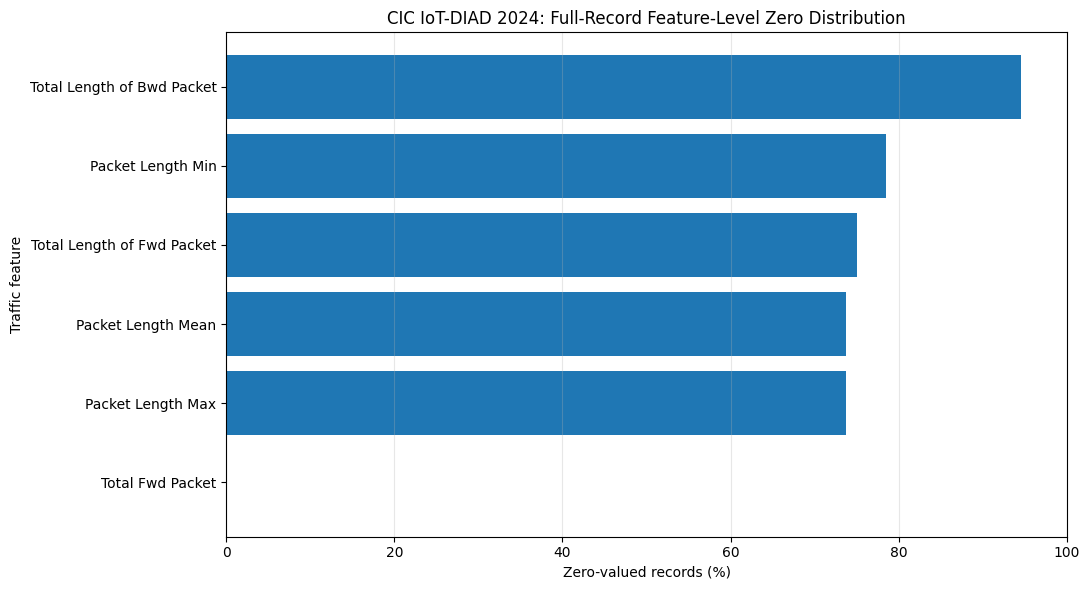

Chart saved: /kaggle/working/O1_results/O1_DIAD_FULL_RECORD_FEATURE_ZERO_CHART.png


In [14]:

# ============================================================
# O1.3: FEATURE ZERO-PERCENTAGE CHART
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.barh(
    overall_summary["feature"],
    overall_summary["zero_percentage"]
)

plt.xlabel("Zero-valued records (%)")
plt.ylabel("Traffic feature")

plt.title(
    "CIC IoT-DIAD 2024: "
    "Full-Record Feature-Level Zero Distribution"
)

plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

chart_path = os.path.join(
    RESULTS_DIR,
    "O1_DIAD_FULL_RECORD_FEATURE_ZERO_CHART.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", chart_path)


In [15]:

# ============================================================
# OBJECTIVE 2 - O2.1
# EXPERIMENTAL ENVIRONMENT DIAGNOSTIC
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 65)
print("OBJECTIVE 2: MODEL DEVELOPMENT")
print("=" * 65)

# 1. Check important existing variables
candidate_variables = [
    "X_train", "X_val", "X_test",
    "y_train", "y_val", "y_test",
    "Xtr", "Xte", "X_diad",
    "ytr", "yte",
    "diad_train", "diad_val", "diad_test",
    "train_df", "val_df", "test_df",
    "canonical_features",
    "label_encoder",
    "preprocessor",
    "class_weights"
]

print("\n1. EXISTING VARIABLES")

for name in candidate_variables:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: AVAILABLE | Shape: {obj.shape}")
        else:
            print(f"{name}: AVAILABLE | Type: {type(obj).__name__}")
    else:
        print(f"{name}: NOT FOUND")

# 2. Check model libraries
print("\n2. MODEL LIBRARIES")

libraries = [
    "sklearn",
    "xgboost",
    "tensorflow",
    "shap"
]

for lib in libraries:
    try:
        module = __import__(lib)
        print(f"{lib}: AVAILABLE")
    except ImportError:
        print(f"{lib}: NOT INSTALLED")

# 3. Check available saved experiment files
print("\n3. EXISTING OUTPUT FILES")

output_dir = "/kaggle/working/O1_results"

if os.path.exists(output_dir):
    for filename in os.listdir(output_dir):
        print(filename)
else:
    print("O1 results directory not found.")

# 4. Check target distributions if available
print("\n4. TARGET DISTRIBUTIONS")

for name in ["y_train", "y_val", "y_test", "ytr", "yte"]:

    if name in globals():

        target = globals()[name]

        print(f"\n{name}:")

        print(
            pd.Series(np.asarray(target).ravel())
            .value_counts(dropna=False)
            .to_string()
        )

print("\n" + "=" * 65)
print("DIAGNOSTIC COMPLETED")
print("=" * 65)


OBJECTIVE 2: MODEL DEVELOPMENT

1. EXISTING VARIABLES
X_train: NOT FOUND
X_val: NOT FOUND
X_test: NOT FOUND
y_train: NOT FOUND
y_val: NOT FOUND
y_test: NOT FOUND
Xtr: NOT FOUND
Xte: NOT FOUND
X_diad: NOT FOUND
ytr: NOT FOUND
yte: NOT FOUND
diad_train: NOT FOUND
diad_val: NOT FOUND
diad_test: NOT FOUND
train_df: NOT FOUND
val_df: NOT FOUND
test_df: NOT FOUND
canonical_features: NOT FOUND
label_encoder: NOT FOUND
preprocessor: NOT FOUND
class_weights: NOT FOUND

2. MODEL LIBRARIES
sklearn: AVAILABLE
xgboost: AVAILABLE
tensorflow: AVAILABLE
shap: AVAILABLE

3. EXISTING OUTPUT FILES
O1_DIAD_FULL_RECORD_INDIVIDUAL_FEATURE_SUMMARY.csv
O1_DIAD_DoS_DDoS_file_level_packet_audit.csv
O1_DIAD_FULL_RECORD_SCENARIO_FEATURE_SUMMARY.csv
O1_DIAD_DoS_DDoS_scenario_packet_summary.csv
O1_DIAD_file_scenario_manifest.csv
O1_DIAD_DoS_DDoS_FULL_RECORD_PACKET_AUDIT.csv
O1_DIAD_FULL_RECORD_FEATURE_ZERO_CHART.png
O1_DIAD_DoS_DDoS_FULL_RECORD_SCENARIO_SUMMARY.csv

4. TARGET DISTRIBUTIONS

DIAGNOSTIC COMPLETED


In [16]:

# ============================================================
# OBJECTIVE 2 - O2.1
# EXPERIMENTAL DATASET RECOVERY AND INSPECTION
# ============================================================

import os
import glob
import pandas as pd

print("=" * 70)
print("O2.1: EXPERIMENTAL DATASET RECOVERY")
print("=" * 70)

# 1. DIAD dataset location
DATASET_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

print("\n1. DATASET LOCATION")

if os.path.isdir(DATASET_ROOT):
    print("DIAD dataset: FOUND")

    csv_files = glob.glob(
        os.path.join(DATASET_ROOT, "**", "*.csv"),
        recursive=True
    )

    print("CSV files:", len(csv_files))
else:
    print("DIAD dataset: NOT FOUND")
    print("Check the Kaggle input dataset path.")

# 2. Existing O1 results
OUTPUT_DIR = "/kaggle/working/O1_results"

print("\n2. EXISTING O1 OUTPUTS")

if os.path.isdir(OUTPUT_DIR):

    output_files = sorted(
        os.listdir(OUTPUT_DIR)
    )

    for filename in output_files:
        print(filename)

else:
    print("O1 results directory not found.")

# 3. Inspect scenario manifest
print("\n3. SCENARIO MANIFEST")

manifest_path = os.path.join(
    OUTPUT_DIR,
    "O1_DIAD_file_scenario_manifest.csv"
)

if os.path.exists(manifest_path):

    manifest = pd.read_csv(manifest_path)

    print("Manifest shape:", manifest.shape)
    print("Manifest columns:")
    print(manifest.columns.tolist())

    print("\nFirst 10 rows:")
    print(manifest.head(10).to_string(index=False))

else:
    print("Scenario manifest not found.")

# 4. Inspect corrected class distribution
print("\n4. CORRECTED CLASS DISTRIBUTION")

distribution_candidates = [
    "O1_DIAD_corrected_class_distribution.csv",
    "O1_DIAD_complete_scenario_record_distribution.csv",
    "O1_DIAD_corrected_file_record_counts.csv"
]

for filename in distribution_candidates:

    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(path):

        df = pd.read_csv(path)

        print("\nFILE:", filename)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(12).to_string(index=False))

print("\n" + "=" * 70)
print("O2.1 INSPECTION COMPLETED")
print("=" * 70)


O2.1: EXPERIMENTAL DATASET RECOVERY

1. DATASET LOCATION
DIAD dataset: FOUND
CSV files: 126

2. EXISTING O1 OUTPUTS
O1_DIAD_DoS_DDoS_FULL_RECORD_PACKET_AUDIT.csv
O1_DIAD_DoS_DDoS_FULL_RECORD_SCENARIO_SUMMARY.csv
O1_DIAD_DoS_DDoS_file_level_packet_audit.csv
O1_DIAD_DoS_DDoS_scenario_packet_summary.csv
O1_DIAD_FULL_RECORD_FEATURE_ZERO_CHART.png
O1_DIAD_FULL_RECORD_INDIVIDUAL_FEATURE_SUMMARY.csv
O1_DIAD_FULL_RECORD_SCENARIO_FEATURE_SUMMARY.csv
O1_DIAD_file_scenario_manifest.csv

3. SCENARIO MANIFEST
Manifest shape: (126, 4)
Manifest columns:
['file_path', 'file_name', 'scenario_label', 'scenario_folder']

First 10 rows:
                                                                                                                                          file_path                              file_name scenario_label        scenario_folder
                                /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/Benign/BenignTraffic.pcap_Flow.csv   

In [17]:

# ============================================================
# O2.1b: DIAD DATASET AND FEATURE INVENTORY
# Objective 2 - Experimental Dataset Preparation
# ============================================================

import os
import numpy as np
import pandas as pd

BASE = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUT = "/kaggle/working/O2_results"
os.makedirs(OUT, exist_ok=True)

MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

CHUNK_SIZE = 200000

print("=" * 70)
print("O2.1b: DIAD DATASET AND FEATURE INVENTORY")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD VERIFIED SCENARIO MANIFEST
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)

required = [
    "file_path",
    "file_name",
    "scenario_label",
    "scenario_folder"
]

assert all(c in manifest.columns for c in required)
assert len(manifest) == 126

print("\nTotal files:", len(manifest))

print("\nFILES PER CLASS")
print(
    manifest.groupby("scenario_label")
    .agg(
        files=("file_name", "count"),
        scenarios=("scenario_folder", "nunique")
    )
    .to_string()
)

# ------------------------------------------------------------
# 2. ESTABLISH REFERENCE SCHEMA
# ------------------------------------------------------------

reference_path = os.path.join(
    BASE,
    "Benign",
    "BenignTraffic.pcap_Flow.csv"
)

reference_columns = pd.read_csv(
    reference_path,
    nrows=0
).columns.tolist()

print("\nReference columns:", len(reference_columns))

assert len(reference_columns) == 84

pd.DataFrame({
    "column_name": reference_columns
}).to_csv(
    os.path.join(OUT, "O2_DIAD_REFERENCE_COLUMNS.csv"),
    index=False
)

# ------------------------------------------------------------
# 3. INSPECT AND COUNT ALL FILES
# ------------------------------------------------------------

file_results = []
schema_errors = []

for i, row in manifest.iterrows():

    path = row["file_path"]

    try:

        header = pd.read_csv(
            path,
            nrows=0
        ).columns.tolist()

        if header == reference_columns:
            headerless = False

        elif len(header) == len(reference_columns):
            # Previously verified headerless files
            headerless = True

        else:
            schema_errors.append({
                "file": path,
                "columns_found": len(header)
            })
            continue

        total_rows = 0

        if headerless:

            reader = pd.read_csv(
                path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        else:

            reader = pd.read_csv(
                path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        for chunk in reader:
            total_rows += len(chunk)

        file_results.append({
            "file_name": row["file_name"],
            "scenario_label": row["scenario_label"],
            "scenario_folder": row["scenario_folder"],
            "records": total_rows,
            "headerless": headerless,
            "columns": len(reference_columns)
        })

        if (i + 1) % 10 == 0:
            print(
                f"Processed {i+1}/{len(manifest)} files"
            )

    except Exception as e:

        schema_errors.append({
            "file": path,
            "error": str(e)
        })

file_df = pd.DataFrame(file_results)

file_df.to_csv(
    os.path.join(OUT, "O2_DIAD_FILE_INVENTORY.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. CLASS-LEVEL RECORD DISTRIBUTION
# ------------------------------------------------------------

class_summary = (
    file_df.groupby("scenario_label")
    .agg(
        files=("file_name", "count"),
        scenarios=("scenario_folder", "nunique"),
        records=("records", "sum")
    )
    .reset_index()
)

class_summary["percentage"] = (
    class_summary["records"]
    / class_summary["records"].sum()
    * 100
)

class_summary.to_csv(
    os.path.join(OUT, "O2_DIAD_CLASS_DISTRIBUTION.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. FEATURE INVENTORY
# ------------------------------------------------------------

feature_df = pd.DataFrame({
    "feature": reference_columns
})

feature_df["position"] = range(1, len(reference_columns) + 1)

feature_df["identifier_candidate"] = (
    feature_df["feature"]
    .str.lower()
    .str.contains(
        r"flow id|src ip|dst ip|timestamp|^id$"
    )
)

feature_df.to_csv(
    os.path.join(OUT, "O2_DIAD_FEATURE_INVENTORY.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("O2.1b RESULTS")
print("=" * 70)

print("\nFILES PROCESSED:", len(file_df))
print("HEADERLESS FILES:", file_df["headerless"].sum())
print("SCHEMA ERRORS:", len(schema_errors))

print("\nCLASS DISTRIBUTION")
print(class_summary.to_string(index=False))

print("\nFEATURE INVENTORY")
print(feature_df.to_string(index=False))

print("\nTOTAL RECORDS:", file_df["records"].sum())

if schema_errors:
    print("\nSCHEMA ERRORS:")
    print(pd.DataFrame(schema_errors).to_string(index=False))

print("\nSAVED OUTPUTS:")
print(OUT)

print("\nO2.1b COMPLETED")


O2.1b: DIAD DATASET AND FEATURE INVENTORY

Total files: 126

FILES PER CLASS
                files  scenarios
scenario_label                  
Benign              4          1
Brute Force         1          1
DDoS               55          4
DoS                30          4
Mirai              29          1
Recon               1          1
Spoofing            3          2
Web-Based           3          3

Reference columns: 84
Processed 10/126 files
Processed 20/126 files
Processed 30/126 files
Processed 40/126 files
Processed 50/126 files
Processed 60/126 files
Processed 70/126 files
Processed 80/126 files
Processed 90/126 files
Processed 100/126 files
Processed 110/126 files
Processed 120/126 files

O2.1b RESULTS

FILES PROCESSED: 126
HEADERLESS FILES: 5
SCHEMA ERRORS: 0

CLASS DISTRIBUTION
scenario_label  files  scenarios  records  percentage
        Benign      4          1   398330    1.476988
   Brute Force      1          1     3619    0.013419
          DDoS     55          4  2

In [18]:

# ============================================================
# O2.1c: TEMPORAL PARTITION FEASIBILITY AUDIT
# CIC IoT-DIAD 2024
# ============================================================

import os
import pandas as pd
import numpy as np

BASE = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

OUT = "/kaggle/working/O2_results"

manifest = pd.read_csv(
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

reference_columns = pd.read_csv(
    os.path.join(OUT, "O2_DIAD_REFERENCE_COLUMNS.csv")
)["column_name"].tolist()

CHUNK_SIZE = 200000

results = []

print("=" * 70)
print("O2.1c: TEMPORAL PARTITION FEASIBILITY AUDIT")
print("=" * 70)

for i, row in manifest.iterrows():

    path = row["file_path"]

    header = pd.read_csv(
        path,
        nrows=0
    ).columns.tolist()

    if header == reference_columns:
        reader = pd.read_csv(
            path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )
    elif len(header) == len(reference_columns):
        reader = pd.read_csv(
            path,
            header=None,
            names=reference_columns,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )
    else:
        print("SCHEMA ERROR:", path)
        continue

    valid = 0
    invalid = 0
    min_time = None
    max_time = None
    previous_time = None
    reversals = 0
    unique_times = set()

    for chunk in reader:

        ts = pd.to_datetime(
            chunk["Timestamp"],
            errors="coerce",
            utc=True
        )

        good = ts.dropna()

        valid += len(good)
        invalid += ts.isna().sum()

        if len(good):

            current_min = good.min()
            current_max = good.max()

            min_time = (
                current_min if min_time is None
                else min(min_time, current_min)
            )

            max_time = (
                current_max if max_time is None
                else max(max_time, current_max)
            )

            # Detect timestamp reversals
            if previous_time is not None:
                if good.iloc[0] < previous_time:
                    reversals += 1

            reversals += int(
                (good.diff().dropna() < pd.Timedelta(0)).sum()
            )

            previous_time = good.iloc[-1]

            unique_times.update(
                good.astype("int64").unique().tolist()
            )

    results.append({
        "file_name": row["file_name"],
        "class": row["scenario_label"],
        "scenario": row["scenario_folder"],
        "valid_timestamps": valid,
        "invalid_timestamps": invalid,
        "timestamp_reversals": reversals,
        "unique_timestamps": len(unique_times),
        "start_time": min_time,
        "end_time": max_time
    })

    if (i + 1) % 10 == 0:
        print(f"Processed {i+1}/{len(manifest)} files")

# Save results
temporal_df = pd.DataFrame(results)

temporal_df.to_csv(
    os.path.join(
        OUT,
        "O2_DIAD_TEMPORAL_PARTITION_AUDIT.csv"
    ),
    index=False
)

print("\nTEMPORAL AUDIT SUMMARY")

print(
    temporal_df.groupby("class")
    .agg(
        files=("file_name", "count"),
        valid_timestamps=("valid_timestamps", "sum"),
        invalid_timestamps=("invalid_timestamps", "sum"),
        timestamp_reversals=("timestamp_reversals", "sum"),
        unique_timestamps=("unique_timestamps", "sum")
    )
    .to_string()
)

print("\nFILES WITHOUT VALID TIMESTAMPS:")

print(
    temporal_df[
        temporal_df["valid_timestamps"] == 0
    ][["file_name", "class"]].to_string(index=False)
)

print("\nSAVED:")
print(
    os.path.join(
        OUT,
        "O2_DIAD_TEMPORAL_PARTITION_AUDIT.csv"
    )
)

print("\nO2.1c COMPLETED")


O2.1c: TEMPORAL PARTITION FEASIBILITY AUDIT


/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Parsing dates in %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: Use

Processed 10/126 files


/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597

Processed 20/126 files


/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597

... (17 outputs left out)

/tmp/ipykernel_49/1182563597.py:71: UserWarning: Parsing dates in %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Parsing dates in %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: C

Processed 120/126 files


/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Parsing dates in %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: Parsing dates in %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(
/tmp/ipykernel_49/1182563597.py:71: UserWarning: P


TEMPORAL AUDIT SUMMARY
             files  valid_timestamps  invalid_timestamps  timestamp_reversals  unique_timestamps
class                                                                                           
Benign           4            398330                   0               167437              87296
Brute Force      1              3619                   0                 1695               1182
DDoS            55           2636705                1187               830536              92976
DoS             30          23143929                   0              2741988              63463
Mirai           29            174588                   0                77106              31176
Recon            1            442158                   0               174085              57654
Spoofing         3            157238                   0                65854              28144
Web-Based        3             11328                   0                 4630               2114

FILES

In [19]:

# ============================================================
# O2.1c.1: TIMESTAMP FORMAT VERIFICATION
# ============================================================

import os
import pandas as pd

OUT = "/kaggle/working/O2_results"

manifest = pd.read_csv(
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

columns = pd.read_csv(
    os.path.join(OUT, "O2_DIAD_REFERENCE_COLUMNS.csv")
)["column_name"].tolist()

samples = []

for _, row in manifest.iterrows():

    path = row["file_path"]

    header = pd.read_csv(path, nrows=0).columns.tolist()

    if header == columns:
        df = pd.read_csv(path, nrows=20)
    else:
        df = pd.read_csv(
            path,
            header=None,
            names=columns,
            nrows=20
        )

    for value in df["Timestamp"].dropna().astype(str).unique():

        samples.append({
            "class": row["scenario_label"],
            "file": row["file_name"],
            "raw_timestamp": value
        })

sample_df = pd.DataFrame(samples).drop_duplicates(
    subset=["raw_timestamp"]
)

sample_df["parsed_default"] = pd.to_datetime(
    sample_df["raw_timestamp"],
    errors="coerce",
    utc=True
)

sample_df["parsed_dayfirst"] = pd.to_datetime(
    sample_df["raw_timestamp"],
    format="mixed",
    dayfirst=True,
    errors="coerce",
    utc=True
)

print("=" * 70)
print("TIMESTAMP FORMAT COMPARISON")
print("=" * 70)

print("Unique raw timestamp samples:", len(sample_df))

print("\nDEFAULT PARSER INVALID:",
      sample_df["parsed_default"].isna().sum())

print("DAYFIRST MIXED PARSER INVALID:",
      sample_df["parsed_dayfirst"].isna().sum())

print("\nSAMPLE COMPARISON:")

print(
    sample_df[
        [
            "raw_timestamp",
            "parsed_default",
            "parsed_dayfirst"
        ]
    ].head(30).to_string(index=False)
)

sample_df.to_csv(
    os.path.join(
        OUT,
        "O2_DIAD_TIMESTAMP_FORMAT_SAMPLES.csv"
    ),
    index=False
)

print("\nSaved timestamp samples.")


TIMESTAMP FORMAT COMPARISON
Unique raw timestamp samples: 1238

DEFAULT PARSER INVALID: 0
DAYFIRST MIXED PARSER INVALID: 0

SAMPLE COMPARISON:
         raw_timestamp            parsed_default           parsed_dayfirst
07/10/2022 02:15:01 PM 2022-07-10 14:15:01+00:00 2022-10-07 14:15:01+00:00
07/10/2022 02:15:03 PM 2022-07-10 14:15:03+00:00 2022-10-07 14:15:03+00:00
07/10/2022 02:15:04 PM 2022-07-10 14:15:04+00:00 2022-10-07 14:15:04+00:00
07/10/2022 02:15:05 PM 2022-07-10 14:15:05+00:00 2022-10-07 14:15:05+00:00
07/10/2022 02:15:06 PM 2022-07-10 14:15:06+00:00 2022-10-07 14:15:06+00:00
07/10/2022 02:15:07 PM 2022-07-10 14:15:07+00:00 2022-10-07 14:15:07+00:00
07/10/2022 02:15:08 PM 2022-07-10 14:15:08+00:00 2022-10-07 14:15:08+00:00
07/10/2022 02:15:09 PM 2022-07-10 14:15:09+00:00 2022-10-07 14:15:09+00:00
07/10/2022 02:15:10 PM 2022-07-10 14:15:10+00:00 2022-10-07 14:15:10+00:00
07/10/2022 02:15:11 PM 2022-07-10 14:15:11+00:00 2022-10-07 14:15:11+00:00
07/10/2022 11:30:28 PM 2022-07-1

/tmp/ipykernel_49/1401188092.py:49: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_df["parsed_default"] = pd.to_datetime(


In [20]:
# ============================================================
# O2.1c.2: FULL DATASET TIMESTAMP FORMAT EVIDENCE AUDIT
# Purpose: Determine whether timestamps are DD/MM/YYYY or MM/DD/YYYY
# Does NOT modify the original dataset.
# ============================================================

import os
import re
import pandas as pd

OUT = "/kaggle/working/O2_results"
os.makedirs(OUT, exist_ok=True)

MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

REFERENCE_PATH = os.path.join(
    OUT, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)
reference_columns = pd.read_csv(
    REFERENCE_PATH
)["column_name"].tolist()

# Match dates such as 07/10/2022 or 07/10/2022 02:15:01 PM
date_pattern = re.compile(
    r"^\s*(\d{1,2})/(\d{1,2})/(\d{4})"
)

results = []
total_rows = 0
total_dayfirst_evidence = 0
total_monthfirst_evidence = 0
total_ambiguous = 0
total_unmatched = 0

for file_number, (_, row) in enumerate(
    manifest.iterrows(), start=1
):
    path = row["file_path"]

    header = pd.read_csv(path, nrows=0).columns.tolist()

    if header == reference_columns:
        header_mode = True
    else:
        header_mode = False

    counts = {
        "dayfirst_evidence": 0,
        "monthfirst_evidence": 0,
        "ambiguous": 0,
        "unmatched": 0,
        "rows": 0
    }

    examples_dayfirst = []
    examples_monthfirst = []

    reader = pd.read_csv(
        path,
        chunksize=100000,
        header=0 if header_mode else None,
        names=None if header_mode else reference_columns,
        usecols=["Timestamp"] if header_mode else None
    )

    for chunk in reader:

        if not header_mode:
            timestamp_values = chunk["Timestamp"]
        else:
            timestamp_values = chunk["Timestamp"]

        values = timestamp_values.dropna().astype(str)

        for value in values:
            counts["rows"] += 1

            match = date_pattern.match(value)

            if not match:
                counts["unmatched"] += 1
                continue

            first = int(match.group(1))
            second = int(match.group(2))

            if first > 12 and second <= 12:
                counts["dayfirst_evidence"] += 1

                if len(examples_dayfirst) < 3:
                    examples_dayfirst.append(value)

            elif second > 12 and first <= 12:
                counts["monthfirst_evidence"] += 1

                if len(examples_monthfirst) < 3:
                    examples_monthfirst.append(value)

            elif first <= 12 and second <= 12:
                counts["ambiguous"] += 1

            else:
                counts["unmatched"] += 1

    results.append({
        "scenario_label": row["scenario_label"],
        "scenario_folder": row["scenario_folder"],
        "file_name": row["file_name"],
        **counts,
        "dayfirst_examples": " | ".join(examples_dayfirst),
        "monthfirst_examples": " | ".join(examples_monthfirst)
    })

    total_rows += counts["rows"]
    total_dayfirst_evidence += counts["dayfirst_evidence"]
    total_monthfirst_evidence += counts["monthfirst_evidence"]
    total_ambiguous += counts["ambiguous"]
    total_unmatched += counts["unmatched"]

    if file_number % 10 == 0 or file_number == len(manifest):
        print(f"Processed {file_number}/{len(manifest)} files")

audit = pd.DataFrame(results)

print("\n" + "=" * 65)
print("FULL TIMESTAMP FORMAT EVIDENCE SUMMARY")
print("=" * 65)

print("Timestamp values inspected:", total_rows)
print("DD/MM/YYYY evidence:", total_dayfirst_evidence)
print("MM/DD/YYYY evidence:", total_monthfirst_evidence)
print("Ambiguous dates:", total_ambiguous)
print("Unmatched date formats:", total_unmatched)

print("\nFILE-LEVEL RESULTS:")
print(
    audit[[
        "scenario_label",
        "file_name",
        "rows",
        "dayfirst_evidence",
        "monthfirst_evidence",
        "ambiguous",
        "unmatched"
    ]].to_string(index=False)
)

print("\nEXAMPLES OF UNAMBIGUOUS DATES:")
print(
    audit[[
        "file_name",
        "dayfirst_examples",
        "monthfirst_examples"
    ]].to_string(index=False)
)

output_path = os.path.join(
    OUT,
    "O2_DIAD_FULL_TIMESTAMP_FORMAT_AUDIT.csv"
)

audit.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Processed 10/126 files
Processed 20/126 files
Processed 30/126 files
Processed 40/126 files
Processed 50/126 files
Processed 60/126 files
Processed 70/126 files
Processed 80/126 files
Processed 90/126 files
Processed 100/126 files
Processed 110/126 files
Processed 120/126 files
Processed 126/126 files

FULL TIMESTAMP FORMAT EVIDENCE SUMMARY
Timestamp values inspected: 26969082
DD/MM/YYYY evidence: 2344340
MM/DD/YYYY evidence: 0
Ambiguous dates: 24624742
Unmatched date formats: 0

FILE-LEVEL RESULTS:
scenario_label                               file_name    rows  dayfirst_evidence  monthfirst_evidence  ambiguous  unmatched
        Benign             BenignTraffic.pcap_Flow.csv  183630                  0                    0     183630          0
        Benign            BenignTraffic1.pcap_Flow.csv   84526                  0                    0      84526          0
        Benign            BenignTraffic2.pcap_Flow.csv   91279                  0                    0      91279       

In [21]:
# ============================================================
# O2.1c.3: FULL TIMESTAMP VALIDATION - DAY FIRST
# ============================================================

import os
import pandas as pd

OUT = "/kaggle/working/O2_results"
os.makedirs(OUT, exist_ok=True)

MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

REFERENCE_PATH = os.path.join(
    OUT, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

reference_columns = pd.read_csv(
    REFERENCE_PATH
)["column_name"].tolist()

CHUNK_SIZE = 100000

all_results = []

grand_total = 0
grand_valid = 0
grand_invalid = 0
grand_missing = 0
grand_reversals = 0

for file_number, (_, row) in enumerate(
    manifest.iterrows(), start=1
):

    path = row["file_path"]

    header = pd.read_csv(path, nrows=0).columns.tolist()
    has_header = header == reference_columns

    if has_header:
        reader = pd.read_csv(
            path,
            usecols=["Timestamp"],
            chunksize=CHUNK_SIZE
        )
    else:
        reader = pd.read_csv(
            path,
            header=None,
            names=reference_columns,
            usecols=["Timestamp"],
            chunksize=CHUNK_SIZE
        )

    total = 0
    valid = 0
    invalid = 0
    missing = 0
    reversals = 0

    min_time = None
    max_time = None
    previous_time = None

    for chunk in reader:

        raw = chunk["Timestamp"]

        total += len(raw)
        missing += raw.isna().sum()

        parsed = pd.to_datetime(
            raw,
            format="%d/%m/%Y %I:%M:%S %p",
            errors="coerce",
            utc=True
        )

        invalid += (
            raw.notna() & parsed.isna()
        ).sum()

        good = parsed.dropna()
        valid += len(good)

        if len(good) > 0:

            chunk_min = good.min()
            chunk_max = good.max()

            if min_time is None or chunk_min < min_time:
                min_time = chunk_min

            if max_time is None or chunk_max > max_time:
                max_time = chunk_max

            # Count chronological reversals in file order.
            if previous_time is not None:
                if good.iloc[0] < previous_time:
                    reversals += 1

            reversals += (good.diff().dropna() < pd.Timedelta(0)).sum()

            previous_time = good.iloc[-1]

    all_results.append({
        "scenario_label": row["scenario_label"],
        "scenario_folder": row["scenario_folder"],
        "file_name": row["file_name"],
        "total_records": total,
        "valid_timestamps": valid,
        "invalid_timestamps": invalid,
        "missing_timestamps": missing,
        "chronological_reversals": reversals,
        "minimum_timestamp": min_time,
        "maximum_timestamp": max_time
    })

    grand_total += total
    grand_valid += valid
    grand_invalid += invalid
    grand_missing += missing
    grand_reversals += reversals

    if file_number % 10 == 0 or file_number == len(manifest):
        print(f"Validated {file_number}/{len(manifest)} files")

audit = pd.DataFrame(all_results)

print("\n" + "=" * 65)
print("FULL TIMESTAMP VALIDATION SUMMARY")
print("=" * 65)

print("Files processed:", len(audit))
print("Total records:", f"{grand_total:,}")
print("Valid timestamps:", f"{grand_valid:,}")
print("Invalid timestamps:", f"{grand_invalid:,}")
print("Missing timestamps:", f"{grand_missing:,}")
print("Chronological reversals:", f"{grand_reversals:,}")

print("\nDATE RANGE:")
print("Earliest:", audit["minimum_timestamp"].min())
print("Latest:", audit["maximum_timestamp"].max())

print("\nCLASS-LEVEL SUMMARY:")
print(
    audit.groupby("scenario_label")[
        [
            "total_records",
            "valid_timestamps",
            "invalid_timestamps",
            "missing_timestamps",
            "chronological_reversals"
        ]
    ].sum().to_string()
)

print("\nFILES WITH INVALID OR MISSING TIMESTAMPS:")
print(
    audit[
        (audit["invalid_timestamps"] > 0) |
        (audit["missing_timestamps"] > 0)
    ][
        [
            "file_name",
            "total_records",
            "invalid_timestamps",
            "missing_timestamps"
        ]
    ].to_string(index=False)
)

output_path = os.path.join(
    OUT,
    "O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv"
)

audit.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Validated 10/126 files
Validated 20/126 files
Validated 30/126 files
Validated 40/126 files
Validated 50/126 files
Validated 60/126 files
Validated 70/126 files
Validated 80/126 files
Validated 90/126 files
Validated 100/126 files
Validated 110/126 files
Validated 120/126 files
Validated 126/126 files

FULL TIMESTAMP VALIDATION SUMMARY
Files processed: 126
Total records: 26,969,082
Valid timestamps: 26,969,082
Invalid timestamps: 0
Missing timestamps: 0
Chronological reversals: 4,063,870

DATE RANGE:
Earliest: 2022-07-22 11:41:31+00:00
Latest: 2023-02-14 13:05:00+00:00

CLASS-LEVEL SUMMARY:
                total_records  valid_timestamps  invalid_timestamps  missing_timestamps  chronological_reversals
scenario_label                                                                                                  
Benign                 398330            398330                   0                   0                   167437
Brute Force              3619              3619                

In [22]:
# ============================================================
# O2.1d: CAPTURE-FILE TEMPORAL OVERLAP AUDIT
# ============================================================

import os
import pandas as pd
from itertools import combinations

OUT = "/kaggle/working/O2_results"

audit_path = os.path.join(
    OUT,
    "O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv"
)

audit = pd.read_csv(audit_path)

audit["minimum_timestamp"] = pd.to_datetime(
    audit["minimum_timestamp"], utc=True
)

audit["maximum_timestamp"] = pd.to_datetime(
    audit["maximum_timestamp"], utc=True
)

overlap_results = []

for scenario, group in audit.groupby("scenario_label"):

    records = group.to_dict("records")

    for a, b in combinations(records, 2):

        start_a = a["minimum_timestamp"]
        end_a = a["maximum_timestamp"]

        start_b = b["minimum_timestamp"]
        end_b = b["maximum_timestamp"]

        overlap_start = max(start_a, start_b)
        overlap_end = min(end_a, end_b)

        overlaps = overlap_start <= overlap_end

        if overlaps:
            overlap_seconds = (
                overlap_end - overlap_start
            ).total_seconds()
        else:
            overlap_seconds = 0

        overlap_results.append({
            "scenario_label": scenario,
            "file_a": a["file_name"],
            "file_b": b["file_name"],
            "file_a_start": start_a,
            "file_a_end": end_a,
            "file_b_start": start_b,
            "file_b_end": end_b,
            "time_ranges_overlap": overlaps,
            "overlap_duration_seconds": overlap_seconds
        })

overlap_df = pd.DataFrame(overlap_results)

print("\n" + "=" * 65)
print("CAPTURE-FILE TEMPORAL OVERLAP SUMMARY")
print("=" * 65)

print("File pairs compared:", len(overlap_df))

if len(overlap_df) > 0:

    print(
        "Overlapping file pairs:",
        int(overlap_df["time_ranges_overlap"].sum())
    )

    print(
        "Non-overlapping file pairs:",
        int((~overlap_df["time_ranges_overlap"]).sum())
    )

    print("\nOVERLAPPING FILE PAIRS:")
    print(
        overlap_df[
            overlap_df["time_ranges_overlap"]
        ][[
            "scenario_label",
            "file_a",
            "file_b",
            "overlap_duration_seconds"
        ]].to_string(index=False)
    )

    print("\nNON-OVERLAPPING FILE PAIRS:")
    print(
        overlap_df[
            ~overlap_df["time_ranges_overlap"]
        ][[
            "scenario_label",
            "file_a",
            "file_b"
        ]].head(30).to_string(index=False)
    )

summary = (
    overlap_df.groupby("scenario_label")
    .agg(
        file_pairs=("time_ranges_overlap", "size"),
        overlapping_pairs=("time_ranges_overlap", "sum")
    )
    .reset_index()
)

print("\nSCENARIO-LEVEL OVERLAP SUMMARY:")
print(summary.to_string(index=False))

overlap_path = os.path.join(
    OUT,
    "O2_DIAD_CAPTURE_TEMPORAL_OVERLAP.csv"
)

summary_path = os.path.join(
    OUT,
    "O2_DIAD_CAPTURE_TEMPORAL_OVERLAP_SUMMARY.csv"
)

overlap_df.to_csv(overlap_path, index=False)
summary.to_csv(summary_path, index=False)

print("\nSaved detailed audit:", overlap_path)
print("Saved summary:", summary_path)


CAPTURE-FILE TEMPORAL OVERLAP SUMMARY
File pairs compared: 2338
Overlapping file pairs: 131
Non-overlapping file pairs: 2207

OVERLAPPING FILE PAIRS:
scenario_label                                  file_a                                  file_b  overlap_duration_seconds
          DDoS    DDoS-ACK_Fragmentation.pcap_Flow.csv   DDoS-ACK_Fragmentation1.pcap_Flow.csv                       0.0
          DDoS    DDoS-ACK_Fragmentation.pcap_Flow.csv         DDoS-ICMP_Flood25.pcap_Flow.csv                    3259.0
          DDoS    DDoS-ACK_Fragmentation.pcap_Flow.csv          DDoS-HTTP_Flood-.pcap_Flow.csv                    3259.0
          DDoS    DDoS-ACK_Fragmentation.pcap_Flow.csv DDoS-ICMP_Fragmentation19.pcap_Flow.csv                    3259.0
          DDoS   DDoS-ACK_Fragmentation1.pcap_Flow.csv   DDoS-ACK_Fragmentation2.pcap_Flow.csv                       0.0
          DDoS   DDoS-ACK_Fragmentation1.pcap_Flow.csv         DDoS-ICMP_Flood25.pcap_Flow.csv                    2867.0
  

In [27]:

import pandas as pd
import os

path = "/kaggle/working/O2_results/O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv"

df = pd.read_csv(path)

print("COLUMNS IN TIMESTAMP AUDIT:")
print(df.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nMANIFEST COLUMNS:")
manifest = pd.read_csv(
    "/kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv"
)
print(manifest.columns.tolist())
display(manifest.head())


COLUMNS IN TIMESTAMP AUDIT:
['scenario_label', 'scenario_folder', 'file_name', 'total_records', 'valid_timestamps', 'invalid_timestamps', 'missing_timestamps', 'chronological_reversals', 'minimum_timestamp', 'maximum_timestamp']

FIRST 5 ROWS:


,scenario_label,scenario_folder,file_name,total_records,valid_timestamps,invalid_timestamps,missing_timestamps,chronological_reversals,minimum_timestamp,maximum_timestamp
0,Benign,Benign,BenignTraffic.pcap_Flow.csv,183630,183630,0,0,78590,2022-10-07 14:15:00+00:00,2022-10-07 23:30:27+00:00
1,Benign,Benign,BenignTraffic1.pcap_Flow.csv,84526,84526,0,0,35385,2022-10-07 23:30:28+00:00,2022-10-08 06:45:20+00:00
2,Benign,Benign,BenignTraffic2.pcap_Flow.csv,91279,91279,0,0,37876,2022-10-08 06:45:21+00:00,2022-10-08 14:47:19+00:00
3,Benign,Benign,BenignTraffic3.pcap_Flow.csv,38895,38895,0,0,15586,2022-10-08 14:47:21+00:00,2022-10-08 18:15:00+00:00
4,Brute Force,BruteForce,DictionaryBruteForce.pcap_Flow.csv,3619,3619,0,0,1695,2022-10-14 13:18:01+00:00,2022-10-17 12:02:00+00:00



MANIFEST COLUMNS:
['file_path', 'file_name', 'scenario_label', 'scenario_folder']


,file_path,file_name,scenario_label,scenario_folder
0,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic.pcap_Flow.csv,Benign,Benign
1,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic1.pcap_Flow.csv,Benign,Benign
2,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic2.pcap_Flow.csv,Benign,Benign
3,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,BenignTraffic3.pcap_Flow.csv,Benign,Benign
4,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,DictionaryBruteForce.pcap_Flow.csv,Brute Force,BruteForce


In [28]:

# ================================================================
# O2.1e — CROSS-FILE EXACT DUPLICATE AUDIT
# Corrected using actual audit and manifest columns
# ================================================================

import os
import gc
import numpy as np
import pandas as pd
from itertools import combinations

# ------------------------------------------------
# 1. Paths and settings
# ------------------------------------------------

OUT = "/kaggle/working/O2_results"

MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

REFERENCE_PATH = os.path.join(
    OUT, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

TIMESTAMP_PATH = os.path.join(
    OUT, "O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv"
)

CHUNK_SIZE = 100_000

# New cache folder to avoid reusing incomplete cache files
HASH_DIR = os.path.join(OUT, "O2e_FILE_HASH_CACHE_V2")
os.makedirs(HASH_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Load files
# ------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)
reference_df = pd.read_csv(REFERENCE_PATH)
timestamp_audit = pd.read_csv(TIMESTAMP_PATH)

reference_columns = (
    reference_df["column_name"].astype(str).tolist()
)

print("Manifest files:", len(manifest))
print("Timestamp audit files:", len(timestamp_audit))
print("Reference columns:", len(reference_columns))

# Confirm expected columns
required_manifest = [
    "file_path", "file_name", "scenario_label"
]

required_timestamp = [
    "file_name", "scenario_label",
    "minimum_timestamp", "maximum_timestamp"
]

for col in required_manifest:
    if col not in manifest.columns:
        raise ValueError(f"Missing manifest column: {col}")

for col in required_timestamp:
    if col not in timestamp_audit.columns:
        raise ValueError(f"Missing timestamp column: {col}")

# ------------------------------------------------
# 3. Match timestamp audit to manifest
# ------------------------------------------------

# Each filename must identify exactly one manifest file.
if manifest["file_name"].duplicated().any():
    raise ValueError(
        "Duplicate filenames found in manifest. "
        "Resolve these before continuing."
    )

audit = timestamp_audit.merge(
    manifest[
        ["file_name", "file_path", "scenario_label"]
    ],
    on="file_name",
    how="left",
    suffixes=("_audit", "_manifest"),
    validate="one_to_one",
    indicator=True
)

unmatched = audit[audit["_merge"] != "both"]

if len(unmatched):
    print("Unmatched files:")
    print(unmatched["file_name"].tolist())
    raise ValueError("Some timestamp files could not be matched.")

# Check that scenario labels agree
mismatch = audit[
    audit["scenario_label_audit"].astype(str)
    != audit["scenario_label_manifest"].astype(str)
]

if len(mismatch):
    raise ValueError(
        "Scenario-label mismatch between audit and manifest."
    )

audit = audit.rename(
    columns={
        "scenario_label_audit": "scenario_label"
    }
)

audit = audit.drop(
    columns=["scenario_label_manifest", "_merge"]
)

audit["minimum_timestamp"] = pd.to_datetime(
    audit["minimum_timestamp"], utc=True
)

audit["maximum_timestamp"] = pd.to_datetime(
    audit["maximum_timestamp"], utc=True
)

audit = audit.reset_index(drop=True)

print("\nMatched files:", len(audit))
print("All timestamp files matched successfully.")

# ------------------------------------------------
# 4. Identify timestamp-overlapping file pairs
#    across ALL scenario categories
# ------------------------------------------------

candidate_pairs = []

for i, j in combinations(range(len(audit)), 2):

    a = audit.iloc[i]
    b = audit.iloc[j]

    overlap_start = max(
        a["minimum_timestamp"],
        b["minimum_timestamp"]
    )

    overlap_end = min(
        a["maximum_timestamp"],
        b["maximum_timestamp"]
    )

    if overlap_start <= overlap_end:

        candidate_pairs.append({
            "file_a_index": i,
            "file_b_index": j,
            "file_a": a["file_name"],
            "file_b": b["file_name"],
            "scenario_a": a["scenario_label"],
            "scenario_b": b["scenario_label"],
            "overlap_seconds": (
                overlap_end - overlap_start
            ).total_seconds()
        })

print("\nTimestamp-overlapping candidate pairs:",
      len(candidate_pairs))

if not candidate_pairs:
    raise ValueError(
        "No overlapping timestamp ranges found. "
        "No candidate pairs to compare."
    )

candidate_indices = sorted(set(
    [p["file_a_index"] for p in candidate_pairs]
    + [p["file_b_index"] for p in candidate_pairs]
))

print("Files requiring row hashing:", len(candidate_indices))

# ------------------------------------------------
# 5. Function: hash all complete rows in a file
# ------------------------------------------------

def get_file_hashes(file_path, cache_path):

    if os.path.exists(cache_path):
        print("Using cached hashes:", os.path.basename(cache_path))
        return np.load(cache_path, mmap_mode="r")

    # Determine whether the CSV has a header
    detected_columns = pd.read_csv(
        file_path,
        nrows=0
    ).columns.astype(str).tolist()

    has_header = detected_columns == reference_columns

    if has_header:
        reader = pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )
    else:
        reader = pd.read_csv(
            file_path,
            header=None,
            names=reference_columns,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )

    unique_parts = []
    total_rows = 0

    for chunk in reader:

        if len(chunk.columns) != len(reference_columns):
            raise ValueError(
                f"Unexpected column count: {file_path}"
            )

        # Hash complete records using all 84 reference columns
        row_hashes = pd.util.hash_pandas_object(
            chunk[reference_columns],
            index=False,
            categorize=True
        ).to_numpy(dtype=np.uint64)

        total_rows += len(chunk)

        unique_parts.append(np.unique(row_hashes))

        del chunk, row_hashes

    if unique_parts:
        final_hashes = np.unique(
            np.concatenate(unique_parts)
        )
    else:
        final_hashes = np.array([], dtype=np.uint64)

    np.save(cache_path, final_hashes)

    print(
        f"Hashed {os.path.basename(file_path)}: "
        f"{total_rows:,} rows; "
        f"{len(final_hashes):,} unique hashes"
    )

    del unique_parts, final_hashes
    gc.collect()

    return np.load(cache_path, mmap_mode="r")


# ------------------------------------------------
# 6. Hash candidate files
# ------------------------------------------------

hash_cache = {}

for count, idx in enumerate(candidate_indices, start=1):

    row = audit.iloc[idx]
    file_path = str(row["file_path"])

    if not os.path.isfile(file_path):
        raise FileNotFoundError(file_path)

    cache_path = os.path.join(
        HASH_DIR,
        f"file_{idx:03d}_unique_hashes.npy"
    )

    hash_cache[idx] = get_file_hashes(
        file_path,
        cache_path
    )

    if count % 10 == 0 or count == len(candidate_indices):
        print(
            f"\nFiles hashed: "
            f"{count}/{len(candidate_indices)}"
        )

# ------------------------------------------------
# 7. Compare hashes across candidate file pairs
# ------------------------------------------------

duplicate_results = []

for count, pair in enumerate(candidate_pairs, start=1):

    i = pair["file_a_index"]
    j = pair["file_b_index"]

    hashes_a = hash_cache[i]
    hashes_b = hash_cache[j]

    shared_hashes = np.intersect1d(
        hashes_a,
        hashes_b,
        assume_unique=True
    )

    duplicate_results.append({
        "file_a": pair["file_a"],
        "file_b": pair["file_b"],
        "scenario_a": pair["scenario_a"],
        "scenario_b": pair["scenario_b"],
        "overlap_seconds": pair["overlap_seconds"],
        "shared_unique_row_hashes": len(shared_hashes)
    })

    if count % 100 == 0 or count == len(candidate_pairs):
        print(
            f"Pairs compared: "
            f"{count}/{len(candidate_pairs)}"
        )

# ------------------------------------------------
# 8. Save detailed results
# ------------------------------------------------

duplicates_df = pd.DataFrame(duplicate_results)

duplicates_df = duplicates_df.sort_values(
    "shared_unique_row_hashes",
    ascending=False
)

all_pairs_path = os.path.join(
    OUT,
    "O2_DIAD_CROSS_FILE_DUPLICATE_PAIRS.csv"
)

duplicates_df.to_csv(all_pairs_path, index=False)

positive = duplicates_df[
    duplicates_df["shared_unique_row_hashes"] > 0
].copy()

positive_path = os.path.join(
    OUT,
    "O2_DIAD_CROSS_FILE_DUPLICATE_POSITIVE_PAIRS.csv"
)

positive.to_csv(positive_path, index=False)

# ------------------------------------------------
# 9. Scenario-combination summary
# ------------------------------------------------

duplicates_df["scenario_combination"] = (
    duplicates_df["scenario_a"].astype(str)
    + " <-> "
    + duplicates_df["scenario_b"].astype(str)
)

summary = duplicates_df.groupby(
    "scenario_combination"
).agg(
    file_pairs=("shared_unique_row_hashes", "size"),
    pairs_with_shared_rows=(
        "shared_unique_row_hashes",
        lambda x: int((x > 0).sum())
    ),
    total_shared_unique_hashes=(
        "shared_unique_row_hashes", "sum"
    ),
    maximum_shared_hashes=(
        "shared_unique_row_hashes", "max"
    )
).reset_index()

summary_path = os.path.join(
    OUT,
    "O2_DIAD_CROSS_FILE_DUPLICATE_SUMMARY.csv"
)

summary.to_csv(summary_path, index=False)

# ------------------------------------------------
# 10. Final report
# ------------------------------------------------

print("\n" + "=" * 65)
print("O2.1e CROSS-FILE EXACT DUPLICATE AUDIT")
print("=" * 65)

print("Files matched:", len(audit))
print("Candidate file pairs:", len(duplicates_df))
print("Pairs with shared row hashes:", len(positive))
print(
    "Pairs without shared row hashes:",
    len(duplicates_df) - len(positive)
)

if len(positive):
    print("\nTOP 30 POSITIVE PAIRS:")
    print(
        positive.head(30).to_string(index=False)
    )
else:
    print("\nNo shared row hashes detected.")

print("\nSCENARIO COMBINATION SUMMARY:")
print(summary.to_string(index=False))

print("\nOUTPUT FILES:")
print(all_pairs_path)
print(positive_path)
print(summary_path)

print("\nAUDIT COMPLETED.")


Manifest files: 126
Timestamp audit files: 126
Reference columns: 84

Matched files: 126
All timestamp files matched successfully.

Timestamp-overlapping candidate pairs: 159
Files requiring row hashing: 109
Hashed BenignTraffic.pcap_Flow.csv: 183,630 rows; 183,623 unique hashes
Hashed BenignTraffic1.pcap_Flow.csv: 84,526 rows; 84,522 unique hashes
Hashed BenignTraffic2.pcap_Flow.csv: 91,279 rows; 91,275 unique hashes
Hashed BenignTraffic3.pcap_Flow.csv: 38,895 rows; 38,894 unique hashes
Hashed DictionaryBruteForce.pcap_Flow.csv: 3,619 rows; 3,619 unique hashes
Hashed DDoS-ACK_Fragmentation.pcap_Flow.csv: 323,886 rows; 323,876 unique hashes
Hashed DDoS-ACK_Fragmentation1.pcap_Flow.csv: 137,172 rows; 137,167 unique hashes
Hashed DDoS-ACK_Fragmentation12.pcap_Flow.csv: 37,292 rows; 37,289 unique hashes
Hashed DDoS-ACK_Fragmentation2.pcap_Flow.csv: 121,409 rows; 121,403 unique hashes
Hashed DDoS-ACK_Fragmentation3.pcap_Flow.csv: 174,443 rows; 174,436 unique hashes

Files hashed: 10/109
Ha

In [29]:

# ================================================================
# O2.1f — FULL WITHIN-FILE EXACT DUPLICATE AUDIT
# CIC IoT-DIAD 2024 — ALL 126 FILES
# ================================================================

import os
import gc
import numpy as np
import pandas as pd

OUT = "/kaggle/working/O2_results"

MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

REFERENCE_PATH = os.path.join(
    OUT, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

CHUNK_SIZE = 100_000

manifest = pd.read_csv(MANIFEST_PATH)
reference_df = pd.read_csv(REFERENCE_PATH)

reference_columns = (
    reference_df["column_name"].astype(str).tolist()
)

results = []

print("Files expected:", len(manifest))
print("Reference columns:", len(reference_columns))
print("Chunk size:", CHUNK_SIZE)

# ------------------------------------------------
# Process every file individually
# ------------------------------------------------

for file_number, row in enumerate(
    manifest.itertuples(index=False),
    start=1
):

    file_path = row.file_path
    file_name = row.file_name
    scenario_label = row.scenario_label

    if not os.path.isfile(file_path):
        raise FileNotFoundError(file_path)

    # Detect header format
    detected_columns = pd.read_csv(
        file_path,
        nrows=0
    ).columns.astype(str).tolist()

    has_header = detected_columns == reference_columns

    if has_header:
        reader = pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )
    else:
        reader = pd.read_csv(
            file_path,
            header=None,
            names=reference_columns,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )

    total_rows = 0
    hash_parts = []

    for chunk in reader:

        if len(chunk.columns) != len(reference_columns):
            raise ValueError(
                f"Column mismatch: {file_name}"
            )

        hashes = pd.util.hash_pandas_object(
            chunk[reference_columns],
            index=False,
            categorize=True
        ).to_numpy(dtype=np.uint64)

        total_rows += len(chunk)

        # Keep unique hashes from each chunk.
        hash_parts.append(np.unique(hashes))

        del chunk, hashes

    if hash_parts:
        all_hashes = np.concatenate(hash_parts)
        unique_hash_count = len(np.unique(all_hashes))
    else:
        unique_hash_count = 0

    duplicate_excess = total_rows - unique_hash_count

    duplicate_percentage = (
        duplicate_excess / total_rows * 100
        if total_rows else 0
    )

    results.append({
        "scenario_label": scenario_label,
        "file_name": file_name,
        "total_records": total_rows,
        "unique_row_hashes": unique_hash_count,
        "duplicate_excess_records": duplicate_excess,
        "duplicate_percentage": duplicate_percentage
    })

    if file_number % 10 == 0 or file_number == len(manifest):
        print(
            f"Files processed: "
            f"{file_number}/{len(manifest)}"
        )

    del hash_parts
    if "all_hashes" in locals():
        del all_hashes

    gc.collect()

# ------------------------------------------------
# Save detailed file-level results
# ------------------------------------------------

result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    "duplicate_excess_records",
    ascending=False
)

detail_path = os.path.join(
    OUT,
    "O2_DIAD_WITHIN_FILE_DUPLICATE_AUDIT.csv"
)

result_df.to_csv(detail_path, index=False)

# ------------------------------------------------
# Scenario-level summary
# ------------------------------------------------

scenario_summary = result_df.groupby(
    "scenario_label"
).agg(
    files_scanned=("file_name", "count"),
    total_records=("total_records", "sum"),
    total_unique_row_hashes=("unique_row_hashes", "sum"),
    duplicate_excess_records=(
        "duplicate_excess_records", "sum"
    )
).reset_index()

scenario_summary["duplicate_percentage"] = (
    scenario_summary["duplicate_excess_records"]
    / scenario_summary["total_records"] * 100
)

summary_path = os.path.join(
    OUT,
    "O2_DIAD_WITHIN_FILE_DUPLICATE_SUMMARY.csv"
)

scenario_summary.to_csv(summary_path, index=False)

# ------------------------------------------------
# Overall report
# ------------------------------------------------

total_records = result_df["total_records"].sum()
total_unique_hashes = result_df["unique_row_hashes"].sum()
total_duplicate_excess = result_df[
    "duplicate_excess_records"
].sum()

overall_percentage = (
    total_duplicate_excess / total_records * 100
    if total_records else 0
)

print("\n" + "=" * 65)
print("O2.1f WITHIN-FILE DUPLICATE AUDIT")
print("=" * 65)

print("Files scanned:", len(result_df))
print(f"Total records: {total_records:,}")
print(f"Sum of file-level unique hashes: {total_unique_hashes:,}")
print(f"Duplicate excess records: {total_duplicate_excess:,}")
print(f"Overall duplicate percentage: {overall_percentage:.6f}%")

print("\nSCENARIO-LEVEL SUMMARY:")
print(scenario_summary.to_string(index=False))

print("\nTOP 20 FILES BY DUPLICATE COUNT:")
print(result_df.head(20).to_string(index=False))

print("\nSAVED:")
print(detail_path)
print(summary_path)

print("\nAUDIT COMPLETED.")


Files expected: 126
Reference columns: 84
Chunk size: 100000
Files processed: 10/126
Files processed: 20/126
Files processed: 30/126
Files processed: 40/126
Files processed: 50/126
Files processed: 60/126
Files processed: 70/126
Files processed: 80/126
Files processed: 90/126
Files processed: 100/126
Files processed: 110/126
Files processed: 120/126
Files processed: 126/126

O2.1f WITHIN-FILE DUPLICATE AUDIT
Files scanned: 126
Total records: 26,969,082
Sum of file-level unique hashes: 26,936,070
Duplicate excess records: 33,012
Overall duplicate percentage: 0.122407%

SCENARIO-LEVEL SUMMARY:
scenario_label  files_scanned  total_records  total_unique_row_hashes  duplicate_excess_records  duplicate_percentage
        Benign              4         398330                   398314                        16              0.004017
   Brute Force              1           3619                     3619                         0              0.000000
          DDoS             55        2637892   

In [33]:

import os
import pandas as pd
import re
from pathlib import Path

# Correct input paths
MANIFEST_PATH = (
    "/kaggle/working/O1_results/"
    "O1_DIAD_file_scenario_manifest.csv"
)

TIMESTAMP_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv"
)

# Output paths
BASE_DIR = "/kaggle/working/O2_results"
os.makedirs(BASE_DIR, exist_ok=True)

OUTPUT_FILE = os.path.join(
    BASE_DIR,
    "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

OUTPUT_SUMMARY = os.path.join(
    BASE_DIR,
    "O2_DIAD_CANDIDATE_GROUP_SUMMARY.csv"
)

# Verify files
for path in [MANIFEST_PATH, TIMESTAMP_PATH]:
    print(path, "EXISTS:", os.path.exists(path))

    if not os.path.exists(path):
        raise FileNotFoundError(path)

# Load data
manifest = pd.read_csv(MANIFEST_PATH)
timestamps = pd.read_csv(TIMESTAMP_PATH)

print("\nManifest files:", len(manifest))
print("Timestamp audit files:", len(timestamps))
print("Manifest columns:", manifest.columns.tolist())
print("Timestamp columns:", timestamps.columns.tolist())

# Continue with the remaining O2.2a code


/kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv EXISTS: True
/kaggle/working/O2_results/O2_DIAD_FULL_TIMESTAMP_VALIDATION_DAYFIRST.csv EXISTS: True

Manifest files: 126
Timestamp audit files: 126
Manifest columns: ['file_path', 'file_name', 'scenario_label', 'scenario_folder']
Timestamp columns: ['scenario_label', 'scenario_folder', 'file_name', 'total_records', 'valid_timestamps', 'invalid_timestamps', 'missing_timestamps', 'chronological_reversals', 'minimum_timestamp', 'maximum_timestamp']


In [34]:

# ============================================================
# O2.2a — CANDIDATE CAPTURE-GROUP ASSESSMENT
# CONTINUATION CELL
# ============================================================

import os
import re
import pandas as pd
from pathlib import Path

BASE_DIR = "/kaggle/working/O2_results"

OUTPUT_FILE = os.path.join(
    BASE_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

OUTPUT_SUMMARY = os.path.join(
    BASE_DIR, "O2_DIAD_CANDIDATE_GROUP_SUMMARY.csv"
)

# 1. Merge metadata
report = manifest.merge(
    timestamps,
    on="file_name",
    how="left",
    validate="one_to_one",
    suffixes=("_manifest", "_timestamp")
)

assert len(report) == 126, "Unexpected file count"
assert report["total_records"].notna().all(), "Missing record counts"

# 2. Identify candidate filename groups
def get_candidate_group(filename):
    name = Path(str(filename)).name
    name = re.sub(r"\.csv$", "", name, flags=re.IGNORECASE)
    name = re.sub(r"\.pcap.*$", "", name, flags=re.IGNORECASE)
    name = re.sub(r"\d+$", "", name)
    return name.strip("_- ")

report["candidate_group"] = report["file_name"].apply(
    get_candidate_group
)

# 3. Parse timestamps
for col in ["minimum_timestamp", "maximum_timestamp"]:
    report[col] = pd.to_datetime(
        report[col], utc=True, errors="coerce"
    )

report["total_records"] = pd.to_numeric(
    report["total_records"], errors="coerce"
)

# 4. Save file-level report
file_report = report[
    [
        "file_name",
        "file_path",
        "scenario_label_manifest",
        "candidate_group",
        "total_records",
        "minimum_timestamp",
        "maximum_timestamp"
    ]
].rename(columns={
    "scenario_label_manifest": "scenario_label"
})

file_report.to_csv(OUTPUT_FILE, index=False)

# 5. Group summary
group_summary = (
    report.groupby(
        ["scenario_label_manifest", "candidate_group"],
        dropna=False
    )
    .agg(
        files_in_group=("file_name", "count"),
        total_records=("total_records", "sum"),
        earliest_timestamp=("minimum_timestamp", "min"),
        latest_timestamp=("maximum_timestamp", "max"),
        file_names=("file_name", lambda x: " | ".join(x))
    )
    .reset_index()
    .rename(columns={
        "scenario_label_manifest": "scenario_label"
    })
)

group_summary.to_csv(OUTPUT_SUMMARY, index=False)

# 6. Class-level summary
class_summary = (
    report.groupby("scenario_label_manifest")
    .agg(
        files=("file_name", "count"),
        candidate_groups=("candidate_group", "nunique"),
        records=("total_records", "sum")
    )
    .reset_index()
    .rename(columns={
        "scenario_label_manifest": "scenario_label"
    })
)

print("\n" + "=" * 70)
print("O2.2a — CLASS-LEVEL FILE AND GROUP FEASIBILITY")
print("=" * 70)
print(class_summary.to_string(index=False))

# 7. Multi-file candidate groups
multi_file_groups = group_summary[
    group_summary["files_in_group"] > 1
].sort_values(
    ["scenario_label", "files_in_group"],
    ascending=[True, False]
)

print("\n" + "=" * 70)
print("CANDIDATE GROUPS CONTAINING MULTIPLE FILES")
print("=" * 70)

if len(multi_file_groups):
    print(multi_file_groups.to_string(index=False))
else:
    print("No multi-file groups identified.")

# 8. Validation
print("\n" + "=" * 70)
print("O2.2a VALIDATION")
print("=" * 70)

print("Files:", len(report))
print("Valid minimum timestamps:",
      report["minimum_timestamp"].notna().sum())
print("Valid maximum timestamps:",
      report["maximum_timestamp"].notna().sum())
print("Candidate groups:",
      report["candidate_group"].nunique())
print("Multi-file candidate groups:",
      len(multi_file_groups))

print("\nSAVED:")
print(OUTPUT_FILE)
print(OUTPUT_SUMMARY)

print("\nO2.2a COMPLETED.")
print("Do not split or train models yet.")



O2.2a — CLASS-LEVEL FILE AND GROUP FEASIBILITY
scenario_label  files  candidate_groups  records
        Benign      4                 1   398330
   Brute Force      1                 1     3619
          DDoS     55                 4  2637892
           DoS     30                 4 23143929
         Mirai     29                 1   174588
         Recon      1                 1   442158
      Spoofing      3                 2   157238
     Web-Based      3                 3    11328

CANDIDATE GROUPS CONTAINING MULTIPLE FILES
scenario_label         candidate_group  files_in_group  total_records        earliest_timestamp          latest_timestamp                                                                                                                                                                                                                                                                                                                                                          

In [36]:

# ============================================================
# O2.2b — VERIFY DoS-TCP_Flood RECORD COUNTS
# ============================================================

import os
import pandas as pd

# Find the five DoS-TCP_Flood files
tcp_files = report[
    report["candidate_group"] == "DoS-TCP_Flood"
].copy()

print("=" * 75)
print("O2.2b — DoS-TCP_Flood FILE DIAGNOSTIC")
print("=" * 75)

print("Files found:", len(tcp_files))

for _, row in tcp_files.iterrows():

    path = row["file_path"]

    print("\n" + "-" * 65)
    print("File:", row["file_name"])
    print("Timestamp audit records:", row["total_records"])
    print("File exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    print("File size (MB):",
          round(os.path.getsize(path) / (1024**2), 4))

    # Display first two raw lines
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        print("First line:", f.readline()[:300])
        print("Second line:", f.readline()[:300])

    # Count rows using pandas chunks
    try:
        count = 0
        for chunk in pd.read_csv(
            path,
            header=None,
            chunksize=100000,
            low_memory=False,
            on_bad_lines="error"
        ):
            count += len(chunk)

        print("Raw CSV rows including possible header:", count)

    except Exception as e:
        print("CSV reading error:", str(e))

print("\n" + "=" * 75)
print("CLASS RECORD TOTAL VALIDATION")
print("=" * 75)

print("Merged report total:",
      int(report["total_records"].sum()))

print("Expected DIAD records: 26,969,082")

print("DoS-TCP_Flood group total:",
      int(tcp_files["total_records"].sum()))

print("\nDiagnostic completed.")


O2.2b — DoS-TCP_Flood FILE DIAGNOSTIC
Files found: 5

-----------------------------------------------------------------
File: DoS-TCP_Flood.pcap_Flow.csv
Timestamp audit records: 1
File exists: True
File size (MB): 0.0004
First line: 35.185.101.66-192.168.137.72-443-33777-6,35.185.101.66,443,192.168.137.72,33777,6,22/07/2022 11:41:31 AM,9592154,51,0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0.0,5.316845413449367,191843.07999999996,219603.38466303944,1074112.0,33354.0,9592154.0,191843.07999999996,219603.38466303944,1074112.0,33354.0,0,0,0,
Second line: 
Raw CSV rows including possible header: 1

-----------------------------------------------------------------
File: DoS-TCP_Flood1.pcap_Flow.csv
Timestamp audit records: 1
File exists: True
File size (MB): 0.0005
First line: 192.168.137.164-192.168.137.39-80-34050-6,192.168.137.164,80,192.168.137.39,34050,6,22/07/2022 04:00:53 PM,441263,7,1,1526.0,0.0,763.0,0.0,218.0,372.3058778298654,0.0,0.0,0.0,0.0,3458.2550542420277,18.129777479643657,63037.5714

In [38]:

# ================================================================
# O2.2c — CLASS AND CANDIDATE-GROUP SPLIT FEASIBILITY AUDIT
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"
REPORT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

assert os.path.exists(REPORT_PATH), (
    f"Candidate report not found: {REPORT_PATH}"
)

report = pd.read_csv(REPORT_PATH)

print("=" * 75)
print("O2.2c — CLASS AND CANDIDATE-GROUP SPLIT FEASIBILITY")
print("=" * 75)

print("\nAvailable columns:")
print(report.columns.tolist())

# Identify the class-label column
label_candidates = [
    "scenario_label",
    "scenario_label_manifest",
    "scenario_label_timestamp"
]
label_col = next(
    (c for c in label_candidates if c in report.columns),
    None
)

if label_col is None:
    raise ValueError(
        "Could not identify scenario label column. "
        "Check the available columns printed above."
    )

required = ["file_name", "candidate_group", "total_records"]
missing = [c for c in required if c not in report.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Use numeric record counts
report["total_records"] = pd.to_numeric(
    report["total_records"], errors="coerce"
).fillna(0).astype("int64")

# Remove accidental duplicate file entries, if any
report = report.drop_duplicates(subset=["file_name"]).copy()

# ------------------------------------------------
# 1. CLASS-LEVEL SUPPORT
# ------------------------------------------------

class_summary = (
    report.groupby(label_col)
    .agg(
        files=("file_name", "nunique"),
        candidate_groups=("candidate_group", "nunique"),
        records=("total_records", "sum")
    )
    .reset_index()
)

class_summary["record_percentage"] = (
    class_summary["records"] /
    class_summary["records"].sum() * 100
)

class_summary["group_split_feasibility"] = np.where(
    class_summary["candidate_groups"] >= 2,
    "Potentially feasible — inspect group sizes",
    "Not feasible for independent group holdout"
)

class_summary = class_summary.sort_values(
    "records", ascending=False
)

print("\n1. CLASS-LEVEL SUPPORT")
display(class_summary)

# ------------------------------------------------
# 2. CANDIDATE-GROUP-LEVEL SUPPORT
# ------------------------------------------------

group_summary = (
    report.groupby([label_col, "candidate_group"])
    .agg(
        files=("file_name", "nunique"),
        records=("total_records", "sum")
    )
    .reset_index()
    .sort_values([label_col, "records"], ascending=[True, False])
)

print("\n2. CANDIDATE-GROUP-LEVEL SUPPORT")
display(group_summary)

# ------------------------------------------------
# 3. VERY SMALL GROUPS
# ------------------------------------------------

small_groups = group_summary[
    group_summary["records"] < 100
].copy()

print("\n3. GROUPS WITH FEWER THAN 100 RECORDS")
if len(small_groups):
    display(small_groups)
else:
    print("No candidate groups have fewer than 100 records.")

# ------------------------------------------------
# 4. CLASSES WITH ONLY ONE CANDIDATE GROUP
# ------------------------------------------------

single_group_classes = class_summary[
    class_summary["candidate_groups"] == 1
].copy()

print("\n4. CLASSES WITH ONLY ONE CANDIDATE GROUP")
display(single_group_classes)

# ------------------------------------------------
# 5. SAVE AUDIT TABLES
# ------------------------------------------------

class_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CLASS_SPLIT_FEASIBILITY.csv"
)

group_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_GROUP_SPLIT_FEASIBILITY.csv"
)

small_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_SMALL_CANDIDATE_GROUPS.csv"
)

class_summary.to_csv(class_path, index=False)
group_summary.to_csv(group_path, index=False)
small_groups.to_csv(small_path, index=False)

# ------------------------------------------------
# 6. VALIDATE TOTAL RECORD COUNT
# ------------------------------------------------

total_records = int(report["total_records"].sum())

print("\n5. RECORD COUNT VALIDATION")
print(f"Total records in candidate report: {total_records:,}")
print(f"Expected DIAD records:             26,969,082")

if total_records == 26_969_082:
    print("PASS: Record totals reconcile.")
else:
    print("WARNING: Record totals do not reconcile.")

print("\nSaved files:")
print(class_path)
print(group_path)
print(small_path)

print("\nO2.2c completed.")


O2.2c — CLASS AND CANDIDATE-GROUP SPLIT FEASIBILITY

Available columns:
['file_name', 'file_path', 'scenario_label', 'candidate_group', 'total_records', 'minimum_timestamp', 'maximum_timestamp']

1. CLASS-LEVEL SUPPORT


,scenario_label,files,candidate_groups,records,record_percentage,group_split_feasibility
3,DoS,30,4,23143929,85.816525,Potentially feasible — inspect group sizes
2,DDoS,55,4,2637892,9.781171,Potentially feasible — inspect group sizes
5,Recon,1,1,442158,1.639500,Not feasible for independent group holdout
0,Benign,4,1,398330,1.476988,Not feasible for independent group holdout
4,Mirai,29,1,174588,0.647364,Not feasible for independent group holdout
6,Spoofing,3,2,157238,0.583031,Potentially feasible — inspect group sizes
7,Web-Based,3,3,11328,0.042004,Potentially feasible — inspect group sizes
1,Brute Force,1,1,3619,0.013419,Not feasible for independent group holdout



2. CANDIDATE-GROUP-LEVEL SUPPORT


,scenario_label,candidate_group,files,records
0,Benign,BenignTraffic,4,398330
1,Brute Force,DictionaryBruteForce,1,3619
2,DDoS,DDoS-ACK_Fragmentation,10,1672474
3,DDoS,DDoS-HTTP_Flood,1,505720
5,DDoS,DDoS-ICMP_Fragmentation,17,257447
4,DDoS,DDoS-ICMP_Flood,27,202251
7,DoS,DoS-SYN_Flood,8,16290644
9,DoS,DoS-UDP_Flood,15,5210536
6,DoS,DoS-HTTP_Flood,2,1642744
8,DoS,DoS-TCP_Flood,5,5



3. GROUPS WITH FEWER THAN 100 RECORDS


,scenario_label,candidate_group,files,records
8,DoS,DoS-TCP_Flood,5,5



4. CLASSES WITH ONLY ONE CANDIDATE GROUP


,scenario_label,files,candidate_groups,records,record_percentage,group_split_feasibility
5,Recon,1,1,442158,1.639500,Not feasible for independent group holdout
0,Benign,4,1,398330,1.476988,Not feasible for independent group holdout
4,Mirai,29,1,174588,0.647364,Not feasible for independent group holdout
1,Brute Force,1,1,3619,0.013419,Not feasible for independent group holdout



5. RECORD COUNT VALIDATION
Total records in candidate report: 26,969,082
Expected DIAD records:             26,969,082
PASS: Record totals reconcile.

Saved files:
/kaggle/working/O2_results/O2_DIAD_CLASS_SPLIT_FEASIBILITY.csv
/kaggle/working/O2_results/O2_DIAD_GROUP_SPLIT_FEASIBILITY.csv
/kaggle/working/O2_results/O2_DIAD_SMALL_CANDIDATE_GROUPS.csv

O2.2c completed.


In [39]:

# ================================================================
# O2.2d — CHRONOLOGICAL TRAIN/TEST SPLIT FEASIBILITY
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"

REPORT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

REFERENCE_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

CHUNK_SIZE = 100_000
TRAIN_PROPORTION = 0.80
TIMESTAMP_COLUMN_INDEX = 6

report = pd.read_csv(REPORT_PATH)
reference = pd.read_csv(REFERENCE_PATH)

# Recover the original 84-column schema
if "column_name" not in reference.columns:
    raise ValueError(
        "Reference file does not contain 'column_name'. "
        f"Available columns: {reference.columns.tolist()}"
    )

reference_columns = reference["column_name"].astype(str).tolist()

if len(reference_columns) != 84:
    raise ValueError(
        f"Expected 84 reference columns, found {len(reference_columns)}"
    )

if TIMESTAMP_COLUMN_INDEX >= len(reference_columns):
    raise ValueError("Timestamp column index is outside the schema.")

print("=" * 75)
print("O2.2d — CHRONOLOGICAL SPLIT FEASIBILITY")
print("=" * 75)

print("Files to scan:", len(report))
print("Timestamp column:", reference_columns[TIMESTAMP_COLUMN_INDEX])
print("Chunk size:", CHUNK_SIZE)

# ------------------------------------------------
# 1. SCAN TIMESTAMPS AND BUILD DAILY CLASS COUNTS
# ------------------------------------------------

daily_results = []
invalid_timestamp_rows = 0
processed_files = 0

for _, file_row in report.iterrows():

    file_path = file_row["file_path"]
    class_label = file_row["scenario_label"]
    file_name = file_row["file_name"]

    if not os.path.exists(file_path):
        raise FileNotFoundError(file_path)

    for chunk in pd.read_csv(
        file_path,
        header=None,
        usecols=[TIMESTAMP_COLUMN_INDEX],
        dtype=str,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        on_bad_lines="error"
    ):

        raw_timestamp = chunk.iloc[:, 0].astype(str).str.strip()

        parsed = pd.to_datetime(
            raw_timestamp,
            format="%d/%m/%Y %I:%M:%S %p",
            errors="coerce",
            utc=True
        )

        invalid_timestamp_rows += int(parsed.isna().sum())

        valid = parsed.dropna()

        if len(valid) == 0:
            continue

        daily_counts = (
            valid.dt.floor("D")
            .value_counts()
        )

        for date_value, count in daily_counts.items():
            daily_results.append({
                "date": date_value,
                "scenario_label": class_label,
                "records": int(count)
            })

    processed_files += 1

    if processed_files % 10 == 0 or processed_files == len(report):
        print(
            f"Processed {processed_files}/{len(report)} files"
        )

# ------------------------------------------------
# 2. AGGREGATE DAILY COUNTS
# ------------------------------------------------

daily_df = pd.DataFrame(daily_results)

if daily_df.empty:
    raise ValueError("No valid timestamps were found.")

daily_class_counts = (
    daily_df.groupby(["date", "scenario_label"])["records"]
    .sum()
    .reset_index()
)

daily_total = (
    daily_class_counts.groupby("date")["records"]
    .sum()
    .sort_index()
)

total_records = int(daily_total.sum())

print("\nTimestamp scan completed.")
print(f"Valid records: {total_records:,}")
print(f"Invalid timestamp values: {invalid_timestamp_rows:,}")

if total_records != 26_969_082:
    print(
        "WARNING: Valid timestamp total differs from "
        "the expected 26,969,082 records."
    )
else:
    print("PASS: Valid timestamp total reconciles.")

# ------------------------------------------------
# 3. FIND A DATE-BASED APPROXIMATE 80/20 CUTOFF
# ------------------------------------------------

cumulative = daily_total.cumsum()
target_train_records = total_records * TRAIN_PROPORTION

cutoff_day = cumulative[
    cumulative >= target_train_records
].index[0]

# Test begins at midnight after the cutoff day.
split_timestamp = cutoff_day + pd.Timedelta(days=1)

train_records = int(
    daily_total[daily_total.index < split_timestamp].sum()
)

test_records = int(
    daily_total[daily_total.index >= split_timestamp].sum()
)

print("\nCHRONOLOGICAL SPLIT CANDIDATE")
print("Last training date:", cutoff_day)
print("Test begins:", split_timestamp)
print(f"Training records: {train_records:,}")
print(f"Testing records:  {test_records:,}")
print(f"Training percentage: {train_records / total_records * 100:.2f}%")
print(f"Testing percentage:  {test_records / total_records * 100:.2f}%")

# ------------------------------------------------
# 4. CHECK CLASS COVERAGE IN BOTH PARTITIONS
# ------------------------------------------------

daily_class_counts["partition"] = np.where(
    daily_class_counts["date"] < split_timestamp,
    "Train",
    "Test"
)

class_partition = (
    daily_class_counts.groupby(
        ["scenario_label", "partition"]
    )["records"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

if "Train" not in class_partition.columns:
    class_partition["Train"] = 0

if "Test" not in class_partition.columns:
    class_partition["Test"] = 0

class_partition["total_records"] = (
    class_partition["Train"] + class_partition["Test"]
)

class_partition["train_percentage"] = (
    class_partition["Train"] /
    class_partition["total_records"] * 100
)

class_partition["test_percentage"] = (
    class_partition["Test"] /
    class_partition["total_records"] * 100
)

class_partition["coverage_status"] = np.where(
    (class_partition["Train"] > 0) &
    (class_partition["Test"] > 0),
    "Present in both",
    np.where(
        class_partition["Train"] == 0,
        "Missing from training",
        "Missing from testing"
    )
)

print("\nCLASS COVERAGE")
display(
    class_partition.sort_values(
        "total_records", ascending=False
    )
)

# ------------------------------------------------
# 5. CHECK DATE RANGE
# ------------------------------------------------

print("\nDATE RANGE")
print("Earliest date:", daily_total.index.min())
print("Latest date:", daily_total.index.max())

print("\nClasses represented in both partitions:",
      int((class_partition["coverage_status"] == "Present in both").sum()),
      "out of", len(class_partition))

# ------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------

daily_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_DAILY_CLASS_RECORD_COUNTS.csv"
)

coverage_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CHRONOLOGICAL_SPLIT_CLASS_COVERAGE.csv"
)

daily_class_counts.to_csv(daily_path, index=False)
class_partition.to_csv(coverage_path, index=False)

print("\nSaved:")
print(daily_path)
print(coverage_path)

print("\nO2.2d completed.")


O2.2d — CHRONOLOGICAL SPLIT FEASIBILITY
Files to scan: 126
Timestamp column: Timestamp
Chunk size: 100000
Processed 10/126 files
Processed 20/126 files
Processed 30/126 files
Processed 40/126 files
Processed 50/126 files
Processed 60/126 files
Processed 70/126 files
Processed 80/126 files
Processed 90/126 files
Processed 100/126 files
Processed 110/126 files
Processed 120/126 files
Processed 126/126 files

Timestamp scan completed.
Valid records: 26,969,082
Invalid timestamp values: 121
PASS: Valid timestamp total reconciles.

CHRONOLOGICAL SPLIT CANDIDATE
Last training date: 2022-08-10 00:00:00+00:00
Test begins: 2022-08-11 00:00:00+00:00
Training records: 22,163,957
Testing records:  4,805,125
Training percentage: 82.18%
Testing percentage:  17.82%

CLASS COVERAGE


partition,scenario_label,Test,Train,total_records,train_percentage,test_percentage,coverage_status
3,DoS,979972,22163957,23143929,95.765749,4.234251,Present in both
2,DDoS,2637892,0,2637892,0.000000,100.000000,Missing from training
5,Recon,442158,0,442158,0.000000,100.000000,Missing from training
0,Benign,398330,0,398330,0.000000,100.000000,Missing from training
4,Mirai,174588,0,174588,0.000000,100.000000,Missing from training
6,Spoofing,157238,0,157238,0.000000,100.000000,Missing from training
7,Web-Based,11328,0,11328,0.000000,100.000000,Missing from training
1,Brute Force,3619,0,3619,0.000000,100.000000,Missing from training



DATE RANGE
Earliest date: 2022-07-22 00:00:00+00:00
Latest date: 2023-02-14 00:00:00+00:00

Classes represented in both partitions: 1 out of 8

Saved:
/kaggle/working/O2_results/O2_DIAD_DAILY_CLASS_RECORD_COUNTS.csv
/kaggle/working/O2_results/O2_DIAD_CHRONOLOGICAL_SPLIT_CLASS_COVERAGE.csv

O2.2d completed.


In [40]:

# ================================================================
# O2.2e — TIMESTAMP DISCREPANCY AND CLASS-SPECIFIC TIME AUDIT
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"

REPORT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

REFERENCE_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_REFERENCE_COLUMNS.csv"
)

CHUNK_SIZE = 100_000
TIMESTAMP_COLUMN_INDEX = 6
TRAIN_PROPORTION = 0.80

report = pd.read_csv(REPORT_PATH).drop_duplicates(
    subset=["file_name"]
)

reference = pd.read_csv(REFERENCE_PATH)
reference_columns = reference["column_name"].astype(str).tolist()

assert len(reference_columns) == 84
print("Timestamp column:", reference_columns[TIMESTAMP_COLUMN_INDEX])

# ------------------------------------------------
# 1. SCAN FILES AND COLLECT TIMESTAMP INFORMATION
# ------------------------------------------------

daily_parts = []
invalid_examples = []
class_file_ranges = []

total_rows = 0
invalid_total = 0

for file_number, (_, row) in enumerate(report.iterrows(), start=1):

    file_path = row["file_path"]
    file_name = row["file_name"]
    class_label = row["scenario_label"]
    candidate_group = row["candidate_group"]

    file_min = None
    file_max = None
    file_rows = 0
    file_invalid = 0

    for chunk in pd.read_csv(
        file_path,
        header=None,
        usecols=[TIMESTAMP_COLUMN_INDEX],
        dtype=str,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        on_bad_lines="error"
    ):

        raw = chunk.iloc[:, 0].astype("string").str.strip()

        parsed = pd.to_datetime(
            raw,
            format="%d/%m/%Y %I:%M:%S %p",
            errors="coerce",
            utc=True
        )

        file_rows += len(raw)
        total_rows += len(raw)

        bad_mask = parsed.isna()
        bad_count = int(bad_mask.sum())

        file_invalid += bad_count
        invalid_total += bad_count

        if bad_count:
            bad_values = raw[bad_mask].head(10)

            for value in bad_values:
                invalid_examples.append({
                    "file_name": file_name,
                    "scenario_label": class_label,
                    "raw_timestamp": str(value)
                })

        valid = parsed.dropna()

        if not valid.empty:
            chunk_min = valid.min()
            chunk_max = valid.max()

            file_min = (
                chunk_min if file_min is None
                else min(file_min, chunk_min)
            )
            file_max = (
                chunk_max if file_max is None
                else max(file_max, chunk_max)
            )

            daily = (
                valid.dt.floor("D")
                .value_counts()
                .rename_axis("date")
                .reset_index(name="records")
            )

            daily["scenario_label"] = class_label
            daily_parts.append(daily)

    class_file_ranges.append({
        "scenario_label": class_label,
        "candidate_group": candidate_group,
        "file_name": file_name,
        "file_records": file_rows,
        "invalid_timestamps": file_invalid,
        "minimum_timestamp": file_min,
        "maximum_timestamp": file_max
    })

    if file_number % 20 == 0 or file_number == len(report):
        print(f"Scanned {file_number}/{len(report)} files")

# ------------------------------------------------
# 2. INVALID TIMESTAMP REPORT
# ------------------------------------------------

invalid_df = pd.DataFrame(invalid_examples)

print("\n1. TIMESTAMP VALIDATION")
print(f"Rows scanned: {total_rows:,}")
print(f"Invalid timestamp values: {invalid_total:,}")

if invalid_total == 0:
    print("All timestamps parsed successfully.")
else:
    print("\nExamples of invalid timestamp values:")
    display(invalid_df.head(30))

# ------------------------------------------------
# 3. CLASS DATE RANGES
# ------------------------------------------------

file_ranges_df = pd.DataFrame(class_file_ranges)

class_ranges = (
    file_ranges_df.groupby("scenario_label")
    .agg(
        files=("file_name", "nunique"),
        records=("file_records", "sum"),
        invalid_timestamps=("invalid_timestamps", "sum"),
        earliest_timestamp=("minimum_timestamp", "min"),
        latest_timestamp=("maximum_timestamp", "max")
    )
    .reset_index()
)

print("\n2. CLASS-LEVEL DATE RANGES")
display(class_ranges.sort_values("earliest_timestamp"))

# ------------------------------------------------
# 4. CLASS-SPECIFIC CHRONOLOGICAL CUTOFFS
# ------------------------------------------------

daily_df = pd.concat(daily_parts, ignore_index=True)

daily_class = (
    daily_df.groupby(["scenario_label", "date"])["records"]
    .sum()
    .reset_index()
    .sort_values(["scenario_label", "date"])
)

cutoff_results = []

for class_label, class_data in daily_class.groupby("scenario_label"):

    class_data = class_data.sort_values("date").copy()

    class_total = int(class_data["records"].sum())
    target = class_total * TRAIN_PROPORTION

    class_data["cumulative_records"] = (
        class_data["records"].cumsum()
    )

    cutoff_row = class_data[
        class_data["cumulative_records"] >= target
    ].iloc[0]

    cutoff_date = cutoff_row["date"]

    train_count = int(
        class_data.loc[
            class_data["date"] < cutoff_date, "records"
        ].sum()
    )

    test_count = int(
        class_data.loc[
            class_data["date"] >= cutoff_date, "records"
        ].sum()
    )

    cutoff_results.append({
        "scenario_label": class_label,
        "total_records": class_total,
        "cutoff_date": cutoff_date,
        "train_records": train_count,
        "test_records": test_count,
        "train_percentage": train_count / class_total * 100,
        "test_percentage": test_count / class_total * 100,
        "coverage_status": (
            "Present in both"
            if train_count > 0 and test_count > 0
            else "Missing from one partition"
        )
    })

cutoff_df = pd.DataFrame(cutoff_results)

print("\n3. CLASS-SPECIFIC CHRONOLOGICAL CUTOFFS")
display(cutoff_df.sort_values("scenario_label"))

# ------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------

invalid_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_INVALID_TIMESTAMP_EXAMPLES.csv"
)

ranges_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CLASS_TIMESTAMP_RANGES.csv"
)

cutoff_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CLASS_SPECIFIC_CHRONOLOGICAL_CUTOFFS.csv"
)

file_ranges_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_FILE_TIMESTAMP_RANGES.csv"
)

invalid_df.to_csv(invalid_path, index=False)
class_ranges.to_csv(ranges_path, index=False)
cutoff_df.to_csv(cutoff_path, index=False)
file_ranges_df.to_csv(file_ranges_path, index=False)

print("\n4. VALIDATION")
print("Total scanned rows:", f"{total_rows:,}")
print("Expected rows:     26,969,082")
print("Invalid timestamps:", invalid_total)

print("\nSaved:")
print(invalid_path)
print(ranges_path)
print(cutoff_path)
print(file_ranges_path)

print("\nO2.2e completed.")


Timestamp column: Timestamp
Scanned 20/126 files
Scanned 40/126 files
Scanned 60/126 files
Scanned 80/126 files
Scanned 100/126 files
Scanned 120/126 files
Scanned 126/126 files

1. TIMESTAMP VALIDATION
Rows scanned: 26,969,203
Invalid timestamp values: 121

Examples of invalid timestamp values:


,file_name,scenario_label,raw_timestamp
0,BenignTraffic.pcap_Flow.csv,Benign,Timestamp
1,BenignTraffic1.pcap_Flow.csv,Benign,Timestamp
2,BenignTraffic2.pcap_Flow.csv,Benign,Timestamp
3,BenignTraffic3.pcap_Flow.csv,Benign,Timestamp
4,DictionaryBruteForce.pcap_Flow.csv,Brute Force,Timestamp
5,DDoS-ACK_Fragmentation.pcap_Flow.csv,DDoS,Timestamp
6,DDoS-ACK_Fragmentation1.pcap_Flow.csv,DDoS,Timestamp
7,DDoS-ACK_Fragmentation12.pcap_Flow.csv,DDoS,Timestamp
8,DDoS-ACK_Fragmentation2.pcap_Flow.csv,DDoS,Timestamp
9,DDoS-ACK_Fragmentation3.pcap_Flow.csv,DDoS,Timestamp



2. CLASS-LEVEL DATE RANGES


,scenario_label,files,records,invalid_timestamps,earliest_timestamp,latest_timestamp
3,DoS,30,23143954,25,2022-07-22 11:41:31+00:00,2022-08-16 13:05:00+00:00
2,DDoS,55,2637947,55,2022-09-06 12:57:00+00:00,2022-11-29 16:40:59+00:00
5,Recon,1,442159,1,2022-10-03 11:02:00+00:00,2022-10-04 09:31:03+00:00
7,Web-Based,3,11331,3,2022-10-03 14:17:00+00:00,2023-02-14 13:05:00+00:00
0,Benign,4,398334,4,2022-10-07 14:15:00+00:00,2022-10-08 18:15:00+00:00
1,Brute Force,1,3620,1,2022-10-14 13:18:01+00:00,2022-10-17 12:02:00+00:00
6,Spoofing,3,157241,3,2022-10-17 17:20:00+00:00,2022-11-16 16:25:00+00:00
4,Mirai,29,174617,29,2023-01-12 11:19:00+00:00,2023-01-18 11:52:01+00:00



3. CLASS-SPECIFIC CHRONOLOGICAL CUTOFFS


,scenario_label,total_records,cutoff_date,train_records,test_records,train_percentage,test_percentage,coverage_status
0,Benign,398330,2022-10-08 00:00:00+00:00,189411,208919,47.551277,52.448723,Present in both
1,Brute Force,3619,2022-10-17 00:00:00+00:00,374,3245,10.334347,89.665653,Present in both
2,DDoS,2637892,2022-10-26 00:00:00+00:00,1934520,703372,73.335830,26.664170,Present in both
3,DoS,23143929,2022-08-09 00:00:00+00:00,17185137,5958792,74.253326,25.746674,Present in both
4,Mirai,174588,2023-01-17 00:00:00+00:00,139293,35295,79.783834,20.216166,Present in both
5,Recon,442158,2022-10-04 00:00:00+00:00,220812,221346,49.939614,50.060386,Present in both
6,Spoofing,157238,2022-11-16 00:00:00+00:00,110352,46886,70.181508,29.818492,Present in both
7,Web-Based,11328,2023-02-14 00:00:00+00:00,6603,4725,58.289195,41.710805,Present in both



4. VALIDATION
Total scanned rows: 26,969,203
Expected rows:     26,969,082
Invalid timestamps: 121

Saved:
/kaggle/working/O2_results/O2_DIAD_INVALID_TIMESTAMP_EXAMPLES.csv
/kaggle/working/O2_results/O2_DIAD_CLASS_TIMESTAMP_RANGES.csv
/kaggle/working/O2_results/O2_DIAD_CLASS_SPECIFIC_CHRONOLOGICAL_CUTOFFS.csv
/kaggle/working/O2_results/O2_DIAD_FILE_TIMESTAMP_RANGES.csv

O2.2e completed.


In [42]:

# ================================================================
# O2.2f — FILE-LEVEL PARTITION FEASIBILITY
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"

PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_FILE_TIMESTAMP_RANGES.csv"
)

assert os.path.exists(PATH), f"File not found: {PATH}"

files = pd.read_csv(PATH)

# Remove header rows from file record counts.
files["file_records"] = (
    files["file_records"] - files["invalid_timestamps"]
).clip(lower=0).astype("int64")

files["minimum_timestamp"] = pd.to_datetime(
    files["minimum_timestamp"], utc=True, errors="coerce"
)

files["maximum_timestamp"] = pd.to_datetime(
    files["maximum_timestamp"], utc=True, errors="coerce"
)

print("=" * 75)
print("O2.2f — FILE-LEVEL PARTITION FEASIBILITY")
print("=" * 75)

# ------------------------------------------------
# 1. CLASS-LEVEL FILE SUPPORT
# ------------------------------------------------

class_support = (
    files.groupby("scenario_label")
    .agg(
        files=("file_name", "nunique"),
        total_records=("file_records", "sum"),
        smallest_file=("file_records", "min"),
        largest_file=("file_records", "max"),
        earliest_timestamp=("minimum_timestamp", "min"),
        latest_timestamp=("maximum_timestamp", "max")
    )
    .reset_index()
)

class_support["average_records_per_file"] = (
    class_support["total_records"] / class_support["files"]
)

print("\n1. CLASS-LEVEL FILE SUPPORT")
display(class_support.sort_values("total_records", ascending=False))

# ------------------------------------------------
# 2. FILE-LEVEL RECORD COUNTS
# ------------------------------------------------

print("\n2. FILES WITH FEWER THAN 100 RECORDS")
display(
    files[files["file_records"] < 100][
        ["scenario_label", "file_name", "file_records",
         "minimum_timestamp", "maximum_timestamp"]
    ]
)

# ------------------------------------------------
# 3. FILE SUPPORT WITHIN EACH CLASS
# ------------------------------------------------

files["file_size_rank"] = (
    files.groupby("scenario_label")["file_records"]
    .rank(method="first", ascending=False)
)

print("\n3. FILE-LEVEL RECORD DISTRIBUTION")
display(
    files.sort_values(
        ["scenario_label", "file_records"],
        ascending=[True, False]
    )[
        ["scenario_label", "file_name", "file_records",
         "minimum_timestamp", "maximum_timestamp"]
    ]
)

# ------------------------------------------------
# 4. CHECK WHETHER EACH CLASS HAS MULTIPLE FILES
# ------------------------------------------------

class_support["file_holdout_feasibility"] = np.where(
    class_support["files"] >= 2,
    "Multiple files — file-level holdout may be possible",
    "Single file — file-level holdout not possible"
)

print("\n4. FILE-LEVEL HOLDOUT FEASIBILITY")
display(
    class_support[
        ["scenario_label", "files", "total_records",
         "file_holdout_feasibility"]
    ]
)

# ------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------

out_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_FILE_LEVEL_SPLIT_FEASIBILITY.csv"
)

class_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CLASS_FILE_SUPPORT.csv"
)

files.to_csv(out_path, index=False)
class_support.to_csv(class_path, index=False)

print("\nSaved:")
print(out_path)
print(class_path)

print("\nO2.2f completed.")


O2.2f — FILE-LEVEL PARTITION FEASIBILITY

1. CLASS-LEVEL FILE SUPPORT


,scenario_label,files,total_records,smallest_file,largest_file,earliest_timestamp,latest_timestamp,average_records_per_file
3,DoS,30,23143929,1,3990181,2022-07-22 11:41:31+00:00,2022-08-16 13:05:00+00:00,771464.300000
2,DDoS,55,2637892,3244,505720,2022-09-06 12:57:00+00:00,2022-11-29 16:40:59+00:00,47961.672727
5,Recon,1,442158,442158,442158,2022-10-03 11:02:00+00:00,2022-10-04 09:31:03+00:00,442158.000000
0,Benign,4,398330,38895,183630,2022-10-07 14:15:00+00:00,2022-10-08 18:15:00+00:00,99582.500000
4,Mirai,29,174588,2500,12079,2023-01-12 11:19:00+00:00,2023-01-18 11:52:01+00:00,6020.275862
6,Spoofing,3,157238,9349,74856,2022-10-17 17:20:00+00:00,2022-11-16 16:25:00+00:00,52412.666667
7,Web-Based,3,11328,1348,6603,2022-10-03 14:17:00+00:00,2023-02-14 13:05:00+00:00,3776.000000
1,Brute Force,1,3619,3619,3619,2022-10-14 13:18:01+00:00,2022-10-17 12:02:00+00:00,3619.000000



2. FILES WITH FEWER THAN 100 RECORDS


,scenario_label,file_name,file_records,minimum_timestamp,maximum_timestamp
70,DoS,DoS-TCP_Flood.pcap_Flow.csv,1,2022-07-22 11:41:31+00:00,2022-07-22 11:41:31+00:00
71,DoS,DoS-TCP_Flood1.pcap_Flow.csv,1,2022-07-22 16:00:53+00:00,2022-07-22 16:00:53+00:00
72,DoS,DoS-TCP_Flood10.pcap_Flow.csv,1,2022-07-29 16:55:46+00:00,2022-07-29 16:55:46+00:00
73,DoS,DoS-TCP_Flood2.pcap_Flow.csv,1,2022-07-26 15:54:33+00:00,2022-07-26 15:54:33+00:00
74,DoS,DoS-TCP_Flood3.pcap_Flow.csv,1,2022-07-27 10:07:21+00:00,2022-07-27 10:07:21+00:00



3. FILE-LEVEL RECORD DISTRIBUTION


,scenario_label,file_name,file_records,minimum_timestamp,maximum_timestamp
0,Benign,BenignTraffic.pcap_Flow.csv,183630,2022-10-07 14:15:00+00:00,2022-10-07 23:30:27+00:00
2,Benign,BenignTraffic2.pcap_Flow.csv,91279,2022-10-08 06:45:21+00:00,2022-10-08 14:47:19+00:00
1,Benign,BenignTraffic1.pcap_Flow.csv,84526,2022-10-07 23:30:28+00:00,2022-10-08 06:45:20+00:00
3,Benign,BenignTraffic3.pcap_Flow.csv,38895,2022-10-08 14:47:21+00:00,2022-10-08 18:15:00+00:00
4,Brute Force,DictionaryBruteForce.pcap_Flow.csv,3619,2022-10-14 13:18:01+00:00,2022-10-17 12:02:00+00:00
...,...,...,...,...,...
120,Spoofing,MITM-ArpSpoofing.pcap_Flow.csv,73033,2022-10-17 17:20:00+00:00,2022-10-18 16:34:14+00:00
121,Spoofing,MITM-ArpSpoofing1.pcap_Flow.csv,9349,2022-10-18 16:34:14+00:00,2022-10-18 17:56:00+00:00
125,Web-Based,SqlInjection.pcap_Flow.csv,6603,2022-10-03 14:17:00+00:00,2022-10-03 15:09:00+00:00
124,Web-Based,XSS.pcap_Flow.csv,3377,2023-02-14 11:46:00+00:00,2023-02-14 12:25:59+00:00



4. FILE-LEVEL HOLDOUT FEASIBILITY


,scenario_label,files,total_records,file_holdout_feasibility
0,Benign,4,398330,Multiple files — file-level holdout may be pos...
1,Brute Force,1,3619,Single file — file-level holdout not possible
2,DDoS,55,2637892,Multiple files — file-level holdout may be pos...
3,DoS,30,23143929,Multiple files — file-level holdout may be pos...
4,Mirai,29,174588,Multiple files — file-level holdout may be pos...
5,Recon,1,442158,Single file — file-level holdout not possible
6,Spoofing,3,157238,Multiple files — file-level holdout may be pos...
7,Web-Based,3,11328,Multiple files — file-level holdout may be pos...



Saved:
/kaggle/working/O2_results/O2_DIAD_FILE_LEVEL_SPLIT_FEASIBILITY.csv
/kaggle/working/O2_results/O2_DIAD_CLASS_FILE_SUPPORT.csv

O2.2f completed.


In [43]:

# ================================================================
# O2.2g — PROPOSED TRAIN/TEST ASSIGNMENT FEASIBILITY
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"

REPORT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

DAILY_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_DAILY_CLASS_RECORD_COUNTS.csv"
)

# ------------------------------------------------
# 1. LOAD AUDIT RESULTS
# ------------------------------------------------

report = pd.read_csv(REPORT_PATH).drop_duplicates(
    subset=["file_name"]
)

daily = pd.read_csv(DAILY_PATH)

report["total_records"] = pd.to_numeric(
    report["total_records"], errors="coerce"
).fillna(0).astype("int64")

daily["date"] = pd.to_datetime(
    daily["date"], utc=True, errors="coerce"
)

daily["records"] = pd.to_numeric(
    daily["records"], errors="coerce"
).fillna(0).astype("int64")

daily = daily.dropna(subset=["date"])

group_summary = (
    report.groupby(["scenario_label", "candidate_group"])
    .agg(
        files=("file_name", "nunique"),
        records=("total_records", "sum")
    )
    .reset_index()
)

print("=" * 75)
print("O2.2g — PROPOSED TRAIN/TEST ASSIGNMENT")
print("=" * 75)

# ------------------------------------------------
# 2. PROPOSED COMPLETE-GROUP HOLDOUTS
# ------------------------------------------------

# These groups are assigned entirely to the test partition.
# Remaining groups within these classes are assigned to training.

heldout_groups = {
    "DoS": [
        "DoS-UDP_Flood"
    ],
    "DDoS": [
        "DDoS-ICMP_Fragmentation",
        "DDoS-ICMP_Flood"
    ],
    "Spoofing": [
        "DNS_Spoofing"
    ],
    "Web-Based": [
        "XSS",
        "Uploading_Attack"
    ]
}

group_assignment = []

for _, row in group_summary.iterrows():

    class_label = row["scenario_label"]
    candidate_group = row["candidate_group"]

    if class_label in heldout_groups:
        partition = (
            "Test"
            if candidate_group in heldout_groups[class_label]
            else "Train"
        )
        method = "Complete candidate-group holdout"

    else:
        partition = "Chronological split within class"
        method = "Within-group chronological split"

    group_assignment.append({
        "scenario_label": class_label,
        "candidate_group": candidate_group,
        "files": row["files"],
        "records": row["records"],
        "partition_assignment": partition,
        "method": method
    })

group_assignment = pd.DataFrame(group_assignment)

# Validate all requested held-out groups exist
for class_label, requested_groups in heldout_groups.items():

    available = set(
        group_summary.loc[
            group_summary["scenario_label"] == class_label,
            "candidate_group"
        ]
    )

    missing = set(requested_groups) - available

    if missing:
        raise ValueError(
            f"Missing candidate groups for {class_label}: {missing}"
        )

print("\n1. CANDIDATE-GROUP ASSIGNMENT")
display(
    group_assignment.sort_values(
        ["scenario_label", "candidate_group"]
    )
)

# ------------------------------------------------
# 3. CALCULATE GROUP-HOLDOUT CLASS COUNTS
# ------------------------------------------------

class_results = []

for class_label in ["DoS", "DDoS", "Spoofing", "Web-Based"]:

    class_groups = group_assignment[
        group_assignment["scenario_label"] == class_label
    ]

    train_count = int(
        class_groups.loc[
            class_groups["partition_assignment"] == "Train",
            "records"
        ].sum()
    )

    test_count = int(
        class_groups.loc[
            class_groups["partition_assignment"] == "Test",
            "records"
        ].sum()
    )

    class_results.append({
        "scenario_label": class_label,
        "method": "Complete candidate-group holdout",
        "train_records": train_count,
        "test_records": test_count
    })

# ------------------------------------------------
# 4. CHRONOLOGICAL SPLITS FOR SINGLE-GROUP CLASSES
# ------------------------------------------------

chronological_classes = [
    "Benign",
    "Brute Force",
    "Mirai",
    "Recon"
]

cutoff_results = []

for class_label in chronological_classes:

    class_daily = (
        daily[daily["scenario_label"] == class_label]
        .groupby("date")["records"]
        .sum()
        .sort_index()
    )

    if class_daily.empty:
        raise ValueError(
            f"No daily timestamp data found for {class_label}"
        )

    total = int(class_daily.sum())
    target = total * 0.80
    cumulative = class_daily.cumsum()

    cutoff_date = cumulative[
        cumulative >= target
    ].index[0]

    train_count = int(
        class_daily[class_daily.index < cutoff_date].sum()
    )

    test_count = int(
        class_daily[class_daily.index >= cutoff_date].sum()
    )

    cutoff_results.append({
        "scenario_label": class_label,
        "cutoff_date": cutoff_date,
        "train_records": train_count,
        "test_records": test_count,
        "total_records": total
    })

    class_results.append({
        "scenario_label": class_label,
        "method": "Chronological within-class split",
        "train_records": train_count,
        "test_records": test_count
    })

cutoff_df = pd.DataFrame(cutoff_results)

print("\n2. CHRONOLOGICAL CUTOFFS FOR SINGLE-GROUP CLASSES")
display(cutoff_df)

# ------------------------------------------------
# 5. COMBINED CLASS DISTRIBUTION
# ------------------------------------------------

class_results = pd.DataFrame(class_results)

class_results["total_records"] = (
    class_results["train_records"] +
    class_results["test_records"]
)

class_results["train_percentage"] = (
    class_results["train_records"] /
    class_results["total_records"] * 100
)

class_results["test_percentage"] = (
    class_results["test_records"] /
    class_results["total_records"] * 100
)

class_results["coverage_status"] = np.where(
    (class_results["train_records"] > 0) &
    (class_results["test_records"] > 0),
    "Present in both",
    "Missing from one partition"
)

print("\n3. COMBINED CLASS-LEVEL PARTITION SUMMARY")
display(
    class_results.sort_values(
        "total_records", ascending=False
    )
)

# ------------------------------------------------
# 6. GLOBAL COUNTS AND VALIDATION
# ------------------------------------------------

total_train = int(class_results["train_records"].sum())
total_test = int(class_results["test_records"].sum())
total_all = total_train + total_test

print("\n4. GLOBAL PARTITION SUMMARY")
print(f"Training records: {total_train:,}")
print(f"Testing records:  {total_test:,}")
print(f"Combined records: {total_all:,}")
print(f"Training percentage: {total_train / total_all * 100:.2f}%")
print(f"Testing percentage:  {total_test / total_all * 100:.2f}%")

print(
    "Classes represented in both partitions:",
    int((class_results["coverage_status"] == "Present in both").sum()),
    "out of 8"
)

if total_all == 26_969_082:
    print("PASS: Proposed assignment reconciles with DIAD total.")
else:
    print("WARNING: Proposed assignment does not reconcile.")

if (class_results["coverage_status"] != "Present in both").any():
    print("WARNING: At least one class is missing from a partition.")
else:
    print("PASS: All eight classes have training and testing records.")

# ------------------------------------------------
# 7. SAVE PROPOSED ASSIGNMENT
# ------------------------------------------------

group_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_PROPOSED_GROUP_ASSIGNMENT.csv"
)

cutoff_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_PROPOSED_CHRONOLOGICAL_CUTOFFS.csv"
)

summary_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_PROPOSED_PARTITION_CLASS_SUMMARY.csv"
)

group_assignment.to_csv(group_path, index=False)
cutoff_df.to_csv(cutoff_path, index=False)
class_results.to_csv(summary_path, index=False)

print("\nSaved:")
print(group_path)
print(cutoff_path)
print(summary_path)

print("\nO2.2g completed.")


O2.2g — PROPOSED TRAIN/TEST ASSIGNMENT

1. CANDIDATE-GROUP ASSIGNMENT


,scenario_label,candidate_group,files,records,partition_assignment,method
0,Benign,BenignTraffic,4,398330,Chronological split within class,Within-group chronological split
1,Brute Force,DictionaryBruteForce,1,3619,Chronological split within class,Within-group chronological split
2,DDoS,DDoS-ACK_Fragmentation,10,1672474,Train,Complete candidate-group holdout
3,DDoS,DDoS-HTTP_Flood,1,505720,Train,Complete candidate-group holdout
4,DDoS,DDoS-ICMP_Flood,27,202251,Test,Complete candidate-group holdout
5,DDoS,DDoS-ICMP_Fragmentation,17,257447,Test,Complete candidate-group holdout
6,DoS,DoS-HTTP_Flood,2,1642744,Train,Complete candidate-group holdout
7,DoS,DoS-SYN_Flood,8,16290644,Train,Complete candidate-group holdout
8,DoS,DoS-TCP_Flood,5,5,Train,Complete candidate-group holdout
9,DoS,DoS-UDP_Flood,15,5210536,Test,Complete candidate-group holdout



2. CHRONOLOGICAL CUTOFFS FOR SINGLE-GROUP CLASSES


,scenario_label,cutoff_date,train_records,test_records,total_records
0,Benign,2022-10-08 00:00:00+00:00,189411,208919,398330
1,Brute Force,2022-10-17 00:00:00+00:00,374,3245,3619
2,Mirai,2023-01-17 00:00:00+00:00,139293,35295,174588
3,Recon,2022-10-04 00:00:00+00:00,220812,221346,442158



3. COMBINED CLASS-LEVEL PARTITION SUMMARY


,scenario_label,method,train_records,test_records,total_records,train_percentage,test_percentage,coverage_status
0,DoS,Complete candidate-group holdout,17933393,5210536,23143929,77.486381,22.513619,Present in both
1,DDoS,Complete candidate-group holdout,2178194,459698,2637892,82.573282,17.426718,Present in both
7,Recon,Chronological within-class split,220812,221346,442158,49.939614,50.060386,Present in both
4,Benign,Chronological within-class split,189411,208919,398330,47.551277,52.448723,Present in both
6,Mirai,Chronological within-class split,139293,35295,174588,79.783834,20.216166,Present in both
2,Spoofing,Complete candidate-group holdout,82382,74856,157238,52.393187,47.606813,Present in both
3,Web-Based,Complete candidate-group holdout,6603,4725,11328,58.289195,41.710805,Present in both
5,Brute Force,Chronological within-class split,374,3245,3619,10.334347,89.665653,Present in both



4. GLOBAL PARTITION SUMMARY
Training records: 20,750,462
Testing records:  6,218,620
Combined records: 26,969,082
Training percentage: 76.94%
Testing percentage:  23.06%
Classes represented in both partitions: 8 out of 8
PASS: Proposed assignment reconciles with DIAD total.
PASS: All eight classes have training and testing records.

Saved:
/kaggle/working/O2_results/O2_DIAD_PROPOSED_GROUP_ASSIGNMENT.csv
/kaggle/working/O2_results/O2_DIAD_PROPOSED_CHRONOLOGICAL_CUTOFFS.csv
/kaggle/working/O2_results/O2_DIAD_PROPOSED_PARTITION_CLASS_SUMMARY.csv

O2.2g completed.


In [44]:

# ================================================================
# O2.2h — CREATE FINAL PROVISIONAL FILE-LEVEL PARTITION MANIFEST
# ================================================================

import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/O2_results"

REPORT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_CANDIDATE_CAPTURE_GROUP_REPORT.csv"
)

GROUP_ASSIGNMENT_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_PROPOSED_GROUP_ASSIGNMENT.csv"
)

CUTOFF_PATH = os.path.join(
    OUTPUT_DIR, "O2_DIAD_PROPOSED_CHRONOLOGICAL_CUTOFFS.csv"
)

# ------------------------------------------------
# 1. LOAD INPUT TABLES
# ------------------------------------------------

report = pd.read_csv(REPORT_PATH).drop_duplicates(
    subset=["file_name"]
)

group_assignment = pd.read_csv(GROUP_ASSIGNMENT_PATH)

cutoffs = pd.read_csv(CUTOFF_PATH)

cutoffs["cutoff_date"] = pd.to_datetime(
    cutoffs["cutoff_date"], utc=True, errors="coerce"
)

# ------------------------------------------------
# 2. MERGE FILES WITH GROUP ASSIGNMENTS
# ------------------------------------------------

manifest = report.merge(
    group_assignment[
        [
            "scenario_label",
            "candidate_group",
            "partition_assignment",
            "method"
        ]
    ],
    on=["scenario_label", "candidate_group"],
    how="left",
    validate="many_to_one"
)

if manifest["partition_assignment"].isna().any():
    raise ValueError(
        "Some files do not have a proposed partition assignment."
    )

# ------------------------------------------------
# 3. ASSIGN FILE-LEVEL PARTITION INSTRUCTIONS
# ------------------------------------------------

manifest["partition_rule"] = np.where(
    manifest["method"] == "Complete candidate-group holdout",
    manifest["partition_assignment"],
    "Chronological"
)

manifest["cutoff_timestamp"] = pd.NaT

# Attach chronological cutoff for classes that need row-level splitting
for _, row in cutoffs.iterrows():

    class_mask = (
        (manifest["scenario_label"] == row["scenario_label"]) &
        (manifest["partition_rule"] == "Chronological")
    )

    manifest.loc[
        class_mask, "cutoff_timestamp"
    ] = row["cutoff_date"]

# ------------------------------------------------
# 4. VALIDATE MANIFEST
# ------------------------------------------------

if manifest["file_path"].duplicated().any():
    raise ValueError("Duplicate file paths found in manifest.")

if not manifest["file_path"].map(os.path.exists).all():
    raise FileNotFoundError("One or more dataset files do not exist.")

if manifest.loc[
    manifest["partition_rule"] == "Chronological",
    "cutoff_timestamp"
].isna().any():
    raise ValueError(
        "A chronological file is missing its class cutoff."
    )

manifest["total_records"] = pd.to_numeric(
    manifest["total_records"], errors="coerce"
).fillna(0).astype("int64")

print("=" * 75)
print("O2.2h — FILE-LEVEL PARTITION MANIFEST")
print("=" * 75)

print("\n1. PARTITION RULE COUNTS")
display(
    manifest.groupby(
        ["scenario_label", "partition_rule"]
    ).agg(
        files=("file_name", "nunique"),
        records=("total_records", "sum")
    ).reset_index()
)

print("\n2. MANIFEST TOTALS")
print("Files:", manifest["file_name"].nunique())
print("Records:", f"{manifest['total_records'].sum():,}")
print("Expected records: 26,969,082")

print("\n3. CHRONOLOGICAL CUTOFFS")
display(
    manifest.loc[
        manifest["partition_rule"] == "Chronological",
        ["scenario_label", "file_name", "cutoff_timestamp"]
    ].drop_duplicates().sort_values(
        ["scenario_label", "file_name"]
    )
)

# ------------------------------------------------
# 5. SAVE MANIFEST
# ------------------------------------------------

manifest_path = os.path.join(
    OUTPUT_DIR, "O2_DIAD_FINAL_PROVISIONAL_PARTITION_MANIFEST.csv"
)

manifest.to_csv(manifest_path, index=False)

print("\nSaved:")
print(manifest_path)

if manifest["total_records"].sum() == 26_969_082:
    print("PASS: Manifest record total reconciles.")
else:
    print("WARNING: Manifest record total does not reconcile.")

print("\nO2.2h completed.")


O2.2h — FILE-LEVEL PARTITION MANIFEST

1. PARTITION RULE COUNTS


/tmp/ipykernel_49/589119341.py:82: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2022-10-08 00:00:00+00:00' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  manifest.loc[


,scenario_label,partition_rule,files,records
0,Benign,Chronological,4,398330
1,Brute Force,Chronological,1,3619
2,DDoS,Test,44,459698
3,DDoS,Train,11,2178194
4,DoS,Test,15,5210536
5,DoS,Train,15,17933393
6,Mirai,Chronological,29,174588
7,Recon,Chronological,1,442158
8,Spoofing,Test,1,74856
9,Spoofing,Train,2,82382



2. MANIFEST TOTALS
Files: 126
Records: 26,969,082
Expected records: 26,969,082

3. CHRONOLOGICAL CUTOFFS


,scenario_label,file_name,cutoff_timestamp
0,Benign,BenignTraffic.pcap_Flow.csv,2022-10-08 00:00:00+00:00
1,Benign,BenignTraffic1.pcap_Flow.csv,2022-10-08 00:00:00+00:00
2,Benign,BenignTraffic2.pcap_Flow.csv,2022-10-08 00:00:00+00:00
3,Benign,BenignTraffic3.pcap_Flow.csv,2022-10-08 00:00:00+00:00
4,Brute Force,DictionaryBruteForce.pcap_Flow.csv,2022-10-17 00:00:00+00:00
90,Mirai,Mirai-greeth_flood.pcap_Flow.csv,2023-01-17 00:00:00+00:00
91,Mirai,Mirai-greeth_flood1.pcap_Flow.csv,2023-01-17 00:00:00+00:00
92,Mirai,Mirai-greeth_flood10.pcap_Flow.csv,2023-01-17 00:00:00+00:00
93,Mirai,Mirai-greeth_flood11.pcap_Flow.csv,2023-01-17 00:00:00+00:00
94,Mirai,Mirai-greeth_flood12.pcap_Flow.csv,2023-01-17 00:00:00+00:00



Saved:
/kaggle/working/O2_results/O2_DIAD_FINAL_PROVISIONAL_PARTITION_MANIFEST.csv
PASS: Manifest record total reconciles.

O2.2h completed.


In [46]:
import os
import shutil
import importlib.util
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# PATHS
# --------------------------------------------------
MANIFEST_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_FINAL_PROVISIONAL_PARTITION_MANIFEST.csv"
)

REFERENCE_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_REFERENCE_COLUMNS.csv"
)

DIAD_ROOT = Path(
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024"
)

# --------------------------------------------------
# 1. LOAD MANIFEST AND REFERENCE COLUMNS
# --------------------------------------------------
manifest = pd.read_csv(MANIFEST_PATH)
reference = pd.read_csv(REFERENCE_PATH)

reference_columns = reference["column_name"].astype(str).tolist()

print("=" * 70)
print("O2.2i — PARTITION EXTRACTION READINESS CHECK")
print("=" * 70)

print("\n1. MANIFEST")
print("Files:", len(manifest))
print("Records:", manifest["total_records"].sum())
print("Partition rules:")
print(manifest["partition_rule"].value_counts().to_string())

print("\n2. REFERENCE SCHEMA")
print("Reference columns:", len(reference_columns))
print("First 10 columns:")
print(reference_columns[:10])

print("\nLast 10 columns:")
print(reference_columns[-10:])

print("\nPossible label columns:")
print([
    c for c in reference_columns
    if "label" in c.lower() or "class" in c.lower()
])

print("\nPossible timestamp columns:")
print([
    c for c in reference_columns
    if "time" in c.lower() or "date" in c.lower()
])

# --------------------------------------------------
# 3. CHECK DATASET LOCATION
# --------------------------------------------------
print("\n3. DATASET LOCATION")
print("DIAD folder exists:", DIAD_ROOT.exists())

if DIAD_ROOT.exists():
    csv_files = list(DIAD_ROOT.rglob("*.csv"))
    print("CSV files found:", len(csv_files))
else:
    print("WARNING: Check the DIAD_ROOT path.")

# --------------------------------------------------
# 4. CHECK AVAILABLE STORAGE
# --------------------------------------------------
print("\n4. KAGGLE STORAGE")

disk = shutil.disk_usage("/kaggle/working")

print(f"Total storage: {disk.total / (1024**3):.2f} GB")
print(f"Used storage:  {disk.used / (1024**3):.2f} GB")
print(f"Free storage:  {disk.free / (1024**3):.2f} GB")

# --------------------------------------------------
# 5. CHECK PARQUET SUPPORT
# --------------------------------------------------
print("\n5. PARQUET SUPPORT")

print("PyArrow installed:",
      importlib.util.find_spec("pyarrow") is not None)

print("Fastparquet installed:",
      importlib.util.find_spec("fastparquet") is not None)

# --------------------------------------------------
# 6. CHECK A SAMPLE FILE
# --------------------------------------------------
print("\n6. SAMPLE FILE SCHEMA")

sample_path = Path(manifest.iloc[0]["file_path"])

print("Sample file:", sample_path.name)
print("File exists:", sample_path.exists())

if sample_path.exists():
    first_line = sample_path.open(
        "r", encoding="utf-8", errors="replace"
    ).readline().strip()

    is_headered = "Timestamp" in first_line

    print("Detected header:", is_headered)

    if is_headered:
        sample_df = pd.read_csv(
            sample_path,
            nrows=3,
            low_memory=False
        )
    else:
        sample_df = pd.read_csv(
            sample_path,
            header=None,
            names=reference_columns,
            nrows=3,
            low_memory=False
        )

    print("Sample shape:", sample_df.shape)
    print("Column count:", len(sample_df.columns))
    print("First columns:", sample_df.columns[:8].tolist())

    print(
        "Schema matches reference:",
        sample_df.columns.astype(str).tolist()
        == reference_columns
    )

print("\n" + "=" * 70)
print("READINESS CHECK COMPLETED")
print("=" * 70)

O2.2i — PARTITION EXTRACTION READINESS CHECK

1. MANIFEST
Files: 126
Records: 26969082
Partition rules:
partition_rule
Test             62
Chronological    35
Train            29

2. REFERENCE SCHEMA
Reference columns: 84
First 10 columns:
['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets']

Last 10 columns:
['Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min', 'Label']

Possible label columns:
['Label']

Possible timestamp columns:
['Timestamp']

3. DATASET LOCATION
DIAD folder exists: True
CSV files found: 126

4. KAGGLE STORAGE
Total storage: 19.52 GB
Used storage:  0.18 GB
Free storage:  19.32 GB

5. PARQUET SUPPORT
PyArrow installed: True
Fastparquet installed: False

6. SAMPLE FILE SCHEMA
Sample file: BenignTraffic.pcap_Flow.csv
File exists: True
Detected header: True
Sample shape: (3, 84)
Column count: 84
First columns: [

In [47]:

import os
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from pathlib import Path

# ============================================================
# O2.2j — ACTUAL TRAIN/TEST PARTITION EXTRACTION
# ============================================================

MANIFEST_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_FINAL_PROVISIONAL_PARTITION_MANIFEST.csv"
)

REFERENCE_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_REFERENCE_COLUMNS.csv"
)

OUTPUT_DIR = Path("/kaggle/working/O2_results/partitions")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_TEMP = OUTPUT_DIR / "DIAD_train.parquet.tmp"
TEST_TEMP = OUTPUT_DIR / "DIAD_test.parquet.tmp"

TRAIN_FINAL = OUTPUT_DIR / "DIAD_train.parquet"
TEST_FINAL = OUTPUT_DIR / "DIAD_test.parquet"

CHUNK_SIZE = 100_000

EXPECTED_TOTAL = 26_969_082
EXPECTED_TRAIN = 20_750_462
EXPECTED_TEST = 6_218_620

# ------------------------------------------------------------
# 1. LOAD MANIFEST AND REFERENCE COLUMNS
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)
reference = pd.read_csv(REFERENCE_PATH)

reference_columns = reference["column_name"].astype(str).tolist()

assert len(reference_columns) == 84
assert len(manifest) == 126
assert manifest["file_path"].is_unique

# Original traffic predictors:
# Exclude identifiers, timestamp and raw label.
excluded_columns = {
    "Flow ID",
    "Src IP",
    "Dst IP",
    "Timestamp",
    "Label"
}

feature_columns = [
    c for c in reference_columns
    if c not in excluded_columns
]

assert len(feature_columns) == 79

print("Files:", len(manifest))
print("Original traffic features:", len(feature_columns))
print("Excluded columns:", sorted(excluded_columns))

# ------------------------------------------------------------
# 2. PREPARE OUTPUT FILES
# ------------------------------------------------------------

for path in [TRAIN_TEMP, TEST_TEMP]:
    if path.exists():
        path.unlink()

train_writer = None
test_writer = None

train_count = 0
test_count = 0
total_count = 0
invalid_timestamp_count = 0

train_writer_schema = None
test_writer_schema = None

# ------------------------------------------------------------
# 3. PROCESS EACH SOURCE FILE
# ------------------------------------------------------------

try:

    for file_number, row in manifest.iterrows():

        file_path = Path(str(row["file_path"]))

        scenario = str(row["scenario_label"])
        partition_rule = str(row["partition_rule"])
        expected_file_records = int(row["total_records"])

        if not file_path.exists():
            raise FileNotFoundError(file_path)

        # Determine whether this file contains a header.
        with file_path.open(
            "r", encoding="utf-8", errors="replace"
        ) as f:
            first_line = f.readline().strip()

        headered = "Timestamp" in first_line

        if headered:
            reader = pd.read_csv(
                file_path,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )
        else:
            reader = pd.read_csv(
                file_path,
                header=None,
                names=reference_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            )

        file_count = 0

        if partition_rule == "Chronological":

            cutoff = pd.to_datetime(
                row["cutoff_timestamp"],
                utc=True
            )

            if pd.isna(cutoff):
                raise ValueError(
                    f"Missing cutoff timestamp: {file_path.name}"
                )

        elif partition_rule not in ["Train", "Test"]:
            raise ValueError(
                f"Unknown partition rule: {partition_rule}"
            )

        # ----------------------------------------------------
        # PROCESS CHUNKS
        # ----------------------------------------------------

        for chunk in reader:

            # Validate the complete reference schema.
            if chunk.shape[1] != 84:
                raise ValueError(
                    f"Incorrect column count in {file_path.name}: "
                    f"{chunk.shape[1]}"
                )

            if headered and chunk.columns.astype(str).tolist() != reference_columns:
                raise ValueError(
                    f"Header/schema mismatch: {file_path.name}"
                )

            # Standardize column names.
            chunk.columns = reference_columns

            n = len(chunk)
            file_count += n
            total_count += n

            # Parse timestamps using the validated format.
            timestamps = pd.to_datetime(
                chunk["Timestamp"].astype(str),
                format="%d/%m/%Y %I:%M:%S %p",
                errors="coerce",
                utc=True
            )

            invalid_count = int(timestamps.isna().sum())
            invalid_timestamp_count += invalid_count

            if invalid_count:
                raise ValueError(
                    f"Invalid timestamps found in {file_path.name}: "
                    f"{invalid_count}"
                )

            # Assign partition.
            if partition_rule == "Train":
                train_mask = np.ones(n, dtype=bool)

            elif partition_rule == "Test":
                train_mask = np.zeros(n, dtype=bool)

            else:
                train_mask = (timestamps < cutoff).to_numpy()

            test_mask = ~train_mask

            # Build model-ready feature frame.
            X = chunk[feature_columns].copy()

            # Convert all predictors to numeric values.
            for col in feature_columns:
                X[col] = pd.to_numeric(
                    X[col],
                    errors="coerce"
                )

            # Replace infinite values with missing values.
            X.replace(
                [np.inf, -np.inf],
                np.nan,
                inplace=True
            )

            # Use float32 to reduce storage and memory.
            X = X.astype("float32")

            # Add target and provenance fields.
            X["target"] = scenario
            X["event_timestamp"] = timestamps
            X["source_file"] = file_path.name

            # ------------------------------------------------
            # WRITE TRAIN ROWS
            # ------------------------------------------------

            if train_mask.any():

                train_part = X.loc[train_mask]

                table = pa.Table.from_pandas(
                    train_part,
                    preserve_index=False
                )

                if train_writer is None:
                    train_writer = pq.ParquetWriter(
                        TRAIN_TEMP,
                        table.schema,
                        compression="snappy"
                    )
                    train_writer_schema = table.schema

                else:
                    table = table.cast(train_writer_schema)

                train_writer.write_table(table)

                train_count += len(train_part)

            # ------------------------------------------------
            # WRITE TEST ROWS
            # ------------------------------------------------

            if test_mask.any():

                test_part = X.loc[test_mask]

                table = pa.Table.from_pandas(
                    test_part,
                    preserve_index=False
                )

                if test_writer is None:
                    test_writer = pq.ParquetWriter(
                        TEST_TEMP,
                        table.schema,
                        compression="snappy"
                    )
                    test_writer_schema = table.schema

                else:
                    table = table.cast(test_writer_schema)

                test_writer.write_table(table)

                test_count += len(test_part)

            del X, chunk, timestamps
            gc.collect()

        # Verify each file's actual data-row count.
        if file_count != expected_file_records:
            raise ValueError(
                f"Record mismatch in {file_path.name}: "
                f"expected {expected_file_records:,}, "
                f"read {file_count:,}"
            )

        if (file_number + 1) % 10 == 0:
            print(
                f"Processed {file_number + 1}/{len(manifest)} files | "
                f"Train: {train_count:,} | "
                f"Test: {test_count:,}"
            )

    # --------------------------------------------------------
    # 4. CLOSE PARQUET WRITERS
    # --------------------------------------------------------

finally:

    if train_writer is not None:
        train_writer.close()

    if test_writer is not None:
        test_writer.close()

# ------------------------------------------------------------
# 5. VALIDATE PARTITION TOTALS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("O2.2j — EXTRACTION RESULTS")
print("=" * 70)

print("Total records read:", f"{total_count:,}")
print("Training records:", f"{train_count:,}")
print("Test records:", f"{test_count:,}")
print("Invalid timestamps:", f"{invalid_timestamp_count:,}")

assert total_count == EXPECTED_TOTAL
assert train_count == EXPECTED_TRAIN
assert test_count == EXPECTED_TEST
assert train_count + test_count == total_count
assert invalid_timestamp_count == 0

# ------------------------------------------------------------
# 6. FINALIZE OUTPUT FILES
# ------------------------------------------------------------

os.replace(TRAIN_TEMP, TRAIN_FINAL)
os.replace(TEST_TEMP, TEST_FINAL)

print("\nSaved files:")
print(TRAIN_FINAL)
print(TEST_FINAL)

print("\nFile sizes:")

print(
    "Training:",
    f"{TRAIN_FINAL.stat().st_size / (1024**3):.3f} GB"
)

print(
    "Testing:",
    f"{TEST_FINAL.stat().st_size / (1024**3):.3f} GB"
)

print("\nPASS: Both partitions extracted and validated.")


Files: 126
Original traffic features: 79
Excluded columns: ['Dst IP', 'Flow ID', 'Label', 'Src IP', 'Timestamp']
Processed 10/126 files | Train: 983,987 | Test: 212,164
Processed 20/126 files | Train: 1,862,259 | Test: 253,916
Processed 30/126 files | Train: 1,862,259 | Test: 329,032
Processed 40/126 files | Train: 1,862,259 | Test: 401,049
Processed 50/126 files | Train: 2,367,979 | Test: 516,690
Processed 60/126 files | Train: 2,367,979 | Test: 671,862
Processed 70/126 files | Train: 20,301,367 | Test: 671,862
Processed 80/126 files | Train: 20,301,372 | Test: 1,834,758
Processed 90/126 files | Train: 20,301,372 | Test: 5,882,398
Processed 100/126 files | Train: 20,364,145 | Test: 5,882,398
Processed 110/126 files | Train: 20,386,036 | Test: 5,901,640
Processed 120/126 files | Train: 20,661,477 | Test: 6,139,039

O2.2j — EXTRACTION RESULTS
Total records read: 26,969,082
Training records: 20,750,462
Test records: 6,218,620
Invalid timestamps: 0

Saved files:
/kaggle/working/O2_results

In [48]:

import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path
from collections import Counter

# --------------------------------------------------
# FILE PATHS
# --------------------------------------------------
PARTITION_DIR = Path("/kaggle/working/O2_results/partitions")

TRAIN_PATH = PARTITION_DIR / "DIAD_train.parquet"
TEST_PATH = PARTITION_DIR / "DIAD_test.parquet"

OUTPUT_PATH = (
    "/kaggle/working/O2_results/"
    "O2_DIAD_ACTUAL_PARTITION_VALIDATION.csv"
)

EXPECTED_TRAIN = 20_750_462
EXPECTED_TEST = 6_218_620

# --------------------------------------------------
# VALIDATION FUNCTION
# --------------------------------------------------
def inspect_partition(path, partition_name):

    if not path.exists():
        raise FileNotFoundError(path)

    parquet_file = pq.ParquetFile(path)

    row_count = parquet_file.metadata.num_rows
    schema = parquet_file.schema_arrow

    class_counts = Counter()

    for batch in parquet_file.iter_batches(
        batch_size=500_000,
        columns=["target"]
    ):
        values = batch.column("target").to_pylist()
        class_counts.update(values)

    print(f"\n{partition_name}")
    print("-" * 55)
    print("Records:", f"{row_count:,}")
    print("Columns:", len(schema.names))
    print("Features:", len([
        c for c in schema.names
        if c not in ["target", "event_timestamp", "source_file"]
    ]))

    print("\nClass distribution:")

    for label, count in sorted(class_counts.items()):
        percentage = count / row_count * 100
        print(
            f"{label:15s} "
            f"{count:>12,} "
            f"({percentage:7.3f}%)"
        )

    print("\nRequired columns present:",
          all(c in schema.names for c in [
              "target", "event_timestamp", "source_file"
          ]))

    return row_count, class_counts, schema.names


# --------------------------------------------------
# RUN VALIDATION
# --------------------------------------------------
print("=" * 65)
print("O2.2k — SAVED PARTITION VALIDATION")
print("=" * 65)

train_rows, train_classes, train_columns = inspect_partition(
    TRAIN_PATH, "TRAIN PARTITION"
)

test_rows, test_classes, test_columns = inspect_partition(
    TEST_PATH, "TEST PARTITION"
)

# --------------------------------------------------
# CHECK TOTALS AND CLASS COVERAGE
# --------------------------------------------------
assert train_rows == EXPECTED_TRAIN
assert test_rows == EXPECTED_TEST

assert train_rows + test_rows == 26_969_082

assert train_columns == test_columns

assert len(train_columns) == 82

assert set(train_classes) == set(test_classes)

# --------------------------------------------------
# SAVE CLASS SUMMARY
# --------------------------------------------------
all_classes = sorted(set(train_classes) | set(test_classes))

summary = pd.DataFrame({
    "class": all_classes,
    "train_records": [
        train_classes.get(c, 0) for c in all_classes
    ],
    "test_records": [
        test_classes.get(c, 0) for c in all_classes
    ]
})

summary["total_records"] = (
    summary["train_records"] + summary["test_records"]
)

summary["train_percentage"] = (
    summary["train_records"] / train_rows * 100
)

summary["test_percentage"] = (
    summary["test_records"] / test_rows * 100
)

summary.to_csv(OUTPUT_PATH, index=False)

print("\n" + "=" * 65)
print("FINAL VALIDATION")
print("=" * 65)

print("Training records:", f"{train_rows:,}")
print("Testing records:", f"{test_rows:,}")
print("Combined records:", f"{train_rows + test_rows:,}")
print("Classes:", len(all_classes))
print("Columns:", len(train_columns))

print("\nSaved class summary:")
print(OUTPUT_PATH)

print("\nPASS: Saved Parquet partitions validated.")


O2.2k — SAVED PARTITION VALIDATION

TRAIN PARTITION
-------------------------------------------------------
Records: 20,750,462
Columns: 82
Features: 79

Class distribution:
Benign               189,411 (  0.913%)
Brute Force              374 (  0.002%)
DDoS               2,178,194 ( 10.497%)
DoS               17,933,393 ( 86.424%)
Mirai                139,293 (  0.671%)
Recon                220,812 (  1.064%)
Spoofing              82,382 (  0.397%)
Web-Based              6,603 (  0.032%)

Required columns present: True

TEST PARTITION
-------------------------------------------------------
Records: 6,218,620
Columns: 82
Features: 79

Class distribution:
Benign               208,919 (  3.360%)
Brute Force            3,245 (  0.052%)
DDoS                 459,698 (  7.392%)
DoS                5,210,536 ( 83.789%)
Mirai                 35,295 (  0.568%)
Recon                221,346 (  3.559%)
Spoofing              74,856 (  1.204%)
Web-Based              4,725 (  0.076%)

Required columns

In [49]:

import gc
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path

# ============================================================
# O2.3a — REPRODUCIBLE TRAINING SAMPLE
# ============================================================

TRAIN_PATH = Path(
    "/kaggle/working/O2_results/partitions/DIAD_train.parquet"
)

OUTPUT_DIR = Path("/kaggle/working/O2_results/model_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = OUTPUT_DIR / "DIAD_train_model_sample.parquet"

MAX_PER_CLASS = 100_000
CHUNK_SIZE = 100_000
SEED = 42

rng = np.random.default_rng(SEED)

# ------------------------------------------------------------
# 1. IDENTIFY FEATURES
# ------------------------------------------------------------

parquet_file = pq.ParquetFile(TRAIN_PATH)

all_columns = parquet_file.schema_arrow.names

excluded = {
    "target",
    "event_timestamp",
    "source_file"
}

feature_columns = [
    c for c in all_columns if c not in excluded
]

read_columns = feature_columns + ["target"]

print("=" * 65)
print("O2.3a — TRAINING SAMPLE GENERATION")
print("=" * 65)

print("Full training records:",
      f"{parquet_file.metadata.num_rows:,}")

print("Features:", len(feature_columns))
print("Maximum per class:", f"{MAX_PER_CLASS:,}")
print("Random seed:", SEED)

# ------------------------------------------------------------
# 2. STREAMING RANDOM-KEY SAMPLE
# ------------------------------------------------------------

reservoirs = {}
processed = 0

for batch in parquet_file.iter_batches(
    batch_size=CHUNK_SIZE,
    columns=read_columns
):

    df = batch.to_pandas()
    processed += len(df)

    df["target"] = df["target"].astype(str)

    for label, group in df.groupby("target", sort=False):

        group = group.copy()

        # Independent random key for every candidate record.
        group["_random_key"] = rng.random(len(group))

        if label in reservoirs:
            candidates = pd.concat(
                [reservoirs[label], group],
                ignore_index=True
            )
        else:
            candidates = group

        # Keep the globally smallest random keys.
        # This produces a uniform random sample per class.
        reservoirs[label] = (
            candidates.nsmallest(
                MAX_PER_CLASS,
                "_random_key"
            )
            .reset_index(drop=True)
        )

    del df, batch
    gc.collect()

    if processed % 1_000_000 == 0:
        print("Scanned:", f"{processed:,}")

# ------------------------------------------------------------
# 3. COMBINE SAMPLES
# ------------------------------------------------------------

sample_parts = []

for label, part in reservoirs.items():
    part = part.drop(columns=["_random_key"])
    sample_parts.append(part)

sample = pd.concat(
    sample_parts,
    ignore_index=True
)

# Shuffle the final sample.
sample = sample.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. VERIFY SAMPLE
# ------------------------------------------------------------

print("\nSAMPLE CLASS COUNTS")

class_counts = sample["target"].value_counts().sort_index()

for label, count in class_counts.items():
    print(f"{label:15s}: {count:,}")

assert sample["target"].nunique() == 8
assert len(sample) <= 8 * MAX_PER_CLASS

# ------------------------------------------------------------
# 5. FEATURE QUALITY CHECK
# ------------------------------------------------------------

X = sample[feature_columns]

missing_counts = X.isna().sum()
missing_percent = X.isna().mean() * 100

constant_features = [
    col for col in feature_columns
    if X[col].nunique(dropna=True) <= 1
]

quality_report = pd.DataFrame({
    "feature": feature_columns,
    "missing_values": [
        int(missing_counts[c]) for c in feature_columns
    ],
    "missing_percentage": [
        float(missing_percent[c]) for c in feature_columns
    ],
    "unique_values": [
        int(X[c].nunique(dropna=True)) for c in feature_columns
    ]
})

quality_path = OUTPUT_DIR / "O2_3a_SAMPLE_FEATURE_QUALITY.csv"

quality_report.to_csv(quality_path, index=False)

# ------------------------------------------------------------
# 6. SAVE SAMPLE
# ------------------------------------------------------------

sample.to_parquet(
    SAMPLE_PATH,
    index=False,
    compression="snappy"
)

print("\n" + "=" * 65)
print("O2.3a — RESULTS")
print("=" * 65)

print("Records scanned:", f"{processed:,}")
print("Sample records:", f"{len(sample):,}")
print("Features:", len(feature_columns))
print("Classes:", sample["target"].nunique())

print("Features with missing values:",
      int((missing_counts > 0).sum()))

print("Constant or all-missing features:",
      len(constant_features))

print("\nConstant/all-missing feature names:")
print(constant_features)

print("\nSaved training sample:")
print(SAMPLE_PATH)

print("\nSaved feature quality report:")
print(quality_path)

print("\nSample size:",
      f"{SAMPLE_PATH.stat().st_size / (1024**2):.2f} MB")

print("\nPASS: Reproducible training sample created.")


O2.3a — TRAINING SAMPLE GENERATION
Full training records: 20,750,462
Features: 79
Maximum per class: 100,000
Random seed: 42
Scanned: 1,000,000
Scanned: 2,000,000
Scanned: 3,000,000
Scanned: 4,000,000
Scanned: 5,000,000
Scanned: 6,000,000
Scanned: 7,000,000
Scanned: 8,000,000
Scanned: 9,000,000
Scanned: 10,000,000
Scanned: 11,000,000
Scanned: 12,000,000
Scanned: 13,000,000
Scanned: 14,000,000
Scanned: 15,000,000
Scanned: 16,000,000
Scanned: 17,000,000
Scanned: 18,000,000
Scanned: 19,000,000
Scanned: 20,000,000

SAMPLE CLASS COUNTS
Benign         : 100,000
Brute Force    : 374
DDoS           : 100,000
DoS            : 100,000
Mirai          : 100,000
Recon          : 100,000
Spoofing       : 82,382
Web-Based      : 6,603

O2.3a — RESULTS
Records scanned: 20,750,462
Sample records: 589,359
Features: 79
Classes: 8
Features with missing values: 2
Constant or all-missing features: 7

Constant/all-missing feature names:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'F

In [50]:

import pandas as pd
import numpy as np

QUALITY_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "O2_3a_SAMPLE_FEATURE_QUALITY.csv"
)

SAMPLE_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_train_model_sample.parquet"
)

quality = pd.read_csv(QUALITY_PATH)
sample = pd.read_parquet(SAMPLE_PATH)

print("=" * 65)
print("O2.3b — FEATURE QUALITY DIAGNOSTIC")
print("=" * 65)

# 1. Features with missing values
print("\n1. FEATURES WITH MISSING VALUES")

missing = quality[
    quality["missing_values"] > 0
].sort_values("missing_percentage", ascending=False)

if len(missing):
    print(missing.to_string(index=False))
else:
    print("No missing values.")

# 2. Constant or all-missing features
print("\n2. CONSTANT OR ALL-MISSING FEATURES")

constant = quality[
    quality["unique_values"] <= 1
]

print(constant.to_string(index=False))

# 3. Numeric data types
print("\n3. FEATURE DATA TYPES")

feature_columns = [
    c for c in sample.columns
    if c not in ["target", "event_timestamp", "source_file"]
]

print(sample[feature_columns].dtypes.value_counts())

# 4. Infinite values
print("\n4. INFINITE VALUES")

X = sample[feature_columns]

infinite_counts = np.isinf(
    X.to_numpy(dtype=np.float32)
).sum(axis=0)

infinite_report = pd.DataFrame({
    "feature": feature_columns,
    "infinite_values": infinite_counts
})

print(
    infinite_report[
        infinite_report["infinite_values"] > 0
    ].to_string(index=False)
)

print("\n5. TARGET COUNTS")

print(sample["target"].value_counts().to_string())

print("\nPASS: Feature diagnostic completed.")


O2.3b — FEATURE QUALITY DIAGNOSTIC

1. FEATURES WITH MISSING VALUES
       feature  missing_values  missing_percentage  unique_values
  Flow Bytes/s             773            0.131159         371494
Flow Packets/s             773            0.131159         465606

2. CONSTANT OR ALL-MISSING FEATURES
            feature  missing_values  missing_percentage  unique_values
      Bwd PSH Flags               0                 0.0              1
      Fwd URG Flags               0                 0.0              1
      Bwd URG Flags               0                 0.0              1
     URG Flag Count               0                 0.0              1
 Fwd Bytes/Bulk Avg               0                 0.0              1
Fwd Packet/Bulk Avg               0                 0.0              1
  Fwd Bulk Rate Avg               0                 0.0              1

3. FEATURE DATA TYPES
float32    79
Name: count, dtype: int64

4. INFINITE VALUES
Empty DataFrame
Columns: [feature, infinite_va

In [51]:

# ============================================================
# O2.3c — RANDOM FOREST BASELINE
# ============================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

BASE_DIR = Path("/kaggle/working/O2_results/model_data")
BASE_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = BASE_DIR / "DIAD_train_model_sample.parquet"

MODEL_PATH = BASE_DIR / "DIAD_random_forest_baseline.joblib"

METRICS_PATH = BASE_DIR / "O2_3c_RF_BASELINE_METRICS.csv"

REPORT_PATH = BASE_DIR / "O2_3c_RF_CLASSIFICATION_REPORT.csv"

CONFUSION_PATH = BASE_DIR / "O2_3c_RF_CONFUSION_MATRIX.csv"

SEED = 42

# ------------------------------------------------------------
# 2. LOAD MODELLING SAMPLE
# ------------------------------------------------------------

df = pd.read_parquet(SAMPLE_PATH)

excluded = [
    "target",
    "event_timestamp",
    "source_file"
]

feature_columns = [
    c for c in df.columns if c not in excluded
]

X = df[feature_columns].copy()
y = df["target"].astype(str).copy()

print("=" * 65)
print("O2.3c — RANDOM FOREST BASELINE")
print("=" * 65)

print("Records:", f"{len(df):,}")
print("Initial features:", len(feature_columns))
print("Classes:", y.nunique())

# ------------------------------------------------------------
# 3. TRAIN / VALIDATION SPLIT
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nINTERNAL PARTITION")
print("Training:", f"{len(X_train):,}")
print("Validation:", f"{len(X_val):,}")

print("\nTraining class counts:")
print(y_train.value_counts().to_string())

# ------------------------------------------------------------
# 4. BUILD BASELINE PIPELINE
# ------------------------------------------------------------

rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "variance",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            class_weight=None,
            random_state=SEED,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 5. TRAIN
# ------------------------------------------------------------

print("\nTraining Random Forest baseline...")
print("Please wait.")

rf_pipeline.fit(X_train, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 6. PREDICT VALIDATION SET
# ------------------------------------------------------------

y_pred = rf_pipeline.predict(X_val)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

accuracy = accuracy_score(y_val, y_pred)

macro_precision = precision_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_val, y_pred,
    average="weighted",
    zero_division=0
)

metrics = pd.DataFrame([{
    "model": "Random Forest Baseline",
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "initial_features": len(feature_columns),
    "retained_features": int(
        rf_pipeline.named_steps["variance"].get_support().sum()
    )
}])

print("\n" + "=" * 65)
print("RANDOM FOREST BASELINE RESULTS")
print("=" * 65)

print(metrics.to_string(index=False))

# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_val,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASS-WISE PERFORMANCE")
print(report_df.to_string())

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

class_labels = sorted(y.unique())

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

print("\nCONFUSION MATRIX")
print(cm_df)

# ------------------------------------------------------------
# 10. FEATURE IMPORTANCE
# ------------------------------------------------------------

support = rf_pipeline.named_steps[
    "variance"
].get_support()

retained_features = np.array(feature_columns)[support]

importance = rf_pipeline.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "feature": retained_features,
    "importance": importance
}).sort_values(
    "importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).to_string(index=False))

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

metrics.to_csv(METRICS_PATH, index=False)
report_df.to_csv(REPORT_PATH)
cm_df.to_csv(CONFUSION_PATH)

importance_df.to_csv(
    BASE_DIR / "O2_3c_RF_FEATURE_IMPORTANCE.csv",
    index=False
)

joblib.dump(rf_pipeline, MODEL_PATH)

print("\nSaved:")
print(METRICS_PATH)
print(REPORT_PATH)
print(CONFUSION_PATH)
print(MODEL_PATH)

print("\nPASS: Random Forest baseline experiment completed.")

del df, X, y, X_train, X_val, y_train, y_val
del y_pred, cm, cm_df
gc.collect()


O2.3c — RANDOM FOREST BASELINE
Records: 589,359
Initial features: 79
Classes: 8

INTERNAL PARTITION
Training: 471,487
Validation: 117,872

Training class counts:
target
DDoS           80000
Recon          80000
DoS            80000
Mirai          80000
Benign         80000
Spoofing       65906
Web-Based       5282
Brute Force      299

Training Random Forest baseline...
Please wait.
Training completed.

RANDOM FOREST BASELINE RESULTS
                 model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records  initial_features  retained_features
Random Forest Baseline  0.867899         0.772052      0.728438  0.743959      0.86784            471487              117872                79                 72

CLASS-WISE PERFORMANCE
              precision    recall  f1-score        support
Benign         0.781670  0.832400  0.806238   20000.000000
Brute Force    0.323529  0.146667  0.201835      75.000000
DDoS           0.984411  0.956700  0.

24

In [52]:

# ============================================================
# O2.3c — RANDOM FOREST BASELINE
# ============================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

BASE_DIR = Path("/kaggle/working/O2_results/model_data")
BASE_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_PATH = BASE_DIR / "DIAD_train_model_sample.parquet"

MODEL_PATH = BASE_DIR / "DIAD_random_forest_baseline.joblib"

METRICS_PATH = BASE_DIR / "O2_3c_RF_BASELINE_METRICS.csv"

REPORT_PATH = BASE_DIR / "O2_3c_RF_CLASSIFICATION_REPORT.csv"

CONFUSION_PATH = BASE_DIR / "O2_3c_RF_CONFUSION_MATRIX.csv"

SEED = 42

# ------------------------------------------------------------
# 2. LOAD MODELLING SAMPLE
# ------------------------------------------------------------

df = pd.read_parquet(SAMPLE_PATH)

excluded = [
    "target",
    "event_timestamp",
    "source_file"
]

feature_columns = [
    c for c in df.columns if c not in excluded
]

X = df[feature_columns].copy()
y = df["target"].astype(str).copy()

print("=" * 65)
print("O2.3c — RANDOM FOREST BASELINE")
print("=" * 65)

print("Records:", f"{len(df):,}")
print("Initial features:", len(feature_columns))
print("Classes:", y.nunique())

# ------------------------------------------------------------
# 3. TRAIN / VALIDATION SPLIT
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nINTERNAL PARTITION")
print("Training:", f"{len(X_train):,}")
print("Validation:", f"{len(X_val):,}")

print("\nTraining class counts:")
print(y_train.value_counts().to_string())

# ------------------------------------------------------------
# 4. BUILD BASELINE PIPELINE
# ------------------------------------------------------------

rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "variance",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            class_weight=None,
            random_state=SEED,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 5. TRAIN
# ------------------------------------------------------------

print("\nTraining Random Forest baseline...")
print("Please wait.")

rf_pipeline.fit(X_train, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 6. PREDICT VALIDATION SET
# ------------------------------------------------------------

y_pred = rf_pipeline.predict(X_val)

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

accuracy = accuracy_score(y_val, y_pred)

macro_precision = precision_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_val, y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_val, y_pred,
    average="weighted",
    zero_division=0
)

metrics = pd.DataFrame([{
    "model": "Random Forest Baseline",
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "initial_features": len(feature_columns),
    "retained_features": int(
        rf_pipeline.named_steps["variance"].get_support().sum()
    )
}])

print("\n" + "=" * 65)
print("RANDOM FOREST BASELINE RESULTS")
print("=" * 65)

print(metrics.to_string(index=False))

# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_val,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASS-WISE PERFORMANCE")
print(report_df.to_string())

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

class_labels = sorted(y.unique())

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

print("\nCONFUSION MATRIX")
print(cm_df)

# ------------------------------------------------------------
# 10. FEATURE IMPORTANCE
# ------------------------------------------------------------

support = rf_pipeline.named_steps[
    "variance"
].get_support()

retained_features = np.array(feature_columns)[support]

importance = rf_pipeline.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "feature": retained_features,
    "importance": importance
}).sort_values(
    "importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).to_string(index=False))

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

metrics.to_csv(METRICS_PATH, index=False)
report_df.to_csv(REPORT_PATH)
cm_df.to_csv(CONFUSION_PATH)

importance_df.to_csv(
    BASE_DIR / "O2_3c_RF_FEATURE_IMPORTANCE.csv",
    index=False
)

joblib.dump(rf_pipeline, MODEL_PATH)

print("\nSaved:")
print(METRICS_PATH)
print(REPORT_PATH)
print(CONFUSION_PATH)
print(MODEL_PATH)

print("\nPASS: Random Forest baseline experiment completed.")

del df, X, y, X_train, X_val, y_train, y_val
del y_pred, cm, cm_df
gc.collect()


O2.3c — RANDOM FOREST BASELINE
Records: 589,359
Initial features: 79
Classes: 8

INTERNAL PARTITION
Training: 471,487
Validation: 117,872

Training class counts:
target
DDoS           80000
Recon          80000
DoS            80000
Mirai          80000
Benign         80000
Spoofing       65906
Web-Based       5282
Brute Force      299

Training Random Forest baseline...
Please wait.
Training completed.

RANDOM FOREST BASELINE RESULTS
                 model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records  initial_features  retained_features
Random Forest Baseline  0.867899         0.772052      0.728438  0.743959      0.86784            471487              117872                79                 72

CLASS-WISE PERFORMANCE
              precision    recall  f1-score        support
Benign         0.781670  0.832400  0.806238   20000.000000
Brute Force    0.323529  0.146667  0.201835      75.000000
DDoS           0.984411  0.956700  0.

72

In [53]:

# ============================================================
# O2.3d — CLASS-WEIGHTED RANDOM FOREST
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

BASE_DIR = "/kaggle/working/O2_results/model_data"
SAMPLE_PATH = os.path.join(
    BASE_DIR, "DIAD_train_model_sample.parquet"
)

# Load the same reproducible model sample
df = pd.read_parquet(SAMPLE_PATH)

X = df.drop(columns=["target"])
y = df["target"]

# Reproduce exactly the baseline partition
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("=" * 65)
print("O2.3d — CLASS-WEIGHTED RANDOM FOREST")
print("=" * 65)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("\nTraining class counts:")
print(y_train.value_counts())

# Class-weighted Random Forest
weighted_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ))
])

print("\nTraining class-weighted Random Forest...")
start = time.time()

weighted_rf.fit(X_train, y_train)

print("Training completed.")
print("Training time:", round(time.time() - start, 2), "seconds")

# Predictions
y_pred = weighted_rf.predict(X_val)

# Overall metrics
metrics = pd.DataFrame([{
    "model": "Random Forest Class-Weighted",
    "accuracy": accuracy_score(y_val, y_pred),
    "macro_precision": precision_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_val, y_pred, average="weighted", zero_division=0
    ),
    "training_records": len(X_train),
    "validation_records": len(X_val)
}])

print("\nCLASS-WEIGHTED RESULTS")
print(metrics.to_string(index=False))

# Classification report
report = classification_report(
    y_val, y_pred, output_dict=True, zero_division=0
)

report_df = pd.DataFrame(report).T
print("\nCLASS-WISE PERFORMANCE")
print(report_df)

# Confusion matrix
labels = weighted_rf.classes_

cm = confusion_matrix(
    y_val, y_pred, labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("\nCONFUSION MATRIX")
print(cm_df)

# Compare with ordinary RF baseline
baseline_path = os.path.join(
    BASE_DIR, "O2_3c_RF_BASELINE_METRICS.csv"
)

baseline = pd.read_csv(baseline_path)

comparison = pd.concat(
    [baseline, metrics],
    ignore_index=True
)

print("\nBASELINE VS CLASS-WEIGHTED RF")
print(comparison.to_string(index=False))

# Save results
joblib.dump(
    weighted_rf,
    os.path.join(BASE_DIR, "DIAD_random_forest_weighted.joblib")
)

metrics.to_csv(
    os.path.join(BASE_DIR, "O2_3d_RF_WEIGHTED_METRICS.csv"),
    index=False
)

report_df.to_csv(
    os.path.join(BASE_DIR, "O2_3d_RF_WEIGHTED_CLASS_REPORT.csv")
)

cm_df.to_csv(
    os.path.join(BASE_DIR, "O2_3d_RF_WEIGHTED_CONFUSION_MATRIX.csv")
)

comparison.to_csv(
    os.path.join(BASE_DIR, "O2_3d_RF_MODEL_COMPARISON.csv"),
    index=False
)

print("\nSaved class-weighted RF results.")
print("PASS: O2.3d experiment completed.")


O2.3d — CLASS-WEIGHTED RANDOM FOREST
Training records: 471487
Validation records: 117872

Training class counts:
target
DDoS           80000
Recon          80000
DoS            80000
Mirai          80000
Benign         80000
Spoofing       65906
Web-Based       5282
Brute Force      299
Name: count, dtype: int64

Training class-weighted Random Forest...
Training completed.
Training time: 97.33 seconds

CLASS-WEIGHTED RESULTS
                       model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records
Random Forest Class-Weighted  0.867526         0.779428      0.728895  0.746209     0.867418            471487              117872

CLASS-WISE PERFORMANCE
              precision    recall  f1-score        support
Benign         0.782016  0.831400  0.805952   20000.000000
Brute Force    0.375000  0.160000  0.224299      75.000000
DDoS           0.984460  0.956600  0.970330   20000.000000
DoS            0.989470  0.977300  0.983348   200

In [54]:

# ============================================================
# O2.3e — CONTROLLED RANDOM OVERSAMPLING
# ============================================================

import os
import time
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
TARGET_CLASS = "Brute Force"
TARGET_COUNT = 5000

BASE_DIR = "/kaggle/working/O2_results/model_data"
SAMPLE_PATH = os.path.join(
    BASE_DIR, "DIAD_train_model_sample.parquet"
)

# ------------------------------------------------------------
# 1. Load the same model sample
# ------------------------------------------------------------

df = pd.read_parquet(SAMPLE_PATH)

X = df.drop(columns=["target"])
y = df["target"]

# Reproduce the exact same validation partition
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("=" * 65)
print("O2.3e — CONTROLLED RANDOM OVERSAMPLING")
print("=" * 65)

print("\nOriginal training class counts:")
print(y_train.value_counts())

# ------------------------------------------------------------
# 2. Oversample Brute Force in TRAINING DATA ONLY
# ------------------------------------------------------------

train_df = X_train.copy()
train_df["target"] = y_train.values

minority_df = train_df[
    train_df["target"] == TARGET_CLASS
]

if len(minority_df) >= TARGET_COUNT:
    raise ValueError(
        "Original minority count is already at or above target."
    )

additional = minority_df.sample(
    n=TARGET_COUNT - len(minority_df),
    replace=True,
    random_state=SEED
)

resampled_train = pd.concat(
    [train_df, additional],
    ignore_index=True
)

resampled_train = resampled_train.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

X_train_resampled = resampled_train.drop(columns=["target"])
y_train_resampled = resampled_train["target"]

print("\nResampled training class counts:")
print(y_train_resampled.value_counts())

print("\nOriginal training records:", len(X_train))
print("Resampled training records:", len(X_train_resampled))
print("Validation records:", len(X_val))

# ------------------------------------------------------------
# 3. Train ordinary RF on resampled training data
# ------------------------------------------------------------

oversampled_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        class_weight=None,
        random_state=SEED,
        n_jobs=-1
    ))
])

print("\nTraining oversampled Random Forest...")
start = time.time()

oversampled_rf.fit(
    X_train_resampled,
    y_train_resampled
)

print("Training completed.")
print("Training time:", round(time.time() - start, 2), "seconds")

# ------------------------------------------------------------
# 4. Evaluate on untouched validation data
# ------------------------------------------------------------

y_pred = oversampled_rf.predict(X_val)

metrics = pd.DataFrame([{
    "model": "Random Forest Random Oversampling",
    "accuracy": accuracy_score(y_val, y_pred),
    "macro_precision": precision_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_val, y_pred, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_val, y_pred, average="weighted", zero_division=0
    ),
    "training_records": len(X_train_resampled),
    "validation_records": len(X_val)
}])

print("\nOVERSAMPLED RANDOM FOREST RESULTS")
print(metrics.to_string(index=False))

# ------------------------------------------------------------
# 5. Class-wise results
# ------------------------------------------------------------

report = classification_report(
    y_val,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nCLASS-WISE PERFORMANCE")
print(report_df)

# ------------------------------------------------------------
# 6. Confusion matrix
# ------------------------------------------------------------

labels = oversampled_rf.classes_

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("\nCONFUSION MATRIX")
print(cm_df)

# ------------------------------------------------------------
# 7. Compare all three RF experiments
# ------------------------------------------------------------

baseline = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "O2_3c_RF_BASELINE_METRICS.csv"
    )
)

weighted = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "O2_3d_RF_WEIGHTED_METRICS.csv"
    )
)

comparison = pd.concat(
    [baseline, weighted, metrics],
    ignore_index=True,
    sort=False
)

print("\nTHREE-MODEL COMPARISON")
print(comparison.to_string(index=False))

# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------

joblib.dump(
    oversampled_rf,
    os.path.join(
        BASE_DIR,
        "DIAD_random_forest_oversampled.joblib"
    )
)

metrics.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_3e_RF_OVERSAMPLED_METRICS.csv"
    ),
    index=False
)

report_df.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_3e_RF_OVERSAMPLED_CLASS_REPORT.csv"
    )
)

cm_df.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_3e_RF_OVERSAMPLED_CONFUSION_MATRIX.csv"
    )
)

comparison.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_3e_RF_THREE_MODEL_COMPARISON.csv"
    ),
    index=False
)

print("\nAll O2.3e outputs saved.")
print("PASS: Controlled random oversampling experiment completed.")


O2.3e — CONTROLLED RANDOM OVERSAMPLING

Original training class counts:
target
DDoS           80000
Recon          80000
DoS            80000
Mirai          80000
Benign         80000
Spoofing       65906
Web-Based       5282
Brute Force      299
Name: count, dtype: int64

Resampled training class counts:
target
DDoS           80000
DoS            80000
Recon          80000
Mirai          80000
Benign         80000
Spoofing       65906
Web-Based       5282
Brute Force     5000
Name: count, dtype: int64

Original training records: 471487
Resampled training records: 476188
Validation records: 117872

Training oversampled Random Forest...
Training completed.
Training time: 98.01 seconds

OVERSAMPLED RANDOM FOREST RESULTS
                            model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records
Random Forest Random Oversampling  0.867645         0.758952      0.731164  0.742535     0.867628            476188              117872


In [56]:

# ============================================================
# O2.4a — MLP BASELINE (CORRECTED)
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

BASE_DIR = "/kaggle/working/O2_results/model_data"
SAMPLE_PATH = os.path.join(
    BASE_DIR, "DIAD_train_model_sample.parquet"
)

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

df = pd.read_parquet(SAMPLE_PATH)

X = df.drop(columns=["target"])
y = df["target"].astype(str)

# Explicitly encode target labels as integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("=" * 65)
print("O2.4a — CORRECTED MLP BASELINE")
print("=" * 65)

print("Records:", len(X))
print("Features:", X.shape[1])
print("Classes:", len(label_encoder.classes_))
print("\nLabel mapping:")

for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)

# ------------------------------------------------------------
# 2. Reproduce the same validation partition
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=SEED,
    stratify=y_encoded
)

y_train = np.asarray(y_train, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))

# ------------------------------------------------------------
# 3. Build corrected MLP pipeline
# ------------------------------------------------------------

mlp_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=2048,
        learning_rate_init=0.001,
        max_iter=30,
        early_stopping=False,
        random_state=SEED,
        verbose=True
    ))
])

# ------------------------------------------------------------
# 4. Train
# ------------------------------------------------------------

print("\nTraining corrected MLP...")
start = time.time()

mlp_pipeline.fit(X_train, y_train)

training_time = time.time() - start

print("\nMLP training completed.")
print("Training time:", round(training_time, 2), "seconds")

mlp_model = mlp_pipeline.named_steps["model"]

print("Iterations completed:", mlp_model.n_iter_)
print("Final training loss:", round(mlp_model.loss_, 6))

# ------------------------------------------------------------
# 5. Predict
# ------------------------------------------------------------

y_pred_encoded = mlp_pipeline.predict(X_val)

# Convert encoded predictions back to original class names
y_val_names = label_encoder.inverse_transform(y_val)
y_pred_names = label_encoder.inverse_transform(
    y_pred_encoded.astype(int)
)

# ------------------------------------------------------------
# 6. Overall metrics
# ------------------------------------------------------------

metrics = pd.DataFrame([{
    "model": "MLP Baseline",
    "accuracy": accuracy_score(y_val, y_pred_encoded),
    "macro_precision": precision_score(
        y_val, y_pred_encoded,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_val, y_pred_encoded,
        average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_val, y_pred_encoded,
        average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_val, y_pred_encoded,
        average="weighted", zero_division=0
    ),
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "iterations": mlp_model.n_iter_,
    "training_seconds": round(training_time, 2)
}])

print("\nMLP RESULTS")
print(metrics.to_string(index=False))

# ------------------------------------------------------------
# 7. Class-wise report
# ------------------------------------------------------------

class_names = label_encoder.classes_

report = classification_report(
    y_val,
    y_pred_encoded,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nCLASS-WISE PERFORMANCE")
print(report_df)

# ------------------------------------------------------------
# 8. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_val,
    y_pred_encoded,
    labels=np.arange(len(class_names))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\nCONFUSION MATRIX")
print(cm_df)

# ------------------------------------------------------------
# 9. Save model and outputs
# ------------------------------------------------------------

joblib.dump(
    {
        "pipeline": mlp_pipeline,
        "label_encoder": label_encoder
    },
    os.path.join(BASE_DIR, "DIAD_MLP_baseline.joblib")
)

metrics.to_csv(
    os.path.join(BASE_DIR, "O2_4a_MLP_BASELINE_METRICS.csv"),
    index=False
)

report_df.to_csv(
    os.path.join(BASE_DIR, "O2_4a_MLP_CLASSIFICATION_REPORT.csv")
)

cm_df.to_csv(
    os.path.join(BASE_DIR, "O2_4a_MLP_CONFUSION_MATRIX.csv")
)

print("\nSaved corrected MLP model and evaluation outputs.")
print("PASS: O2.4a MLP baseline completed.")


O2.4a — CORRECTED MLP BASELINE
Records: 589359
Features: 79
Classes: 8

Label mapping:
0 = Benign
1 = Brute Force
2 = DDoS
3 = DoS
4 = Mirai
5 = Recon
6 = Spoofing
7 = Web-Based

Training records: 471487
Validation records: 117872

Training corrected MLP...
Iteration 1, loss = 1.06078065
Iteration 2, loss = 0.85473873
Iteration 3, loss = 0.80713564
Iteration 4, loss = 0.77865247
Iteration 5, loss = 0.75624299
Iteration 6, loss = 0.73928893
Iteration 7, loss = 0.72498417
Iteration 8, loss = 0.71513383
Iteration 9, loss = 0.70570496
Iteration 10, loss = 0.69911253
Iteration 11, loss = 0.69158996
Iteration 12, loss = 0.68466561
Iteration 13, loss = 0.67895892
Iteration 14, loss = 0.67339065
Iteration 15, loss = 0.66719062
Iteration 16, loss = 0.66353575
Iteration 17, loss = 0.65915665
Iteration 18, loss = 0.65416026
Iteration 19, loss = 0.65082918
Iteration 20, loss = 0.64549262
Iteration 21, loss = 0.64251262
Iteration 22, loss = 0.63847372
Iteration 23, loss = 0.63671815
Iteration 24, l

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(



MLP RESULTS
       model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records  iterations  training_seconds
MLP Baseline   0.76673          0.68613      0.582039  0.584723     0.763338            471487              117872          30             77.39

CLASS-WISE PERFORMANCE
              precision    recall  f1-score       support
Benign         0.583720  0.785600  0.669779   20000.00000
Brute Force    0.000000  0.000000  0.000000      75.00000
DDoS           0.977332  0.911900  0.943483   20000.00000
DoS            0.946308  0.970250  0.958130   20000.00000
Mirai          0.657557  0.783150  0.714879   20000.00000
Recon          0.803942  0.581250  0.674695   20000.00000
Spoofing       0.720181  0.587825  0.647307   16476.00000
Web-Based      0.800000  0.036336  0.069515    1321.00000
accuracy       0.766730  0.766730  0.766730       0.76673
macro avg      0.686130  0.582039  0.584723  117872.00000
weighted avg   0.783050  0.766730  

In [57]:

# ============================================================
# O2.4b — HYBRID RANDOM FOREST + MLP (SOFT VOTING)
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
BASE_DIR = "/kaggle/working/O2_results/model_data"

# ------------------------------------------------------------
# 1. Load the same model sample
# ------------------------------------------------------------

df = pd.read_parquet(
    os.path.join(BASE_DIR, "DIAD_train_model_sample.parquet")
)

X = df.drop(columns=["target"])
y = df["target"].astype(str)

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

class_names = encoder.classes_
class_ids = np.arange(len(class_names))

# Reproduce the identical validation partition
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=SEED,
    stratify=y_encoded
)

print("=" * 65)
print("O2.4b — HYBRID RF + MLP SOFT VOTING")
print("=" * 65)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Classes:", list(class_names))

# ------------------------------------------------------------
# 2. Load saved models
# ------------------------------------------------------------

rf_path = os.path.join(
    BASE_DIR, "DIAD_random_forest_baseline.joblib"
)

mlp_path = os.path.join(
    BASE_DIR, "DIAD_MLP_baseline.joblib"
)

rf_model = joblib.load(rf_path)

mlp_artifact = joblib.load(mlp_path)

mlp_model = mlp_artifact["pipeline"]
mlp_encoder = mlp_artifact["label_encoder"]

# Verify class consistency
if not np.array_equal(
    class_names,
    mlp_encoder.classes_
):
    raise ValueError("MLP and dataset class labels do not match.")

print("\nBoth saved models loaded successfully.")

# ------------------------------------------------------------
# 3. Obtain probability predictions
# ------------------------------------------------------------

print("\nGenerating Random Forest probabilities...")
rf_prob_raw = rf_model.predict_proba(X_val)

print("Generating MLP probabilities...")
mlp_prob_raw = mlp_model.predict_proba(X_val)

# Align RF probabilities with the common class order
rf_classes = rf_model.classes_

rf_prob = np.zeros(
    (len(X_val), len(class_names)),
    dtype=np.float64
)

for j, class_name in enumerate(class_names):
    matching = np.where(rf_classes == class_name)[0]

    if len(matching) != 1:
        raise ValueError(
            f"RF probability class mismatch: {class_name}"
        )

    rf_prob[:, j] = rf_prob_raw[:, matching[0]]

# Align MLP probabilities with the same class order
mlp_classes = mlp_model.named_steps["model"].classes_

mlp_prob = np.zeros_like(rf_prob)

for j, class_id in enumerate(class_ids):
    matching = np.where(mlp_classes == class_id)[0]

    if len(matching) != 1:
        raise ValueError(
            f"MLP probability class mismatch: {class_id}"
        )

    mlp_prob[:, j] = mlp_prob_raw[:, matching[0]]

# ------------------------------------------------------------
# 4. Equal-weight soft voting
# ------------------------------------------------------------

RF_WEIGHT = 0.50
MLP_WEIGHT = 0.50

hybrid_prob = (
    RF_WEIGHT * rf_prob +
    MLP_WEIGHT * mlp_prob
)

hybrid_pred = np.argmax(hybrid_prob, axis=1)

print("\nSoft voting weights:")
print("Random Forest:", RF_WEIGHT)
print("MLP:", MLP_WEIGHT)

# ------------------------------------------------------------
# 5. Evaluate hybrid model
# ------------------------------------------------------------

hybrid_metrics = pd.DataFrame([{
    "model": "Hybrid RF-MLP Soft Voting",
    "accuracy": accuracy_score(y_val, hybrid_pred),
    "macro_precision": precision_score(
        y_val, hybrid_pred,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_val, hybrid_pred,
        average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_val, hybrid_pred,
        average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_val, hybrid_pred,
        average="weighted", zero_division=0
    ),
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "rf_weight": RF_WEIGHT,
    "mlp_weight": MLP_WEIGHT
}])

print("\nHYBRID MODEL RESULTS")
print(hybrid_metrics.to_string(index=False))

# ------------------------------------------------------------
# 6. Class-wise performance
# ------------------------------------------------------------

report = classification_report(
    y_val,
    hybrid_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nHYBRID CLASS-WISE PERFORMANCE")
print(report_df)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_val,
    hybrid_pred,
    labels=class_ids
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\nHYBRID CONFUSION MATRIX")
print(cm_df)

# ------------------------------------------------------------
# 8. Compare RF, MLP and Hybrid
# ------------------------------------------------------------

rf_metrics = pd.read_csv(
    os.path.join(
        BASE_DIR, "O2_3c_RF_BASELINE_METRICS.csv"
    )
)

mlp_metrics = pd.read_csv(
    os.path.join(
        BASE_DIR, "O2_4a_MLP_BASELINE_METRICS.csv"
    )
)

comparison = pd.concat(
    [rf_metrics, mlp_metrics, hybrid_metrics],
    ignore_index=True,
    sort=False
)

print("\nRF VS MLP VS HYBRID")
print(comparison.to_string(index=False))

# ------------------------------------------------------------
# 9. Save outputs and hybrid configuration
# ------------------------------------------------------------

joblib.dump(
    {
        "rf_model": rf_model,
        "mlp_model": mlp_model,
        "label_encoder": encoder,
        "rf_weight": RF_WEIGHT,
        "mlp_weight": MLP_WEIGHT,
        "class_names": class_names
    },
    os.path.join(BASE_DIR, "DIAD_HYBRID_RF_MLP.joblib")
)

hybrid_metrics.to_csv(
    os.path.join(
        BASE_DIR, "O2_4b_HYBRID_METRICS.csv"
    ),
    index=False
)

report_df.to_csv(
    os.path.join(
        BASE_DIR, "O2_4b_HYBRID_CLASS_REPORT.csv"
    )
)

cm_df.to_csv(
    os.path.join(
        BASE_DIR, "O2_4b_HYBRID_CONFUSION_MATRIX.csv"
    )
)

comparison.to_csv(
    os.path.join(
        BASE_DIR, "O2_4b_RF_MLP_HYBRID_COMPARISON.csv"
    ),
    index=False
)

print("\nAll hybrid outputs saved.")
print("PASS: O2.4b hybrid soft-voting experiment completed.")


O2.4b — HYBRID RF + MLP SOFT VOTING
Training records: 471487
Validation records: 117872
Classes: ['Benign', 'Brute Force', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-Based']

Both saved models loaded successfully.

Generating Random Forest probabilities...
Generating MLP probabilities...

Soft voting weights:
Random Forest: 0.5
MLP: 0.5

HYBRID MODEL RESULTS
                    model  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1  training_records  validation_records  rf_weight  mlp_weight
Hybrid RF-MLP Soft Voting  0.862105         0.820028      0.690304   0.71054     0.860769            471487              117872        0.5         0.5

HYBRID CLASS-WISE PERFORMANCE
              precision    recall  f1-score        support
Benign         0.752089  0.850650  0.798339   20000.000000
Brute Force    0.625000  0.066667  0.120482      75.000000
DDoS           0.986822  0.954750  0.970521   20000.000000
DoS            0.990155  0.975550  0.982798   20000.000000
Mira

In [58]:

# ============================================================
# O2.4c — RF-DOMINANT HYBRID WEIGHT SENSITIVITY
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

SEED = 42
BASE_DIR = "/kaggle/working/O2_results/model_data"

# 1. Load data and reproduce validation partition
df = pd.read_parquet(
    os.path.join(BASE_DIR, "DIAD_train_model_sample.parquet")
)

X = df.drop(columns=["target"])
y = df["target"].astype(str)

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=SEED,
    stratify=y_encoded
)

class_names = encoder.classes_

# 2. Load saved models
rf_model = joblib.load(
    os.path.join(BASE_DIR, "DIAD_random_forest_baseline.joblib")
)

mlp_artifact = joblib.load(
    os.path.join(BASE_DIR, "DIAD_MLP_baseline.joblib")
)

mlp_model = mlp_artifact["pipeline"]

# 3. Obtain probabilities
print("Generating RF probabilities...")
rf_raw = rf_model.predict_proba(X_val)

print("Generating MLP probabilities...")
mlp_raw = mlp_model.predict_proba(X_val)

# Align probability columns
rf_prob = np.zeros(
    (len(X_val), len(class_names)), dtype=float
)
mlp_prob = np.zeros_like(rf_prob)

for j, name in enumerate(class_names):
    rf_idx = np.where(rf_model.classes_ == name)[0]
    mlp_idx = np.where(
        mlp_model.named_steps["model"].classes_ == j
    )[0]

    if len(rf_idx) != 1 or len(mlp_idx) != 1:
        raise ValueError(f"Probability alignment failed: {name}")

    rf_prob[:, j] = rf_raw[:, rf_idx[0]]
    mlp_prob[:, j] = mlp_raw[:, mlp_idx[0]]

# 4. Test RF-dominant combinations
weight_settings = [
    (0.90, 0.10),
    (0.80, 0.20),
    (0.70, 0.30),
    (0.50, 0.50)
]

results = []
predictions = {}

for rf_weight, mlp_weight in weight_settings:

    combined_prob = (
        rf_weight * rf_prob +
        mlp_weight * mlp_prob
    )

    pred = np.argmax(combined_prob, axis=1)

    predictions[(rf_weight, mlp_weight)] = pred

    results.append({
        "model": f"RF {rf_weight:.0%} + MLP {mlp_weight:.0%}",
        "rf_weight": rf_weight,
        "mlp_weight": mlp_weight,
        "accuracy": accuracy_score(y_val, pred),
        "macro_precision": precision_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_val, pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nRF-DOMINANT HYBRID COMPARISON")
print(results_df.to_string(index=False))

# 5. Identify best validation macro-F1 candidate
best_idx = results_df["macro_f1"].idxmax()
best_row = results_df.loc[best_idx]

best_weights = (
    float(best_row["rf_weight"]),
    float(best_row["mlp_weight"])
)

best_pred = predictions[best_weights]

print("\nBEST VALIDATION CANDIDATE")
print(best_row.to_string())

# 6. Class-wise performance for selected candidate
report = classification_report(
    y_val,
    best_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nBEST CANDIDATE CLASS-WISE RESULTS")
print(report_df)

# 7. Save sensitivity results
results_df.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_4c_HYBRID_WEIGHT_SENSITIVITY.csv"
    ),
    index=False
)

report_df.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_4c_BEST_HYBRID_CLASS_REPORT.csv"
    )
)

# Save selected weights and metadata
selection = pd.DataFrame([{
    "selected_rf_weight": best_weights[0],
    "selected_mlp_weight": best_weights[1],
    "selection_metric": "Validation macro-F1",
    "validation_macro_f1": best_row["macro_f1"],
    "validation_accuracy": best_row["accuracy"],
    "note": "Exploratory selection; final evaluation must use untouched test partition."
}])

selection.to_csv(
    os.path.join(
        BASE_DIR,
        "O2_4c_SELECTED_HYBRID_WEIGHTS.csv"
    ),
    index=False
)

print("\nSaved O2.4c sensitivity results.")
print("PASS: Hybrid weight sensitivity completed.")


Generating RF probabilities...
Generating MLP probabilities...

RF-DOMINANT HYBRID COMPARISON
           model  rf_weight  mlp_weight  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
RF 90% + MLP 10%        0.9         0.1  0.868561         0.768890      0.724209  0.739765     0.868430
RF 80% + MLP 20%        0.8         0.2  0.868586         0.774643      0.720637  0.737798     0.868350
RF 70% + MLP 30%        0.7         0.3  0.868552         0.791765      0.717326  0.737353     0.868158
RF 50% + MLP 50%        0.5         0.5  0.862105         0.820028      0.690304  0.710540     0.860769

BEST VALIDATION CANDIDATE
model              RF 90% + MLP 10%
rf_weight                       0.9
mlp_weight                      0.1
accuracy                   0.868561
macro_precision             0.76889
macro_recall               0.724209
macro_f1                   0.739765
weighted_f1                 0.86843

BEST CANDIDATE CLASS-WISE RESULTS
              precision    recall  f

In [59]:

# ================================================================
# O2.5 — FINAL EVALUATION ON UNTOUCHED DIAD TEST PARTITION
# ================================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from pyarrow.parquet import ParquetFile
from sklearn.metrics import confusion_matrix

# ------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------

BASE_DIR = "/kaggle/working/O2_results"
MODEL_DIR = os.path.join(BASE_DIR, "model_data")
TEST_PATH = os.path.join(
    BASE_DIR, "partitions", "DIAD_test.parquet"
)

OUTPUT_DIR = os.path.join(MODEL_DIR, "O2_5_FINAL_TEST")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 100_000

# Selected hybrid weights from O2.4c
RF_WEIGHT = 0.90
MLP_WEIGHT = 0.10

# ------------------------------------------------
# 2. LOAD SAVED MODELS
# ------------------------------------------------

print("=" * 70)
print("O2.5 — FINAL UNTOUCHED TEST EVALUATION")
print("=" * 70)

assert os.path.exists(TEST_PATH), "Test partition not found."

rf_baseline = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_random_forest_baseline.joblib")
)

rf_weighted = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_random_forest_weighted.joblib")
)

rf_oversampled = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_random_forest_oversampled.joblib")
)

mlp_artifact = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_MLP_baseline.joblib")
)

mlp_pipeline = mlp_artifact["pipeline"]
label_encoder = mlp_artifact["label_encoder"]

print("All five model configurations loaded.")

# ------------------------------------------------
# 3. ESTABLISH CLASS AND FEATURE ORDER
# ------------------------------------------------

class_names = np.asarray(label_encoder.classes_)

# Use the original feature order recorded by the RF pipeline.
feature_cols = list(rf_baseline.feature_names_in_)

print("\nClasses:")
print(class_names.tolist())

print("\nNumber of input features:", len(feature_cols))

# Verify the other RF models use the same features.
assert list(rf_weighted.feature_names_in_) == feature_cols
assert list(rf_oversampled.feature_names_in_) == feature_cols

# ------------------------------------------------
# 4. PROBABILITY ALIGNMENT FUNCTIONS
# ------------------------------------------------

def align_probabilities(probabilities, model_classes, target_classes):

    aligned = np.zeros(
        (probabilities.shape[0], len(target_classes)),
        dtype=np.float64
    )

    target_lookup = {
        str(label): index
        for index, label in enumerate(target_classes)
    }

    for source_index, label in enumerate(model_classes):
        label = str(label)

        if label in target_lookup:
            target_index = target_lookup[label]
            aligned[:, target_index] = probabilities[:, source_index]

    return aligned


def get_rf_probabilities(model, X):
    probabilities = model.predict_proba(X)

    return align_probabilities(
        probabilities,
        model.classes_,
        class_names
    )


def get_mlp_probabilities(model, X, encoder):

    probabilities = model.predict_proba(X)

    encoded_classes = model.classes_.astype(int)

    decoded_classes = encoder.inverse_transform(
        encoded_classes
    )

    return align_probabilities(
        probabilities,
        decoded_classes,
        class_names
    )


# ------------------------------------------------
# 5. INITIALIZE CONFUSION MATRICES
# ------------------------------------------------

model_names = [
    "Baseline RF",
    "Class-weighted RF",
    "Oversampled RF",
    "MLP",
    "RF90_MLP10_Hybrid"
]

confusion_matrices = {
    name: np.zeros(
        (len(class_names), len(class_names)),
        dtype=np.int64
    )
    for name in model_names
}

total_records = 0
batch_number = 0

# ------------------------------------------------
# 6. READ TEST PARTITION IN BATCHES
# ------------------------------------------------

parquet_file = ParquetFile(TEST_PATH)

available_columns = parquet_file.schema.names

required_columns = feature_cols + ["target"]

missing_columns = [
    col for col in required_columns
    if col not in available_columns
]

assert not missing_columns, (
    f"Missing columns in test partition: {missing_columns}"
)

print("\nTest partition rows:", parquet_file.metadata.num_rows)
print("Batch size:", BATCH_SIZE)
print("\nStarting batch evaluation...\n")

for batch in parquet_file.iter_batches(
    batch_size=BATCH_SIZE,
    columns=required_columns
):

    df_batch = batch.to_pandas()

    X_batch = df_batch[feature_cols]
    y_batch = df_batch["target"].astype(str).to_numpy()

    # Confirm that labels belong to the known class set.
    unknown_labels = set(y_batch) - set(class_names)

    if unknown_labels:
        raise ValueError(
            f"Unexpected test labels: {unknown_labels}"
        )

    # --------------------------------------------
    # Generate model probabilities
    # --------------------------------------------

    p_rf = get_rf_probabilities(
        rf_baseline, X_batch
    )

    p_weighted = get_rf_probabilities(
        rf_weighted, X_batch
    )

    p_oversampled = get_rf_probabilities(
        rf_oversampled, X_batch
    )

    p_mlp = get_mlp_probabilities(
        mlp_pipeline, X_batch, label_encoder
    )

    # RF-dominant hybrid
    p_hybrid = (
        RF_WEIGHT * p_rf
        + MLP_WEIGHT * p_mlp
    )

    # --------------------------------------------
    # Convert probabilities to predictions
    # --------------------------------------------

    predictions = {
        "Baseline RF": class_names[np.argmax(p_rf, axis=1)],

        "Class-weighted RF":
            class_names[np.argmax(p_weighted, axis=1)],

        "Oversampled RF":
            class_names[np.argmax(p_oversampled, axis=1)],

        "MLP":
            class_names[np.argmax(p_mlp, axis=1)],

        "RF90_MLP10_Hybrid":
            class_names[np.argmax(p_hybrid, axis=1)]
    }

    # --------------------------------------------
    # Update confusion matrices
    # --------------------------------------------

    for name in model_names:

        confusion_matrices[name] += confusion_matrix(
            y_batch,
            predictions[name],
            labels=class_names
        )

    total_records += len(df_batch)
    batch_number += 1

    if batch_number % 5 == 0:
        print(
            f"Processed batch {batch_number} | "
            f"Records evaluated: {total_records:,}"
        )

    del df_batch, X_batch, y_batch
    del p_rf, p_weighted, p_oversampled, p_mlp, p_hybrid
    del predictions

    gc.collect()


# ------------------------------------------------
# 7. VERIFY TEST EVALUATION COMPLETION
# ------------------------------------------------

expected_records = parquet_file.metadata.num_rows

print("\n" + "=" * 70)
print("TEST EVALUATION COMPLETED")
print("=" * 70)

print("Expected test records:", f"{expected_records:,}")
print("Evaluated test records:", f"{total_records:,}")

assert total_records == expected_records, (
    "Test record count mismatch."
)

# ------------------------------------------------
# 8. CALCULATE OVERALL METRICS
# ------------------------------------------------

overall_results = []
class_results = []

for model_name in model_names:

    cm = confusion_matrices[model_name]

    tp = np.diag(cm).astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros_like(tp),
        where=predicted != 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros_like(tp),
        where=support != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(tp),
        where=(precision + recall) != 0
    )

    accuracy = tp.sum() / cm.sum()

    macro_precision = precision.mean()
    macro_recall = recall.mean()
    macro_f1 = f1.mean()

    weighted_f1 = np.average(
        f1,
        weights=support
    )

    overall_results.append({
        "model": model_name,
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "test_records": int(cm.sum())
    })

    for i, class_name in enumerate(class_names):

        class_results.append({
            "model": model_name,
            "class": class_name,
            "precision": precision[i],
            "recall": recall[i],
            "f1_score": f1[i],
            "support": int(support[i])
        })


# ------------------------------------------------
# 9. SAVE AND DISPLAY RESULTS
# ------------------------------------------------

overall_df = pd.DataFrame(overall_results)

class_df = pd.DataFrame(class_results)

overall_path = os.path.join(
    OUTPUT_DIR,
    "O2_5_DIAD_TEST_OVERALL_METRICS.csv"
)

class_path = os.path.join(
    OUTPUT_DIR,
    "O2_5_DIAD_TEST_CLASS_REPORT.csv"
)

overall_df.to_csv(overall_path, index=False)
class_df.to_csv(class_path, index=False)

for model_name, cm in confusion_matrices.items():

    safe_name = model_name.replace(" ", "_")

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    cm_df.index.name = "Actual"

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"O2_5_CONFUSION_MATRIX_{safe_name}.csv"
        )
    )

print("\nFINAL TEST OVERALL METRICS")
print("=" * 70)

print(
    overall_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nSAVED CLASS-WISE REPORT")
print(class_path)

print("\nSAVED OVERALL METRICS")
print(overall_path)

print("\nSAVED CONFUSION MATRICES:", OUTPUT_DIR)

print("\nPASS: O2.5 final untouched test evaluation completed.")


O2.5 — FINAL UNTOUCHED TEST EVALUATION
All five model configurations loaded.

Classes:
['Benign', 'Brute Force', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-Based']

Number of input features: 79

Test partition rows: 6218620
Batch size: 100000

Starting batch evaluation...

Processed batch 5 | Records evaluated: 500,000
Processed batch 10 | Records evaluated: 1,000,000
Processed batch 15 | Records evaluated: 1,500,000
Processed batch 20 | Records evaluated: 2,000,000
Processed batch 25 | Records evaluated: 2,500,000
Processed batch 30 | Records evaluated: 3,000,000
Processed batch 35 | Records evaluated: 3,500,000
Processed batch 40 | Records evaluated: 4,000,000
Processed batch 45 | Records evaluated: 4,500,000
Processed batch 50 | Records evaluated: 5,000,000
Processed batch 55 | Records evaluated: 5,500,000
Processed batch 60 | Records evaluated: 6,000,000

TEST EVALUATION COMPLETED
Expected test records: 6,218,620
Evaluated test records: 6,218,620

FINAL TEST OVERALL METRICS


In [63]:

import pandas as pd
import os

OUTPUT_DIR = (
    "/kaggle/working/O2_results/"
    "model_data/O2_5_FINAL_TEST"
)

class_report = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O2_5_DIAD_TEST_CLASS_REPORT.csv"
    )
)

for model in [
    "Baseline RF",
    "Class-weighted RF",
    "Oversampled RF",
    "MLP",
    "RF90_MLP10_Hybrid"
]:
    print("\n" + "=" * 75)
    print(model.upper())
    print("=" * 75)

    result = class_report[
        class_report["model"] == model
    ]

    print(
        result[
            ["class", "precision", "recall",
             "f1_score", "support"]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

# Inspect the baseline RF confusion matrix
print("\nBASELINE RF CONFUSION MATRIX")

cm = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "O2_5_CONFUSION_MATRIX_Baseline_RF.csv"
    ),
    index_col=0
)

print(cm.to_string())



BASELINE RF
      class  precision   recall  f1_score  support
     Benign   0.352342 0.532513  0.424085   208919
Brute Force   0.029091 0.002465  0.004545     3245
       DDoS   0.328946 0.037947  0.068044   459698
        DoS   0.583469 0.003791  0.007532  5210536
      Mirai   0.005181 0.768211  0.010293    35295
      Recon   0.380724 0.602455  0.466587   221346
   Spoofing   0.109481 0.315205  0.162515    74856
  Web-Based   0.005694 0.020317  0.008895     4725

CLASS-WEIGHTED RF
      class  precision   recall  f1_score  support
     Benign   0.339293 0.532915  0.414613   208919
Brute Force   0.021390 0.001233  0.002331     3245
       DDoS   0.337585 0.037311  0.067196   459698
        DoS   0.591056 0.003955  0.007857  5210536
      Mirai   0.005887 0.766058  0.011683    35295
      Recon   0.378618 0.601800  0.464806   221346
   Spoofing   0.028126 0.317623  0.051675    74856
  Web-Based   0.005931 0.017989  0.008921     4725

OVERSAMPLED RF
      class  precision   recall  f

In [64]:

# ================================================================
# O2.5a — PREDICTION ALIGNMENT AND FEATURE-SHIFT DIAGNOSTIC
# ================================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd

from pyarrow.parquet import ParquetFile
from sklearn.metrics import accuracy_score

BASE_DIR = "/kaggle/working/O2_results"
MODEL_DIR = os.path.join(BASE_DIR, "model_data")

TRAIN_SAMPLE = os.path.join(
    MODEL_DIR, "DIAD_train_model_sample.parquet"
)

TEST_PATH = os.path.join(
    BASE_DIR, "partitions", "DIAD_test.parquet"
)

OUTPUT_DIR = os.path.join(
    MODEL_DIR, "O2_5_FINAL_TEST"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 1. LOAD MODELS AND TRAINING SAMPLE
# ------------------------------------------------

rf = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_random_forest_baseline.joblib")
)

mlp_artifact = joblib.load(
    os.path.join(MODEL_DIR, "DIAD_MLP_baseline.joblib")
)

encoder = mlp_artifact["label_encoder"]

print("=" * 70)
print("O2.5a — ALIGNMENT AND FEATURE-SHIFT DIAGNOSTIC")
print("=" * 70)

print("\nRF model classes:")
print(rf.classes_)

print("\nMLP encoder classes:")
print(encoder.classes_)

print("\nMLP model encoded classes:")
print(mlp_artifact["pipeline"].classes_)

print("\nRF feature count:", len(rf.feature_names_in_))
print("RF feature order:")
print(list(rf.feature_names_in_))

train_sample = pd.read_parquet(TRAIN_SAMPLE)

feature_cols = list(rf.feature_names_in_)
class_names = np.asarray(encoder.classes_)

print("\nTraining sample class distribution:")
print(train_sample["target"].value_counts())

# ------------------------------------------------
# 2. VERIFY CLASS AND FEATURE ALIGNMENT
# ------------------------------------------------

assert set(map(str, rf.classes_)) == set(map(str, class_names)), (
    "RF and encoder class sets do not match."
)

assert set(train_sample["target"].astype(str).unique()) == set(
    map(str, class_names)
), "Training sample labels do not match encoder classes."

assert list(train_sample[feature_cols].columns) == feature_cols

print("\nPASS: RF, encoder, training labels and feature names are aligned.")

# ------------------------------------------------
# 3. CHECK RF PREDICTION CONSISTENCY
# ------------------------------------------------

test_file = ParquetFile(TEST_PATH)

first_batch = next(
    test_file.iter_batches(
        batch_size=20000,
        columns=feature_cols + ["target"]
    )
)

test_check = first_batch.to_pandas()

X_check = test_check[feature_cols]
y_check = test_check["target"].astype(str).to_numpy()

rf_predictions = rf.predict(X_check).astype(str)

rf_probabilities = rf.predict_proba(X_check)

# Map probability columns to class names.
aligned_probabilities = np.zeros(
    (len(X_check), len(class_names))
)

class_lookup = {
    str(label): i
    for i, label in enumerate(class_names)
}

for j, label in enumerate(rf.classes_):
    aligned_probabilities[:, class_lookup[str(label)]] = (
        rf_probabilities[:, j]
    )

probability_predictions = class_names[
    np.argmax(aligned_probabilities, axis=1)
]

agreement = np.mean(
    rf_predictions == probability_predictions
)

print("\nRF PREDICTION CONSISTENCY")
print("RF predict vs aligned predict_proba agreement:", agreement)

print("\nPredicted labels in first test batch:")
print(pd.Series(rf_predictions).value_counts())

print("\nActual labels in first test batch:")
print(pd.Series(y_check).value_counts())

# ------------------------------------------------
# 4. SELECT IMPORTANT FEATURES
# ------------------------------------------------

importance = pd.read_csv(
    os.path.join(
        MODEL_DIR,
        "O2_3c_RF_FEATURE_IMPORTANCE.csv"
    )
)

top_features = (
    importance.sort_values(
        "importance",
        ascending=False
    )["feature"]
    .head(10)
    .tolist()
)

print("\nTop 10 RF features:")
print(top_features)

# ------------------------------------------------
# 5. GET A SAMPLE FROM THE TEST PARTITION
# ------------------------------------------------

print("\nCollecting test feature samples...")

test_samples = {c: [] for c in class_names}

for batch in test_file.iter_batches(
    batch_size=100000,
    columns=feature_cols + ["target"]
):

    df = batch.to_pandas()

    for class_name in class_names:

        subset = df[
            df["target"].astype(str) == str(class_name)
        ]

        if len(subset) > 0:
            sampled = subset.sample(
                n=min(200, len(subset)),
                random_state=42
            )

            test_samples[class_name].append(
                sampled[top_features]
            )

    del df
    gc.collect()

# Combine samples and cap each class.
test_sampled_frames = []

for class_name in class_names:

    pieces = test_samples[class_name]

    if pieces:
        combined = pd.concat(
            pieces,
            ignore_index=True
        )

        combined = combined.sample(
            n=min(5000, len(combined)),
            random_state=42
        )

        combined["target"] = str(class_name)

        test_sampled_frames.append(combined)

test_sampled = pd.concat(
    test_sampled_frames,
    ignore_index=True
)

# ------------------------------------------------
# 6. TRAINING VS TEST FEATURE DISTRIBUTIONS
# ------------------------------------------------

train_stats = []

for class_name in ["DoS", "Mirai"]:

    subset = train_sample[
        train_sample["target"].astype(str) == class_name
    ]

    for feature in top_features:

        values = pd.to_numeric(
            subset[feature],
            errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        train_stats.append({
            "class": class_name,
            "feature": feature,
            "train_median": values.median(),
            "train_q95": values.quantile(0.95)
        })

train_stats = pd.DataFrame(train_stats)

test_stats = []

for class_name in ["DoS", "Mirai"]:

    subset = test_sampled[
        test_sampled["target"] == class_name
    ]

    for feature in top_features:

        values = pd.to_numeric(
            subset[feature],
            errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        test_stats.append({
            "class": class_name,
            "feature": feature,
            "test_median": values.median(),
            "test_q95": values.quantile(0.95)
        })

test_stats = pd.DataFrame(test_stats)

comparison = train_stats.merge(
    test_stats,
    on=["class", "feature"],
    how="inner"
)

comparison["median_ratio_test_train"] = (
    comparison["test_median"] /
    comparison["train_median"].replace(0, np.nan)
)

comparison["q95_ratio_test_train"] = (
    comparison["test_q95"] /
    comparison["train_q95"].replace(0, np.nan)
)

comparison_path = os.path.join(
    OUTPUT_DIR,
    "O2_5a_DOS_MIRAI_FEATURE_SHIFT.csv"
)

comparison.to_csv(comparison_path, index=False)

print("\nTRAIN VS TEST FEATURE COMPARISON")
print("=" * 70)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.5g}"
    )
)

# ------------------------------------------------
# 7. SAVE DIAGNOSTIC SUMMARY
# ------------------------------------------------

print("\nRF PREDICTION AGREEMENT:", round(agreement, 6))

print("\nSaved feature comparison:")
print(comparison_path)

print("\nPASS: O2.5a diagnostic completed.")


O2.5a — ALIGNMENT AND FEATURE-SHIFT DIAGNOSTIC

RF model classes:
['Benign' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-Based']

MLP encoder classes:
['Benign' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-Based']

MLP model encoded classes:
[0 1 2 3 4 5 6 7]

RF feature count: 79
RF feature order:
['Src Port', 'Dst Port', 'Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd UR

In [2]:

# ================================================================
# O2.5b — PART 0: RECOVER AND LOCATE EXISTING FILES
# ================================================================

import os
import gc
from pathlib import Path

SEARCH_ROOTS = [
    "/kaggle/working",
    "/kaggle/input"
]

keywords = [
    "DIAD_train_model_sample.parquet",
    "DIAD_train.parquet",
    "DIAD_test.parquet",
    "DIAD_random_forest_baseline.joblib",
    "DIAD_MLP_baseline.joblib"
]

found = {name: [] for name in keywords}

print("=" * 75)
print("O2.5b — FILE RECOVERY DIAGNOSTIC")
print("=" * 75)

for root in SEARCH_ROOTS:

    print("\nSearching:", root)

    if not os.path.exists(root):
        print("Directory unavailable.")
        continue

    for current_root, dirs, files in os.walk(root):

        # Avoid unnecessary hidden directories
        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
        ]

        for filename in files:

            if filename in keywords:

                full_path = os.path.join(
                    current_root, filename
                )

                found[filename].append(full_path)

# ------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------

for filename in keywords:

    print("\n" + "-" * 65)
    print(filename)

    if found[filename]:

        for path in found[filename]:

            size_mb = os.path.getsize(path) / (1024 ** 2)

            print("FOUND:", path)
            print("SIZE (MB):", round(size_mb, 2))

    else:

        print("NOT FOUND")

# ------------------------------------------------
# LIST EXISTING O2 DIRECTORY STRUCTURE
# ------------------------------------------------

print("\n" + "=" * 75)
print("EXISTING O2 DIRECTORY STRUCTURE")
print("=" * 75)

for directory in [
    "/kaggle/working/O2_results",
    "/kaggle/working/O2_results/model_data",
    "/kaggle/working/O2_results/partitions"
]:

    print("\nDIRECTORY:", directory)

    if os.path.exists(directory):

        for item in sorted(os.listdir(directory)):

            full_path = os.path.join(directory, item)

            if os.path.isfile(full_path):

                size_mb = os.path.getsize(full_path) / (
                    1024 ** 2
                )

                print(
                    "FILE:",
                    item,
                    "| MB:",
                    round(size_mb, 2)
                )

            else:
                print("FOLDER:", item)

    else:
        print("DIRECTORY NOT FOUND")

# ------------------------------------------------
# SUMMARY
# ------------------------------------------------

print("\n" + "=" * 75)
print("RECOVERY SUMMARY")
print("=" * 75)

for filename in keywords:

    print(filename, ":", len(found[filename]), "copy/copies found")

print("\nDiagnostic completed. No files modified.")

gc.collect()


O2.5b — FILE RECOVERY DIAGNOSTIC

Searching: /kaggle/working

Searching: /kaggle/input

-----------------------------------------------------------------
DIAD_train_model_sample.parquet
NOT FOUND

-----------------------------------------------------------------
DIAD_train.parquet
NOT FOUND

-----------------------------------------------------------------
DIAD_test.parquet
NOT FOUND

-----------------------------------------------------------------
DIAD_random_forest_baseline.joblib
NOT FOUND

-----------------------------------------------------------------
DIAD_MLP_baseline.joblib
NOT FOUND

EXISTING O2 DIRECTORY STRUCTURE

DIRECTORY: /kaggle/working/O2_results
FOLDER: model_data

DIRECTORY: /kaggle/working/O2_results/model_data
FOLDER: O2_5b_PARTITION_VALIDATION

DIRECTORY: /kaggle/working/O2_results/partitions
DIRECTORY NOT FOUND

RECOVERY SUMMARY
DIAD_train_model_sample.parquet : 0 copy/copies found
DIAD_train.parquet : 0 copy/copies found
DIAD_test.parquet : 0 copy/copies found


0

In [3]:

import os

ROOT = "/kaggle/working/O2_results"

print("=" * 75)
print("O2 EXISTING ARTIFACT INSPECTION")
print("=" * 75)

if not os.path.exists(ROOT):
    print("O2_results directory does not exist.")
else:
    for current_root, dirs, files in os.walk(ROOT):
        level = current_root.replace(ROOT, "").count(os.sep)
        indent = "  " * level

        print(f"\n{indent}FOLDER: {os.path.basename(current_root)}/")

        for filename in sorted(files):
            path = os.path.join(current_root, filename)
            size_mb = os.path.getsize(path) / (1024 ** 2)

            print(
                f"{indent}  FILE: {filename} "
                f"| Size: {size_mb:.3f} MB"
            )

print("\n" + "=" * 75)
print("INSPECTION COMPLETED — NO FILES MODIFIED")
print("=" * 75)


O2 EXISTING ARTIFACT INSPECTION

FOLDER: O2_results/

  FOLDER: model_data/

    FOLDER: O2_5b_PARTITION_VALIDATION/

INSPECTION COMPLETED — NO FILES MODIFIED


In [4]:

import os
import glob
import pandas as pd

# Official CIC-IoT-DIAD 2024 dataset
DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/"
)

# Existing O1 outputs
O1_ROOT = "/kaggle/working/O1_results"

print("=" * 75)
print("O2.1 — DATASET AND O1 RECOVERY CHECK")
print("=" * 75)

# --------------------------------------------------
# 1. Verify official DIAD dataset
# --------------------------------------------------
print("\n[1] OFFICIAL DIAD DATASET")

if not os.path.isdir(DIAD_ROOT):
    print("ERROR: Official DIAD dataset directory not found.")
else:
    print("Dataset directory found:", DIAD_ROOT)

    folders = sorted([
        f for f in os.listdir(DIAD_ROOT)
        if os.path.isdir(os.path.join(DIAD_ROOT, f))
    ])

    print("\nScenario folders:")
    for folder in folders:
        folder_path = os.path.join(DIAD_ROOT, folder)
        csv_files = glob.glob(
            os.path.join(folder_path, "**", "*.csv"),
            recursive=True
        )
        print(f"{folder:20s} CSV files: {len(csv_files):4d}")

    all_csv = glob.glob(
        os.path.join(DIAD_ROOT, "**", "*.csv"),
        recursive=True
    )

    print("\nTotal CSV files found:", len(all_csv))

# --------------------------------------------------
# 2. Inspect O1 outputs
# --------------------------------------------------
print("\n[2] O1 OUTPUT RECOVERY")

if not os.path.isdir(O1_ROOT):
    print("O1_results directory not found.")
else:
    for root, dirs, files in os.walk(O1_ROOT):
        for filename in sorted(files):
            path = os.path.join(root, filename)
            size_mb = os.path.getsize(path) / (1024 ** 2)
            print(f"{filename:55s} {size_mb:10.3f} MB")

# --------------------------------------------------
# 3. Check important O1 files
# --------------------------------------------------
print("\n[3] IMPORTANT O1 FILES")

expected_files = [
    "O1_DIAD_file_scenario_manifest.csv",
    "O1_DIAD_new_file_record_counts.csv"
]

for filename in expected_files:
    path = os.path.join(O1_ROOT, filename)

    if os.path.exists(path):
        print("FOUND:", path)

        try:
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            display(df.head(3))
        except Exception as e:
            print("Could not preview:", str(e))
    else:
        print("NOT FOUND:", path)

print("\n" + "=" * 75)
print("STEP 1 COMPLETED — NO DATA MODIFIED")
print("=" * 75)


O2.1 — DATASET AND O1 RECOVERY CHECK

[1] OFFICIAL DIAD DATASET
Dataset directory found: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/

Scenario folders:
Benign               CSV files:    4
BruteForce           CSV files:    1
DDos                 CSV files:   55
DoS                  CSV files:   30
Mirai                CSV files:   29
Recon                CSV files:    1
Spoofing             CSV files:    3
Web-Based            CSV files:    3

Total CSV files found: 126

[2] O1 OUTPUT RECOVERY
O1_results directory not found.

[3] IMPORTANT O1 FILES
NOT FOUND: /kaggle/working/O1_results/O1_DIAD_file_scenario_manifest.csv
NOT FOUND: /kaggle/working/O1_results/O1_DIAD_new_file_record_counts.csv

STEP 1 COMPLETED — NO DATA MODIFIED


In [5]:

import os
import glob
import pandas as pd
import numpy as np

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/"
)

OUTPUT_ROOT = "/kaggle/working/O2_results"
SCHEMA_ROOT = os.path.join(OUTPUT_ROOT, "schema")
os.makedirs(SCHEMA_ROOT, exist_ok=True)

# Expected scenario-folder labels
LABEL_MAP = {
    "Benign": "Benign",
    "BruteForce": "Brute Force",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

files = sorted(
    glob.glob(os.path.join(DIAD_ROOT, "**", "*.csv"), recursive=True)
)

print("=" * 75)
print("O2.1.2 — SCHEMA AND LABEL VALIDATION")
print("=" * 75)
print("CSV files:", len(files))

reference_columns = None
results = []

for i, path in enumerate(files, 1):
    folder = os.path.relpath(path, DIAD_ROOT).split(os.sep)[0]
    label = LABEL_MAP.get(folder)

    try:
        # Read header only
        header = pd.read_csv(path, nrows=0, low_memory=False)
        columns = list(header.columns)

        # Detect headerless files by comparing their first row
        # with the expected 84-column reference schema.
        if reference_columns is None and len(columns) == 84:
            reference_columns = columns

        results.append({
            "file": os.path.basename(path),
            "folder": folder,
            "label": label,
            "column_count": len(columns),
            "header_status": "Headered",
            "schema_match": None,
            "error": ""
        })

    except Exception as e:
        results.append({
            "file": os.path.basename(path),
            "folder": folder,
            "label": label,
            "column_count": None,
            "header_status": "ReadError",
            "schema_match": False,
            "error": str(e)
        })

    if i % 20 == 0 or i == len(files):
        print(f"Inspected {i}/{len(files)} files")

# Identify reference schema
if reference_columns is None:
    raise RuntimeError(
        "Could not identify an 84-column reference schema. "
        "Stop and inspect the files."
    )

# Validate headered files against the reference
for item, path in zip(results, files):
    if item["header_status"] != "Headered":
        continue

    try:
        columns = list(pd.read_csv(path, nrows=0, low_memory=False).columns)
        item["schema_match"] = columns == reference_columns
    except Exception as e:
        item["schema_match"] = False
        item["error"] = str(e)

manifest = pd.DataFrame(results)

manifest_path = os.path.join(
    SCHEMA_ROOT, "DIAD_schema_validation_manifest.csv"
)
manifest.to_csv(manifest_path, index=False)

schema_path = os.path.join(
    SCHEMA_ROOT, "DIAD_reference_84_columns.csv"
)
pd.DataFrame({"feature": reference_columns}).to_csv(
    schema_path, index=False
)

print("\n" + "=" * 75)
print("VALIDATION SUMMARY")
print("=" * 75)

print("Total files:", len(manifest))
print("Headered files:", (manifest["header_status"] == "Headered").sum())
print("Read errors:", (manifest["header_status"] == "ReadError").sum())
print("84-column files:", (manifest["column_count"] == 84).sum())
print("Schema matches:", (manifest["schema_match"] == True).sum())
print("Schema mismatches:", (manifest["schema_match"] == False).sum())

print("\nFiles by scenario:")
print(manifest.groupby(["folder", "label"]).size())

print("\nFiles with unexpected schema:")
display(
    manifest[
        (manifest["schema_match"] == False) |
        (manifest["header_status"] == "ReadError")
    ]
)

print("\nReference columns:", len(reference_columns))
print("Manifest saved:", manifest_path)
print("Reference schema saved:", schema_path)


O2.1.2 — SCHEMA AND LABEL VALIDATION
CSV files: 126
Inspected 20/126 files
Inspected 40/126 files
Inspected 60/126 files
Inspected 80/126 files
Inspected 100/126 files
Inspected 120/126 files
Inspected 126/126 files

VALIDATION SUMMARY
Total files: 126
Headered files: 126
Read errors: 0
84-column files: 126
Schema matches: 121
Schema mismatches: 5

Files by scenario:
folder      label      
Benign      Benign          4
BruteForce  Brute Force     1
DDos        DDoS           55
DoS         DoS            30
Mirai       Mirai          29
Recon       Recon           1
Spoofing    Spoofing        3
Web-Based   Web-Based       3
dtype: int64

Files with unexpected schema:


,file,folder,label,column_count,header_status,schema_match,error
70,DoS-TCP_Flood.pcap_Flow.csv,DoS,DoS,84,Headered,False,
71,DoS-TCP_Flood1.pcap_Flow.csv,DoS,DoS,84,Headered,False,
72,DoS-TCP_Flood10.pcap_Flow.csv,DoS,DoS,84,Headered,False,
73,DoS-TCP_Flood2.pcap_Flow.csv,DoS,DoS,84,Headered,False,
74,DoS-TCP_Flood3.pcap_Flow.csv,DoS,DoS,84,Headered,False,



Reference columns: 84
Manifest saved: /kaggle/working/O2_results/schema/DIAD_schema_validation_manifest.csv
Reference schema saved: /kaggle/working/O2_results/schema/DIAD_reference_84_columns.csv


In [8]:

import os
import glob
import pandas as pd

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/"
)

SCHEMA_ROOT = "/kaggle/working/O2_results/schema"

reference_columns = pd.read_csv(
    os.path.join(SCHEMA_ROOT, "DIAD_reference_84_columns.csv")
)["feature"].tolist()

manifest = pd.read_csv(
    os.path.join(SCHEMA_ROOT, "DIAD_schema_validation_manifest.csv")
)

headerless_names = manifest.loc[
    manifest["schema_match"] == False, "file"
].tolist()

# Discover actual physical paths recursively
all_csv_paths = glob.glob(
    os.path.join(DIAD_ROOT, "**", "*.csv"),
    recursive=True
)

verification = []

print("=" * 75)
print("O2.1.3 — CORRECTED HEADERLESS FILE VERIFICATION")
print("=" * 75)

print("Reference columns:", len(reference_columns))
print("Candidates:", len(headerless_names))
print("Discovered physical CSV files:", len(all_csv_paths))

for filename in headerless_names:

    # Match the manifest filename to the actual basename.
    # Use exact matching first, then normalized matching.
    matches = [
        p for p in all_csv_paths
        if os.path.basename(p) == filename
    ]

    if not matches:
        normalized = filename.replace("\\", "")
        matches = [
            p for p in all_csv_paths
            if os.path.basename(p).replace("\\", "") == normalized
        ]

    if len(matches) != 1:
        print(f"\nFILE MATCH ISSUE: {filename}")
        print("Number of matches:", len(matches))

        verification.append({
            "file": filename,
            "actual_path": None,
            "actual_columns": None,
            "width_valid": False,
            "status": "Path not uniquely resolved"
        })
        continue

    actual_path = matches[0]

    try:
        sample = pd.read_csv(
            actual_path,
            header=None,
            nrows=5,
            low_memory=False
        )

        width = sample.shape[1]
        valid = width == len(reference_columns)

        if valid:
            sample.columns = reference_columns

        print(f"\nFile: {filename}")
        print("Actual path:", actual_path)
        print("Sample shape:", sample.shape)
        print("Column count:", width)
        print("Expected count:", len(reference_columns))
        print("Width valid:", valid)

        if valid:
            display(sample.head(2))

        verification.append({
            "file": filename,
            "actual_path": actual_path,
            "actual_columns": width,
            "width_valid": valid,
            "status": "Verified" if valid else "Column count mismatch"
        })

    except Exception as e:
        print("Read error:", str(e))

        verification.append({
            "file": filename,
            "actual_path": actual_path,
            "actual_columns": None,
            "width_valid": False,
            "status": str(e)
        })

verification_df = pd.DataFrame(verification)

print("\n" + "=" * 75)
print("VERIFICATION SUMMARY")
print("=" * 75)

display(verification_df)

print(
    "\nAll five verified:",
    len(verification_df) == 5
    and verification_df["width_valid"].all()
)

output_path = os.path.join(
    SCHEMA_ROOT,
    "DIAD_headerless_file_verification.csv"
)

verification_df.to_csv(output_path, index=False)
print("Saved:", output_path)


O2.1.3 — CORRECTED HEADERLESS FILE VERIFICATION
Reference columns: 84
Candidates: 5
Discovered physical CSV files: 126

File: DoS-TCP_Flood.pcap_Flow.csv
Actual path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DoS/DoS-TCP_Flood/DoS-TCP_Flood.pcap_Flow.csv
Sample shape: (1, 84)
Column count: 84
Expected count: 84
Width valid: True


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,35.185.101.66-192.168.137.72-443-33777-6,35.185.101.66,443,192.168.137.72,33777,6,22/07/2022 11:41:31 AM,9592154,51,0,...,32,0,0,0,0,0,0,0,0,NeedManualLabel



File: DoS-TCP_Flood1.pcap_Flow.csv
Actual path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DoS/DoS-TCP_Flood/DoS-TCP_Flood1.pcap_Flow.csv
Sample shape: (1, 84)
Column count: 84
Expected count: 84
Width valid: True


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.137.164-192.168.137.39-80-34050-6,192.168.137.164,80,192.168.137.39,34050,6,22/07/2022 04:00:53 PM,441263,7,1,...,20,0,0,0,0,0,0,0,0,NeedManualLabel



File: DoS-TCP_Flood10.pcap_Flow.csv
Actual path: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DoS/DoS-TCP_Flood/DoS-TCP_Flood10.pcap_Flow.csv
Sample shape: (1, 84)
Column count: 84
Expected count: 84
Width valid: True


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,44.231.176.168-192.168.137.19-443-47717-6,44.231.176.168,443,192.168.137.19,47717,6,29/07/2022 04:55:46 PM,57126,1,1,...,32,0,0,0,0,0,0,0,0,NeedManualLabel


... (3 outputs left out)

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,142.251.41.67-192.168.137.93-80-55338-6,142.251.41.67,80,192.168.137.93,55338,6,27/07/2022 10:07:21 AM,1065691,2,1,...,32,0,0,0,0,0,0,0,0,NeedManualLabel



VERIFICATION SUMMARY


,file,actual_path,actual_columns,width_valid,status
0,DoS-TCP_Flood.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84,True,Verified
1,DoS-TCP_Flood1.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84,True,Verified
2,DoS-TCP_Flood10.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84,True,Verified
3,DoS-TCP_Flood2.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84,True,Verified
4,DoS-TCP_Flood3.pcap_Flow.csv,/kaggle/input/datasets/mostafaaliogab/cic-iot-...,84,True,Verified



All five verified: True
Saved: /kaggle/working/O2_results/schema/DIAD_headerless_file_verification.csv


In [10]:

import os
import pandas as pd

SCHEMA_ROOT = "/kaggle/working/O2_results/schema"

reference_columns = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_reference_84_columns.csv"
    )
)["feature"].tolist()

excluded_columns = [
    "Flow ID",
    "Src IP",
    "Dst IP",
    "Timestamp",
    "Label"
]

missing_exclusions = [
    c for c in excluded_columns
    if c not in reference_columns
]

if missing_exclusions:
    raise ValueError(
        f"Expected columns missing: {missing_exclusions}"
    )

feature_columns = [
    c for c in reference_columns
    if c not in excluded_columns
]

assert len(reference_columns) == 84
assert len(feature_columns) == 79
assert len(set(feature_columns)) == 79

feature_inventory = pd.DataFrame({
    "feature_order": range(1, len(feature_columns) + 1),
    "feature_name": feature_columns,
    "included_in_model": True
})

feature_inventory["feature_type"] = "Original DIAD traffic feature"

feature_path = os.path.join(
    SCHEMA_ROOT,
    "DIAD_79_model_features.csv"
)

feature_inventory.to_csv(feature_path, index=False)

print("=" * 75)
print("O2.1.4 — MODEL FEATURE DEFINITION")
print("=" * 75)

print("Reference columns:", len(reference_columns))
print("Excluded columns:", len(excluded_columns))
print("Model features:", len(feature_columns))

print("\nExcluded columns:")
for c in excluded_columns:
    print("-", c)

print("\nFirst 15 model features:")
for i, c in enumerate(feature_columns[:15], 1):
    print(f"{i:02d}. {c}")

print("\nFeature inventory saved:")
print(feature_path)

print("\nVALIDATION:", "PASSED")


O2.1.4 — MODEL FEATURE DEFINITION
Reference columns: 84
Excluded columns: 5
Model features: 79

Excluded columns:
- Flow ID
- Src IP
- Dst IP
- Timestamp
- Label

First 15 model features:
01. Src Port
02. Dst Port
03. Protocol
04. Flow Duration
05. Total Fwd Packet
06. Total Bwd packets
07. Total Length of Fwd Packet
08. Total Length of Bwd Packet
09. Fwd Packet Length Max
10. Fwd Packet Length Min
11. Fwd Packet Length Mean
12. Fwd Packet Length Std
13. Bwd Packet Length Max
14. Bwd Packet Length Min
15. Bwd Packet Length Mean

Feature inventory saved:
/kaggle/working/O2_results/schema/DIAD_79_model_features.csv

VALIDATION: PASSED


In [11]:

import os
import glob
import gc
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq

# ============================================================
# CONFIGURATION
# ============================================================

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/"
)

O2_ROOT = "/kaggle/working/O2_results"
SCHEMA_ROOT = os.path.join(O2_ROOT, "schema")

OUTPUT_ROOT = os.path.join(O2_ROOT, "reconstructed")
PARTS_ROOT = os.path.join(OUTPUT_ROOT, "parquet_parts")

os.makedirs(PARTS_ROOT, exist_ok=True)

CHUNK_SIZE = 100_000

LABEL_MAP = {
    "Benign": "Benign",
    "BruteForce": "Brute Force",
    "DDos": "DDoS",
    "DoS": "DoS",
    "Mirai": "Mirai",
    "Recon": "Recon",
    "Spoofing": "Spoofing",
    "Web-Based": "Web-Based"
}

# ============================================================
# LOAD VERIFIED SCHEMA
# ============================================================

reference_columns = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_reference_84_columns.csv"
    )
)["feature"].tolist()

feature_columns = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_79_model_features.csv"
    )
)["feature_name"].tolist()

headerless_report = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_headerless_file_verification.csv"
    )
)

headerless_names = set(
    headerless_report.loc[
        headerless_report["width_valid"] == True,
        "file"
    ].tolist()
)

assert len(reference_columns) == 84
assert len(feature_columns) == 79
assert len(headerless_names) == 5

# ============================================================
# DISCOVER FILES
# ============================================================

all_files = sorted(
    glob.glob(
        os.path.join(DIAD_ROOT, "**", "*.csv"),
        recursive=True
    )
)

if len(all_files) != 126:
    raise RuntimeError(
        f"Expected 126 CSV files, found {len(all_files)}"
    )

# ============================================================
# PROCESS FILES
# ============================================================

file_results = []

print("=" * 75)
print("O2.1.5 — FULL DATASET RECONSTRUCTION")
print("=" * 75)

for file_index, file_path in enumerate(all_files, 1):

    relative_path = os.path.relpath(file_path, DIAD_ROOT)
    folder = relative_path.split(os.sep)[0]

    if folder not in LABEL_MAP:
        raise ValueError(f"Unknown scenario folder: {folder}")

    label = LABEL_MAP[folder]
    filename = os.path.basename(file_path)

    is_headerless = filename in headerless_names

    output_name = f"file_{file_index:03d}.parquet"
    output_path = os.path.join(PARTS_ROOT, output_name)

    if os.path.exists(output_path):
        raise FileExistsError(
            f"Output already exists: {output_path}. "
            "Do not overwrite without checking its validity."
        )

    rows_processed = 0
    missing_values = 0
    infinite_values = 0
    writer = None

    try:

        reader = pd.read_csv(
            file_path,
            header=None if is_headerless else 0,
            names=reference_columns if is_headerless else None,
            chunksize=CHUNK_SIZE,
            low_memory=False
        )

        for chunk in reader:

            # Confirm all required source columns exist
            if list(chunk.columns) != reference_columns:
                raise ValueError(
                    f"84-column schema mismatch in {filename}"
                )

            # Retain only the 79 original traffic features
            X = chunk[feature_columns].copy()

            # Numeric conversion
            for col in feature_columns:
                X[col] = pd.to_numeric(
                    X[col],
                    errors="coerce"
                )

            # Count infinities before replacing them
            numeric_array = X.to_numpy(
                dtype=np.float64,
                copy=False
            )

            infinite_values += int(
                np.isinf(numeric_array).sum()
            )

            # Replace infinities with missing values
            X.replace(
                [np.inf, -np.inf],
                np.nan,
                inplace=True
            )

            missing_values += int(X.isna().sum().sum())

            # Assign trusted folder-derived label
            X["Label"] = label

            table = pa.Table.from_pandas(
                X,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    output_path,
                    table.schema,
                    compression="snappy"
                )

            writer.write_table(table)
            rows_processed += len(X)

            del X, chunk, table
            gc.collect()

        if writer is not None:
            writer.close()
            writer = None

        file_results.append({
            "file_index": file_index,
            "source_file": filename,
            "relative_path": relative_path,
            "scenario": folder,
            "assigned_label": label,
            "headerless": is_headerless,
            "rows_processed": rows_processed,
            "missing_feature_cells": missing_values,
            "infinite_values_replaced": infinite_values,
            "status": "SUCCESS",
            "output_file": output_name,
            "error": ""
        })

    except Exception as e:

        if writer is not None:
            writer.close()

        # Remove incomplete output for this file
        if os.path.exists(output_path):
            os.remove(output_path)

        file_results.append({
            "file_index": file_index,
            "source_file": filename,
            "relative_path": relative_path,
            "scenario": folder,
            "assigned_label": label,
            "headerless": is_headerless,
            "rows_processed": rows_processed,
            "missing_feature_cells": missing_values,
            "infinite_values_replaced": infinite_values,
            "status": "FAILED",
            "output_file": "",
            "error": str(e)
        })

    gc.collect()

    if file_index % 10 == 0 or file_index == len(all_files):
        successful = sum(
            r["status"] == "SUCCESS"
            for r in file_results
        )

        print(
            f"Processed {file_index}/{len(all_files)} files "
            f"| Successful: {successful}"
        )

# ============================================================
# SAVE PROCESSING MANIFEST
# ============================================================

results_df = pd.DataFrame(file_results)

manifest_path = os.path.join(
    OUTPUT_ROOT,
    "DIAD_reconstruction_file_manifest.csv"
)

results_df.to_csv(manifest_path, index=False)

print("\n" + "=" * 75)
print("RECONSTRUCTION SUMMARY")
print("=" * 75)

print("Files attempted:", len(results_df))
print("Successful files:", (results_df["status"] == "SUCCESS").sum())
print("Failed files:", (results_df["status"] == "FAILED").sum())

print(
    "Total reconstructed records:",
    f"{results_df['rows_processed'].sum():,}"
)

print(
    "Missing feature cells:",
    f"{results_df['missing_feature_cells'].sum():,}"
)

print(
    "Infinite values replaced:",
    f"{results_df['infinite_values_replaced'].sum():,}"
)

print("\nRecords by class:")
display(
    results_df.groupby("assigned_label")["rows_processed"]
    .sum()
    .sort_values(ascending=False)
    .to_frame("records")
)

print("\nProcessing status:")
display(results_df["status"].value_counts())

print("\nManifest saved:", manifest_path)
print("Parquet parts:", PARTS_ROOT)


O2.1.5 — FULL DATASET RECONSTRUCTION
Processed 10/126 files | Successful: 10
Processed 20/126 files | Successful: 20
Processed 30/126 files | Successful: 30
Processed 40/126 files | Successful: 40
Processed 50/126 files | Successful: 49
Processed 60/126 files | Successful: 59
Processed 70/126 files | Successful: 69
Processed 80/126 files | Successful: 79
Processed 90/126 files | Successful: 89
Processed 100/126 files | Successful: 99
Processed 110/126 files | Successful: 109
Processed 120/126 files | Successful: 119
Processed 126/126 files | Successful: 125

RECONSTRUCTION SUMMARY
Files attempted: 126
Successful files: 125
Failed files: 1
Total reconstructed records: 26,963,362
Missing feature cells: 179,352
Infinite values replaced: 93,042

Records by class:


,records
assigned_label,
DoS,23143929
DDoS,2632172
Recon,442158
Benign,398330
Mirai,174588
Spoofing,157238
Web-Based,11328
Brute Force,3619



Processing status:


status
SUCCESS    125
FAILED       1
Name: count, dtype: int64


Manifest saved: /kaggle/working/O2_results/reconstructed/DIAD_reconstruction_file_manifest.csv
Parquet parts: /kaggle/working/O2_results/reconstructed/parquet_parts


In [13]:

import os
import pandas as pd

OUTPUT_ROOT = "/kaggle/working/O2_results/reconstructed"

manifest_path = os.path.join(
    OUTPUT_ROOT,
    "DIAD_reconstruction_file_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

failed = manifest[
    manifest["status"] == "FAILED"
]

print("=" * 75)
print("O2.1.6 — FAILED FILE INVESTIGATION")
print("=" * 75)

print("Number of failed files:", len(failed))

if len(failed) == 0:
    print("No failed files recorded.")
else:
    display(
        failed[
            [
                "source_file",
                "relative_path",
                "scenario",
                "assigned_label",
                "headerless",
                "rows_processed",
                "error"
            ]
        ]
    )

print("\nSuccessful files by class:")
display(
    manifest[manifest["status"] == "SUCCESS"]
    .groupby("assigned_label")["rows_processed"]
    .agg(["count", "sum"])
)

print("\nFailed file details:")
for _, row in failed.iterrows():
    print("\nFile:", row["source_file"])
    print("Scenario:", row["scenario"])
    print("Error:", row["error"])

print("\nInvestigation completed. No files modified.")


O2.1.6 — FAILED FILE INVESTIGATION
Number of failed files: 1


,source_file,relative_path,scenario,assigned_label,headerless,rows_processed,error
42,DDoS-HTTP_Flood-.pcap_Flow.csv,DDos/DDoS-HTTP Flood/DDoS-HTTP_Flood-.pcap_Flo...,DDos,DDoS,False,500000,Table schema does not match schema used to cre...



Successful files by class:


,count,sum
assigned_label,,
Benign,4,398330
Brute Force,1,3619
DDoS,54,2132172
DoS,30,23143929
Mirai,29,174588
Recon,1,442158
Spoofing,3,157238
Web-Based,3,11328



Failed file details:

File: DDoS-HTTP_Flood-.pcap_Flow.csv
Scenario: DDos
Error: Table schema does not match schema used to create file: 
table:
Src Port: int64
Dst Port: int64
Protocol: int64
Flow Duration: int64
Total Fwd Packet: int64
Total Bwd packets: int64
Total Length of Fwd Packet: double
Total Length of Bwd Packet: double
Fwd Packet Length Max: double
Fwd Packet Length Min: double
Fwd Packet Length Mean: double
Fwd Packet Length Std: double
Bwd Packet Length Max: int64
Bwd Packet Length Min: int64
Bwd Packet Length Mean: int64
Bwd Packet Length Std: int64
Flow Bytes/s: double
Flow Packets/s: double
Flow IAT Mean: double
Flow IAT Std: double
Flow IAT Max: double
Flow IAT Min: double
Fwd IAT Total: double
Fwd IAT Mean: double
Fwd IAT Std: double
Fwd IAT Max: double
Fwd IAT Min: double
Bwd IAT Total: int64
Bwd IAT Mean: int64
Bwd IAT Std: int64
Bwd IAT Max: int64
Bwd IAT Min: int64
Fwd PSH Flags: int64
Bwd PSH Flags: int64
Fwd URG Flags: int64
Bwd URG Flags: int64
Fwd Header Len

In [14]:

import os
import glob
import gc
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DIAD_ROOT = (
    "/kaggle/input/datasets/mostafaaliogab/"
    "cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/"
)

O2_ROOT = "/kaggle/working/O2_results"
SCHEMA_ROOT = os.path.join(O2_ROOT, "schema")
OUTPUT_ROOT = os.path.join(O2_ROOT, "reconstructed")
PARTS_ROOT = os.path.join(OUTPUT_ROOT, "parquet_parts")

manifest_path = os.path.join(
    OUTPUT_ROOT,
    "DIAD_reconstruction_file_manifest.csv"
)

# ------------------------------------------------------------
# LOAD FEATURE DEFINITION
# ------------------------------------------------------------

reference_columns = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_reference_84_columns.csv"
    )
)["feature"].tolist()

feature_columns = pd.read_csv(
    os.path.join(
        SCHEMA_ROOT,
        "DIAD_79_model_features.csv"
    )
)["feature_name"].tolist()

manifest = pd.read_csv(manifest_path)

failed = manifest[manifest["status"] == "FAILED"]

if len(failed) != 1:
    raise RuntimeError(
        f"Expected exactly one failed file, found {len(failed)}"
    )

failed_row = failed.iloc[0]

relative_path = failed_row["relative_path"]
source_path = os.path.join(DIAD_ROOT, relative_path)

output_name = f"file_{int(failed_row['file_index']):03d}.parquet"
output_path = os.path.join(PARTS_ROOT, output_name)

print("=" * 75)
print("O2.1.7 — FAILED FILE REPAIR")
print("=" * 75)

print("Source:", source_path)
print("Output:", output_path)

if not os.path.exists(source_path):
    raise FileNotFoundError(source_path)

# Remove only an incomplete output from this failed file
if os.path.exists(output_path):
    os.remove(output_path)

# ------------------------------------------------------------
# REPROCESS WITH FIXED FLOAT64 SCHEMA
# ------------------------------------------------------------

rows_processed = 0
missing_cells = 0
infinite_cells = 0
writer = None

try:
    reader = pd.read_csv(
        source_path,
        header=0,
        chunksize=100_000,
        low_memory=False
    )

    for chunk_number, chunk in enumerate(reader, 1):

        if list(chunk.columns) != reference_columns:
            raise ValueError(
                "Source columns do not match the verified 84-column schema."
            )

        X = chunk[feature_columns].copy()

        # Force identical numeric types across every chunk
        for col in feature_columns:
            X[col] = pd.to_numeric(
                X[col],
                errors="coerce"
            ).astype("float64")

        array = X.to_numpy(copy=False)

        infinite_cells += int(np.isinf(array).sum())

        X.replace(
            [np.inf, -np.inf],
            np.nan,
            inplace=True
        )

        missing_cells += int(X.isna().sum().sum())

        X["Label"] = "DDoS"

        table = pa.Table.from_pandas(
            X,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                output_path,
                table.schema,
                compression="snappy"
            )

        writer.write_table(table)
        rows_processed += len(X)

        print(
            f"Chunk {chunk_number} processed | "
            f"Cumulative rows: {rows_processed:,}"
        )

        del X, chunk, table, array
        gc.collect()

    if writer is not None:
        writer.close()
        writer = None

except Exception:
    if writer is not None:
        writer.close()

    if os.path.exists(output_path):
        os.remove(output_path)

    raise

# ------------------------------------------------------------
# VERIFY REPAIRED PARQUET
# ------------------------------------------------------------

parquet_file = pq.ParquetFile(output_path)
verified_rows = parquet_file.metadata.num_rows

if verified_rows != rows_processed:
    raise RuntimeError(
        f"Row verification failed: "
        f"{verified_rows} != {rows_processed}"
    )

print("\n" + "=" * 75)
print("REPAIR SUMMARY")
print("=" * 75)

print("File:", output_name)
print("Rows processed:", f"{rows_processed:,}")
print("Rows verified:", f"{verified_rows:,}")
print("Missing feature cells:", f"{missing_cells:,}")
print("Infinite values replaced:", f"{infinite_cells:,}")
print("Parquet schema columns:", len(parquet_file.schema.names))
print("Repair status: SUCCESS")


O2.1.7 — FAILED FILE REPAIR
Source: /kaggle/input/datasets/mostafaaliogab/cic-iot-diad-2024-dataset/CIC-IoT-DIAD2024/DDos/DDoS-HTTP Flood/DDoS-HTTP_Flood-.pcap_Flow.csv
Output: /kaggle/working/O2_results/reconstructed/parquet_parts/file_043.parquet
Chunk 1 processed | Cumulative rows: 100,000
Chunk 2 processed | Cumulative rows: 200,000
Chunk 3 processed | Cumulative rows: 300,000
Chunk 4 processed | Cumulative rows: 400,000
Chunk 5 processed | Cumulative rows: 500,000
Chunk 6 processed | Cumulative rows: 505,720

REPAIR SUMMARY
File: file_043.parquet
Rows processed: 505,720
Rows verified: 505,720
Missing feature cells: 2,246
Infinite values replaced: 1,133
Parquet schema columns: 80
Repair status: SUCCESS


In [15]:
import os
import glob
import pandas as pd
import pyarrow.parquet as pq
from collections import Counter

print("=" * 75)
print("O2.1.8 — FULL RECONSTRUCTION VERIFICATION")
print("=" * 75)

PARTS_DIR = "/kaggle/working/O2_results/reconstructed/parquet_parts"
files = sorted(glob.glob(os.path.join(PARTS_DIR, "file_*.parquet")))

expected_counts = {
    "DoS": 23143929,
    "DDoS": 2637892,
    "Recon": 442158,
    "Benign": 398330,
    "Mirai": 174588,
    "Spoofing": 157238,
    "Web-Based": 11328,
    "Brute Force": 3619
}

expected_total = 26969082
expected_columns = 80

total_rows = 0
class_counts = Counter()
schema_errors = []
read_errors = []
part_rows = []

print(f"Parquet files found: {len(files)}")
print("Scanning files...\n")

for i, path in enumerate(files, 1):
    filename = os.path.basename(path)

    try:
        parquet_file = pq.ParquetFile(path)
        metadata_rows = parquet_file.metadata.num_rows
        metadata_columns = len(parquet_file.schema_arrow.names)

        if metadata_columns != expected_columns:
            schema_errors.append(
                (filename, metadata_columns, parquet_file.schema_arrow.names)
            )

        labels_df = pd.read_parquet(path, columns=["Label"])

        if len(labels_df) != metadata_rows:
            read_errors.append(
                (filename, "Metadata and Label row counts differ")
            )
            continue

        counts = labels_df["Label"].value_counts(dropna=False)

        for label, count in counts.items():
            if pd.isna(label):
                read_errors.append((filename, "Missing Label values"))
            else:
                class_counts[str(label)] += int(count)

        total_rows += metadata_rows
        part_rows.append((filename, metadata_rows))

        if i % 20 == 0 or i == len(files):
            print(f"Verified {i}/{len(files)} files")

    except Exception as e:
        read_errors.append((filename, str(e)))

print("\n" + "=" * 75)
print("VERIFICATION RESULTS")
print("=" * 75)

print(f"Parquet files found: {len(files)}")
print(f"Successfully verified files: {len(part_rows)}")
print(f"Total reconstructed rows: {total_rows:,}")
print(f"Expected O1 rows: {expected_total:,}")
print(f"Difference: {total_rows - expected_total:,}")
print(f"Schema errors: {len(schema_errors)}")
print(f"Read errors: {len(read_errors)}")

print("\nCLASS DISTRIBUTION")
print("-" * 75)

actual_labels = set(class_counts)
expected_labels = set(expected_counts)

for label in expected_counts:
    actual = class_counts.get(label, 0)
    expected = expected_counts[label]
    difference = actual - expected
    status = "PASS" if difference == 0 else "CHECK"

    print(
        f"{label:15s} Actual: {actual:>12,} | "
        f"Expected: {expected:>12,} | "
        f"Difference: {difference:>10,} | {status}"
    )

if actual_labels - expected_labels:
    print("\nUnexpected labels:", actual_labels - expected_labels)

if expected_labels - actual_labels:
    print("\nMissing labels:", expected_labels - actual_labels)

print("\n" + "=" * 75)
print("FINAL ACCEPTANCE CHECK")
print("=" * 75)

checks = {
    "126 reconstructed files": len(files) == 126,
    "All files verified": len(part_rows) == 126,
    "Total rows match O1": total_rows == expected_total,
    "All eight class counts match O1": class_counts == Counter(expected_counts),
    "No schema errors": len(schema_errors) == 0,
    "No read errors": len(read_errors) == 0
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {name}")

print("\nOVERALL STATUS:",
      "RECONSTRUCTION VERIFIED" if all(checks.values())
      else "RECONSTRUCTION NEEDS ATTENTION")

if schema_errors:
    print("\nSCHEMA ERROR DETAILS:")
    for item in schema_errors[:10]:
        print(item)

if read_errors:
    print("\nREAD ERROR DETAILS:")
    for item in read_errors[:10]:
        print(item)

O2.1.8 — FULL RECONSTRUCTION VERIFICATION
Parquet files found: 126
Scanning files...

Verified 20/126 files
Verified 40/126 files
Verified 60/126 files
Verified 80/126 files
Verified 100/126 files
Verified 120/126 files
Verified 126/126 files

VERIFICATION RESULTS
Parquet files found: 126
Successfully verified files: 126
Total reconstructed rows: 26,969,082
Expected O1 rows: 26,969,082
Difference: 0
Schema errors: 0
Read errors: 0

CLASS DISTRIBUTION
---------------------------------------------------------------------------
DoS             Actual:   23,143,929 | Expected:   23,143,929 | Difference:          0 | PASS
DDoS            Actual:    2,637,892 | Expected:    2,637,892 | Difference:          0 | PASS
Recon           Actual:      442,158 | Expected:      442,158 | Difference:          0 | PASS
Benign          Actual:      398,330 | Expected:      398,330 | Difference:          0 | PASS
Mirai           Actual:      174,588 | Expected:      174,588 | Difference:          0 | PASS

In [16]:
import os
import glob
import pandas as pd

print("=" * 75)
print("O2.2 — SOURCE-FILE GROUPING FEASIBILITY")
print("=" * 75)

PARTS_DIR = "/kaggle/working/O2_results/reconstructed/parquet_parts"

files = sorted(glob.glob(os.path.join(PARTS_DIR, "file_*.parquet")))

records = []

for path in files:
    df = pd.read_parquet(path, columns=["Label"])

    counts = df["Label"].value_counts()

    for label, count in counts.items():
        records.append({
            "source_file": os.path.basename(path),
            "label": label,
            "records": int(count)
        })

file_summary = pd.DataFrame(records)

# Count source files and records per class
class_summary = (
    file_summary.groupby("label")
    .agg(
        source_files=("source_file", "nunique"),
        total_records=("records", "sum")
    )
    .reset_index()
    .sort_values("total_records", ascending=False)
)

print("\nCLASS-LEVEL SOURCE-FILE AVAILABILITY")
print("-" * 75)
print(class_summary.to_string(index=False))

print("\nSOURCE FILES PER CLASS")
print("-" * 75)

for label in class_summary["label"]:
    subset = file_summary[file_summary["label"] == label]

    print(
        f"{label}: {subset['source_file'].nunique()} source file(s), "
        f"{subset['records'].sum():,} records"
    )

print("\n" + "=" * 75)
print("GROUP-SPLIT FEASIBILITY")
print("=" * 75)

single_file_classes = class_summary[
    class_summary["source_files"] < 2
]["label"].tolist()

multi_file_classes = class_summary[
    class_summary["source_files"] >= 2
]["label"].tolist()

print("Classes with at least two source files:")
print(multi_file_classes)

print("\nClasses with only one source file:")
print(single_file_classes)

print("\nCan every class appear in both partitions using file-level grouping?",
      "YES" if len(single_file_classes) == 0 else "NO")

print("\nNo partitions have been created yet.")

O2.2 — SOURCE-FILE GROUPING FEASIBILITY

CLASS-LEVEL SOURCE-FILE AVAILABILITY
---------------------------------------------------------------------------
      label  source_files  total_records
        DoS            30       23143929
       DDoS            55        2637892
      Recon             1         442158
     Benign             4         398330
      Mirai            29         174588
   Spoofing             3         157238
  Web-Based             3          11328
Brute Force             1           3619

SOURCE FILES PER CLASS
---------------------------------------------------------------------------
DoS: 30 source file(s), 23,143,929 records
DDoS: 55 source file(s), 2,637,892 records
Recon: 1 source file(s), 442,158 records
Benign: 4 source file(s), 398,330 records
Mirai: 29 source file(s), 174,588 records
Spoofing: 3 source file(s), 157,238 records
Web-Based: 3 source file(s), 11,328 records
Brute Force: 1 source file(s), 3,619 records

GROUP-SPLIT FEASIBILITY
Classes 

In [17]:
import os
import glob
import pandas as pd
import pyarrow.parquet as pq

PARTS_DIR = "/kaggle/working/O2_results/reconstructed/parquet_parts"

files = sorted(glob.glob(os.path.join(PARTS_DIR, "file_*.parquet")))

records = []

for path in files:
    parquet_file = pq.ParquetFile(path)
    metadata = parquet_file.metadata
    labels = pd.read_parquet(path, columns=["Label"])

    counts = labels["Label"].value_counts()

    for label, count in counts.items():
        records.append({
            "source_file": os.path.basename(path),
            "label": label,
            "records": int(count),
            "file_total_records": metadata.num_rows
        })

df = pd.DataFrame(records)

print("=" * 75)
print("O2.2.1 — SOURCE-FILE SIZE DIAGNOSTIC")
print("=" * 75)

summary = (
    df.groupby("label")
    .agg(
        source_files=("source_file", "nunique"),
        total_records=("records", "sum"),
        smallest_file=("records", "min"),
        median_file=("records", "median"),
        largest_file=("records", "max")
    )
    .sort_values("total_records", ascending=False)
)

summary["target_test_records_20pct"] = (
    summary["total_records"] * 0.20
).round().astype("int64")

print("\nCLASS-LEVEL FILE SIZE SUMMARY")
print(summary.to_string())

print("\n" + "=" * 75)
print("INDIVIDUAL FILE COUNTS")
print("=" * 75)

for label in summary.index:
    subset = df[df["label"] == label].sort_values(
        "records", ascending=False
    )

    print(f"\n{label} — {len(subset)} source file(s)")

    for _, row in subset.iterrows():
        print(
            f"  {row['source_file']}: "
            f"{row['records']:,} records"
        )

output_path = (
    "/kaggle/working/O2_results/"
    "DIAD_source_file_size_diagnostic.csv"
)

df.to_csv(output_path, index=False)

print("\nDiagnostic saved:", output_path)

O2.2.1 — SOURCE-FILE SIZE DIAGNOSTIC

CLASS-LEVEL FILE SIZE SUMMARY
             source_files  total_records  smallest_file  median_file  largest_file  target_test_records_20pct
label                                                                                                        
DoS                    30       23143929              1     564322.0       3990181                    4628786
DDoS                   55        2637892           3244      10617.0        505720                     527578
Recon                   1         442158         442158     442158.0        442158                      88432
Benign                  4         398330          38895      87902.5        183630                      79666
Mirai                  29         174588           2500       5172.0         12079                      34918
Spoofing                3         157238           9349      73033.0         74856                      31448
Web-Based               3          11328           1

In [18]:
import os
import pandas as pd
import numpy as np

SEED = 42
TEST_FRACTION = 0.20

BASE_DIR = "/kaggle/working/O2_results"
INPUT_FILE = os.path.join(
    BASE_DIR, "DIAD_source_file_size_diagnostic.csv"
)

OUTPUT_DIR = os.path.join(BASE_DIR, "partitions")
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT_FILE)

# Classes eligible for source-file-separated evaluation
eligible_classes = [
    "DoS", "DDoS", "Benign",
    "Mirai", "Spoofing", "Web-Based"
]

single_source_classes = ["Recon", "Brute Force"]

rng = np.random.default_rng(SEED)

assignments = []

def select_test_files(group, target_fraction=0.20, trials=5000):
    """
    Select a subset of complete files whose total record count
    approaches the target test fraction.

    At least one file remains in training and one goes to testing.
    """
    group = group.copy().reset_index(drop=True)

    counts = group["records"].astype(int).to_numpy()
    n = len(counts)

    if n < 2:
        raise ValueError("At least two files are required.")

    target = counts.sum() * target_fraction

    best_indices = None
    best_error = float("inf")

    for _ in range(trials):
        order = rng.permutation(n)

        selected = []
        current = 0

        # Greedy selection in randomized order
        for idx in order:
            if current < target:
                if current + counts[idx] <= target or not selected:
                    selected.append(idx)
                    current += counts[idx]

        # Local improvement: try adding or removing individual files
        improved = True

        while improved:
            improved = False

            for idx in range(n):
                candidate = current + counts[idx] * (
                    1 if idx not in selected else -1
                )

                if candidate <= 0 or candidate >= counts.sum():
                    continue

                if abs(candidate - target) < abs(current - target):
                    if idx in selected:
                        selected.remove(idx)
                    else:
                        selected.append(idx)

                    current = candidate
                    improved = True

        error = abs(current - target)

        if error < best_error and len(selected) > 0 and len(selected) < n:
            best_error = error
            best_indices = set(selected)

    if best_indices is None:
        raise RuntimeError("Could not create a valid file-level split.")

    return best_indices, target


# Process the six eligible classes
for label in eligible_classes:

    group = df[df["label"] == label].copy().reset_index(drop=True)

    # For DoS, force one-record files into training
    if label == "DoS":
        one_record = group[group["records"] == 1]
        normal_files = group[group["records"] > 1]

        for _, row in one_record.iterrows():
            assignments.append({
                "source_file": row["source_file"],
                "label": label,
                "records": int(row["records"]),
                "partition": "train",
                "assignment_reason": "One-record DoS file; retained in training"
            })

        group = normal_files.reset_index(drop=True)

    test_indices, target = select_test_files(
        group, TEST_FRACTION
    )

    for idx, row in group.iterrows():
        partition = "test" if idx in test_indices else "train"

        assignments.append({
            "source_file": row["source_file"],
            "label": label,
            "records": int(row["records"]),
            "partition": partition,
            "assignment_reason": "Source-file-separated primary evaluation"
        })


# Single-source classes: training only in primary experiment
for label in single_source_classes:

    group = df[df["label"] == label]

    for _, row in group.iterrows():
        assignments.append({
            "source_file": row["source_file"],
            "label": label,
            "records": int(row["records"]),
            "partition": "train",
            "assignment_reason": (
                "Single source file; excluded from primary "
                "source-file-separated test"
            )
        })


manifest = pd.DataFrame(assignments)

manifest_path = os.path.join(
    OUTPUT_DIR, "DIAD_source_file_partition_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("=" * 75)
print("O2.2.2 — SOURCE-FILE PARTITION MANIFEST")
print("=" * 75)

print("Seed:", SEED)
print("Target test fraction:", TEST_FRACTION)
print("Manifest:", manifest_path)
print("Assigned source files:", len(manifest))

print("\nCLASS-LEVEL PARTITION SUMMARY")
print("-" * 75)

summary = (
    manifest.groupby(["label", "partition"])
    .agg(
        source_files=("source_file", "nunique"),
        records=("records", "sum")
    )
    .reset_index()
)

for label in eligible_classes + single_source_classes:
    subset = summary[summary["label"] == label]

    train_records = subset.loc[
        subset["partition"] == "train", "records"
    ].sum()

    test_records = subset.loc[
        subset["partition"] == "test", "records"
    ].sum()

    total = train_records + test_records

    test_pct = (
        100 * test_records / total if total else 0
    )

    print(
        f"{label:15s} | Train: {train_records:>12,} | "
        f"Test: {test_records:>12,} | "
        f"Test %: {test_pct:6.2f}%"
    )

print("\nFILE-LEVEL LEAKAGE CHECK")
print("-" * 75)

overlap = set(
    manifest.loc[manifest["partition"] == "train", "source_file"]
) & set(
    manifest.loc[manifest["partition"] == "test", "source_file"]
)

print("Files shared between train and test:", len(overlap))
print("Leakage check:", "PASS" if len(overlap) == 0 else "FAIL")

print("\nSINGLE-SOURCE CLASS HANDLING")
print("-" * 75)

for label in single_source_classes:
    print(
        label, "->",
        manifest.loc[manifest["label"] == label, "partition"].unique()
    )

print("\nManifest saved successfully.")

O2.2.2 — SOURCE-FILE PARTITION MANIFEST
Seed: 42
Target test fraction: 0.2
Manifest: /kaggle/working/O2_results/partitions/DIAD_source_file_partition_manifest.csv
Assigned source files: 126

CLASS-LEVEL PARTITION SUMMARY
---------------------------------------------------------------------------
DoS             | Train:   18,515,204 | Test:    4,628,725 | Test %:  20.00%
DDoS            | Train:    2,110,314 | Test:      527,578 | Test %:  20.00%
Benign          | Train:      313,804 | Test:       84,526 | Test %:  21.22%
Mirai           | Train:      139,671 | Test:       34,917 | Test %:  20.00%
Spoofing        | Train:      147,889 | Test:        9,349 | Test %:   5.95%
Web-Based       | Train:        9,980 | Test:        1,348 | Test %:  11.90%
Recon           | Train:      442,158 | Test:            0 | Test %:   0.00%
Brute Force     | Train:        3,619 | Test:            0 | Test %:   0.00%

FILE-LEVEL LEAKAGE CHECK
-------------------------------------------------------------

In [19]:
import os
import pandas as pd

BASE_DIR = "/kaggle/working/O2_results"
PARTITION_DIR = os.path.join(BASE_DIR, "partitions")

manifest_path = os.path.join(
    PARTITION_DIR,
    "DIAD_source_file_partition_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

single_source_classes = ["Recon", "Brute Force"]

# Keep their original assignment, but exclude them from the
# primary six-class experiment.
manifest["experiment_role"] = "primary_six_class"

manifest.loc[
    manifest["label"].isin(single_source_classes),
    "experiment_role"
] = "supplementary_single_source"

manifest.loc[
    manifest["experiment_role"] == "supplementary_single_source",
    "partition"
] = "supplementary_train_only"

# Save finalized manifest
final_path = os.path.join(
    PARTITION_DIR,
    "DIAD_FINAL_experiment_partition_manifest.csv"
)

manifest.to_csv(final_path, index=False)

primary = manifest[
    manifest["experiment_role"] == "primary_six_class"
].copy()

print("=" * 75)
print("O2.2.3 — FINAL EXPERIMENT PARTITION VALIDATION")
print("=" * 75)

print("\nPRIMARY EXPERIMENT")
print("Classes:", sorted(primary["label"].unique()))
print("Source files:", primary["source_file"].nunique())

summary = (
    primary.groupby(["label", "partition"])
    .agg(
        files=("source_file", "nunique"),
        records=("records", "sum")
    )
    .reset_index()
)

for label in sorted(primary["label"].unique()):
    part = summary[summary["label"] == label]

    train = part.loc[
        part["partition"] == "train", "records"
    ].sum()

    test = part.loc[
        part["partition"] == "test", "records"
    ].sum()

    total = train + test

    print(
        f"{label:15s} | Train: {train:>12,} | "
        f"Test: {test:>12,} | "
        f"Test proportion: {100 * test / total:6.2f}%"
    )

print("\nSUPPLEMENTARY SINGLE-SOURCE CLASSES")

supplementary = manifest[
    manifest["experiment_role"] == "supplementary_single_source"
]

print(
    supplementary.groupby("label")["records"]
    .sum()
    .to_string()
)

print("\nPRIMARY TRAIN/TEST FILE OVERLAP")

train_files = set(
    primary.loc[primary["partition"] == "train", "source_file"]
)

test_files = set(
    primary.loc[primary["partition"] == "test", "source_file"]
)

overlap = train_files.intersection(test_files)

print("Overlap:", len(overlap))
print("Leakage check:", "PASS" if not overlap else "FAIL")

print("\nFinal manifest saved:")
print(final_path)

O2.2.3 — FINAL EXPERIMENT PARTITION VALIDATION

PRIMARY EXPERIMENT
Classes: ['Benign', 'DDoS', 'DoS', 'Mirai', 'Spoofing', 'Web-Based']
Source files: 124
Benign          | Train:      313,804 | Test:       84,526 | Test proportion:  21.22%
DDoS            | Train:    2,110,314 | Test:      527,578 | Test proportion:  20.00%
DoS             | Train:   18,515,204 | Test:    4,628,725 | Test proportion:  20.00%
Mirai           | Train:      139,671 | Test:       34,917 | Test proportion:  20.00%
Spoofing        | Train:      147,889 | Test:        9,349 | Test proportion:   5.95%
Web-Based       | Train:        9,980 | Test:        1,348 | Test proportion:  11.90%

SUPPLEMENTARY SINGLE-SOURCE CLASSES
label
Brute Force      3619
Recon          442158

PRIMARY TRAIN/TEST FILE OVERLAP
Overlap: 0
Leakage check: PASS

Final manifest saved:
/kaggle/working/O2_results/partitions/DIAD_FINAL_experiment_partition_manifest.csv


In [20]:
import os
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
from collections import Counter

BASE_DIR = "/kaggle/working/O2_results"

PARTS_DIR = os.path.join(
    BASE_DIR, "reconstructed", "parquet_parts"
)

MANIFEST_PATH = os.path.join(
    BASE_DIR, "partitions",
    "DIAD_FINAL_experiment_partition_manifest.csv"
)

OUTPUT_DIR = os.path.join(BASE_DIR, "model_data")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 100_000

manifest = pd.read_csv(MANIFEST_PATH)

# Define the three output datasets
output_paths = {
    "train": os.path.join(
        OUTPUT_DIR, "DIAD_primary_train.parquet"
    ),
    "test": os.path.join(
        OUTPUT_DIR, "DIAD_primary_test.parquet"
    ),
    "supplementary": os.path.join(
        OUTPUT_DIR, "DIAD_supplementary_single_source.parquet"
    )
}

# Remove old outputs from a previous incomplete run
for path in output_paths.values():
    if os.path.exists(path):
        os.remove(path)

# Establish the standardized schema from a verified source file
sample_path = os.path.join(PARTS_DIR, "file_001.parquet")
sample_schema = pq.ParquetFile(sample_path).schema_arrow

feature_columns = [
    name for name in sample_schema.names if name != "Label"
]

if len(feature_columns) != 79:
    raise ValueError(
        f"Expected 79 features, found {len(feature_columns)}"
    )

schema = pa.schema(
    [pa.field(name, pa.float64()) for name in feature_columns]
    + [pa.field("Label", pa.string())]
)

writers = {}
for key, path in output_paths.items():
    writers[key] = pq.ParquetWriter(
        path,
        schema=schema,
        compression="snappy"
    )

row_counts = Counter()
class_counts = {
    "train": Counter(),
    "test": Counter(),
    "supplementary": Counter()
}

files_processed = 0
total_batches = 0

print("=" * 75)
print("O2.3.1 — MATERIALIZING PRIMARY AND SUPPLEMENTARY DATASETS")
print("=" * 75)

try:
    for _, row in manifest.iterrows():

        source_file = row["source_file"]
        partition = row["partition"]
        role = row["experiment_role"]

        if role == "supplementary_single_source":
            output_key = "supplementary"
        elif partition in ("train", "test"):
            output_key = partition
        else:
            raise ValueError(
                f"Unexpected partition assignment: {partition}"
            )

        source_path = os.path.join(PARTS_DIR, source_file)

        if not os.path.exists(source_path):
            raise FileNotFoundError(source_path)

        parquet_file = pq.ParquetFile(source_path)

        if parquet_file.schema_arrow.names != schema.names:
            raise ValueError(
                f"Column mismatch in {source_file}"
            )

        file_rows = 0

        for batch in parquet_file.iter_batches(
            batch_size=BATCH_SIZE
        ):
            table = pa.Table.from_batches([batch])

            # Normalize all feature columns to float64
            arrays = []

            for col in feature_columns:
                arrays.append(
                    pc.cast(table[col], pa.float64(), safe=False)
                )

            # Normalize labels to string
            labels = pc.cast(
                table["Label"], pa.string(), safe=False
            )

            output_table = pa.Table.from_arrays(
                arrays + [labels],
                schema=schema
            )

            writers[output_key].write_table(output_table)

            batch_labels = labels.to_pylist()
            batch_counts = Counter(batch_labels)

            for label, count in batch_counts.items():
                class_counts[output_key][label] += count

            batch_rows = len(batch_labels)
            file_rows += batch_rows
            row_counts[output_key] += batch_rows
            total_batches += 1

        expected_file_rows = int(row["records"])

        if file_rows != expected_file_rows:
            raise ValueError(
                f"Row mismatch in {source_file}: "
                f"expected {expected_file_rows:,}, "
                f"written {file_rows:,}"
            )

        files_processed += 1

        if files_processed % 20 == 0 or files_processed == len(manifest):
            print(
                f"Processed {files_processed}/{len(manifest)} "
                f"source files"
            )

finally:
    for writer in writers.values():
        writer.close()

print("\n" + "=" * 75)
print("MATERIALIZATION SUMMARY")
print("=" * 75)

for key, path in output_paths.items():
    print(f"\n{key.upper()}")
    print("Path:", path)
    print("Rows written:", f"{row_counts[key]:,}")

    if os.path.exists(path):
        pf = pq.ParquetFile(path)
        print("Rows verified in Parquet:", f"{pf.metadata.num_rows:,}")
        print("Columns:", len(pf.schema_arrow.names))

    print("Class counts:")
    for label, count in sorted(class_counts[key].items()):
        print(f"  {label:15s}: {count:>12,}")

print("\nFiles processed:", files_processed)
print("Batches written:", total_batches)

print("\nEXPECTED TOTALS")
print("Primary train: 21,236,862")
print("Primary test:   5,286,443")
print("Supplementary:    445,777")

print("\nMaterialization cell completed.")

O2.3.1 — MATERIALIZING PRIMARY AND SUPPLEMENTARY DATASETS
Processed 20/126 source files
Processed 40/126 source files
Processed 60/126 source files
Processed 80/126 source files
Processed 100/126 source files
Processed 120/126 source files
Processed 126/126 source files

MATERIALIZATION SUMMARY

TRAIN
Path: /kaggle/working/O2_results/model_data/DIAD_primary_train.parquet
Rows written: 21,236,862
Rows verified in Parquet: 21,236,862
Columns: 80
Class counts:
  Benign         :      313,804
  DDoS           :    2,110,314
  DoS            :   18,515,204
  Mirai          :      139,671
  Spoofing       :      147,889
  Web-Based      :        9,980

TEST
Path: /kaggle/working/O2_results/model_data/DIAD_primary_test.parquet
Rows written: 5,286,443
Rows verified in Parquet: 5,286,443
Columns: 80
Class counts:
  Benign         :       84,526
  DDoS           :      527,578
  DoS            :    4,628,725
  Mirai          :       34,917
  Spoofing       :        9,349
  Web-Based      :      

In [21]:
import os
import pandas as pd
import pyarrow.parquet as pq

BASE_DIR = "/kaggle/working/O2_results/model_data"

datasets = {
    "train": os.path.join(BASE_DIR, "DIAD_primary_train.parquet"),
    "test": os.path.join(BASE_DIR, "DIAD_primary_test.parquet"),
    "supplementary": os.path.join(
        BASE_DIR, "DIAD_supplementary_single_source.parquet"
    )
}

expected = {
    "train": {
        "rows": 21236862,
        "classes": {
            "Benign": 313804,
            "DDoS": 2110314,
            "DoS": 18515204,
            "Mirai": 139671,
            "Spoofing": 147889,
            "Web-Based": 9980
        }
    },
    "test": {
        "rows": 5286443,
        "classes": {
            "Benign": 84526,
            "DDoS": 527578,
            "DoS": 4628725,
            "Mirai": 34917,
            "Spoofing": 9349,
            "Web-Based": 1348
        }
    },
    "supplementary": {
        "rows": 445777,
        "classes": {
            "Brute Force": 3619,
            "Recon": 442158
        }
    }
}

print("=" * 75)
print("O2.3.2 — INDEPENDENT PARQUET VALIDATION")
print("=" * 75)

results = {}
reference_columns = None

for name, path in datasets.items():

    print(f"\nVALIDATING: {name.upper()}")
    print("-" * 75)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    parquet_file = pq.ParquetFile(path)
    rows = parquet_file.metadata.num_rows
    columns = parquet_file.schema_arrow.names

    labels_df = pd.read_parquet(path, columns=["Label"])

    class_counts = (
        labels_df["Label"].value_counts(dropna=False)
        .to_dict()
    )

    null_labels = int(labels_df["Label"].isna().sum())

    # Schema checks
    schema_ok = len(columns) == 80
    feature_count_ok = len(columns) - 1 == 79
    label_last_ok = columns[-1] == "Label"

    if reference_columns is None:
        reference_columns = columns

    same_schema = columns == reference_columns

    # Expected distribution checks
    expected_classes = expected[name]["classes"]

    normalized_counts = {
        str(k): int(v) for k, v in class_counts.items()
    }

    row_check = rows == expected[name]["rows"]
    class_check = normalized_counts == expected_classes

    results[name] = {
        "rows": rows,
        "class_counts": normalized_counts,
        "schema_ok": schema_ok,
        "same_schema": same_schema,
        "row_check": row_check,
        "class_check": class_check,
        "null_labels": null_labels
    }

    print("Rows:", f"{rows:,}")
    print("Columns:", len(columns))
    print("Traffic features:", len(columns) - 1)
    print("Label column last:", label_last_ok)
    print("Null labels:", null_labels)

    print("\nClass distribution:")
    for label, count in sorted(normalized_counts.items()):
        print(f"  {label:15s}: {count:>12,}")

    print("\nChecks:")
    print("  Row count:", "PASS" if row_check else "FAIL")
    print("  Class distribution:", "PASS" if class_check else "FAIL")
    print("  80-column schema:", "PASS" if schema_ok else "FAIL")
    print("  Same column order:", "PASS" if same_schema else "FAIL")
    print("  No null labels:", "PASS" if null_labels == 0 else "FAIL")

print("\n" + "=" * 75)
print("TRAIN/TEST CLASS SEPARATION")
print("=" * 75)

train_classes = set(results["train"]["class_counts"])
test_classes = set(results["test"]["class_counts"])

print("Training classes:", sorted(train_classes))
print("Testing classes:", sorted(test_classes))
print("Same six classes:", train_classes == test_classes)

print("\n" + "=" * 75)
print("OVERALL ACCEPTANCE")
print("=" * 75)

all_checks = []

for name, result in results.items():
    all_checks.extend([
        result["row_check"],
        result["class_check"],
        result["schema_ok"],
        result["same_schema"],
        result["null_labels"] == 0
    ])

all_checks.append(train_classes == test_classes)

print("Passed checks:", sum(all_checks), "/", len(all_checks))
print(
    "OVERALL:",
    "PASS — DATASETS VALIDATED"
    if all(all_checks)
    else "FAIL — INVESTIGATE BEFORE MODEL TRAINING"
)

O2.3.2 — INDEPENDENT PARQUET VALIDATION

VALIDATING: TRAIN
---------------------------------------------------------------------------
Rows: 21,236,862
Columns: 80
Traffic features: 79
Label column last: True
Null labels: 0

Class distribution:
  Benign         :      313,804
  DDoS           :    2,110,314
  DoS            :   18,515,204
  Mirai          :      139,671
  Spoofing       :      147,889
  Web-Based      :        9,980

Checks:
  Row count: PASS
  Class distribution: PASS
  80-column schema: PASS
  Same column order: PASS
  No null labels: PASS

VALIDATING: TEST
---------------------------------------------------------------------------
Rows: 5,286,443
Columns: 80
Traffic features: 79
Label column last: True
Null labels: 0

Class distribution:
  Benign         :       84,526
  DDoS           :      527,578
  DoS            :    4,628,725
  Mirai          :       34,917
  Spoofing       :        9,349
  Web-Based      :        1,348

Checks:
  Row count: PASS
  Class distr

In [22]:
import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

TRAIN_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_primary_train.parquet"
)

OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100_000

print("=" * 75)
print("O2.4.1 — TRAINING FEATURE QUALITY DIAGNOSTIC")
print("=" * 75)

parquet_file = pq.ParquetFile(TRAIN_PATH)

feature_columns = [
    name for name in parquet_file.schema_arrow.names
    if name != "Label"
]

n_features = len(feature_columns)

missing_counts = np.zeros(n_features, dtype=np.int64)
infinite_counts = np.zeros(n_features, dtype=np.int64)
finite_counts = np.zeros(n_features, dtype=np.int64)

minimums = np.full(n_features, np.inf)
maximums = np.full(n_features, -np.inf)

chunk_count = 0
row_count = 0

for batch in parquet_file.iter_batches(
    batch_size=CHUNK_SIZE,
    columns=feature_columns
):
    data = batch.to_pandas()

    values = data[feature_columns].to_numpy(
        dtype=np.float64,
        copy=False
    )

    missing = np.isnan(values)
    infinite = np.isinf(values)
    finite = np.isfinite(values)

    missing_counts += missing.sum(axis=0)
    infinite_counts += infinite.sum(axis=0)
    finite_counts += finite.sum(axis=0)

    # Min/max computed using only finite values
    for j in range(n_features):
        column_values = values[:, j]
        valid = column_values[np.isfinite(column_values)]

        if valid.size:
            minimums[j] = min(minimums[j], valid.min())
            maximums[j] = max(maximums[j], valid.max())

    row_count += len(data)
    chunk_count += 1

    if chunk_count % 20 == 0:
        print(
            f"Processed {row_count:,} training records"
        )

print("\nScan completed.")
print("Records scanned:", f"{row_count:,}")
print("Features scanned:", n_features)
print("Chunks processed:", chunk_count)

# Build feature diagnostic table
diagnostic = pd.DataFrame({
    "feature": feature_columns,
    "missing_count": missing_counts,
    "infinite_count": infinite_counts,
    "finite_count": finite_counts,
    "minimum": minimums,
    "maximum": maximums
})

diagnostic["missing_percent"] = (
    diagnostic["missing_count"] / row_count * 100
)

diagnostic["infinite_percent"] = (
    diagnostic["infinite_count"] / row_count * 100
)

diagnostic["range"] = (
    diagnostic["maximum"] - diagnostic["minimum"]
)

diagnostic["constant_or_all_missing"] = (
    (diagnostic["minimum"] == diagnostic["maximum"])
    | (diagnostic["finite_count"] == 0)
)

diagnostic = diagnostic.sort_values(
    ["missing_count", "infinite_count"],
    ascending=False
)

output_path = os.path.join(
    OUTPUT_DIR,
    "DIAD_training_feature_quality.csv"
)

diagnostic.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("FEATURE QUALITY SUMMARY")
print("=" * 75)

print("Features with missing values:",
      int((diagnostic["missing_count"] > 0).sum()))

print("Features with infinite values:",
      int((diagnostic["infinite_count"] > 0).sum()))

print("Constant or entirely missing features:",
      int(diagnostic["constant_or_all_missing"].sum()))

print("Total missing feature cells:",
      f"{diagnostic['missing_count'].sum():,}")

print("Total infinite feature cells:",
      f"{diagnostic['infinite_count'].sum():,}")

print("\nFEATURES WITH MOST MISSING VALUES")
print(
    diagnostic[
        diagnostic["missing_count"] > 0
    ][
        ["feature", "missing_count", "missing_percent"]
    ].head(20).to_string(index=False)
)

print("\nCONSTANT OR ALL-MISSING FEATURES")
print(
    diagnostic[
        diagnostic["constant_or_all_missing"]
    ][
        ["feature", "finite_count", "minimum", "maximum"]
    ].to_string(index=False)
)

print("\nFEATURES WITH LARGEST NUMERIC RANGES")
print(
    diagnostic.sort_values(
        "range", ascending=False
    )[
        ["feature", "minimum", "maximum", "range"]
    ].head(15).to_string(index=False)
)

print("\nDiagnostic saved:", output_path)

O2.4.1 — TRAINING FEATURE QUALITY DIAGNOSTIC
Processed 2,000,000 training records
Processed 4,000,000 training records
Processed 6,000,000 training records
Processed 8,000,000 training records
Processed 10,000,000 training records
Processed 12,000,000 training records
Processed 14,000,000 training records
Processed 16,000,000 training records
Processed 18,000,000 training records
Processed 20,000,000 training records

Scan completed.
Records scanned: 21,236,862
Features scanned: 79
Chunks processed: 213

FEATURE QUALITY SUMMARY
Features with missing values: 2
Features with infinite values: 0
Constant or entirely missing features: 7
Total missing feature cells: 89,330
Total infinite feature cells: 0

FEATURES WITH MOST MISSING VALUES
       feature  missing_count  missing_percent
  Flow Bytes/s          44665         0.210318
Flow Packets/s          44665         0.210318

CONSTANT OR ALL-MISSING FEATURES
            feature  finite_count  minimum  maximum
      Bwd PSH Flags      21236

In [23]:
import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from collections import defaultdict

TRAIN_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_primary_train.parquet"
)

OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHUNK_SIZE = 100_000

print("=" * 75)
print("O2.4.2 — NEGATIVE-VALUE ANOMALY INVESTIGATION")
print("=" * 75)

pf = pq.ParquetFile(TRAIN_PATH)

features = [
    c for c in pf.schema_arrow.names if c != "Label"
]

negative_counts = defaultdict(int)
negative_minimums = {c: np.inf for c in features}
negative_maximums = {c: -np.inf for c in features}
negative_class_counts = defaultdict(int)

rows_scanned = 0
negative_rows = 0
chunks = 0

for batch in pf.iter_batches(
    batch_size=CHUNK_SIZE,
    columns=features + ["Label"]
):
    df = batch.to_pandas()

    labels = df["Label"].astype(str).to_numpy()
    values = df[features].to_numpy(dtype=np.float64)

    row_has_negative = np.zeros(len(df), dtype=bool)

    for j, feature in enumerate(features):
        col = values[:, j]
        mask = np.isfinite(col) & (col < 0)

        count = int(mask.sum())
        if count:
            negative_counts[feature] += count
            negative_minimums[feature] = min(
                negative_minimums[feature], float(col[mask].min())
            )
            negative_maximums[feature] = max(
                negative_maximums[feature], float(col[mask].max())
            )
            row_has_negative |= mask

            # Count negative values by class
            for label in np.unique(labels[mask]):
                negative_class_counts[(feature, label)] += int(
                    np.sum(mask & (labels == label))
                )

    negative_rows += int(row_has_negative.sum())
    rows_scanned += len(df)
    chunks += 1

    if chunks % 20 == 0:
        print(f"Scanned {rows_scanned:,} records")

print("\nScan complete.")
print("Total records:", f"{rows_scanned:,}")
print("Rows with at least one negative feature:",
      f"{negative_rows:,}")
print("Negative-feature row percentage:",
      f"{negative_rows / rows_scanned * 100:.6f}%")

# Feature-level report
report = []

for feature in features:
    count = negative_counts[feature]

    if count:
        report.append({
            "feature": feature,
            "negative_count": count,
            "negative_percent": count / rows_scanned * 100,
            "minimum_negative": negative_minimums[feature],
            "maximum_negative": negative_maximums[feature]
        })

negative_report = pd.DataFrame(report)

if not negative_report.empty:
    negative_report = negative_report.sort_values(
        "negative_count", ascending=False
    )

print("\n" + "=" * 75)
print("FEATURE-LEVEL NEGATIVE VALUE SUMMARY")
print("=" * 75)

if negative_report.empty:
    print("No negative values found.")
else:
    print(negative_report.to_string(index=False))

# Class-level report
class_report = []

for (feature, label), count in negative_class_counts.items():
    class_report.append({
        "feature": feature,
        "label": label,
        "negative_count": count
    })

class_report = pd.DataFrame(class_report)

if not class_report.empty:
    class_report = class_report.sort_values(
        ["feature", "negative_count"],
        ascending=[True, False]
    )

print("\n" + "=" * 75)
print("NEGATIVE VALUES BY CLASS")
print("=" * 75)

if not class_report.empty:
    print(class_report.to_string(index=False))
else:
    print("No negative values found.")

negative_report.to_csv(
    os.path.join(OUTPUT_DIR, "DIAD_negative_feature_summary.csv"),
    index=False
)

class_report.to_csv(
    os.path.join(OUTPUT_DIR, "DIAD_negative_values_by_class.csv"),
    index=False
)

print("\nReports saved in:", OUTPUT_DIR)

O2.4.2 — NEGATIVE-VALUE ANOMALY INVESTIGATION
Scanned 2,000,000 records
Scanned 4,000,000 records
Scanned 6,000,000 records
Scanned 8,000,000 records
Scanned 10,000,000 records
Scanned 12,000,000 records
Scanned 14,000,000 records
Scanned 16,000,000 records
Scanned 18,000,000 records
Scanned 20,000,000 records

Scan complete.
Total records: 21,236,862
Rows with at least one negative feature: 6
Negative-feature row percentage: 0.000028%

FEATURE-LEVEL NEGATIVE VALUE SUMMARY
       feature  negative_count  negative_percent  minimum_negative  maximum_negative
  Flow IAT Min               6          0.000028    -517965.000000     -38346.000000
 Flow Duration               2          0.000009    -123420.000000    -123112.000000
  Flow Bytes/s               2          0.000009      -1551.432842       -583.373845
 Flow IAT Mean               2          0.000009    -123420.000000    -123112.000000
Flow Packets/s               2          0.000009        -16.245370        -16.204829
  Flow IAT M

In [24]:
import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

TRAIN_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_primary_train.parquet"
)

OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"
OUTPUT_PATH = os.path.join(
    OUTPUT_DIR, "DIAD_six_negative_anomalous_records.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 75)
print("O2.4.3 — EXTRACT SIX ANOMALOUS RECORDS")
print("=" * 75)

pf = pq.ParquetFile(TRAIN_PATH)
features = [c for c in pf.schema_arrow.names if c != "Label"]

negative_records = []
row_offset = 0

for batch in pf.iter_batches(
    batch_size=100_000,
    columns=features + ["Label"]
):
    df = batch.to_pandas()

    values = df[features].to_numpy(dtype=np.float64)
    mask = np.any(np.isfinite(values) & (values < 0), axis=1)

    if mask.any():
        selected = df.loc[mask].copy()
        selected.insert(
            0,
            "parquet_row_index",
            np.flatnonzero(mask) + row_offset
        )

        negative_records.append(selected)

    row_offset += len(df)

if negative_records:
    anomalies = pd.concat(negative_records, ignore_index=True)

    anomalies.to_csv(OUTPUT_PATH, index=False)

    print("Anomalous records extracted:",
          len(anomalies))
    print("Affected labels:")
    print(anomalies["Label"].value_counts().to_string())

    print("\nComplete anomalous records:")
    with pd.option_context(
        "display.max_columns", None,
        "display.width", 250,
        "display.max_rows", 10
    ):
        print(anomalies.to_string(index=False))

    print("\nSaved to:", OUTPUT_PATH)

else:
    print("No negative-value records found.")

O2.4.3 — EXTRACT SIX ANOMALOUS RECORDS
Anomalous records extracted: 6
Affected labels:
Label
DoS    6

Complete anomalous records:
 parquet_row_index  Src Port  Dst Port  Protocol  Flow Duration  Total Fwd Packet  Total Bwd packets  Total Length of Fwd Packet  Total Length of Bwd Packet  Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  Fwd Packet Length Std  Bwd Packet Length Max  Bwd Packet Length Min  Bwd Packet Length Mean  Bwd Packet Length Std  Flow Bytes/s  Flow Packets/s  Flow IAT Mean  Flow IAT Std  Flow IAT Max  Flow IAT Min  Fwd IAT Total  Fwd IAT Mean  Fwd IAT Std  Fwd IAT Max  Fwd IAT Min  Bwd IAT Total  Bwd IAT Mean   Bwd IAT Std  Bwd IAT Max  Bwd IAT Min  Fwd PSH Flags  Bwd PSH Flags  Fwd URG Flags  Bwd URG Flags  Fwd Header Length  Bwd Header Length  Fwd Packets/s  Bwd Packets/s  Packet Length Min  Packet Length Max  Packet Length Mean  Packet Length Std  Packet Length Variance  FIN Flag Count  SYN Flag Count  RST Flag Count  PSH Flag Count  ACK Flag

In [27]:
import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

BASE_DIR = "/kaggle/working/O2_results/model_data"
OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"

FILES = {
    "TRAIN": os.path.join(BASE_DIR, "DIAD_primary_train.parquet"),
    "TEST": os.path.join(BASE_DIR, "DIAD_primary_test.parquet")
}

# Features that should not contain negative values
NONNEGATIVE_FEATURES = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min"
]

print("=" * 75)
print("O2.4.4 — TRAIN/TEST NEGATIVE-VALUE VALIDATION")
print("=" * 75)

all_results = []

for partition, path in FILES.items():

    pf = pq.ParquetFile(path)
    available = set(pf.schema_arrow.names)

    features = [
        f for f in NONNEGATIVE_FEATURES if f in available
    ]

    counts = {f: 0 for f in features}
    minimums = {f: np.inf for f in features}
    maximums = {f: -np.inf for f in features}

    rows_scanned = 0
    rows_with_negative = 0

    for batch in pf.iter_batches(
        batch_size=100_000,
        columns=features
    ):
        df = batch.to_pandas()
        values = df[features].to_numpy(dtype=np.float64)

        row_mask = np.zeros(len(df), dtype=bool)

        for j, feature in enumerate(features):
            col = values[:, j]
            mask = np.isfinite(col) & (col < 0)

            if mask.any():
                counts[feature] += int(mask.sum())
                minimums[feature] = min(
                    minimums[feature], float(col[mask].min())
                )
                maximums[feature] = max(
                    maximums[feature], float(col[mask].max())
                )
                row_mask |= mask

        rows_with_negative += int(row_mask.sum())
        rows_scanned += len(df)

    print(f"\n{partition} PARTITION")
    print("Records scanned:", f"{rows_scanned:,}")
    print("Rows with negative values:",
          f"{rows_with_negative:,}")

    for feature in features:
        if counts[feature] > 0:
            all_results.append({
                "partition": partition,
                "feature": feature,
                "negative_count": counts[feature],
                "minimum_negative": minimums[feature],
                "maximum_negative": maximums[feature]
            })

            print(
                f"{feature}: {counts[feature]:,} "
                f"(min={minimums[feature]}, "
                f"max={maximums[feature]})"
            )

report = pd.DataFrame(all_results)

output_path = os.path.join(
    OUTPUT_DIR,
    "DIAD_train_test_negative_validation.csv"
)

report.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("VALIDATION COMPLETE")
print("=" * 75)
print("Report:", output_path)
print(report.to_string(index=False) if not report.empty
      else "No negative values found in either partition.")

O2.4.4 — TRAIN/TEST NEGATIVE-VALUE VALIDATION

TRAIN PARTITION
Records scanned: 21,236,862
Rows with negative values: 6
Flow Duration: 2 (min=-123420.0, max=-123112.0)
Flow Bytes/s: 2 (min=-1551.432841640133, max=-583.373845405931)
Flow Packets/s: 2 (min=-16.245370069530185, max=-16.20482903905364)
Flow IAT Mean: 2 (min=-123420.0, max=-123112.0)
Flow IAT Max: 2 (min=-123420.0, max=-123112.0)
Flow IAT Min: 6 (min=-517965.0, max=-38346.0)
Bwd IAT Total: 1 (min=-517964.0, max=-517964.0)
Bwd IAT Mean: 1 (min=-172654.6666666667, max=-172654.6666666667)
Bwd IAT Min: 2 (min=-517965.0, max=-152307.0)

TEST PARTITION
Records scanned: 5,286,443
Rows with negative values: 1
Flow IAT Min: 1 (min=-5.0, max=-5.0)
Fwd IAT Min: 1 (min=-5.0, max=-5.0)

VALIDATION COMPLETE
Report: /kaggle/working/O2_results/preprocessing/DIAD_train_test_negative_validation.csv
partition        feature  negative_count  minimum_negative  maximum_negative
    TRAIN  Flow Duration               2    -123420.000000    -12311

In [28]:
import importlib.util

print("DuckDB available:", importlib.util.find_spec("duckdb") is not None)
print("PyArrow available:", importlib.util.find_spec("pyarrow") is not None)
print("Pandas available:", importlib.util.find_spec("pandas") is not None)

DuckDB available: True
PyArrow available: True
Pandas available: True


In [32]:
import os
import duckdb
import pandas as pd

TRAIN_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_primary_train.parquet"
)

OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"
OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "DIAD_training_only_imputation_medians.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

IMPUTATION_FEATURES = [
    "Flow Bytes/s",
    "Flow Packets/s"
]

print("=" * 75)
print("O2.4.5 — TRAINING-ONLY MEDIAN ESTIMATION")
print("=" * 75)

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(TRAIN_PATH)

con = duckdb.connect()

# Fixed local path; no prepared parameter in CREATE VIEW.
parquet_path = TRAIN_PATH.replace("'", "''")

con.execute(f"""
    CREATE VIEW training_data AS
    SELECT *
    FROM read_parquet('{parquet_path}')
""")

results = []

for feature in IMPUTATION_FEATURES:

    query = f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT("{feature}") AS nonmissing_before,
            COUNT(*) FILTER (
                WHERE "{feature}" < 0
            ) AS negative_values,
            COUNT(*) FILTER (
                WHERE "{feature}" IS NULL
                   OR "{feature}" < 0
            ) AS values_to_impute,
            MEDIAN(
                CASE
                    WHEN "{feature}" >= 0
                    THEN "{feature}"
                    ELSE NULL
                END
            ) AS training_median
        FROM training_data
    """

    row = con.execute(query).fetchone()

    results.append({
        "feature": feature,
        "training_rows": row[0],
        "nonmissing_before": row[1],
        "negative_values": row[2],
        "values_to_impute": row[3],
        "training_median": row[4]
    })

con.close()

median_report = pd.DataFrame(results)

print("\nTRAINING-ONLY IMPUTATION RESULTS")
print(median_report.to_string(index=False))

if median_report["training_median"].isna().any():
    raise ValueError(
        "A training median is missing. Stop and investigate."
    )

median_report.to_csv(OUTPUT_PATH, index=False)

print("\nSaved:", OUTPUT_PATH)
print("\nO2.4.5 completed successfully.")

O2.4.5 — TRAINING-ONLY MEDIAN ESTIMATION

TRAINING-ONLY IMPUTATION RESULTS
       feature  training_rows  nonmissing_before  negative_values  values_to_impute  training_median
  Flow Bytes/s       21236862           21192197                2             44667         0.000000
Flow Packets/s       21236862           21192197                2             44667         0.205417

Saved: /kaggle/working/O2_results/preprocessing/DIAD_training_only_imputation_medians.csv

O2.4.5 completed successfully.


In [33]:
import os
import duckdb
import pandas as pd

TRAIN_PATH = (
    "/kaggle/working/O2_results/model_data/"
    "DIAD_primary_train.parquet"
)

OUTPUT_DIR = "/kaggle/working/O2_results/preprocessing"
OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "DIAD_all_nonnegative_training_medians.csv"
)

FEATURES = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 75)
print("O2.4.6 — ALL NONNEGATIVE FEATURE MEDIANS")
print("=" * 75)

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(TRAIN_PATH)

con = duckdb.connect()

safe_path = TRAIN_PATH.replace("'", "''")

con.execute(f"""
    CREATE VIEW training_data AS
    SELECT *
    FROM read_parquet('{safe_path}')
""")

results = []

for feature in FEATURES:

    query = f"""
        SELECT
            COUNT(*) AS training_rows,
            COUNT(*) FILTER (
                WHERE "{feature}" IS NULL
            ) AS missing_values,
            COUNT(*) FILTER (
                WHERE "{feature}" < 0
            ) AS negative_values,
            MEDIAN(
                CASE
                    WHEN "{feature}" >= 0
                    THEN "{feature}"
                    ELSE NULL
                END
            ) AS training_median
        FROM training_data
    """

    row = con.execute(query).fetchone()

    results.append({
        "feature": feature,
        "training_rows": row[0],
        "missing_values": row[1],
        "negative_values": row[2],
        "training_median": row[3]
    })

con.close()

report = pd.DataFrame(results)

print("\nTRAINING-ONLY MEDIAN REPORT")
print(report.to_string(index=False))

if report["training_median"].isna().any():
    raise ValueError(
        "A feature has no valid nonnegative training values. "
        "Stop and investigate."
    )

report.to_csv(OUTPUT_PATH, index=False)

print("\nSaved:", OUTPUT_PATH)
print("\nO2.4.6 completed successfully.")

O2.4.6 — ALL NONNEGATIVE FEATURE MEDIANS

TRAINING-ONLY MEDIAN REPORT
       feature  training_rows  missing_values  negative_values  training_median
 Flow Duration       21236862               0                2     6.191326e+07
  Flow Bytes/s       21236862           44665                2     0.000000e+00
Flow Packets/s       21236862           44665                2     2.054174e-01
 Flow IAT Mean       21236862               0                2     5.412325e+06
  Flow IAT Std       21236862               0                0     1.591708e+06
  Flow IAT Max       21236862               0                2     9.201656e+06
  Flow IAT Min       21236862               0                6     3.582656e+06
 Fwd IAT Total       21236862               0                0     5.547194e+07
  Fwd IAT Mean       21236862               0                0     5.428109e+06
   Fwd IAT Std       21236862               0                0     1.134464e+06
   Fwd IAT Max       21236862               0     

In [34]:

import os
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

BASE_DIR = "/kaggle/working/O2_results/model_data"
PREP_DIR = "/kaggle/working/O2_results/preprocessing"
OUTPUT_DIR = os.path.join(BASE_DIR, "preprocessed")

os.makedirs(OUTPUT_DIR, exist_ok=True)

INPUTS = {
    "TRAIN": os.path.join(BASE_DIR, "DIAD_primary_train.parquet"),
    "TEST": os.path.join(BASE_DIR, "DIAD_primary_test.parquet")
}

OUTPUTS = {
    "TRAIN": os.path.join(
        OUTPUT_DIR, "DIAD_primary_train_preprocessed.parquet"
    ),
    "TEST": os.path.join(
        OUTPUT_DIR, "DIAD_primary_test_preprocessed.parquet"
    )
}

MEDIAN_PATH = os.path.join(
    PREP_DIR, "DIAD_all_nonnegative_training_medians.csv"
)

CHUNK_SIZE = 100_000

# Seven constant features identified in O2.4.1.
CONSTANT_FEATURES = [
    "Bwd PSH Flags",
    "Fwd URG Flags",
    "Bwd URG Flags",
    "URG Flag Count",
    "Fwd Bytes/Bulk Avg",
    "Fwd Packet/Bulk Avg",
    "Fwd Bulk Rate Avg"
]

# Negative values in these features are treated as invalid.
NONNEGATIVE_FEATURES = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min"
]

print("=" * 75)
print("O2.4.7 — LEAKAGE-RESISTANT PREPROCESSING")
print("=" * 75)

# Load only the medians calculated from training data.
median_df = pd.read_csv(MEDIAN_PATH)

medians = dict(zip(
    median_df["feature"],
    median_df["training_median"]
))

if set(NONNEGATIVE_FEATURES) - set(medians):
    raise ValueError("Some required training medians are missing.")

if any(pd.isna(medians[f]) for f in NONNEGATIVE_FEATURES):
    raise ValueError("A required training median is NaN.")

# Determine and validate the original feature schema.
source_pf = pq.ParquetFile(INPUTS["TRAIN"])
original_columns = source_pf.schema_arrow.names

if "Label" not in original_columns:
    raise ValueError("Label column is missing.")

if not set(CONSTANT_FEATURES).issubset(original_columns):
    raise ValueError("One or more constant features are missing.")

if not set(NONNEGATIVE_FEATURES).issubset(original_columns):
    raise ValueError("One or more investigated features are missing.")

MODEL_FEATURES = [
    c for c in original_columns
    if c not in CONSTANT_FEATURES and c != "Label"
]

OUTPUT_COLUMNS = MODEL_FEATURES + ["Label"]

print("Original feature count:", len(original_columns) - 1)
print("Constant features excluded:", len(CONSTANT_FEATURES))
print("Model feature count:", len(MODEL_FEATURES))
print("Label retained:", True)

correction_records = []
partition_summaries = []

for partition in ["TRAIN", "TEST"]:

    input_path = INPUTS[partition]
    output_path = OUTPUTS[partition]

    if not os.path.exists(input_path):
        raise FileNotFoundError(input_path)

    if os.path.exists(output_path):
        os.remove(output_path)

    pf = pq.ParquetFile(input_path)
    writer = None

    rows_processed = 0
    negative_rows = 0
    total_negative_values = 0
    missing_before = {f: 0 for f in NONNEGATIVE_FEATURES}
    negative_counts = {f: 0 for f in NONNEGATIVE_FEATURES}

    print(f"\nProcessing {partition}...")

    for batch in pf.iter_batches(
        batch_size=CHUNK_SIZE,
        columns=original_columns
    ):
        df = batch.to_pandas()

        # Check and count missing/negative values before correction.
        for feature in NONNEGATIVE_FEATURES:
            col = pd.to_numeric(df[feature], errors="coerce")

            missing_before[feature] += int(col.isna().sum())
            negative_mask = col < 0
            negative_counts[feature] += int(negative_mask.sum())

        # Convert all investigated negative measurements to NaN.
        row_has_negative = np.zeros(len(df), dtype=bool)

        for feature in NONNEGATIVE_FEATURES:
            col = pd.to_numeric(df[feature], errors="coerce")
            negative_mask = col < 0

            row_has_negative |= negative_mask.to_numpy()
            total_negative_values += int(negative_mask.sum())

            df.loc[negative_mask, feature] = np.nan

        negative_rows += int(row_has_negative.sum())

        # Apply the training-only medians to both partitions.
        for feature in NONNEGATIVE_FEATURES:
            df[feature] = pd.to_numeric(
                df[feature], errors="coerce"
            ).fillna(medians[feature])

        # Exclude constant features from model inputs.
        df = df[OUTPUT_COLUMNS]

        # Standardize numerical feature types.
        for feature in MODEL_FEATURES:
            df[feature] = df[feature].astype("float64")

        df["Label"] = df["Label"].astype(str)

        table = pa.Table.from_pandas(
            df,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                output_path,
                table.schema,
                compression="snappy"
            )
        else:
            table = table.cast(writer.schema)

        writer.write_table(table)
        rows_processed += len(df)

        if rows_processed % 2_000_000 < CHUNK_SIZE:
            print(
                f"{partition}: {rows_processed:,} records processed"
            )

    if writer is not None:
        writer.close()

    partition_summaries.append({
        "partition": partition,
        "rows_processed": rows_processed,
        "negative_rows_corrected": negative_rows,
        "negative_values_corrected": total_negative_values,
        "output_path": output_path
    })

    for feature in NONNEGATIVE_FEATURES:
        correction_records.append({
            "partition": partition,
            "feature": feature,
            "missing_before": missing_before[feature],
            "negative_values_corrected": negative_counts[feature],
            "training_median_applied": medians[feature]
        })

    print(f"{partition} completed: {rows_processed:,} records")

# Save correction audit.
correction_df = pd.DataFrame(correction_records)

correction_path = os.path.join(
    PREP_DIR, "DIAD_preprocessing_correction_audit.csv"
)
correction_df.to_csv(correction_path, index=False)

summary_df = pd.DataFrame(partition_summaries)

summary_path = os.path.join(
    PREP_DIR, "DIAD_preprocessing_partition_summary.csv"
)
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 75)
print("O2.4.7 PREPROCESSING SUMMARY")
print("=" * 75)
print(summary_df.to_string(index=False))

print("\nCorrection audit saved:", correction_path)
print("Partition summary saved:", summary_path)
print("Preprocessed datasets:", OUTPUT_DIR)


O2.4.7 — LEAKAGE-RESISTANT PREPROCESSING
Original feature count: 79
Constant features excluded: 7
Model feature count: 72
Label retained: True

Processing TRAIN...
TRAIN: 2,000,000 records processed
TRAIN: 4,000,000 records processed
TRAIN: 6,000,000 records processed
TRAIN: 8,000,000 records processed
TRAIN: 10,000,000 records processed
TRAIN: 12,000,000 records processed
TRAIN: 14,000,000 records processed
TRAIN: 16,000,000 records processed
TRAIN: 18,000,000 records processed
TRAIN: 20,000,000 records processed
TRAIN completed: 21,236,862 records

Processing TEST...
TEST: 2,000,000 records processed
TEST: 4,000,000 records processed
TEST completed: 5,286,443 records

O2.4.7 PREPROCESSING SUMMARY
partition  rows_processed  negative_rows_corrected  negative_values_corrected                                                                                output_path
    TRAIN        21236862                        6                         20 /kaggle/working/O2_results/model_data/preproc

In [35]:

import os
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

BASE_DIR = "/kaggle/working/O2_results/model_data"
PREP_DIR = "/kaggle/working/O2_results/preprocessing"
OUTPUT_DIR = os.path.join(BASE_DIR, "preprocessed")

PARTITIONS = {
    "TRAIN": {
        "original": os.path.join(
            BASE_DIR, "DIAD_primary_train.parquet"
        ),
        "processed": os.path.join(
            OUTPUT_DIR, "DIAD_primary_train_preprocessed.parquet"
        ),
        "expected_rows": 21_236_862
    },
    "TEST": {
        "original": os.path.join(
            BASE_DIR, "DIAD_primary_test.parquet"
        ),
        "processed": os.path.join(
            OUTPUT_DIR, "DIAD_primary_test_preprocessed.parquet"
        ),
        "expected_rows": 5_286_443
    }
}

CONSTANT_FEATURES = [
    "Bwd PSH Flags",
    "Fwd URG Flags",
    "Bwd URG Flags",
    "URG Flag Count",
    "Fwd Bytes/Bulk Avg",
    "Fwd Packet/Bulk Avg",
    "Fwd Bulk Rate Avg"
]

NONNEGATIVE_FEATURES = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min"
]

CHUNK_SIZE = 100_000

print("=" * 75)
print("O2.4.8 — INDEPENDENT POST-PREPROCESSING VALIDATION")
print("=" * 75)

all_checks = []
class_reports = []

for partition, paths in PARTITIONS.items():

    original_path = paths["original"]
    processed_path = paths["processed"]

    if not os.path.exists(original_path):
        raise FileNotFoundError(original_path)

    if not os.path.exists(processed_path):
        raise FileNotFoundError(processed_path)

    original_pf = pq.ParquetFile(original_path)
    processed_pf = pq.ParquetFile(processed_path)

    original_columns = original_pf.schema_arrow.names
    processed_columns = processed_pf.schema_arrow.names

    original_features = [
        c for c in original_columns if c != "Label"
    ]

    expected_columns = [
        c for c in original_features
        if c not in CONSTANT_FEATURES
    ] + ["Label"]

    # Schema and row-count checks.
    schema_ok = processed_columns == expected_columns
    row_count = processed_pf.metadata.num_rows
    row_count_ok = row_count == paths["expected_rows"]

    missing_cells = 0
    infinite_cells = 0
    negative_cells = 0
    null_labels = 0

    processed_class_counts = {}

    for batch in processed_pf.iter_batches(
        batch_size=CHUNK_SIZE,
        columns=processed_columns
    ):
        df = batch.to_pandas()

        features = [
            c for c in processed_columns if c != "Label"
        ]

        values = df[features].to_numpy(dtype=np.float64)

        missing_cells += int(np.isnan(values).sum())
        infinite_cells += int(np.isinf(values).sum())

        for feature in NONNEGATIVE_FEATURES:
            negative_cells += int(
                (df[feature].to_numpy(dtype=np.float64) < 0).sum()
            )

        null_labels += int(df["Label"].isna().sum())

        counts = df["Label"].astype(str).value_counts()
        for label, count in counts.items():
            processed_class_counts[label] = (
                processed_class_counts.get(label, 0) + int(count)
            )

    # Independently count original class distribution.
    original_class_counts = {}

    for batch in original_pf.iter_batches(
        batch_size=CHUNK_SIZE,
        columns=["Label"]
    ):
        labels = batch.column(0).to_pandas().astype(str)
        counts = labels.value_counts()

        for label, count in counts.items():
            original_class_counts[label] = (
                original_class_counts.get(label, 0) + int(count)
            )

    class_distribution_ok = (
        original_class_counts == processed_class_counts
    )

    checks = {
        "partition": partition,
        "expected_rows": paths["expected_rows"],
        "actual_rows": row_count,
        "row_count_ok": row_count_ok,
        "original_feature_count": len(original_features),
        "processed_feature_count": len(processed_columns) - 1,
        "schema_ok": schema_ok,
        "missing_feature_cells": missing_cells,
        "infinite_feature_cells": infinite_cells,
        "negative_values_in_investigated_features": negative_cells,
        "null_labels": null_labels,
        "class_distribution_ok": class_distribution_ok
    }

    all_checks.append(checks)

    for label in sorted(set(original_class_counts) | set(processed_class_counts)):
        class_reports.append({
            "partition": partition,
            "label": label,
            "original_count": original_class_counts.get(label, 0),
            "processed_count": processed_class_counts.get(label, 0),
            "match": (
                original_class_counts.get(label, 0)
                == processed_class_counts.get(label, 0)
            )
        })

    print(f"\n{partition} VALIDATION")
    for key, value in checks.items():
        print(f"{key}: {value}")

    print("\nClass distribution:")
    for label in sorted(original_class_counts):
        print(
            f"{label}: original={original_class_counts[label]:,}, "
            f"processed={processed_class_counts.get(label, 0):,}"
        )

validation_df = pd.DataFrame(all_checks)
class_df = pd.DataFrame(class_reports)

validation_path = os.path.join(
    PREP_DIR, "DIAD_O2_4_8_validation_summary.csv"
)

class_path = os.path.join(
    PREP_DIR, "DIAD_O2_4_8_class_distribution_validation.csv"
)

validation_df.to_csv(validation_path, index=False)
class_df.to_csv(class_path, index=False)

print("\n" + "=" * 75)
print("FINAL VALIDATION STATUS")
print("=" * 75)

required_conditions = [
    validation_df["row_count_ok"].all(),
    validation_df["schema_ok"].all(),
    (validation_df["missing_feature_cells"] == 0).all(),
    (validation_df["infinite_feature_cells"] == 0).all(),
    (
        validation_df[
            "negative_values_in_investigated_features"
        ] == 0
    ).all(),
    (validation_df["null_labels"] == 0).all(),
    validation_df["class_distribution_ok"].all(),
    class_df["match"].all()
]

passed = all(required_conditions)

print("All required checks passed:", passed)
print("Validation report:", validation_path)
print("Class report:", class_path)

if not passed:
    print("\nSTOP: One or more validation checks failed.")
else:
    print("\nO2.4.8 PASSED — PREPROCESSED DATASETS VALIDATED.")


O2.4.8 — INDEPENDENT POST-PREPROCESSING VALIDATION

TRAIN VALIDATION
partition: TRAIN
expected_rows: 21236862
actual_rows: 21236862
row_count_ok: True
original_feature_count: 79
processed_feature_count: 72
schema_ok: True
missing_feature_cells: 0
infinite_feature_cells: 0
negative_values_in_investigated_features: 0
null_labels: 0
class_distribution_ok: True

Class distribution:
Benign: original=313,804, processed=313,804
DDoS: original=2,110,314, processed=2,110,314
DoS: original=18,515,204, processed=18,515,204
Mirai: original=139,671, processed=139,671
Spoofing: original=147,889, processed=147,889
Web-Based: original=9,980, processed=9,980

TEST VALIDATION
partition: TEST
expected_rows: 5286443
actual_rows: 5286443
row_count_ok: True
original_feature_count: 79
processed_feature_count: 72
schema_ok: True
missing_feature_cells: 0
infinite_feature_cells: 0
negative_values_in_investigated_features: 0
null_labels: 0
class_distribution_ok: True

Class distribution:
Benign: original=84,526,

In [36]:

import os
import pandas as pd

print("=" * 75)
print("O2.5.1 — VERIFIED DATA AND EXISTING MODEL ARTIFACT INVENTORY")
print("=" * 75)

base = "/kaggle/working/O2_results"

files_to_check = {
    "Preprocessed training data":
        f"{base}/model_data/preprocessed/DIAD_primary_train_preprocessed.parquet",

    "Preprocessed testing data":
        f"{base}/model_data/preprocessed/DIAD_primary_test_preprocessed.parquet",

    "Previous Random Forest model":
        f"{base}/model_data/DIAD_random_forest_baseline.joblib",

    "Previous MLP model":
        f"{base}/model_data/DIAD_MLP_baseline.joblib",

    "Previous training sample":
        f"{base}/DIAD_train_model_sample.parquet",
}

for name, path in files_to_check.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", os.path.exists(path))
    if os.path.exists(path):
        print("Size (MB):", round(os.path.getsize(path) / (1024**2), 2))

train_path = files_to_check["Preprocessed training data"]
test_path = files_to_check["Preprocessed testing data"]

print("\n" + "=" * 75)
print("VALIDATED DATA SCHEMA")
print("=" * 75)

for name, path in [
    ("TRAIN", train_path),
    ("TEST", test_path)
]:
    df = pd.read_parquet(path)
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Feature count:", len(df.columns) - 1)
    print("Label column exists:", "Label" in df.columns)
    print("Classes:", sorted(df["Label"].astype(str).unique()))
    print("Class counts:")
    print(df["Label"].value_counts().sort_index().to_string())
    del df

print("\n" + "=" * 75)
print("O2.5.1 INVENTORY COMPLETED")
print("=" * 75)


O2.5.1 — VERIFIED DATA AND EXISTING MODEL ARTIFACT INVENTORY

Preprocessed training data
Path: /kaggle/working/O2_results/model_data/preprocessed/DIAD_primary_train_preprocessed.parquet
Exists: True
Size (MB): 2196.07

Preprocessed testing data
Path: /kaggle/working/O2_results/model_data/preprocessed/DIAD_primary_test_preprocessed.parquet
Exists: True
Size (MB): 529.04

Previous Random Forest model
Path: /kaggle/working/O2_results/model_data/DIAD_random_forest_baseline.joblib
Exists: False

Previous MLP model
Path: /kaggle/working/O2_results/model_data/DIAD_MLP_baseline.joblib
Exists: False

Previous training sample
Path: /kaggle/working/O2_results/DIAD_train_model_sample.parquet
Exists: False

VALIDATED DATA SCHEMA

TRAIN
Shape: (21236862, 73)
Feature count: 72
Label column exists: True
Classes: ['Benign', 'DDoS', 'DoS', 'Mirai', 'Spoofing', 'Web-Based']
Class counts:
Label
Benign         313804
DDoS          2110314
DoS          18515204
Mirai          139671
Spoofing       147889
We

In [38]:

import os
import psutil
import platform
import importlib.util

print("=" * 75)
print("O2.5.2 — KAGGLE COMPUTATIONAL RESOURCE DIAGNOSTIC")
print("=" * 75)

# System information
memory = psutil.virtual_memory()

print("\nSYSTEM")
print("Platform:", platform.platform())
print("CPU cores:", os.cpu_count())
print("Total RAM (GB):", round(memory.total / (1024**3), 2))
print("Available RAM (GB):", round(memory.available / (1024**3), 2))
print("Used RAM (%):", memory.percent)

# Disk information
disk = psutil.disk_usage("/kaggle/working")

print("\nDISK")
print("Total disk (GB):", round(disk.total / (1024**3), 2))
print("Free disk (GB):", round(disk.free / (1024**3), 2))

# GPU diagnostic
print("\nGPU")
try:
    import torch
    print("PyTorch available:", True)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory (GB):",
            round(
                torch.cuda.get_device_properties(0).total_memory
                / (1024**3), 2
            )
        )
except Exception as e:
    print("PyTorch GPU check:", str(e))

# Relevant libraries
print("\nLIBRARY VERSIONS")

libraries = [
    "pandas",
    "numpy",
    "scikit-learn",
    "pyarrow",
    "duckdb",
    "xgboost",
    "tensorflow",
    "shap"
]

for lib in libraries:
    available = importlib.util.find_spec(lib) is not None
    print(f"{lib}: {'Available' if available else 'Not available'}")

print("\n" + "=" * 75)
print("RESOURCE DIAGNOSTIC COMPLETED")
print("=" * 75)


O2.5.2 — KAGGLE COMPUTATIONAL RESOURCE DIAGNOSTIC

SYSTEM
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
CPU cores: 4
Total RAM (GB): 31.35
Available RAM (GB): 25.55
Used RAM (%): 18.5

DISK
Total disk (GB): 19.52
Free disk (GB): 11.4

GPU
PyTorch available: True
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56

LIBRARY VERSIONS
pandas: Available
numpy: Available
scikit-learn: Not available
pyarrow: Available
duckdb: Available
xgboost: Available
tensorflow: Available
shap: Available

RESOURCE DIAGNOSTIC COMPLETED


In [39]:

import sys
import subprocess
import importlib

print("=" * 75)
print("O2.5.3 — SCIKIT-LEARN AVAILABILITY CHECK")
print("=" * 75)

try:
    import sklearn
    print("scikit-learn is already available.")
    print("Version:", sklearn.__version__)

except ImportError:
    print("scikit-learn is missing. Attempting installation...")

    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "scikit-learn"],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print("Installation failed:")
        print(result.stderr[-3000:])
        raise RuntimeError("Could not install scikit-learn.")

    import sklearn
    print("Installation successful.")
    print("Version:", sklearn.__version__)

# Verify required components
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

print("\nRequired components imported successfully.")
print("Random Forest: Available")
print("Evaluation metrics: Available")
print("Train/test utilities: Available")

print("\nO2.5.3 PASSED")


O2.5.3 — SCIKIT-LEARN AVAILABILITY CHECK
scikit-learn is already available.
Version: 1.6.1

Required components imported successfully.
Random Forest: Available
Evaluation metrics: Available
Train/test utilities: Available

O2.5.3 PASSED


In [40]:

import pandas as pd
import math

print("=" * 75)
print("O2.5.4 — BASELINE SAMPLING DESIGN")
print("=" * 75)

class_counts = {
    "Benign": 313804,
    "DDoS": 2110314,
    "DoS": 18515204,
    "Mirai": 139671,
    "Spoofing": 147889,
    "Web-Based": 9980
}

sampling_fraction = 0.05
retain_all_classes = {"Web-Based"}

rows = []

for label, count in class_counts.items():

    if label in retain_all_classes:
        target = count
        fraction = 1.0
    else:
        target = math.ceil(count * sampling_fraction)
        fraction = sampling_fraction

    rows.append({
        "Class": label,
        "Available_training_records": count,
        "Sampling_fraction": fraction,
        "Target_sample_records": target
    })

sampling_plan = pd.DataFrame(rows)

print(sampling_plan.to_string(index=False))

print("\nTOTAL AVAILABLE:", sum(class_counts.values()))
print("TOTAL SAMPLE TARGET:", sampling_plan["Target_sample_records"].sum())
print(
    "Overall sampling percentage:",
    round(
        100 * sampling_plan["Target_sample_records"].sum()
        / sum(class_counts.values()), 3
    ),
    "%"
)

print("\nSAMPLING RULES")
print("1. Random sampling within each class.")
print("2. Fixed random seed: 42.")
print("3. Retain all Web-Based training records.")
print("4. Do not sample or modify the test partition.")
print("5. Use exactly the same sample for RF and MLP.")

print("\nO2.5.4 DESIGN READY")


O2.5.4 — BASELINE SAMPLING DESIGN
    Class  Available_training_records  Sampling_fraction  Target_sample_records
   Benign                      313804               0.05                  15691
     DDoS                     2110314               0.05                 105516
      DoS                    18515204               0.05                 925761
    Mirai                      139671               0.05                   6984
 Spoofing                      147889               0.05                   7395
Web-Based                        9980               1.00                   9980

TOTAL AVAILABLE: 21236862
TOTAL SAMPLE TARGET: 1071327
Overall sampling percentage: 5.045 %

SAMPLING RULES
1. Random sampling within each class.
2. Fixed random seed: 42.
3. Retain all Web-Based training records.
4. Do not sample or modify the test partition.
5. Use exactly the same sample for RF and MLP.

O2.5.4 DESIGN READY


In [42]:

import os
import gc
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

print("=" * 75)
print("O2.5.5 — MEMORY-CONSCIOUS BASELINE SAMPLE CREATION")
print("=" * 75)

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
train_path = (
    "/kaggle/working/O2_results/model_data/preprocessed/"
    "DIAD_primary_train_preprocessed.parquet"
)

output_dir = "/kaggle/working/O2_results/model_data/baseline_sample"
os.makedirs(output_dir, exist_ok=True)

sample_path = os.path.join(
    output_dir, "DIAD_baseline_train_sample.parquet"
)

manifest_path = os.path.join(
    output_dir, "DIAD_baseline_sampling_manifest.csv"
)

SEED = 42
BATCH_SIZE = 100_000

targets = {
    "Benign": 15691,
    "DDoS": 105516,
    "DoS": 925761,
    "Mirai": 6984,
    "Spoofing": 7395,
    "Web-Based": 9980
}

# --------------------------------------------------
# 2. Source and output checks
# --------------------------------------------------
if not os.path.exists(train_path):
    raise FileNotFoundError(train_path)

if os.path.exists(sample_path):
    os.remove(sample_path)
    print("Removed incomplete sample from previous attempt.")

if os.path.exists(manifest_path):
    os.remove(manifest_path)

parquet_file = pq.ParquetFile(train_path)

print("Source rows:", parquet_file.metadata.num_rows)
print("Source columns:", len(parquet_file.schema.names))
print("Batch size:", BATCH_SIZE)
print("Random seed:", SEED)

# --------------------------------------------------
# 3. Initialize class-specific priority reservoirs
# --------------------------------------------------
rng = np.random.default_rng(SEED)

reservoirs = {label: None for label in targets}
priorities = {label: np.empty(0, dtype=np.float64)
              for label in targets}

processed_rows = 0
batch_number = 0

# --------------------------------------------------
# 4. Stream through Parquet batches
# --------------------------------------------------
for record_batch in parquet_file.iter_batches(
    batch_size=BATCH_SIZE
):

    batch_number += 1
    df = record_batch.to_pandas()

    if "Label" not in df.columns:
        raise ValueError("Label column is missing.")

    processed_rows += len(df)

    for label, target in targets.items():

        class_batch = df[df["Label"] == label]

        if class_batch.empty:
            continue

        # Generate independent random priorities.
        new_priorities = rng.random(len(class_batch))

        current_df = reservoirs[label]
        current_priorities = priorities[label]

        if current_df is None:
            combined_df = class_batch.reset_index(drop=True)
            combined_priorities = new_priorities

        else:
            combined_df = pd.concat(
                [current_df, class_batch],
                ignore_index=True
            )

            combined_priorities = np.concatenate(
                [current_priorities, new_priorities]
            )

        # Retain the target records with the smallest
        # random priorities.
        if len(combined_df) > target:

            selected_idx = np.argpartition(
                combined_priorities,
                target - 1
            )[:target]

            reservoirs[label] = (
                combined_df.iloc[selected_idx]
                .reset_index(drop=True)
            )

            priorities[label] = combined_priorities[selected_idx]

        else:
            reservoirs[label] = combined_df
            priorities[label] = combined_priorities

    del df, record_batch

    if batch_number % 20 == 0:
        current_total = sum(
            0 if reservoirs[label] is None
            else len(reservoirs[label])
            for label in targets
        )

        print(
            f"Processed {processed_rows:,} rows | "
            f"Current retained sample: {current_total:,}"
        )

    gc.collect()

# --------------------------------------------------
# 5. Confirm every target was reached
# --------------------------------------------------
print("\nSTREAMING COMPLETED")
print("Total source rows processed:", processed_rows)

for label, target in targets.items():

    actual = (
        0 if reservoirs[label] is None
        else len(reservoirs[label])
    )

    print(f"{label}: target={target:,}, retained={actual:,}")

    if actual != target:
        raise RuntimeError(
            f"Incorrect sample count for {label}: "
            f"expected {target}, obtained {actual}"
        )

# --------------------------------------------------
# 6. Combine and shuffle the sample
# --------------------------------------------------
sample_df = pd.concat(
    [reservoirs[label] for label in targets],
    ignore_index=True
)

sample_df = sample_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

expected_total = sum(targets.values())

if len(sample_df) != expected_total:
    raise RuntimeError("Total sample count is incorrect.")

# --------------------------------------------------
# 7. Save sample
# --------------------------------------------------
sample_df.to_parquet(
    sample_path,
    engine="pyarrow",
    compression="zstd",
    index=False
)

# --------------------------------------------------
# 8. Independent saved-file validation
# --------------------------------------------------
saved_df = pd.read_parquet(sample_path)

actual_counts = (
    saved_df["Label"]
    .value_counts()
    .to_dict()
)

manifest_rows = []

for label, target in targets.items():

    actual = int(actual_counts.get(label, 0))

    manifest_rows.append({
        "Label": label,
        "expected_records": target,
        "actual_records": actual,
        "count_match": actual == target
    })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(manifest_path, index=False)

# --------------------------------------------------
# 9. Final report
# --------------------------------------------------
print("\n" + "=" * 75)
print("SAVED SAMPLE VALIDATION")
print("=" * 75)

print(manifest.to_string(index=False))

print("\nSample shape:", saved_df.shape)
print("Expected rows:", expected_total)
print("Actual rows:", len(saved_df))
print("Feature count:", len(saved_df.columns) - 1)
print("Classes:", sorted(saved_df["Label"].unique()))

print(
    "Sample file size (MB):",
    round(os.path.getsize(sample_path) / (1024**2), 2)
)

all_checks_pass = (
    manifest["count_match"].all()
    and len(saved_df) == expected_total
    and len(saved_df.columns) == 73
    and saved_df["Label"].notna().all()
)

print("\nAll required checks passed:", all_checks_pass)
print("Sample:", sample_path)
print("Manifest:", manifest_path)

if not all_checks_pass:
    raise RuntimeError("O2.5.5 validation failed.")

print("\nO2.5.5 PASSED — BASELINE SAMPLE CREATED AND VALIDATED.")

del saved_df, sample_df, reservoirs, priorities
gc.collect()


O2.5.5 — MEMORY-CONSCIOUS BASELINE SAMPLE CREATION
Removed incomplete sample from previous attempt.
Source rows: 21236862
Source columns: 73
Batch size: 100000
Random seed: 42
Processed 2,000,000 rows | Current retained sample: 925,761
Processed 4,000,000 rows | Current retained sample: 925,761
Processed 6,000,000 rows | Current retained sample: 925,761
Processed 8,000,000 rows | Current retained sample: 925,761
Processed 10,000,000 rows | Current retained sample: 925,761
Processed 12,000,000 rows | Current retained sample: 925,761
Processed 14,000,000 rows | Current retained sample: 925,761
Processed 16,000,000 rows | Current retained sample: 925,761
Processed 18,000,000 rows | Current retained sample: 925,761
Processed 20,000,000 rows | Current retained sample: 1,031,277

STREAMING COMPLETED
Total source rows processed: 21236862
Benign: target=15,691, retained=15,691
DDoS: target=105,516, retained=105,516
DoS: target=925,761, retained=925,761
Mirai: target=6,984, retained=6,984
Spoof

0